# Thai Shrine Classifier: Complete Experiment Notebook

**DADS7202 · Professor submission · Prepared on 22 October 2026 (Asia/Bangkok)**

สมุดบันทึกนี้รวบรวม **โค้ดการรันการทดลองฉบับปัจจุบันไว้ในไฟล์ใหม่ไฟล์เดียว** ตั้งแต่ตรวจข้อมูล เตรียมภาพ ค้นหา hyperparameters แยก architecture × mode ล็อกสูตร ฝึก final วิเคราะห์ผล ไปจนถึง Grad-CAM และ ResNet ablation ใช้หัวข้อภาษาอังกฤษและอธิบายขั้นตอน/แปลผลเป็นภาษาไทย

ภายในมีทั้งคำสั่งรันแยกขั้นตอนและ **implementation เต็มใน Appendix A** ไม่ได้มีเฉพาะคำสั่งเรียกสคริปต์ภายนอก โค้ดต้นฉบับถูกเก็บเป็น snapshot พร้อม SHA-256 และสามารถส่งออกไปยัง workspace ใหม่เพื่อรันผ่าน Python process แยก ซึ่งรองรับ Windows multiprocessing และค่า `__file__` ของโครงการเดิม

**ตารางและกราฟเป็นผลที่อ่านจากไฟล์บันทึกจริงของการทดลองที่เสร็จแล้ว** ภายใต้ `outputs_modes_v3_td/` พร้อมหลักฐานใน `report/` ไม่ใช่ output จากการ execute notebook นี้ ไม่มีการรัน Python, tests, inference หรือ training ระหว่างจัดทำ notebook และทุก code cell เริ่มต้นด้วย `execution_count = null`

**Code and report are bundled; image data and model checkpoints are external.** เปิดอ่านเนื้อหา ตาราง และกราฟได้จาก notebook ไฟล์เดียว ส่วนการฝึกซ้ำต้องมี `dataset_cleaned/` และ canonical audit/split เดิมใน `outputs/` โมเดล pretrained ต้องมี cache หรือเครือข่ายที่ดาวน์โหลดได้


## 0. Reading Guide and Execution Map

สำหรับอ่านส่งอาจารย์ ให้เปิด notebook แล้วอ่านตามหัวข้อได้ทันที ตารางและภาพฝังในไฟล์ สำหรับทดลองใช้โค้ด ให้เปิด Python kernel ที่ติดตั้ง IPython แล้วรันจากด้านบน ค่าเริ่มต้นเป็น **review** จึงอ่าน snapshot และแสดงคำสั่งเท่านั้น ไม่ติดตั้ง package ไม่เขียนไฟล์โครงการ และไม่ฝึกโมเดล

| Section | Purpose | Main implementation |
| --- | --- | --- |
| 1–2 | Environment, source export and canonical data checks | pipeline_modes.py; shrine_classifier/data.py |
| 3–4 | Image preprocessing, weighted loss, models and modes | training.py; models.py; finetuning_modes.py |
| 5–7 | Independent search → validation lock → fresh final seeds | pipeline_modes.py |
| 8–9 | Metrics, Holm tests, confidence and learning curves | pipeline_modes.py; analysis.py; plot_learning_curves.py |
| 10 | Original validation-reference Grad-CAM and eyeball | pipeline_modes.py; analysis.py |
| 11 | Post-hoc ResNet Grad-CAM and two-factor ablation | resnet_followup.py |
| 12–13 | Report stages, interpretation and provenance | Saved report/evidence files |
| Appendix A | Full source code for all required Python modules | Embedded source cells |
| Appendix B | Embedded evidence and image provenance | Snapshot manifest |

ลำดับรันหลัก: **prepare → optional smoke → tune → lock → final → analyze → gradcam → report** โดย `gradcam` ใน CLI ปัจจุบันสร้างทั้ง CAM และ eyeball; `eyeball` เป็นชื่อ stage อีกทางสำหรับฟังก์ชันเดียวกัน จึงไม่จำเป็นต้องเรียกซ้ำ

งานหลักที่เสร็จแล้ว: **75 tuning + 75 final = 150 runs / 2,761 epochs** และ ResNet ablation อีก **10 runs / 145 epochs** รวม **160 training runs / 2,906 epochs** การสร้าง CAM และการวิเคราะห์ไม่ได้ถูกนับเป็น training runs เพิ่ม


## 1. Environment and Reproducible Configuration

เลือก kernel ให้ตรงกับ Python environment ที่ต้องการใช้งาน ใช้ `sys.executable` ของ kernel เรียกสคริปต์ผ่าน subprocess แทนการใช้ `!python` ซึ่งอาจชี้ไปคนละ environment

Environment ที่บันทึกตอนการทดลองเดิม: Python `3.13.5`, PyTorch `2.13.0+cu130`, torchvision `0.28.0+cu130`, NumPy `2.5.2`, CUDA `13.0`, GPU `NVIDIA GeForce RTX 5060` ข้อมูลนี้เป็น **historical run environment** ไม่ใช่การตรวจเครื่องปัจจุบัน

`requirements.txt` เดิมมี NumPy, Pillow, SciPy, scikit-learn, matplotlib และ W&B แต่ไม่รวม PyTorch/torchvision; สคริปต์ `plot_learning_curves.py` ยังต้องมี pandas ส่วน Jupyter kernel ต้องมี IPython/ipykernel การติดตั้ง PyTorch/torchvision ให้เลือก build ที่ใช้ร่วมกันได้กับ runtime ของผู้รัน ไม่ถือว่า environment เดิมรับประกันผลเหมือนกันทุกเครื่อง

Source snapshot ใน Appendix A คือโค้ดปัจจุบัน ณ วันที่จัดทำ notebook ส่วน fingerprint ของโค้ดที่เคยรันจริงอยู่ในไฟล์ evidence แยกกัน จึงไม่ได้อ้างว่า snapshot ปัจจุบันเหมือน source ทุก byte ของทุก historical run


In [ ]:
from pathlib import Path
import base64
import csv
import hashlib
import importlib.metadata
import io
import json
import shutil
import subprocess
import sys
from collections import Counter, defaultdict
from statistics import mean, stdev
from IPython.display import Markdown, display

# If the notebook was renamed or moved, update this one path.
NOTEBOOK_FILE = Path.cwd() / "Thai_Shrine_Classifier_Submission.ipynb"
PROJECT_ROOT = NOTEBOOK_FILE.resolve().parent
DATA_ROOT = PROJECT_ROOT / "dataset_cleaned"
BASE_OUT_DIR = PROJECT_ROOT / "outputs"
REPRO_ROOT = PROJECT_ROOT / "notebook_reproduction"
RUN_OUT_DIR = REPRO_ROOT / "outputs_modes_v3_td"

# Review is the default. Select only the stages you intend to execute.
RUN_MODE = "review"                  # "review" or "reproduce"
WRITE_RUN_WORKSPACE = False           # export embedded sources to a new directory
ENABLED_MAIN_STAGES = set()           # e.g. {"prepare"}, then {"tune"}, etc.
ENABLED_FOLLOWUP_STAGES = set()       # e.g. {"gradcam"}, {"lock"}, {"ablation"}
ENABLED_AUXILIARY_ACTIONS = set()     # "install_dependencies", "curves"

DEVICE = "auto"
NUM_WORKERS = 0                     # compatible with Windows notebooks
WANDB_MODE = "online"               # online / offline / disabled
WANDB_PROJECT = "thai-shrine-classifier-td"
WANDB_ENTITY = None                 # credentials come from the user's normal login
CLASSES = ["san_phraphrom", "san_phraphum", "san_tayay", "tee_ju_eia"]
ARCHITECTURES = ["resnet50", "efficientnet_b0", "mobilenet_v3_large", "densenet121", "convnext_tiny"]
MODES = ["full", "frozen", "partial"]
SEEDS = [42, 123, 456, 789, 1024]

if RUN_MODE not in {"review", "reproduce"}:
    raise ValueError("RUN_MODE must be review or reproduce")
notebook_document = json.loads(NOTEBOOK_FILE.read_text(encoding="utf-8"))
BUNDLE = notebook_document["metadata"]["thai_shrine_submission"]

def bundle_bytes(group, name):
    record = BUNDLE[group][name]
    data = base64.b64decode(record["base64"], validate=True)
    if len(data) != record["size_bytes"] or hashlib.sha256(data).hexdigest() != record["sha256"]:
        raise ValueError("Embedded snapshot checksum mismatch: " + name)
    return data

def evidence_text(name):
    return bundle_bytes("evidence", name).decode("utf-8-sig")

def evidence_json(name):
    return json.loads(evidence_text(name))

def evidence_csv(name):
    return list(csv.DictReader(io.StringIO(evidence_text(name), newline="")))

def show_table(headers, rows):
    def clean(value):
        return str(value).replace("|", "&#124;").replace("\n", " ")
    text = "| " + " | ".join(map(clean, headers)) + " |\n"
    text += "| " + " | ".join("---" for _ in headers) + " |\n"
    text += "\n".join("| " + " | ".join(map(clean, row)) + " |" for row in rows)
    display(Markdown(text))

def normalize_newlines(text):
    return text.replace("\r\n", "\n").replace("\r", "\n").rstrip("\n")

# Register a storage-only cell magic for the full source appendix.
# Its body is displayed as real Python source, but is never imported or executed.
_REGISTERED_SOURCE_CELLS = {}
def project_source(module_name, cell):
    name = module_name.strip()
    frozen = bundle_bytes("sources", name).decode("utf-8-sig")
    if normalize_newlines(cell) != normalize_newlines(frozen):
        raise ValueError("Source cell differs from frozen snapshot: " + name)
    _REGISTERED_SOURCE_CELLS[name] = cell

get_ipython().register_magic_function(project_source, magic_kind="cell", magic_name="project_source")
print("Mode:", RUN_MODE, "| notebook:", NOTEBOOK_FILE.name)
print("Embedded modules:", len(BUNDLE["python_modules"]), "| no model imported or trained")


In [ ]:
# Inspect packages without importing torch or starting GPU/model computation.
packages = ["numpy", "Pillow", "scipy", "scikit-learn", "matplotlib", "wandb", "torch", "torchvision", "pandas", "ipykernel"]
installed = []
for package in packages:
    try:
        version = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        version = "not installed in this kernel"
    installed.append((package, version))
show_table(["Package", "Current kernel version"], installed)
print("Kernel Python:", sys.executable)
print("Approved main budget: 75 tuning + 75 final runs; maximum 4,500 epochs.")
print("ResNet follow-up: 10 additional runs; maximum 300 epochs; 5 baseline runs reused.")
print("Free disk (GiB):", round(shutil.disk_usage(PROJECT_ROOT).free / 2**30, 2))


### 1.1 Export the Bundled Source to a New Workspace

ส่วนนี้ใช้เมื่อต้องการรันซ้ำเท่านั้น ตั้ง `RUN_MODE = "reproduce"` และ `WRITE_RUN_WORKSPACE = True` แล้วรัน cell ด้านล่าง จะส่งออกโค้ดที่ฝังไว้ไปยัง `notebook_reproduction/` โดยคง byte และ SHA-256 เดิม ไม่เขียนทับไฟล์ source ในโครงการเดิม และจะปฏิเสธ workspace ที่มีไฟล์ไม่ตรงกัน

ผลใหม่จะอยู่ใน `notebook_reproduction/outputs_modes_v3_td/` ข้อมูลภาพและ audit ใช้ path ต้นฉบับเป็น input อย่างเดียว ไม่ย้าย/สร้าง split ใหม่ และไม่ใช้ผล `outputs_modes_v2/` หรือผล Full-only เดิมนับรวมกับการทดลองใหม่

การ resume หมายถึงข้าม completed artifacts ที่เข้ากันได้; interrupted training ไม่ได้กลับไปต่อ optimizer/RNG state จาก best checkpoint โดยอัตโนมัติ


In [ ]:
def export_source_workspace():
    if RUN_MODE != "reproduce" or not WRITE_RUN_WORKSPACE:
        print("Review only: source export skipped.")
        return
    run_root = REPRO_ROOT.resolve()
    if run_root == PROJECT_ROOT.resolve() or run_root.parent != PROJECT_ROOT.resolve():
        raise ValueError("Use a separate direct child directory of PROJECT_ROOT for reproduction")
    source_cells = {c["metadata"]["source_module"]: "".join(c["source"]).split("\n", 1)[1]
                    for c in notebook_document["cells"] if c.get("metadata", {}).get("source_module")}
    marker = run_root / ".notebook_source_manifest.json"
    if run_root.exists() and not marker.is_file():
        raise FileExistsError("Directory already exists without this notebook's source manifest")
    # Validate every path and every existing byte before writing any source.
    for name in BUNDLE["sources"]:
        destination = (run_root / name).resolve()
        if not destination.is_relative_to(run_root):
            raise ValueError("Source path escapes reproduction workspace: " + name)
        payload = bundle_bytes("sources", name)
        if name in source_cells:
            if normalize_newlines(source_cells[name]) != normalize_newlines(payload.decode("utf-8-sig")):
                raise ValueError("Readable source cell differs from stored bytes: " + name)
        if destination.exists() and (not destination.is_file() or (name != "README.md" and destination.read_bytes() != payload)):
            raise FileExistsError("Refusing to overwrite changed source: " + str(destination))
    run_root.mkdir(exist_ok=True)
    manifest = {name: info["sha256"] for name, info in BUNDLE["sources"].items()}
    if marker.exists() and json.loads(marker.read_text(encoding="utf-8")) != manifest:
        raise ValueError("Workspace belongs to a different source snapshot")
    if not marker.exists():
        with marker.open("x", encoding="utf-8") as stream:
            json.dump(manifest, stream, indent=2)
    for name in BUNDLE["sources"]:
        destination = run_root / name
        destination.parent.mkdir(parents=True, exist_ok=True)
        if not destination.exists():
            with destination.open("xb") as stream:
                stream.write(bundle_bytes("sources", name))
    print("Source workspace:", run_root)
    print("New output directory:", RUN_OUT_DIR.resolve())

export_source_workspace()


### 1.2 Stage Runner

แต่ละ cell จะ **พิมพ์คำสั่ง** ก่อนเสมอ และเรียก subprocess เฉพาะ stage ที่อยู่ในชุด `ENABLED_...` พร้อม `RUN_MODE = "reproduce"` เท่านั้น ไม่ใช้ shell string จึงรับ path ที่มีช่องว่างได้ การเรียก subprocess แยกช่วยให้ CLI เดิมทำงานด้วย entry point และ module paths ตามเดิม

ตัวอย่างการเริ่มใหม่: เปิด source export ก่อน แล้วเปิด stage `prepare` เมื่อเสร็จค่อยเปลี่ยนชุด stage เป็น `{"tune"}`, `{"lock"}`, `{"final"}` ตามลำดับ หากรัน cell prepare/lock ซ้ำ runner จะใช้ไฟล์ที่ล็อกไว้แล้ว ไม่มีการสร้าง fingerprint/selection ใหม่ทับผลเดิม


In [ ]:
MAIN_STAGES = {"prepare", "smoke", "tune", "lock", "final", "analyze", "gradcam", "eyeball", "report"}
FOLLOWUP_STAGES = {"gradcam", "lock", "ablation", "analyze", "report"}

def preview_command(command):
    # JSON is for readable display only; subprocess receives the argument list directly.
    print(json.dumps([str(part) for part in command], ensure_ascii=False, indent=2))

def checked_execute(command):
    marker = REPRO_ROOT / ".notebook_source_manifest.json"
    if not marker.is_file():
        raise FileNotFoundError("Export embedded sources first (Section 1.1)")
    # README is a report output and may be updated by the follow-up report stage.
    for name in [*BUNDLE["python_modules"], "requirements.txt"]:
        source = REPRO_ROOT / name
        if not source.is_file() or hashlib.sha256(source.read_bytes()).hexdigest() != BUNDLE["sources"][name]["sha256"]:
            raise ValueError("Reproduction source missing or changed: " + name)
    # check=True stops the cell on any failed stage; logs stream to the notebook.
    subprocess.run([str(part) for part in command], cwd=str(REPRO_ROOT), check=True)

def run_main(stage):
    if stage not in MAIN_STAGES:
        raise ValueError("Unknown main stage: " + stage)
    command = [sys.executable, REPRO_ROOT / "pipeline_modes.py", "--stage", stage,
               "--data-root", DATA_ROOT, "--base-out-dir", BASE_OUT_DIR, "--out-dir", RUN_OUT_DIR,
               "--architectures", *ARCHITECTURES, "--modes", *MODES,
               "--trials-per-pair", "5", "--runs", "5", "--seeds", *map(str, SEEDS),
               "--epochs", "30", "--input-size", "224", "--seed", "42", "--split-seed", "42",
               "--device", DEVICE, "--num-workers", str(NUM_WORKERS),
               "--wandb-mode", WANDB_MODE, "--wandb-project", WANDB_PROJECT]
    if WANDB_ENTITY:
        command += ["--wandb-entity", WANDB_ENTITY]
    if stage in {"tune", "final"}:
        command += ["--resume"]
    preview_command(command)
    if RUN_MODE != "reproduce" or stage not in ENABLED_MAIN_STAGES:
        print("Review only: stage not executed.")
        return
    if stage == "prepare" and (RUN_OUT_DIR / "protocol.json").exists():
        print("Existing protocol retained; prepare skipped. Continue with the next stage.")
        return
    if stage == "lock" and (RUN_OUT_DIR / "selection.json").exists():
        print("Existing selection lock retained; lock skipped.")
        return
    if not DATA_ROOT.is_dir() or not (BASE_OUT_DIR / "splits.csv").is_file():
        raise FileNotFoundError("Original dataset_cleaned and reviewed outputs/splits.csv are required")
    checked_execute(command)

def run_followup(stage):
    if stage not in FOLLOWUP_STAGES:
        raise ValueError("Unknown follow-up stage: " + stage)
    command = [sys.executable, REPRO_ROOT / "resnet_followup.py", "--stage", stage,
               "--data-root", DATA_ROOT, "--out-dir", RUN_OUT_DIR,
               "--study-name", "resnet50_full_v1", "--device", DEVICE,
               "--num-workers", str(NUM_WORKERS), "--wandb-mode", WANDB_MODE,
               "--wandb-project", WANDB_PROJECT]
    if WANDB_ENTITY:
        command += ["--wandb-entity", WANDB_ENTITY]
    if stage == "ablation":
        command += ["--resume"]
    preview_command(command)
    if RUN_MODE != "reproduce" or stage not in ENABLED_FOLLOWUP_STAGES:
        print("Review only: follow-up stage not executed.")
        return
    checked_execute(command)

# Optional dependency installation. Does not choose a PyTorch/CUDA build.
install_command = [sys.executable, "-m", "pip", "install", "-r", REPRO_ROOT / "requirements.txt", "pandas", "ipykernel"]
preview_command(install_command)
if RUN_MODE == "reproduce" and "install_dependencies" in ENABLED_AUXILIARY_ACTIONS:
    checked_execute(install_command)


## 2. Dataset Integrity and Canonical Split

จำแนกภาพศาล 4 ประเภท จำนวน 560 ภาพ ใช้ป้ายกำกับที่ตรวจแล้วและ canonical grouped split เดิม seed 42 จำนวน 550 groups เพื่อให้ภาพซ้ำ/ภาพใกล้เคียงที่ตัดสินรวมกลุ่มแล้วไม่ข้าม train/validation/test

| Class ID | Thai label | Total | Train | Validation | Test |
| --- | --- | --- | --- | --- | --- |
| san_phraphrom | ศาลพระพรหม | 103 | 70 | 17 | 16 |
| san_phraphum | ศาลพระภูมิ | 124 | 89 | 17 | 18 |
| san_tayay | ศาลตายาย | 133 | 91 | 21 | 21 |
| tee_ju_eia | ศาลตี่จู้เอี๊ยะ | 200 | 140 | 30 | 30 |
| Total |  | 560 | 390 | 85 | 85 |

`prepare` ตรวจ audit/review/metadata และ hashes ของภาพกับ split เดิม แล้วคัดลอก split แบบ byte-identical ไปยัง output ใหม่ ไม่สร้าง test DataLoader และไม่คำนวณ test metrics การนับ/ตรวจป้ายใน split เป็น integrity check ไม่ใช่การประเมินโมเดลบน test

ตรวจทั้ง **CSV byte hash** ซึ่งยืนยันไฟล์เหมือนเดิม และ **assignment fingerprint** ซึ่งยืนยัน mapping ของ image ID → partition ตาม canonical definition ในโค้ด หากไม่ตรงต้องหยุดพร้อมสาเหตุ ไม่สุ่มแบ่งใหม่เงียบ ๆ

Baseline ImageNet และ audit บางส่วนถูกสืบทอดจาก `outputs/` ที่เข้ากันได้ เป็นหลักฐานเดิมที่ระบุแหล่งที่มา ไม่ใช่ training/evaluation ใหม่ของการทดลอง 15 คู่


In [ ]:
# Read-only integrity checks on the embedded split, without loading any image/model.
split_rows = evidence_csv("outputs_modes_v3_td/splits.csv")
split_meta = evidence_json("outputs_modes_v3_td/split_metadata.json")
split_bytes = bundle_bytes("evidence", "outputs_modes_v3_td/splits.csv")
locked = evidence_json("outputs_modes_v3_td/selection.json")
assert len(split_rows) == 560
assert len({row["image_id"] for row in split_rows}) == 560
assert hashlib.sha256(split_bytes).hexdigest() == locked["split_file_sha256"]
group_assignments = defaultdict(set)
for row in split_rows:
    group_assignments[row["group_id"]].add(row["split"])
    assert row["label"] == CLASSES[int(row["label_index"])]
assert len(group_assignments) == 550 and all(len(parts) == 1 for parts in group_assignments.values())
show_table(["Partition", "Images", "Classes"], [
    (part, sum(row["split"] == part for row in split_rows),
     len({row["label"] for row in split_rows if row["split"] == part}))
    for part in ["train", "validation", "test"]])
print("CSV byte SHA-256:", hashlib.sha256(split_bytes).hexdigest())
assignment_payload = "\n".join(f"{row['image_id']}:{row['split']}"
                               for row in sorted(split_rows, key=lambda row: row["image_id"]))
assignment_hash = hashlib.sha256(assignment_payload.encode("utf-8")).hexdigest()
assert assignment_hash == split_meta["split_sha256"] == locked["split_assignment_fingerprint"]
print("Canonical assignment SHA-256:", assignment_hash)
print("Assignment fingerprint definition is in pipeline.py / _check_existing_split.")
print("No group overlap; no image inference performed.")


In [ ]:
# Stage 1: verify inputs and prepare a new output directory.
run_main("prepare")


## 3. Preprocessing, Augmentation and Weighted Loss

ลำดับคือ decode รูปแบบจริง → EXIF transpose → RGB โดย composite transparency ลงสี neutral → resize รักษาสัดส่วน → centered canvas 224 × 224 สี RGB (124,116,104) → augmentation เฉพาะ train → tensor → ImageNet normalization mean (0.485,0.456,0.406), SD (0.229,0.224,0.225) ไม่ยืดภาพให้เป็นสี่เหลี่ยมและไม่ตัดส่วนดำจริงในภาพ

| Operation | Training policy |
| --- | --- |
| Rotation | ±12 degrees |
| Translation / scale | ±5%; 0.92–1.08 |
| Perspective | distortion 0.10; probability 0.20 |
| Horizontal flip | probability 0.5 |
| Color jitter | brightness/contrast/saturation 0.10; hue 0.02 |
| Random erasing | probability 0.05; area 0.02–0.08; normalized neutral fill |
| Validation / test | Deterministic resize/canvas/normalization; no augmentation |

ใช้ class-weighted cross-entropy โดยคำนวณจาก **train เท่านั้น** ตามสูตร `weight[c] = 390 / (4 × n_train_class[c])` Epoch loss เป็นผลรวม per-image loss หารด้วยจำนวนภาพทั้งหมด จึงรวม batch สุดท้ายที่ขนาดไม่เท่ากันอย่างถูกต้อง

implementation: `shrine_classifier/data.py` (`open_rgb, letterbox`) และ `shrine_classifier/training.py` (`ImageDataset, make_loaders, _phase`) ใน Appendix A


In [ ]:
# Show train-only class weights; no dependency on validation/test labels.
train_counts = Counter(row["label"] for row in split_rows if row["split"] == "train")
n_train = sum(train_counts.values())
show_table(["Class", "Train images", "Class weight"],
           [(label, train_counts[label], f"{n_train / (4 * train_counts[label]):.6f}") for label in CLASSES])


## 4. Model Architecture and Fine-tuning Modes

ใช้ official torchvision ImageNet weights และเปลี่ยนเฉพาะ linear output สุดท้ายให้มี 4 logits คงโครงสร้าง head เดิม เช่น hidden layer/activation/dropout ของ MobileNet และ normalization ของ ConvNeXt

| Mode | Trainable parameters | Train-state policy |
| --- | --- | --- |
| Full | Entire backbone and classifier | Normal training behavior |
| Frozen | Entire classifier head | Backbone eval/frozen; classifier train |
| Partial | Final semantic backbone stage and classifier | Earlier backbone eval/frozen; allowed tail/head train |

Partial ใช้ ResNet `layer4`, DenseNet `denseblock4 + norm5`, EfficientNet MBConv stage สุดท้าย + projection, ConvNeXt feature stage สุดท้าย และ MobileNet semantic final group + projection (ใน environment เดิมคือ `features.13–16`) โดยโค้ดตรวจ boundary ของ MobileNet จากชนิดโมดูลและจำนวน channels

ต้องกำหนด mode **ก่อนสร้าง optimizer** ทุก trial/final และบังคับ train/eval policy ใหม่หลัง `model.train()` เพื่อไม่ให้ BatchNorm/dropout ของ backbone ที่ freeze กลับไปเปลี่ยนสถานะโดยไม่ตั้งใจ

`smoke` เป็นตัวเลือกสำหรับตรวจ logits, trainable membership, gradient, parameter updates และ frozen BatchNorm buffers ด้วยข้อมูลสังเคราะห์และ random weights ไม่ใช่ measured result และไม่ได้พิสูจน์ว่า pretrained weights ดาวน์โหลดได้สำเร็จ


In [ ]:
# Optional bounded synthetic diagnostic; disabled unless explicitly selected.
run_main("smoke")


## 5. Independent Hyperparameter Tuning

ค้นหาแยก **5 architectures × 3 modes = 15 setups** setup ละ 5 trials รวม 75 tuning runs โดย seed 42 และสูงสุด 30 epochs ต่อ run ทุกคู่ใช้ชุดสุ่มห้าสูตรเดียวกันเพื่อให้งบเท่ากัน แต่เลือกสูตรชนะจาก validation ของคู่ตนเอง ไม่ยืม Full winner ให้ Frozen/Partial

| Hyperparameter | Predeclared search space |
| --- | --- |
| Learning rate | Log-uniform [1e-5, 1e-3] |
| Weight decay | Log-uniform [1e-6, 1e-2] |
| Optimizer | AdamW, Adam, SGD |
| Batch size | 16, 32 |

โค้ดที่ใช้จริงเป็น **local seeded random search; each trial tracked separately in W&B** ไม่ใช่บริการ cloud W&B Sweep ในห้าสูตรที่สุ่มได้จริงมี Adam 4 สูตรและ AdamW 1 สูตร จึงไม่มีผลทดลอง SGD ในรอบนี้ แม้ SGD อยู่ใน search space

แต่ละ epoch บันทึก train/validation loss, accuracy, Macro F1 และ learning rate โดย early stopping patience 7, min_delta 1e-4; ReduceLROnPlateau ใช้ validation Macro F1, factor 0.5 และ patience 3 หยุดเร็วได้แต่ต้องรายงานจำนวน epochs ที่เกิดจริง

**ไม่มี test loader หรือ test metrics ใน tune/lock** `--resume` ตรวจ config/fingerprints/artifacts ก่อนใช้ completed trial เดิม ข้อผิดพลาด nested config ที่เคยพบถูกแก้ใน snapshot ปัจจุบัน โดยอ่านสูตรจาก trial `config`


In [ ]:
# Stage 2: 75 independently evaluated tuning trials (5 per architecture-mode pair).
run_main("tune")


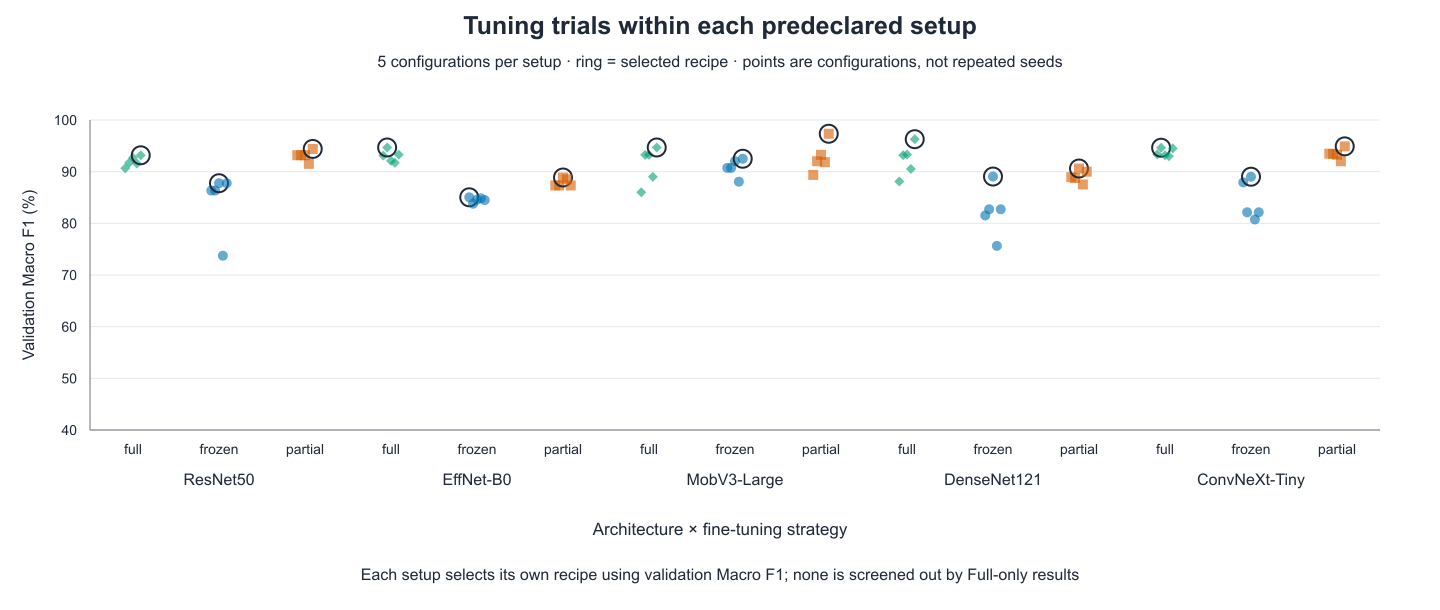

**Figure 1. Five tuning trials within each architecture-mode setup**

จุดเป็นคะแนน validation ของสูตรต่างกัน ไม่ใช่ repeated final seeds วงแหวนระบุสูตรชนะของแต่ละคู่ การที่คู่หนึ่งได้ validation สูงไม่ได้รับประกันอันดับ test ภายหลัง

แหล่งภาพ: `report/qa/tuning_setup_summary.png`

ข้อมูลต้นทาง: `outputs_modes_v3_td/tuning/all_trials.csv`, `outputs_modes_v3_td/tuning/best_params_by_arch_mode.json`


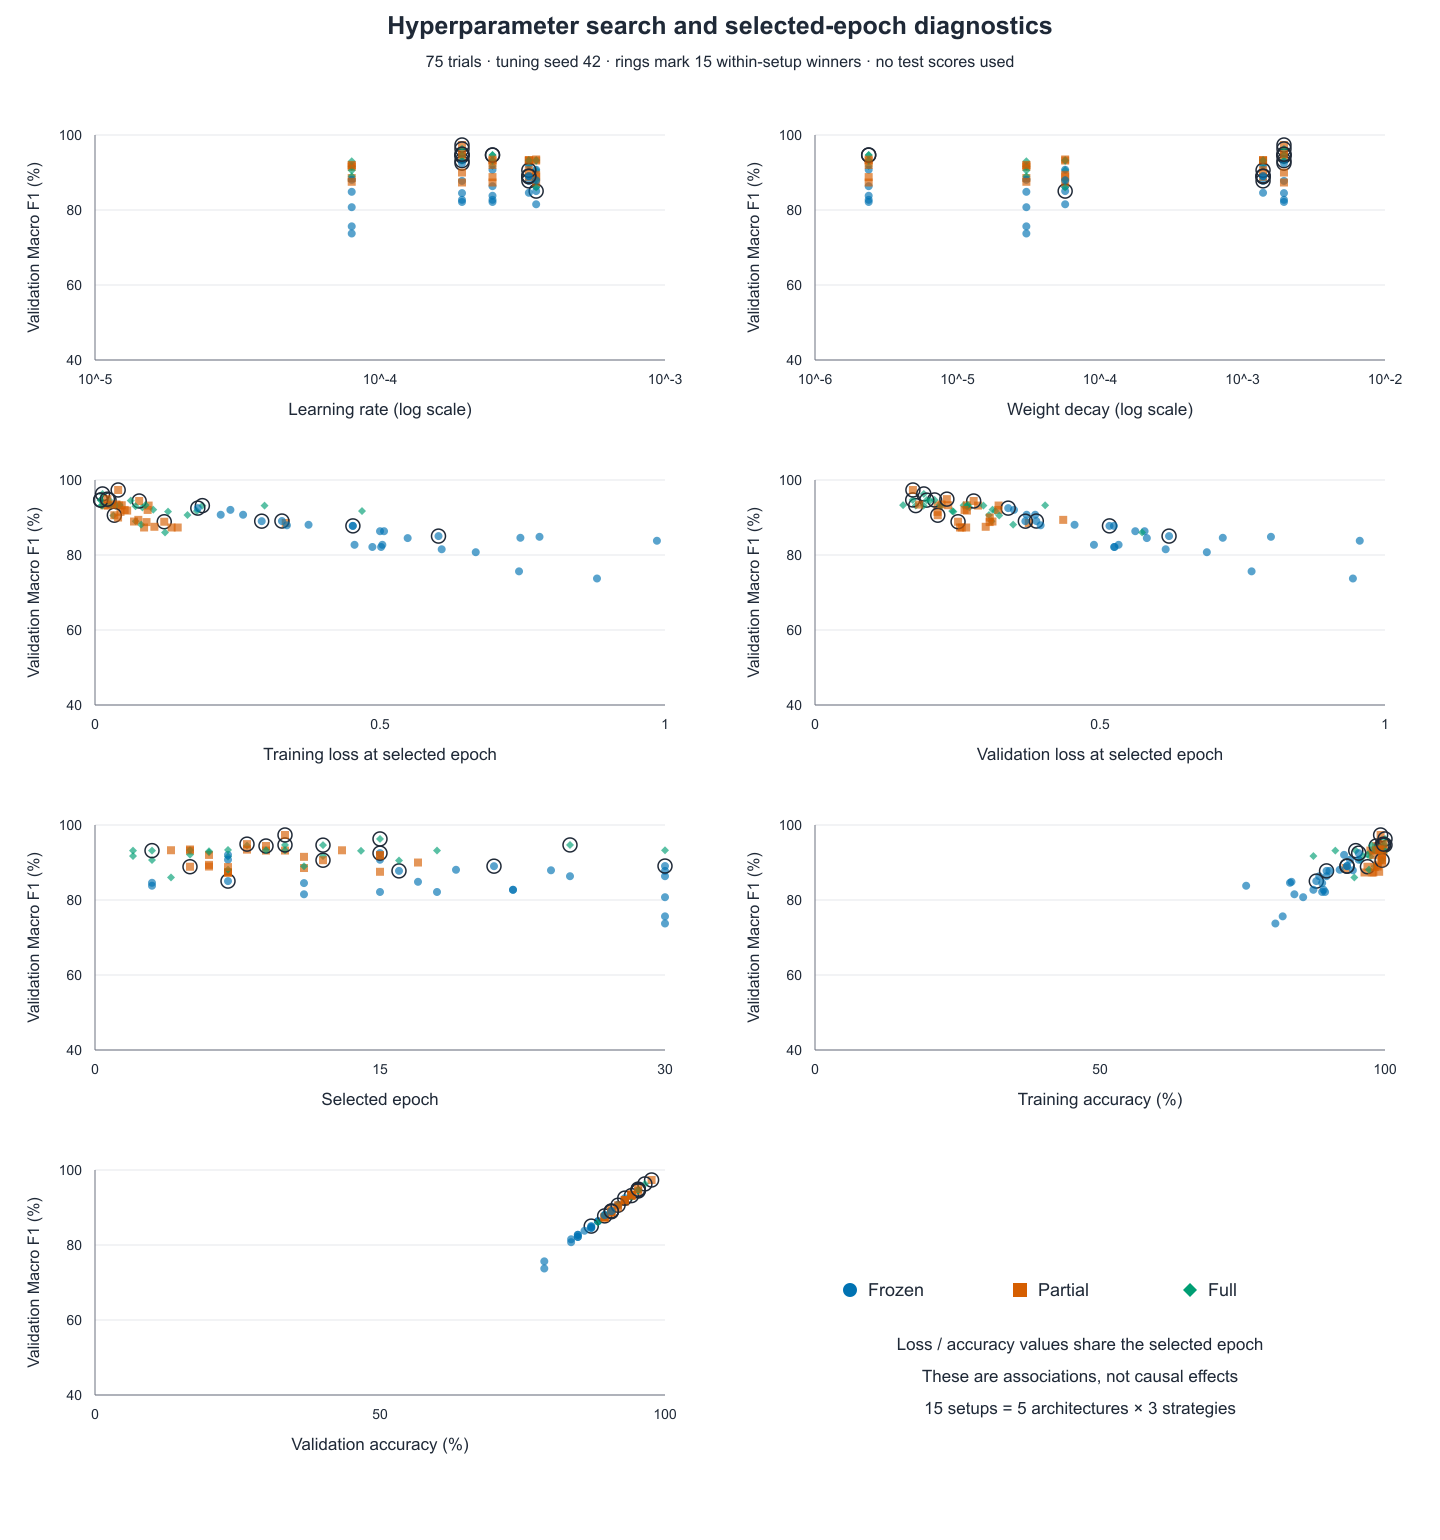

**Figure 2. Tuning diagnostics against validation Macro F1**

แสดง learning rate, weight decay และ metrics ที่ selected epoch เทียบกับ validation Macro F1 จาก trials จริง ความสัมพันธ์รวมยังปนกับ architecture/optimizer/batch size จึงใช้บอกแนวโน้ม ไม่ใช้ยืนยันเหตุและผลหรือ tune ต่อจาก test

แหล่งภาพ: `report/qa/tuning_response.png`

ข้อมูลต้นทาง: `report/tuning_checkpoint_observations.csv`, `outputs_modes_v3_td/tuning/all_trials.csv`


## 6. Validation Selection and Protocol Lock

เลือก checkpoint ภายใน run ด้วย validation Macro F1 สูงสุด → validation loss ต่ำกว่า → epoch ก่อนหน้า แยกจากเกณฑ์ min_delta ของ early stopping จากนั้นเลือกสูตรในแต่ละคู่ด้วย validation Macro F1 → validation accuracy → loss ต่ำกว่า → trial index

สูตรชนะทั้ง 15 คู่ที่บันทึกไว้:

| Architecture | Mode | Trial | Learning rate | Weight decay | Optimizer | Batch | Val Macro F1 (%) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| resnet50 | full | 5 | 1.93968e-4 | 1.95455e-3 | adam | 16 | 93.17 |
| resnet50 | frozen | 3 | 3.32874e-4 | 1.39398e-3 | adam | 16 | 87.76 |
| resnet50 | partial | 5 | 1.93968e-4 | 1.95455e-3 | adam | 16 | 94.40 |
| efficientnet_b0 | full | 2 | 2.48162e-4 | 2.38073e-6 | adam | 32 | 94.68 |
| efficientnet_b0 | frozen | 1 | 3.53112e-4 | 5.69526e-5 | adam | 32 | 85.04 |
| efficientnet_b0 | partial | 3 | 3.32874e-4 | 1.39398e-3 | adam | 16 | 88.87 |
| mobilenet_v3_large | full | 5 | 1.93968e-4 | 1.95455e-3 | adam | 16 | 94.68 |
| mobilenet_v3_large | frozen | 5 | 1.93968e-4 | 1.95455e-3 | adam | 16 | 92.50 |
| mobilenet_v3_large | partial | 5 | 1.93968e-4 | 1.95455e-3 | adam | 16 | 97.34 |
| densenet121 | full | 5 | 1.93968e-4 | 1.95455e-3 | adam | 16 | 96.28 |
| densenet121 | frozen | 3 | 3.32874e-4 | 1.39398e-3 | adam | 16 | 89.06 |
| densenet121 | partial | 3 | 3.32874e-4 | 1.39398e-3 | adam | 16 | 90.61 |
| convnext_tiny | full | 2 | 2.48162e-4 | 2.38073e-6 | adam | 32 | 94.63 |
| convnext_tiny | frozen | 3 | 3.32874e-4 | 1.39398e-3 | adam | 16 | 89.02 |
| convnext_tiny | partial | 5 | 1.93968e-4 | 1.95455e-3 | adam | 16 | 94.90 |

ไฟล์ `selection.json` ล็อกทั้ง 15 สูตร class order, split/protocol/config fingerprints, seeds, representative seed 42 และ statistical families **28/30** ไว้ก่อน test

**Validation-selected reference = MobileNetV3-Large / Partial** โดย selected tuning validation Macro F1 = **97.34%**, Accuracy = **97.65%** ตัวเลขนี้เป็น tuning validation ของสูตรชนะ ไม่ใช่ final test mean

**ResNet50 / Full เป็นโมเดลที่เลือกภายหลังสำหรับรายงาน** หลังพิจารณาหลาย test metrics จึงต้องเปิดเผยว่าเป็น post-hoc/exploratory การเลือกนี้ไม่ได้เปลี่ยน reference เดิม, `selection.json` หรือ Holm families ของการทดลองหลัก


In [ ]:
# Stage 3: freeze recipes, validation reference and planned test families.
run_main("lock")

# The following reads only the embedded historical lock for inspection.
historical_lock = evidence_json("outputs_modes_v3_td/selection.json")
show_table(["Item", "Locked value"], [
    ("Validation reference", str(historical_lock["reference_pair"])),
    ("Representative seed", historical_lock["representative_seed"]),
    ("Primary family size", historical_lock["primary_holm_family"]["planned_size"]),
    ("Secondary family size", historical_lock["secondary_holm_family"]["planned_size"]),
    ("Test metrics used at lock", historical_lock["test_metrics_read"]),
    ("Selection fingerprint", historical_lock["selection_fingerprint"])])


## 7. Matched-seed Final Evaluation

ฝึกทุกคู่ใหม่จาก official ImageNet weights ด้วยสูตรของคู่ตนเองและ seeds **42,123,456,789,1024** รวม 75 final runs ไม่เริ่มจาก tuning checkpoint แต่ละ run เลือก/reload checkpoint ด้วย validation แล้วประเมิน test หลังจาก lock สำเร็จ

สรุปผลเป็น **mean (%) ± sample SD (percentage points; ddof=1)** ของห้า seeds จับคู่ ไม่เลือกเฉพาะ seed ที่คะแนนสูงสุด และไม่รวมคนละ mode เป็นค่า architecture เดียว

| Architecture | Mode | Seeds | Accuracy (%) | Macro Precision (%) | Macro Recall (%) | Macro F1 (%) |
| --- | --- | --- | --- | --- | --- | --- |
| resnet50 | full | 5 | 93.65 ± 1.34 | 92.92 ± 2.07 | 92.77 ± 1.69 | 92.56 ± 1.81 |
| resnet50 | frozen | 5 | 88.47 ± 1.53 | 87.93 ± 1.72 | 87.65 ± 1.59 | 87.55 ± 1.67 |
| resnet50 | partial | 5 | 93.18 ± 1.53 | 92.39 ± 1.63 | 92.11 ± 1.80 | 91.82 ± 2.09 |
| efficientnet_b0 | full | 5 | 91.06 ± 1.34 | 89.98 ± 1.43 | 89.25 ± 1.53 | 89.21 ± 1.52 |
| efficientnet_b0 | frozen | 5 | 85.65 ± 2.41 | 83.66 ± 2.62 | 83.78 ± 2.30 | 83.38 ± 2.36 |
| efficientnet_b0 | partial | 5 | 92.71 ± 2.10 | 91.66 ± 2.64 | 91.29 ± 2.46 | 91.05 ± 2.67 |
| mobilenet_v3_large | full | 5 | 91.76 ± 0.83 | 91.45 ± 1.57 | 90.40 ± 0.85 | 89.86 ± 0.96 |
| mobilenet_v3_large | frozen | 5 | 90.35 ± 0.98 | 89.14 ± 0.93 | 89.23 ± 1.12 | 88.69 ± 1.33 |
| mobilenet_v3_large | partial | 5 | 93.18 ± 2.41 | 92.71 ± 2.04 | 92.17 ± 2.66 | 91.68 ± 3.05 |
| densenet121 | full | 5 | 92.71 ± 1.53 | 92.02 ± 1.93 | 91.44 ± 1.85 | 91.27 ± 1.89 |
| densenet121 | frozen | 5 | 88.00 ± 1.29 | 86.37 ± 1.73 | 85.86 ± 1.57 | 85.87 ± 1.65 |
| densenet121 | partial | 5 | 92.71 ± 1.74 | 91.81 ± 2.10 | 91.49 ± 2.00 | 91.42 ± 1.85 |
| convnext_tiny | full | 5 | 92.94 ± 1.66 | 92.36 ± 1.94 | 91.79 ± 1.90 | 91.35 ± 2.12 |
| convnext_tiny | frozen | 5 | 87.06 ± 2.76 | 86.14 ± 3.52 | 85.66 ± 2.69 | 85.17 ± 2.48 |
| convnext_tiny | partial | 5 | 92.00 ± 1.53 | 92.05 ± 1.46 | 90.80 ± 1.72 | 90.74 ± 1.78 |

**ResNet50/Full** มี observed mean Accuracy **93.65 ± 1.34%** และ Macro F1 **92.56 ± 1.81%** สูงสุดในชุดนี้ แต่การเรียงอันดับ test เป็น descriptive result ไม่ได้ย้อนเปลี่ยน recipe/reference หรือยืนยันว่าเหนือกว่าทุกคู่ทางสถิติ

แหล่งตัวเลข: `outputs_modes_v3_td/final/pair_summary.csv` และ `final/run_metrics.csv`


In [ ]:
# Stage 4: 15 pairs x 5 matched seeds, each initialized fresh from ImageNet weights.
run_main("final")


In [ ]:
# Recalculate mean and sample SD from the embedded completed final run metrics.
# This is read-only tabular analysis, not model evaluation or training.
run_rows = evidence_csv("outputs_modes_v3_td/final/run_metrics.csv")
groups = defaultdict(dict)
for row in run_rows:
    if row["status"] == "completed":
        key = (row["architecture"], row["mode"])
        seed = int(row["seed"])
        if seed in groups[key]:
            raise ValueError("Duplicate completed seed in final metrics")
        groups[key][seed] = row
recalculated = []
for architecture in ARCHITECTURES:
    for mode in MODES:
        seed_map = groups[(architecture, mode)]
        if set(seed_map) != set(SEEDS):
            raise ValueError("Missing or unexpected matched seeds")
        accuracy = [float(seed_map[seed]["test_acc"]) for seed in SEEDS]
        macro_f1 = [float(seed_map[seed]["test_macro_f1"]) for seed in SEEDS]
        recalculated.append((architecture, mode, len(seed_map),
            f"{100*mean(accuracy):.2f} ± {100*stdev(accuracy):.2f}",
            f"{100*mean(macro_f1):.2f} ± {100*stdev(macro_f1):.2f}"))
show_table(["Architecture", "Mode", "Seeds", "Accuracy (%)", "Macro F1 (%)"], recalculated)


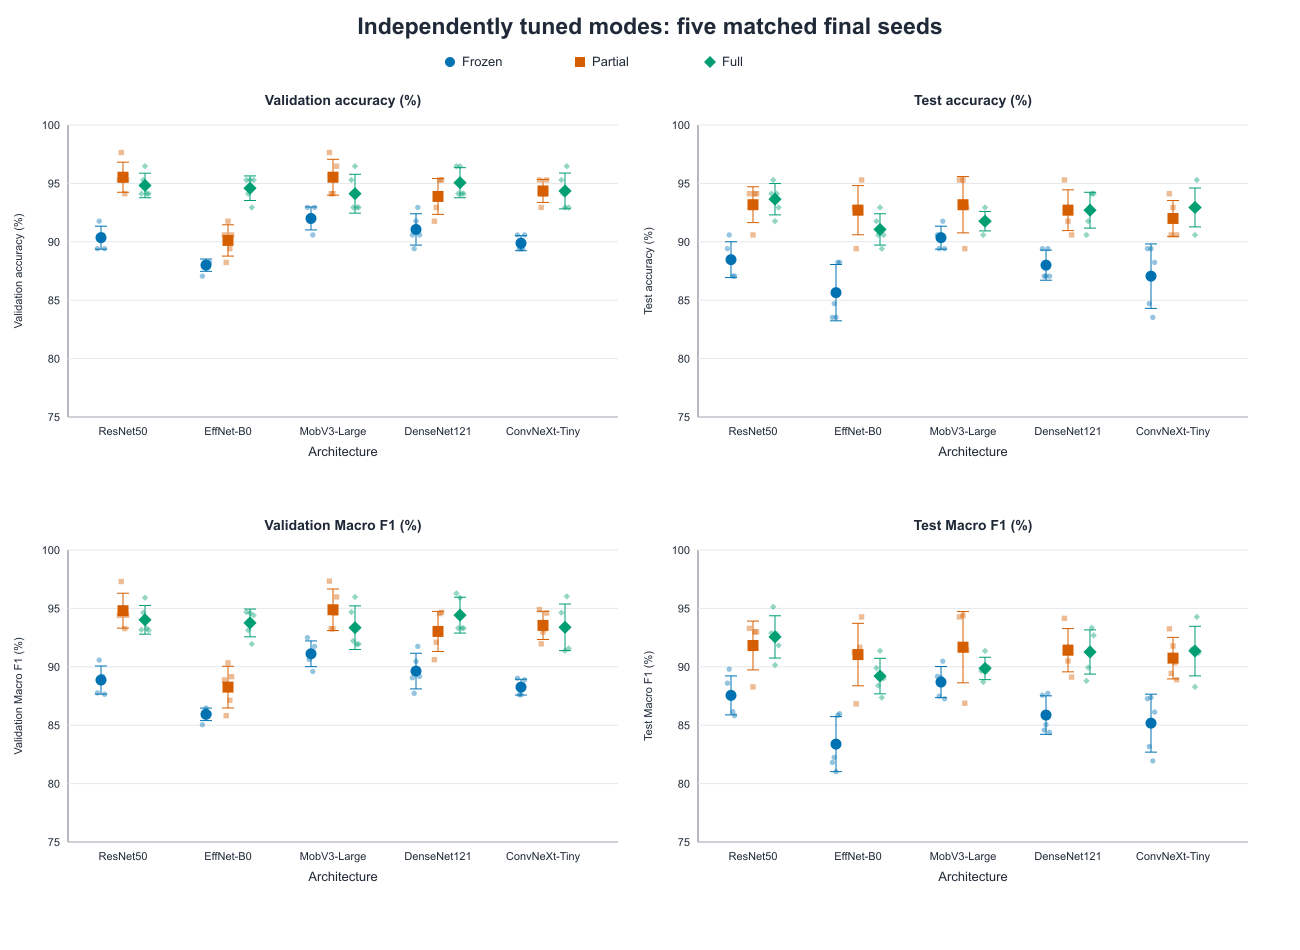

**Figure 3. Validation and test performance across 15 independently tuned pairs**

จุดจางแทน final seeds สัญลักษณ์ใหญ่และ error bars แทน mean ± sample SD ของห้า seeds กราฟ validation มาจาก final selected checkpoints จึงต่างจาก validation ของ winning tuning trial ในหัวข้อ 6 Frozen มี observed mean ต่ำกว่า Full/Partial หลาย architecture แต่ต้องดู matched tests ที่ปรับ Holm ก่อนสรุปนัยสำคัญ

แหล่งภาพ: `report/qa/mode_comparison.png`

ข้อมูลต้นทาง: `outputs_modes_v3_td/final/run_metrics.csv`, `outputs_modes_v3_td/final/pair_summary.csv`, `report/latest_figure_sources.json`


## 8. Classification Metrics and Paired Statistical Tests

Accuracy วัดสัดส่วนทำนายถูกทั้งหมด Macro Precision/Recall/F1 คำนวณต่อคลาสแล้วเฉลี่ยเท่ากันทั้งสี่คลาส ช่วยให้คลาสที่มีภาพมากไม่ครอบงำค่าเฉลี่ย Per-class support คือ test count **16,18,21,30** ไม่ใช่คูณห้า seeds

ใช้ two-sided paired t-test (`scipy.stats.ttest_rel`) โดย join คู่ด้วย **seed ID** ค่า effect ในการทดลองหลักเป็น **reference minus competitor** และ Holm correction แยกสอง families ที่ล็อกไว้:

| Family | Hypotheses | Size |
| --- | --- | --- |
| Primary | Validation reference vs 14 other pairs × Accuracy/Macro F1 | 28 |
| Secondary | Three mode-pair contrasts within five architectures × two metrics | 30 |

ผลคำนวณครบ 58 แถว status `ok`; พบ **5 comparisons** ที่ผ่าน Holm α=0.05 ดังตาราง สถานะ `ok` หมายถึงคำนวณได้ ไม่ได้หมายถึงมีนัยสำคัญ

| Family | Reference | Competitor | Metric | Difference (pp) | Holm p |
| --- | --- | --- | --- | --- | --- |
| primary_reference_pair_28 | mobilenet_v3_large::partial | convnext_tiny::frozen | test_acc | 6.12 | 0.01235 |
| primary_reference_pair_28 | mobilenet_v3_large::partial | convnext_tiny::frozen | test_macro_f1 | 6.50 | 0.01235 |
| secondary_within_arch_mode_30 | resnet50::full | resnet50::frozen | test_acc | 5.18 | 0.02777 |
| secondary_within_arch_mode_30 | densenet121::frozen | densenet121::partial | test_acc | -4.71 | 0.02506 |
| secondary_within_arch_mode_30 | densenet121::frozen | densenet121::partial | test_macro_f1 | -5.55 | 0.01971 |

ผล Primary ที่เทียบ MobileNet/Partial กับ ResNet/Full มี Holm p=1.0 สำหรับทั้ง Accuracy และ Macro F1 จึงไม่ได้ยืนยันว่าคู่ใดเหนือกว่าอีกคู่ ค่า SD/tests บอกความแปรปรวนจาก seed บน split เดียว ไม่ใช่ความไม่แน่นอนจากข้อมูลประชากรใหม่ และผลไม่ significant ไม่ใช่หลักฐานความเท่าเทียม

implementation ครบพร้อม incomplete/undefined handling อยู่ใน `pipeline_modes.py` (`_holm, _test_summary, _summarize, _analyze`) และ `shrine_classifier/analysis.py` ใน Appendix A


In [ ]:
# Stage 5: aggregate metrics, paired tests, confidence and diagnostics from saved final artifacts.
run_main("analyze")

saved_tests = evidence_csv("outputs_modes_v3_td/final/statistical_tests.csv")
family_counts = Counter(row["family_id"] for row in saved_tests)
show_table(["Family", "Rows", "Computable", "Holm significant"], [
    (family, count,
     sum(row["status"] == "ok" for row in saved_tests if row["family_id"] == family),
     sum(row["significant_holm"].lower() == "true" for row in saved_tests if row["family_id"] == family))
    for family, count in family_counts.items()])


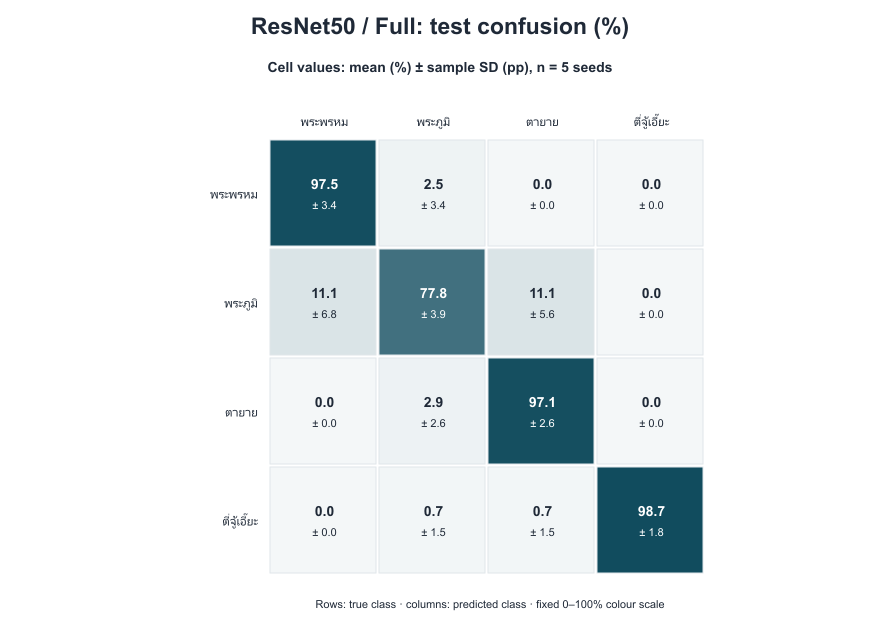

**Figure 4. ResNet50/Full confusion matrices across five matched seeds**

อ่านแต่ละแถวเป็น true class และคอลัมน์เป็น predicted class ค่าในภาพสรุป mean ± sample SD ข้ามห้า seeds ไม่ใช่ confusion ของ seed ที่ดีที่สุด การสับสนศาลพระภูมิกับศาลพระพรหมเป็นตัวอย่างความยากของรูปลักษณ์ที่ใกล้กัน ควรอ่านร่วมกับ support รายคลาส

แหล่งภาพ: `report/qa/confusion_resnet50_full.png`

ข้อมูลต้นทาง: `outputs_modes_v3_td/final/run_metrics.csv`, `report/confusion_mean_sd.csv`, `report/latest_figure_sources.json`


## 9. Confidence Calibration and Training Dynamics

Confidence คือ softmax probability สูงสุด ไม่ใช่โอกาสถูกที่รับประกันในโลกจริง ECE ใช้ 10 bins เปรียบเทียบ confidence เฉลี่ยกับ accuracy ในแต่ละ bin จึงต้องอ่านควบคู่จำนวนภาพใน bin และความเล็กของ test split ไม่มีการ fit calibration หรือปรับโมเดลจากกราฟเหล่านี้

Training curves ใช้ epoch history จริงของแต่ละ run แสดง train/validation, selected epoch และ stopped epoch ความต่าง train/validation ช่วยสังเกต learning dynamics แต่ไม่ใช้ test ตัดสินเปลี่ยนสูตร

การเฉลี่ย curve หลังบาง seeds หยุด early stopping ใช้เฉพาะ runs ที่มี epoch นั้นจริง ไม่เติมค่า SD เป็นศูนย์เมื่อเหลือ run เดียว และต้องระบุจำนวน runs ที่ยังมีข้อมูล กราฟรายงานฉบับที่ฝังใน notebook มีจำนวน available runs และละ sample SD เมื่อ n=1 ตาม `report/enhanced_figure_sources.json` ส่วน `report/learning_curve_sources.json` บันทึกที่มาของกราฟรุ่นก่อน


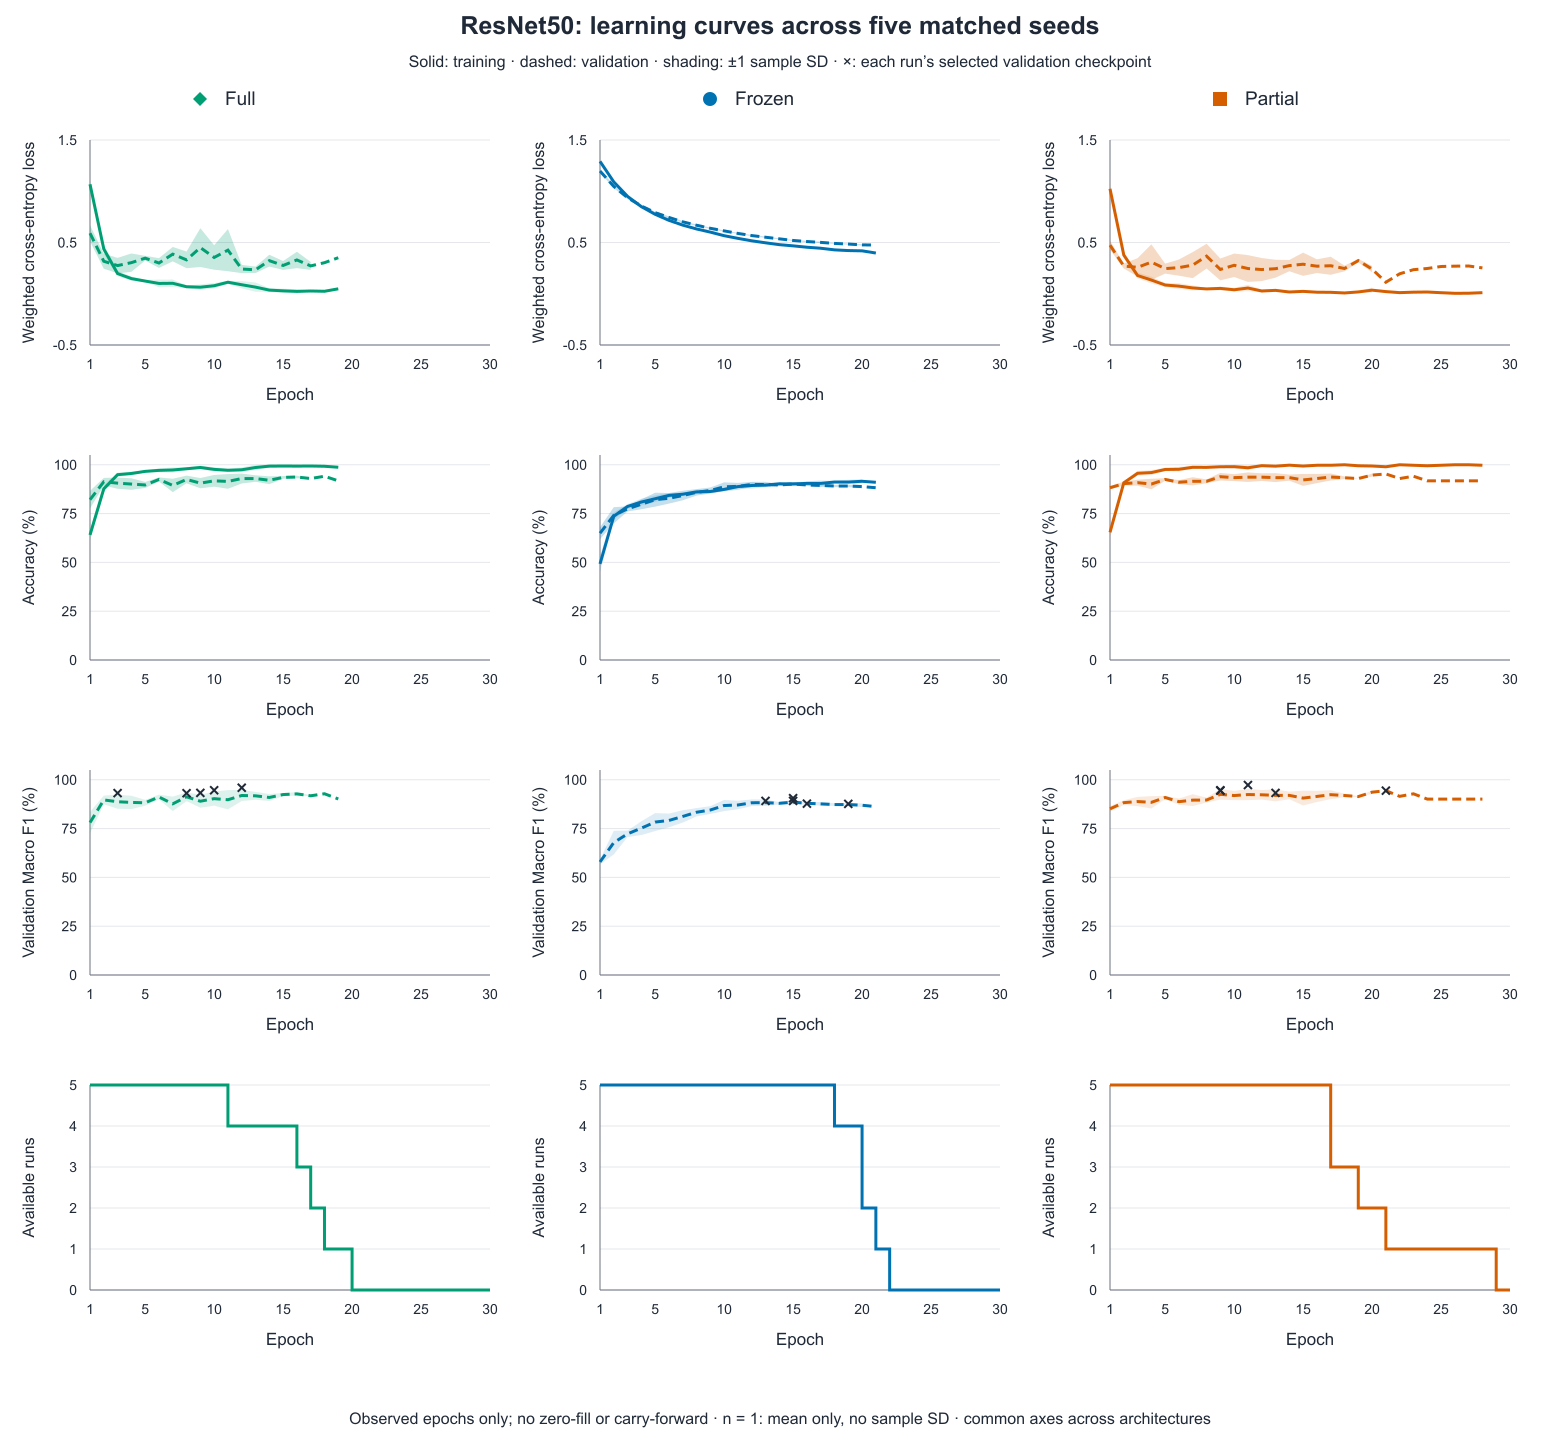

**Figure 5. ResNet50 training dynamics for Full, Frozen and Partial**

เส้นแสดงค่าเฉลี่ยข้าม seeds ใน epoch ที่มีข้อมูล แถบสีคือ ±1 sample SD และเครื่องหมาย × คือ checkpoint ที่เลือกของแต่ละ run แถวล่างแสดงจำนวน runs ที่ยังมีข้อมูล การหยุดคนละ epoch ทำให้จำนวน seeds ที่รองรับช่วงท้ายเปลี่ยนไป ไม่ควรตีความช่วงท้ายเสมือนมีห้า runs ครบตลอด

แหล่งภาพ: `report/qa/learning_curves_resnet50.png`

ข้อมูลต้นทาง: `outputs_modes_v3_td/final/run_metrics.csv`, `report/learning_curve_summary.csv`, `report/learning_curve_epoch_counts.csv`, `report/final_checkpoint_summary.csv`, `report/enhanced_figure_sources.json`


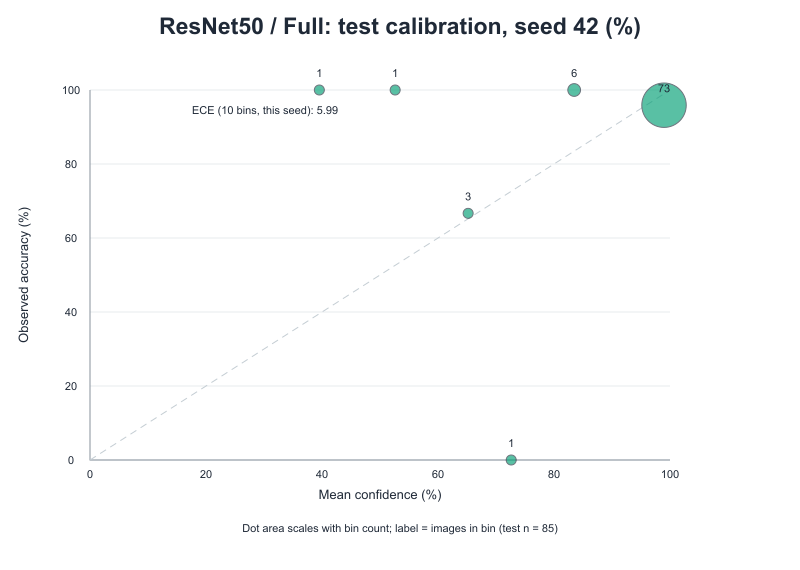

**Figure 6. Confidence calibration of the report-selected ResNet50/Full**

กราฟของ ResNet50/Full **seed 42** จาก test 85 ภาพ ใช้ 10 bins และมี ECE ประมาณ **5.99 จุดเปอร์เซ็นต์** ขนาดจุดแสดงจำนวนภาพใน bin ตาม identities ที่บันทึกใน source map เป็นการวิเคราะห์หลัง final ไม่มีการประเมินโมเดลหรือปรับ calibration เพิ่มระหว่างจัดทำ notebook

แหล่งภาพ: `report/qa/calibration_resnet50_full.png`

ข้อมูลต้นทาง: `report/selected_model_report_sources.json`, `outputs_modes_v3_td/final/run_metrics.csv`


In [ ]:
# Optional extra learning-curve figures using the existing Python plotting CLI.
# Requires pandas and completed final histories in the new reproduction output.
curve_command = [sys.executable, REPRO_ROOT / "plot_learning_curves.py",
                 "--out-dir", RUN_OUT_DIR, "--metric", "all"]
preview_command(curve_command)
if RUN_MODE == "reproduce" and "curves" in ENABLED_AUXILIARY_ACTIONS:
    checked_execute(curve_command)

# The exact report figures embedded above were prepared from saved logs using
# the report source maps; the optional CLI may use a different visual layout.
# In this archived plotting script, n=1 uses SD=0 for drawing.
# A sample SD is undefined for n=1; do not interpret that segment as zero variation.


## 10. Validation-reference Grad-CAM and Eyeball Analysis

การวิเคราะห์เดิมใช้ **MobileNetV3-Large / Partial / seed 42** ตาม locked validation reference เลือกตัวอย่างถูก/ผิดอย่าง deterministic และใช้กรณีถูกที่ confidence ต่ำเมื่อคลาสนั้นไม่มีภาพผิด

Grad-CAM เปิด gradient ขณะ model อยู่ใน eval mode ใช้ spatial layer ที่กำหนดและ map กลับภาพต้นฉบับโดยนำ known canvas padding ออก สำหรับ frozen backbone อาจต้องเปิด input gradient ส่วน eyeball เปรียบเทียบ **ภาพเดียวกัน** ระหว่าง ImageNet label เดิมกับ fine-tuned label

ImageNet baseline เดิมมี 1,000 classes จึงใช้แสดง label-space mismatch เชิงคุณภาพ ไม่ใช่ accuracy สี่คลาส CAM เป็น diagnostic association ไม่ใช่ causal proof ว่าบริเวณที่ร้อนเป็นเหตุผลจริงทั้งหมดของโมเดล

คำสั่งต่อไปนี้คง reference เดิม และสร้าง CAM/eyeball เป็น supplementary evidence; ResNet ของโมเดลที่เลือกในรายงานอยู่ในหัวข้อ 11


In [ ]:
# Stage 6: both Grad-CAM and eyeball for the validation-selected reference.
run_main("gradcam")
# Alternative alias for the same combined implementation: run_main("eyeball")


## 11. ResNet50/Full Follow-up: Grad-CAM and Ablation

หลังพิจารณาหลาย test metrics ผู้จัดทำเลือก ResNet50/Full เพื่อรายงาน จึงทำ follow-up ที่เปิดเผยว่า **post-hoc/exploratory** โดยรักษา MobileNet validation reference และการทดลองหลักเดิมไว้

ResNet Grad-CAM ใช้ final **seed 42**, layer `layer4[-1]` ทั้งหมด **8 ภาพ: ถูก 6 / ผิด 2** มี checkpoint hash, image IDs, true/predicted/explained target, confidence, selection reason และ content bbox บันทึกไว้ ไม่มีการใช้ CAM เปลี่ยนสูตรหรือเลือก checkpoint ใหม่


In [ ]:
# Follow-up 1: post-hoc ResNet50/Full Grad-CAM on the locked representative seed.
run_followup("gradcam")


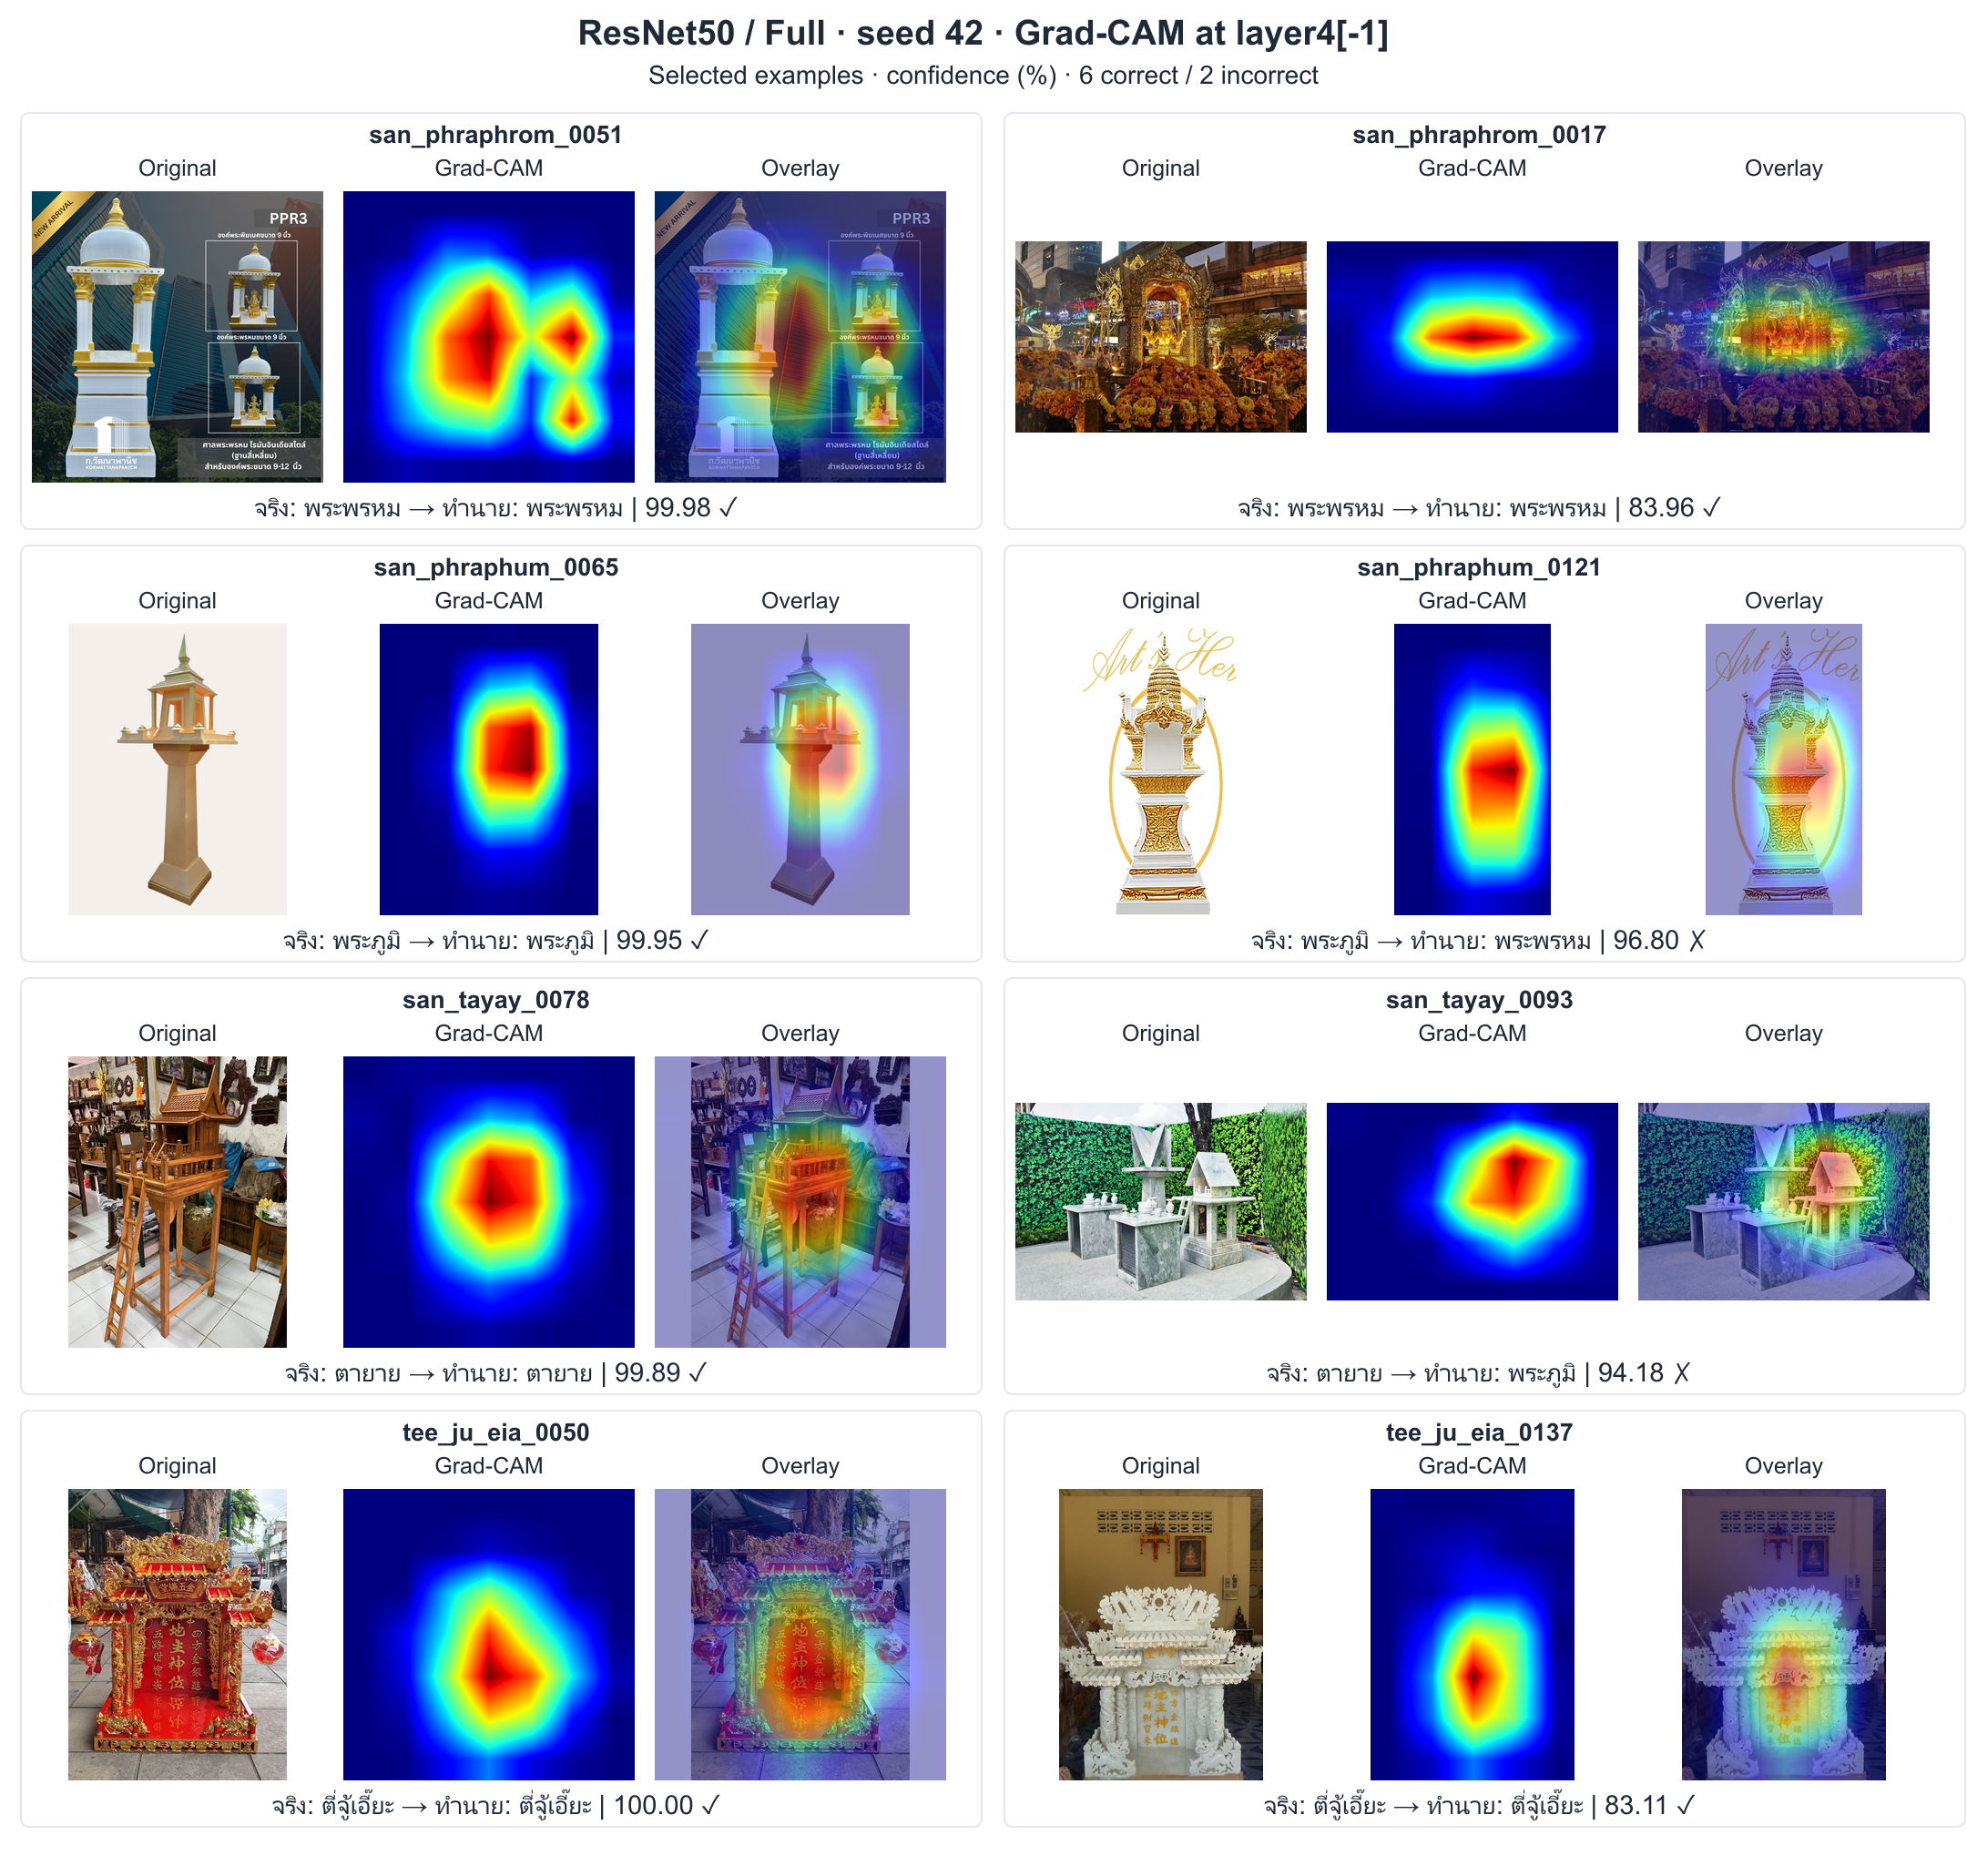

**Figure 7. ResNet50/Full seed 42: eight saved Grad-CAM cases**

ตัวอย่างศาลพระภูมิ 0121 ถูกทำนายเป็นศาลพระพรหมด้วย confidence ประมาณ 96.80% และศาลตายาย 0093 ถูกทำนายเป็นศาลพระภูมิประมาณ 94.18% แสดงว่าความมั่นใจสูงยังผิดได้ บริเวณร้อนสัมพันธ์กับส่วนศาลในหลายภาพ แต่ไม่ยืนยันว่าโมเดลไม่ใช้ฉากหลัง/ตัวอักษร และไม่ใช่หลักฐานเชิงสาเหตุ

แหล่งภาพ: `report/report_assets/latest/gradcam_resnet50_full_seed42_readable.png`

ข้อมูลต้นทาง: `report/resnet_gradcam_cases.csv`, `report/resnet_followup_sources.json`


### 11.1 Predeclared Ablation Lock

ใช้สูตร ResNet50/Full เดิม split/seeds/checkpoint rule เดิม เปลี่ยนทีละหนึ่งปัจจัย:

| Condition | Augmentation | Class weights | New training runs |
| --- | --- | --- | --- |
| Baseline | On | On | 0; reuse five matching final runs |
| No augmentation | Off | On | 5 |
| No class weights | On | Off | 5 |

ล็อกสอง variants และ **Holm family 4 comparisons** (2 variants × Accuracy/Macro F1) ก่อนฝึก/ทดสอบ follow-up ไม่มีการ tune ใหม่และไม่ฝึก baseline ซ้ำ สูงสุด 10 runs / 300 epochs; ผลที่ผู้ใช้รันจริงครบ 10 runs / 145 epochs

ลำดับ ablation: **lock → ablation --resume → analyze → report** ส่วน Grad-CAM ทำแยกจากการฝึก variants ได้ และ report ใช้เฉพาะ completed artifacts


In [ ]:
# Follow-up 2: freeze the two variants, matching baseline identities and Holm family.
run_followup("lock")


In [ ]:
# Follow-up 3: train the two variants, five seeds each; reuse the existing baseline.
run_followup("ablation")


In [ ]:
# Follow-up 4: compute matched deltas, summaries and the separate four-test family.
run_followup("analyze")


### 11.2 Saved Ablation Results and Thai Interpretation

| Condition | Seeds | Accuracy (%) | Macro F1 (%) |
| --- | --- | --- | --- |
| baseline | 5 | 93.65 ± 1.34 | 92.56 ± 1.81 |
| no_augmentation | 5 | 92.71 ± 1.93 | 91.24 ± 2.39 |
| no_class_weights | 5 | 93.18 ± 2.10 | 91.89 ± 2.54 |

| Variant | Metric | Variant − baseline (pp) | Raw p | Holm p | Significant |
| --- | --- | --- | --- | --- | --- |
| no_augmentation | test_acc | -0.94 | 0.3375 | 1.0000 | False |
| no_augmentation | test_macro_f1 | -1.32 | 0.2251 | 0.9002 | False |
| no_class_weights | test_acc | -0.47 | 0.6885 | 1.0000 | False |
| no_class_weights | test_macro_f1 | -0.67 | 0.6555 | 1.0000 | False |

เมื่อไม่ใช้ augmentation ค่าเฉลี่ย Accuracy/F1 ลดลงประมาณ **0.94/1.32 จุดเปอร์เซ็นต์** เมื่อไม่ใช้ class weights ลดลงประมาณ **0.47/0.67 จุดเปอร์เซ็นต์** อย่างไรก็ตาม **ไม่มี comparison ผ่าน Holm** (ค่า adjusted p ต่ำสุด **0.9002**) จึงอธิบายได้เพียงแนวโน้มที่สังเกตในข้อมูลชุดนี้ ไม่อ้างว่าพิสูจน์ประโยชน์หรือความเท่าเทียม

ใช้คำว่า **จุดเปอร์เซ็นต์ (pp)** สำหรับผลต่างของ metrics ไม่ใช่เปอร์เซ็นต์การเปลี่ยนแปลงสัมพัทธ์ และ loss ระหว่างใช้/ไม่ใช้ class weights ไม่ได้มี objective scale เดียวกัน จึงไม่ใช้เปรียบเทียบว่าเงื่อนไขใดดีกว่าจาก loss เพียงอย่างเดียว


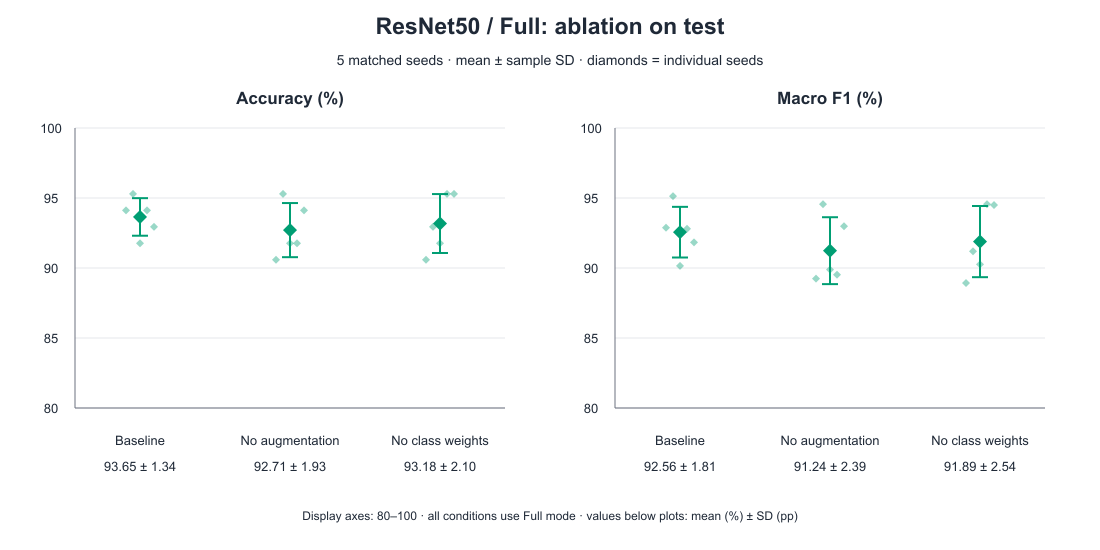

**Figure 8. ResNet ablation with five matched seeds per condition**

อ่านทั้งค่าเฉลี่ย ความกระจาย และ paired seed differences ร่วมกับ Holm p ในตาราง แม้ baseline มี observed mean สูงกว่า variants แต่หลักฐานนี้ยังไม่ยืนยันผลที่ใช้ได้ทั่วไปกับข้อมูลใหม่หรือความแตกต่างเชิงสถิติที่ระดับที่ล็อกไว้

แหล่งภาพ: `report/qa/resnet_ablation_summary.png`

ข้อมูลต้นทาง: `outputs_modes_v3_td/ablation/resnet50_full_v1/condition_summary.csv`, `outputs_modes_v3_td/ablation/resnet50_full_v1/matched_deltas.csv`, `outputs_modes_v3_td/ablation/resnet50_full_v1/statistical_tests.csv`


In [ ]:
# Inspect the saved verification record. This cell does not rerun that verification.
followup_verification = evidence_json("report/resnet_followup_verification.json")
show_table(["Check", "Recorded result"], [
    ("Matched prediction rows independently checked", followup_verification["matched_prediction_rows"]),
    ("New ablation runs", followup_verification["new_ablation_runs"]),
    ("Reused baseline runs", followup_verification["baseline_reused"]),
    ("CAM examples", followup_verification["cam_examples"]),
    ("Copied artifact hashes match", followup_verification["artifact_hashes_match"]),
    ("Holm-significant ablation comparisons", followup_verification["significant_holm_tests"]),
    ("Cloud completeness verified", followup_verification["cloud_completeness_verified"])])


## 12. Report Export and Results Interpretation

`pipeline_modes.py --stage report` สร้าง Thai HTML จากผล local ใน `report_assets/understanding_th.html` ส่วน `resnet_followup.py --stage report` อัปเดตเฉพาะ follow-up blocks ใน README local และคัดลอก verified CAM/ablation assets ไม่ push GitHub โดยอัตโนมัติ

เมื่อเปิด reproduction mode ทั้ง source และ README template จะอยู่ใน workspace ใหม่ การรัน report จึงแก้ไฟล์ใน workspace นั้นเท่านั้น README snapshot ยังมี narrative จากการทดลองเดิม; การทำซ้ำบน runtime ใหม่ต้องตรวจ narrative/ตารางทั้งรายงานกับผลใหม่ก่อนส่ง ไม่ถือว่าการ replace follow-up blocks เขียนรายงานทั้งหมดใหม่แล้ว

**การตีความผลที่ส่งใน notebook นี้**

- ทุก architecture-mode ได้ค้นหาสูตรของตนเองภายใต้งบห้าสูตรที่เท่ากัน ผลจึงเปรียบเทียบ setups ที่ tune แยกกัน ไม่ได้แยกผลเชิงสาเหตุของ mode ออกจาก hyperparameters
- ResNet50/Full มี observed test mean สูงสุดหลาย metrics ในชุดนี้ แต่เป็นการเลือกเพื่อรายงานภายหลังดู test; MobileNetV3/Partial ยังเป็น validation reference ที่ล็อกไว้เดิม
- ผล ablation มีทิศทางค่าเฉลี่ยที่เอื้อต่อ augmentation/class weights แต่ยังไม่มี comparison ผ่าน Holm ไม่อ้างผลพิสูจน์หรือ equivalence
- Test 85 ภาพเคยถูกตรวจดูในงานก่อนหน้า การศึกษานี้จึงเป็น exploratory บน split เดิม ยังไม่มี independent external holdout
- ห้า seeds สะท้อนความแปรปรวนของการฝึกบน split เดียว ไม่ใช่ external generalization confidence interval; CAM ไม่ใช่ causal proof
- Local artifacts และค่า tracking mode ไม่ยืนยันว่า cloud dashboard ครบ; สถานะ cloud completeness และ exact instructor compliance ยังไม่ผ่านการยืนยันจากแหล่งต้นฉบับ

Notebook นี้สร้างเพื่อรวมโค้ดและอธิบายหลักฐานที่มี ไม่ได้เพิ่มงบทดลองหรือสร้างตัวเลขจากข้อมูลจำลองเพื่อแทนผลจริง


In [ ]:
# Stage 7: generate the Thai explanatory HTML in the reproduction output.
run_main("report")


In [ ]:
# Follow-up 5: update local README follow-up blocks inside the NEW workspace.
run_followup("report")


## 13. Reproduction Checklist and Evidence Provenance

การอ่านผลเดิมใช้ notebook นี้ไฟล์เดียวได้ สำหรับฝึกซ้ำให้ดำเนินการตามลำดับ:

1. ใช้ Python kernel ที่มี compatible torch/torchvision และ packages ที่ระบุ หากใช้ script curves ให้มี pandas ด้วย
2. วาง `dataset_cleaned/` และ `outputs/` ที่มี canonical split, audit, duplicate-review decisions และ baseline ที่เข้ากันได้ใน PROJECT_ROOT ไม่ดาวน์โหลด/แบ่งข้อมูลใหม่อัตโนมัติ
3. เปิด source export ไปยัง workspace ใหม่ แล้วเลือกทำ `prepare` ครั้งเดียว ตรวจทรัพยากรและงบก่อนเปิด `tune`
4. รัน `tune → lock → final --resume → analyze → gradcam → report` โดยคง architecture/modes/seeds/budget ตามค่าที่กำหนด
5. หากต้องการทำ ResNet follow-up ซ้ำ ใช้ baseline ห้า seeds ที่ตรงกับ experiment ใหม่ แล้วรัน `gradcam` และ `lock → ablation --resume → analyze → report`
6. ตรวจ actual counts, failed/incomplete attempts, source/config hashes, result tables และรายงานก่อนใช้ผลจากการรันใหม่ อย่ารวมผลใหม่กับ historical study

**Files not embedded:** ภาพต้นฉบับ 560 ภาพ, model checkpoints, complete run histories/predictions ทุกไฟล์, W&B cache/credentials และ historical output directory ทั้งชุด ข้อมูลเหล่านี้ยังจำเป็นเมื่อต้องตรวจภาพ/ประเมินโมเดลหรือทำ reproduction เต็ม ไม่ใช่เงื่อนไขสำหรับเปิดอ่านตาราง/กราฟที่ฝังไว้

**Verification boundary:** notebook ผ่านการตรวจโครงสร้าง JSON/nbformat fields, source-byte SHA-256, evidence/attachment hashes และ mapping ของข้อมูลด้วย Node เท่านั้น ไม่ได้ execute code cells หรือรัน Python/tests เพื่อรับรองว่า notebook ทำงานครบในทุก kernel


In [ ]:
# Source inventory and checksums are part of this single notebook.
show_table(["Bundled file", "Bytes", "SHA-256"],
           [(name, record["size_bytes"], record["sha256"]) for name, record in BUNDLE["sources"].items()])
print("Evidence files:", len(BUNDLE["evidence"]))
print("Embedded figures:", len(BUNDLE["figures"]))
print("Historical main predictions independently checked:",
      evidence_json("report/verification.json")["test_predictions"])
print("All computation above uses saved tables; no model test pass is triggered.")


## Appendix A. Complete Python Implementation

โค้ดเต็มด้านล่างเป็น snapshot จากไฟล์จริง ไม่ได้ rewrite training pipeline ใหม่เพื่อส่งอาจารย์ แต่ละ cell เริ่มด้วย `%%project_source <module>` ซึ่งเป็น **storage-only cell magic** ที่ลงทะเบียนไว้ในหัวข้อ 1 การรัน cell เหล่านี้เพียงตรวจ/เก็บข้อความ ไม่ import โมเดล ไม่เรียก `main()` และไม่ฝึกซ้ำ การรันจริงใช้ source exporter และ stage runner ด้านบน

บรรทัดแรกของ magic เป็น wrapper ของ notebook; เนื้อหาที่ตามมาคือ implementation เดิมและมี original bytes ฝังแยกใน metadata พร้อม SHA-256 เพื่อรักษา CRLF/encoding เมื่อส่งออก หากแก้ source cell จนไม่ตรงกับ snapshot exporter จะหยุดแจ้ง mismatch

`pipeline.py` และ legacy helper modules รวมไว้เพื่อ imports, fingerprint และ provenance ของ implementation เดิมเท่านั้น **ไม่เปิดให้รัน historical Full-only/retired measured extension protocols** ผ่าน stage cells ของ notebook นี้ `pipeline_extensions.py` ที่เป็น retired CLI ไม่ถูกรวมเป็นคำสั่งรัน


### A.1. Current Independent Architecture-mode Pipeline

`pipeline_modes.py` — CLI หลัก: data checks, seeded random tuning, validation lock, fresh final runs, aggregation, paired Holm statistics, diagnostics, reference CAM/eyeball และ HTML report

Original source SHA-256: `72bd76b4e9fe3766113216f0c318cf0699e91ec09791b562c7c47f18c0c8ebcc`


In [ ]:
%%project_source pipeline_modes.py
"""Independent architecture × fine-tuning-mode experiment runner.

Tuning and lock stages never construct a test DataLoader. All new artifacts
live under outputs_modes_v3 by default; historical outputs are read-only inputs.
"""
from __future__ import annotations

import argparse
import csv
import hashlib
import html
import json
import os
import platform
import random
import shutil
import sys
import time
import traceback
from datetime import datetime, timezone
from itertools import combinations
from pathlib import Path
from typing import Any

import numpy as np

from shrine_classifier.data import CLASSES, sha256_file
from shrine_classifier.models import ARCHITECTURES

MODES = ("full", "frozen", "partial")
SEEDS = (42, 123, 456, 789, 1024)
PROTOCOL_VERSION = "architecture-mode-5trial-v2"
SEARCH_SPACE = {
    "learning_rate": {"distribution": "log_uniform", "min": 1e-5, "max": 1e-3},
    "weight_decay": {"distribution": "log_uniform", "min": 1e-6, "max": 1e-2},
    "optimizer": {"values": ["adamw", "adam", "sgd"]},
    "batch_size": {"values": [16, 32]},
}
SEARCH_METHOD = "local seeded random search; trials individually tracked as W&B runs"


def _json(path: Path, obj: Any) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, ensure_ascii=False, indent=2, allow_nan=False, default=str), encoding="utf-8")
    tmp.replace(path)


def _csv(path: Path, rows: list[dict[str, Any]]) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    if not rows:
        path.write_text("status\r\n", encoding="utf-8-sig")
        return
    fields = list(dict.fromkeys(k for row in rows for k in row))
    tmp = path.with_suffix(path.suffix + ".tmp")
    with tmp.open("w", encoding="utf-8-sig", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=fields, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(rows)
    tmp.replace(path)


def _read_csv(path: Path) -> list[dict[str, str]]:
    with path.open("r", encoding="utf-8-sig", newline="") as stream:
        return list(csv.DictReader(stream))


def _fingerprint(obj: Any) -> str:
    payload = json.dumps(obj, ensure_ascii=False, sort_keys=True, separators=(",", ":"), default=str).encode()
    return hashlib.sha256(payload).hexdigest()


def _source_manifest(base: Path, data_root: Path, out: Path) -> dict[str, Any]:
    prop_file = base / "dataset_audit" / "image_properties.csv"
    review_file = base / "dataset_audit" / "near_duplicate_review_decisions.csv"
    metadata_file = data_root / "metadata_cleaned.csv"
    if not prop_file.is_file() or not review_file.is_file() or not metadata_file.is_file():
        raise FileNotFoundError("Existing dataset audit, duplicate review, or metadata missing; run the verified audit workflow first")
    props = _read_csv(prop_file)
    if len(props) != 560:
        raise ValueError(f"Expected 560 audited images, found {len(props)}")
    meta_rows = _read_csv(metadata_file)
    metadata: dict[tuple[str, str], str] = {}
    for row in meta_rows:
        key = (row["category"], Path(row["filename"]).stem)
        if key in metadata:
            raise ValueError(f"Ambiguous metadata join for {key}")
        metadata[key] = row.get("source_url", "") or ""
    manifest, problems, domains, domains_by_class = [], [], {}, {name:{} for name in CLASSES}
    split_map = {r["image_id"]: r for r in _read_csv(base / "splits.csv")}
    for row in props:
        rel = Path(row["path"])
        if row["label"] not in CLASSES or int(row["label_index"]) != CLASSES.index(row["label"]):
            problems.append({"path": row["path"], "issue": "class-order mismatch"})
            continue
        img = data_root / rel
        if not img.is_file():
            problems.append({"path": row["path"], "issue": "missing image"})
            continue
        actual = sha256_file(img)
        if actual != row.get("byte_sha256"):
            problems.append({"path": row["path"], "issue": "byte hash changed since audit"})
            continue
        key = (row["label"], rel.stem)
        url = metadata.get(key)
        if url is None:
            problems.append({"path": row["path"], "issue": "metadata join missing"})
            continue
        domain = row.get("source_domain", "")
        domains[domain or "unknown"] = domains.get(domain or "unknown", 0) + 1
        domain_name=domain or "unknown"
        domains_by_class[row["label"]][domain_name]=domains_by_class[row["label"]].get(domain_name,0)+1
        manifest.append({"image_id": row["image_id"], "path": row["path"], "label": row["label"],
                         "label_index": int(row["label_index"]), "width": int(row["width"]),
                         "height": int(row["height"]), "mode": row["mode"], "format": row["format"],
                         "byte_sha256": actual, "pixel_sha256": row["pixel_sha256"],
                         "group_id": split_map.get(row["image_id"], {}).get("group_id"),
                         "source_url": url, "source_domain": domain or None})
    ids = [row["image_id"] for row in manifest]
    if problems or len(set(ids)) != 560 or set(metadata) != {(r["label"], Path(r["path"]).stem) for r in manifest}:
        _csv(out / "dataset_audit" / "source_issues.csv", problems or [{"issue": "duplicate IDs or unused metadata join"}])
        raise ValueError(f"Dataset integrity check failed: {len(problems)} issues; see dataset_audit/source_issues.csv")
    _json(out / "source_manifest.json", {"protocol": PROTOCOL_VERSION, "images": manifest,
          "image_count": len(manifest), "metadata_sha256": sha256_file(metadata_file),
          "audit_properties_sha256": sha256_file(prop_file), "duplicate_review_sha256": sha256_file(review_file),
          "source_domain_counts": domains, "source_domain_counts_by_class":domains_by_class,
          "unknown_url_count": sum(not r["source_url"] for r in manifest)})
    return {"images": manifest, "fingerprint": _fingerprint([(r["image_id"], r["byte_sha256"]) for r in manifest])}


def _current_code_fingerprint() -> str:
    base = Path(__file__).resolve().parent
    entries = []
    for folder in (base / "shrine_classifier", base / "shrine_classifier_ext"):
        for path in sorted(folder.glob("*.py")):
            entries.append((str(path.relative_to(base)), sha256_file(path)))
    for path in (base / "pipeline_modes.py", base / "pipeline.py"):
        if path.exists():
            entries.append((str(path.relative_to(base)), sha256_file(path)))
    return _fingerprint(entries)


def _verify_and_prepare(args: argparse.Namespace, out: Path) -> dict[str, Any]:
    from pipeline import _check_existing_split
    from shrine_classifier.training import load_split

    base = args.base_out_dir.resolve()
    _check_existing_split(base, args.data_root.resolve())
    split_file = base / "splits.csv"
    meta_file = base / "split_metadata.json"
    split_rows = load_split(split_file)
    meta = json.loads(meta_file.read_text(encoding="utf-8"))
    if int(meta.get("split_seed", -1)) != args.split_seed or len(split_rows) != 560 or int(meta.get("num_groups", -1)) != 550:
        raise ValueError("Canonical split does not match the reviewed seed/group/image contract; refusing to regenerate")
    if meta.get("group_overlap") is not False:
        raise ValueError("Canonical split metadata reports group overlap")
    # Copy byte-identical canonical split artifacts into the isolated new output root.
    out.mkdir(parents=True, exist_ok=True)
    shutil.copy2(split_file, out / "splits.csv")
    shutil.copy2(meta_file, out / "split_metadata.json")
    if sha256_file(split_file) != sha256_file(out / "splits.csv"):
        raise IOError("Split copy byte hash mismatch")
    manifest = _source_manifest(base, args.data_root.resolve(), out)
    protocol = {"version": PROTOCOL_VERSION, "architectures": list(args.architectures), "modes": list(args.modes),
        "class_order": CLASSES, "split_seed": args.split_seed, "split_sha256": sha256_file(split_file),
        "assignment_fingerprint": meta["split_sha256"], "source_fingerprint": manifest["fingerprint"],
        "input_size": args.input_size, "max_epochs": args.epochs, "early_stopping_patience": 7,
        "min_delta": 1e-4, "selection_metric": "validation macro F1",
        "search_space": SEARCH_SPACE, "search_method": SEARCH_METHOD, "tuning_seed": args.seed,
        "trials_per_pair": args.trials_per_pair, "final_seeds": args.seeds,
        "wandb_project": args.wandb_project, "created_utc": datetime.now(timezone.utc).isoformat()}
    protocol["protocol_fingerprint"] = _fingerprint(protocol)
    existing_path = out / "protocol.json"
    if existing_path.exists():
        previous = json.loads(existing_path.read_text(encoding="utf-8"))
        if previous.get("protocol_fingerprint") != protocol["protocol_fingerprint"]:
            raise ValueError(f"{out} has a different protocol fingerprint; use a new --out-dir")
    _json(existing_path, protocol)
    env = {"python": sys.version, "platform": platform.platform(), "torch": None, "torchvision": None,
           "numpy": np.__version__, "device_requested": args.device, "wandb_mode_requested": args.wandb_mode,
           "timestamp_utc": datetime.now(timezone.utc).isoformat(), "code_fingerprint": _current_code_fingerprint()}
    import torch
    import torchvision
    env.update({"torch": torch.__version__, "torchvision": torchvision.__version__,
                "cuda_available": torch.cuda.is_available(), "cuda_version": torch.version.cuda,
                "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
                "resolved_device": "cuda" if args.device == "auto" and torch.cuda.is_available() else ("cpu" if args.device == "auto" else args.device)})
    try:
        import wandb
        env["wandb"] = wandb.__version__
    except Exception:
        env["wandb"] = None
    _json(out / "environment.json", env)
    _json(out / "preflight.json", {"approved_budget": {"tuning_runs": len(args.architectures)*len(args.modes)*args.trials_per_pair,
        "final_runs": len(args.architectures)*len(args.modes)*len(args.seeds),
        "maximum_epochs": len(args.architectures)*len(args.modes)*(args.trials_per_pair+len(args.seeds))*args.epochs},
        "split_counts": meta["counts"], "num_groups": meta["num_groups"], "test_accessed": False,
        "source_fingerprint": manifest["fingerprint"], "protocol_fingerprint": protocol["protocol_fingerprint"],
        "dataset_padding_available": args.padded_root.exists() if args.padded_root else False,
        "disk_free_bytes": shutil.disk_usage(out).free, "disk_free_gib": round(shutil.disk_usage(out).free/(1024**3),2)})
    old_audit = base / "dataset_audit"
    if old_audit.is_dir() and not (out / "dataset_audit").exists():
        shutil.copytree(old_audit, out / "dataset_audit")
    # Reuse the existing qualitative ImageNet baseline only as a historical, compatible asset.
    old_baseline = base / "baseline"
    if old_baseline.exists() and not (out / "baseline").exists():
        shutil.copytree(old_baseline, out / "baseline")
    _json(out / "execution_status.json", {"stage": "prepare", "status": "completed",
        "updated_utc": datetime.now(timezone.utc).isoformat(), "completed_tuning_trials": 0,
        "target_tuning_trials": len(args.architectures)*len(args.modes)*args.trials_per_pair,
        "completed_final_runs": 0, "target_final_runs": len(args.architectures)*len(args.modes)*len(args.seeds),
        "split_verified": True, "split_modified": False, "test_predictions_created": False,
        "protocol_fingerprint": protocol["protocol_fingerprint"]})
    return {"protocol": protocol, "metadata": meta, "manifest": manifest, "environment": env}


def _sample_configs(count: int, seed: int) -> list[dict[str, Any]]:
    rng = np.random.default_rng(seed)
    return [{"learning_rate": float(10 ** rng.uniform(-5, -3)),
             "weight_decay": float(10 ** rng.uniform(-6, -2)),
             "optimizer": str(rng.choice(["adamw", "adam", "sgd"])),
             "batch_size": int(rng.choice([16, 32]))} for _ in range(count)]


def _load_registry(out: Path) -> dict[str, Any]:
    path = out / "run_registry.json"
    if path.exists():
        obj = json.loads(path.read_text(encoding="utf-8"))
        if obj.get("protocol_fingerprint") != json.loads((out / "protocol.json").read_text(encoding="utf-8"))["protocol_fingerprint"]:
            raise ValueError("Run registry protocol fingerprint mismatch")
        changed = False
        for stage in ("trials", "final_runs"):
            for row in obj.get(stage, []):
                if row.get("status") == "running":
                    row.update({"status": "interrupted", "finished_utc": datetime.now(timezone.utc).isoformat(),
                                "error": row.get("error") or "Process ended before the run recorded a terminal status; recovered on resume."})
                    changed = True
        if changed:
            _json(path, obj)
        return obj
    return {"protocol_fingerprint": json.loads((out / "protocol.json").read_text(encoding="utf-8"))["protocol_fingerprint"], "trials": [], "final_runs": []}


def _write_registry(out: Path, registry: dict[str, Any]) -> None:
    _json(out / "run_registry.json", registry)
    done_tune = len({r.get("identity") for r in registry["trials"] if r.get("status") == "completed"})
    done_final = len({r.get("identity") for r in registry["final_runs"] if r.get("status") == "completed"})
    protocol=json.loads((out/"protocol.json").read_text(encoding="utf-8"))
    tune_target=len(protocol["architectures"])*len(protocol["modes"])*int(protocol["trials_per_pair"])
    final_target=len(protocol["architectures"])*len(protocol["modes"])*len(protocol["final_seeds"])
    _json(out / "execution_status.json", {"updated_utc": datetime.now(timezone.utc).isoformat(),
        "completed_tuning_trials": done_tune, "target_tuning_trials": tune_target,
        "completed_final_runs": done_final, "target_final_runs": final_target,
        "failed_trials": sum(r.get("status") == "failed" for r in registry["trials"]),
        "failed_final_runs": sum(r.get("status") == "failed" for r in registry["final_runs"]),
        "protocol_fingerprint": registry["protocol_fingerprint"]})


def _pair_key(architecture: str, mode: str) -> str:
    return f"{architecture}::{mode}"


def _latest_completed_seed_rows(records: list[dict[str,Any]]) -> list[dict[str,Any]]:
    latest={}
    for row in records:
        if row.get("status")=="completed" and row.get("seed") is not None:
            latest[(row["architecture"],row["mode"],int(row["seed"]))]=row
    return list(latest.values())


def _tune(args: argparse.Namespace, out: Path) -> dict[str, Any]:
    from shrine_classifier.training import fit_run
    from shrine_classifier.analysis import save_csv

    registry = _load_registry(out)
    trial_rows = registry["trials"]
    fixed_configs = _sample_configs(args.trials_per_pair, args.seed)
    protocol = json.loads((out / "protocol.json").read_text(encoding="utf-8"))
    code_hash = _current_code_fingerprint()
    target = len(args.architectures) * len(args.modes) * args.trials_per_pair
    _json(out / "tuning" / "search_definition.json", {"method": SEARCH_METHOD, "search_space": SEARCH_SPACE,
        "seed": args.seed, "trials_per_pair": args.trials_per_pair, "sampled_configs": fixed_configs,
        "unique_trial_target": target, "protocol_fingerprint": protocol["protocol_fingerprint"]})
    for architecture in args.architectures:
        for mode in args.modes:
            for trial_no, sampled in enumerate(fixed_configs, 1):
                ident = f"{architecture}::{mode}::trial{trial_no:03d}"
                cfg = {**sampled, "architecture": architecture, "mode": mode, "seed": args.seed,
                       "trial": trial_no, "epochs": args.epochs, "patience": 7, "min_delta": 1e-4,
                       "input_size": args.input_size, "augmentation": True, "use_class_weights": True,
                       "optimizer_defaults": {"sgd_momentum": .9, "sgd_nesterov": True,
                                              "adam_betas": [0.9, .999], "epsilon": 1e-8,
                                              "weight_decay_mode": "optimizer default"}}
                cfg.update({"protocol_fingerprint":protocol["protocol_fingerprint"],"dataset_fingerprint":protocol["source_fingerprint"],
                            "split_assignment_fingerprint":protocol["assignment_fingerprint"],"code_fingerprint":code_hash,"amp":False})
                cfg_hash = _fingerprint({"cfg": cfg, "split": protocol["assignment_fingerprint"],
                    "source": protocol["source_fingerprint"], "code": code_hash, "protocol": protocol["protocol_fingerprint"]})
                previous = next((r for r in reversed(trial_rows) if r["identity"] == ident and r.get("config_fingerprint") == cfg_hash and r.get("status") == "completed"), None)
                # Verify completion artifacts without ever borrowing legacy runs.
                if args.resume and previous:
                    rdir = Path(previous.get("run_dir", ""))
                    if (rdir / "run_metrics.json").is_file() and (rdir / "history.csv").is_file() and (rdir / "checkpoint_metadata.json").is_file():
                        print(f"[resume] {ident} already complete", flush=True)
                        continue
                attempt=1+sum(r.get("identity")==ident for r in trial_rows)
                record = {"identity": ident, "attempt":attempt, "architecture": architecture, "mode": mode,
                          "trial": trial_no, "seed": args.seed, "config": cfg,
                          "config_fingerprint": cfg_hash, "code_fingerprint": code_hash,
                          "started_utc": datetime.now(timezone.utc).isoformat(), "status": "running"}
                trial_rows.append(record)
                _write_registry(out, registry)
                try:
                    result = fit_run(root=args.data_root.resolve(), split_csv=out / "splits.csv", out=out,
                        architecture=architecture, mode=mode, run_identity=f"trial{trial_no:03d}_attempt{attempt:02d}", seed=args.seed,
                        config=cfg, stage="tuning", wandb_project=args.wandb_project,
                        wandb_entity=args.wandb_entity, wandb_mode=args.wandb_mode,
                        device=args.device, workers=args.num_workers, evaluate_test=False)
                    record.update(result)
                    record["status"] = "completed"
                except Exception as exc:
                    record.update({"status": "failed", "error": f"{type(exc).__name__}: {exc}",
                                   "traceback": traceback.format_exc(limit=5)})
                record["finished_utc"] = datetime.now(timezone.utc).isoformat()
                _write_registry(out, registry)
                save_csv(out / "tuning" / "all_trials.csv", trial_rows)
                print(f"[tune] {ident}: {record['status']} val_macro_f1={record.get('best_val_macro_f1')} ({sum(x.get('status')=='completed' for x in trial_rows)}/{target} successful)", flush=True)
            successes = [r for r in trial_rows if r["architecture"] == architecture and r["mode"] == mode
                         and r.get("status") == "completed" and r.get("best_val_macro_f1") is not None]
            if not successes:
                _json(out / "tuning" / "all_trials.json", trial_rows)
                raise RuntimeError(f"No successful trial for {architecture}/{mode}; see run_registry.json")
    save_csv(out / "tuning" / "all_trials.csv", trial_rows)
    _json(out / "tuning" / "all_trials.json", trial_rows)
    return {"completed": sum(r.get("status") == "completed" for r in trial_rows), "target": target}


def _lock(args: argparse.Namespace, out: Path) -> dict[str, Any]:
    protocol = json.loads((out / "protocol.json").read_text(encoding="utf-8"))
    registry = _load_registry(out)
    rows = registry["trials"]
    winners, selection_rows = {}, []
    for architecture in args.architectures:
        for mode in args.modes:
            sampled_trials={int(r["trial"]) for r in rows if r.get("architecture")==architecture and r.get("mode")==mode}
            expected_trials=set(range(1,args.trials_per_pair+1))
            if sampled_trials!=expected_trials:
                raise RuntimeError(f"Cannot lock {architecture}/{mode}: recorded trial IDs {sorted(sampled_trials)}, expected {sorted(expected_trials)}")
            trials = [r for r in rows if r.get("architecture") == architecture and r.get("mode") == mode
                      and r.get("status") == "completed" and r.get("best_val_macro_f1") is not None]
            if not trials:
                raise RuntimeError(f"Cannot lock: no successful validation winner for {architecture}/{mode}")
            best = sorted(trials, key=lambda r: (-float(r["best_val_macro_f1"]), -float(r["best_val_acc"]),
                float(r["best_val_loss"]), int(r["trial"])))[0]
            # Tuning stores the training recipe inside record['config']; metrics
            # returned by fit_run are merged at the record's top level.
            winning_config = best.get("config")
            recipe_keys = ("learning_rate", "weight_decay", "optimizer", "batch_size")
            if not isinstance(winning_config, dict) or any(k not in winning_config for k in recipe_keys):
                raise ValueError(f"Winning trial {best['identity']} has an incomplete saved config; refusing to infer parameters")
            recipe = {k: winning_config[k] for k in recipe_keys}
            winners[_pair_key(architecture, mode)] = {"architecture": architecture, "mode": mode,
                **recipe, "winning_trial": best["trial"], "best_val_macro_f1": best["best_val_macro_f1"],
                "best_val_acc": best["best_val_acc"], "best_val_loss": best["best_val_loss"],
                "trial_config_fingerprint": best["config_fingerprint"], "tuning_checkpoint": best["checkpoint"]}
            selection_rows.append(winners[_pair_key(architecture, mode)])
    order_arch = {v: i for i, v in enumerate(args.architectures)}
    order_mode = {v: i for i, v in enumerate(args.modes)}
    reference = sorted(selection_rows, key=lambda r: (-float(r["best_val_macro_f1"]),
        -float(r["best_val_acc"]), float(r["best_val_loss"]), order_arch[r["architecture"]], order_mode[r["mode"]]))[0]
    tune_path = out / "tuning" / "best_params_by_arch_mode.json"
    selection_path=out/"selection.json"
    if selection_path.is_file():
        prior=json.loads(selection_path.read_text(encoding="utf-8"))
        prior_pairs=json.loads(tune_path.read_text(encoding="utf-8")).get("pairs",{}) if tune_path.is_file() else {}
        stable=(prior.get("protocol_fingerprint")==protocol["protocol_fingerprint"] and prior_pairs==winners and
                prior.get("reference_pair")=={k:reference[k] for k in ("architecture","mode")})
        if not stable:raise ValueError("A previous selection lock differs; do not overwrite post-lock decisions. Start an explicitly versioned output.")
        return prior
    if tune_path.exists():
        old = json.loads(tune_path.read_text(encoding="utf-8"))
        if old.get("protocol_fingerprint") not in (None, protocol["protocol_fingerprint"]):
            raise ValueError("Tuning winners belong to a different protocol")
    _json(tune_path, {"protocol_fingerprint": protocol["protocol_fingerprint"], "search_space": SEARCH_SPACE,
        "trials_per_pair": args.trials_per_pair, "pairs": winners})
    locked = {"protocol_fingerprint": protocol["protocol_fingerprint"],
        "source_fingerprint": protocol["source_fingerprint"], "split_file_sha256": sha256_file(out / "splits.csv"),
        "split_assignment_fingerprint": protocol["assignment_fingerprint"], "architectures": args.architectures,
        "modes": args.modes, "seeds": args.seeds, "representative_seed": 42 if 42 in args.seeds else args.seeds[0],
        "epochs": args.epochs, "trials_per_pair": args.trials_per_pair,
        "tuned_pair_count": len(winners), "reference_pair": {k: reference[k] for k in ("architecture", "mode")},
        "reference_validation": {k: reference[k] for k in ("best_val_macro_f1", "best_val_acc", "best_val_loss")},
        "primary_holm_family": {"family_id": "reference_vs_other_pairs_accuracy_macro_f1", "planned_size": (len(winners)-1)*2},
        "secondary_holm_family": {"family_id": "within_architecture_mode_pairs_accuracy_macro_f1", "planned_size": len(args.architectures)*len(args.modes)*(len(args.modes)-1)},
        "test_metrics_read": False, "locked_utc": datetime.now(timezone.utc).isoformat()}
    if len(winners) != len(args.architectures) * len(args.modes):
        raise ValueError("Cannot lock incomplete architecture-mode grid")
    locked["selection_fingerprint"] = _fingerprint(locked)
    _json(out / "selection.json", locked)
    return locked


def _verify_lock(args: argparse.Namespace, out: Path) -> tuple[dict[str, Any], dict[str, Any]]:
    selection_path, winner_path = out / "selection.json", out / "tuning" / "best_params_by_arch_mode.json"
    if not selection_path.is_file() or not winner_path.is_file():
        raise FileNotFoundError("Locked validation winners missing; run --stage lock")
    selection, winners = json.loads(selection_path.read_text(encoding="utf-8")), json.loads(winner_path.read_text(encoding="utf-8"))
    protocol = json.loads((out / "protocol.json").read_text(encoding="utf-8"))
    if selection.get("protocol_fingerprint") != protocol["protocol_fingerprint"] or \
       winners.get("protocol_fingerprint") != protocol["protocol_fingerprint"]:
        raise ValueError("Selection/winner protocol fingerprint mismatch")
    saved_fingerprint=selection.get("selection_fingerprint")
    fingerprint_payload={k:v for k,v in selection.items() if k!="selection_fingerprint"}
    if saved_fingerprint!=_fingerprint(fingerprint_payload):
        raise ValueError("Selection lock fingerprint is corrupt")
    if selection.get("test_metrics_read") is not False or selection.get("split_file_sha256") != sha256_file(out / "splits.csv"):
        raise ValueError("Selection lock is incompatible, touched-test, or has a changed split")
    expected = len(args.architectures) * len(args.modes)
    if selection.get("tuned_pair_count") != expected or len(winners.get("pairs", {})) != expected:
        raise ValueError("Selection lock does not cover every configured pair")
    if selection["architectures"] != args.architectures or selection["modes"] != args.modes or selection["seeds"] != args.seeds:
        raise ValueError("Final run grid/seeds differ from frozen selection")
    return selection, winners["pairs"]


def _final(args: argparse.Namespace, out: Path) -> dict[str, Any]:
    from shrine_classifier.training import fit_run
    from shrine_classifier.analysis import save_csv

    selection, winners = _verify_lock(args, out)
    registry = _load_registry(out)
    final_rows = registry["final_runs"]
    protocol = json.loads((out / "protocol.json").read_text(encoding="utf-8"))
    code_hash = _current_code_fingerprint()
    target = len(args.architectures) * len(args.modes) * len(args.seeds)
    for architecture in args.architectures:
        for mode in args.modes:
            pair = winners[_pair_key(architecture, mode)]
            for seed in args.seeds:
                ident = f"{architecture}::{mode}::seed{seed}"
                cfg = {k: pair[k] for k in ("learning_rate", "weight_decay", "optimizer", "batch_size")}
                cfg.update({"epochs": args.epochs, "patience": 7, "min_delta": 1e-4, "input_size": args.input_size,
                    "augmentation": True, "use_class_weights": True,
                    "optimizer_defaults": {"sgd_momentum": .9, "sgd_nesterov": True,
                        "adam_betas": [.9,.999], "epsilon": 1e-8}, "selection_fingerprint": selection["selection_fingerprint"]})
                cfg.update({"protocol_fingerprint":protocol["protocol_fingerprint"],"dataset_fingerprint":protocol["source_fingerprint"],
                            "split_assignment_fingerprint":protocol["assignment_fingerprint"],"code_fingerprint":code_hash,"amp":False})
                cfg_hash = _fingerprint({"cfg": cfg, "pair_trial": pair["trial_config_fingerprint"],
                    "seed": seed, "split": protocol["assignment_fingerprint"], "source": protocol["source_fingerprint"],
                    "code": code_hash, "protocol": protocol["protocol_fingerprint"]})
                previous = next((r for r in reversed(final_rows) if r["identity"] == ident and r.get("config_fingerprint") == cfg_hash and r.get("status") == "completed"), None)
                if args.resume and previous:
                    run_dir = Path(previous.get("run_dir", ""))
                    if (run_dir / "test_predictions.csv").is_file() and (run_dir / "test_metrics.json").is_file() and (run_dir / "checkpoint_metadata.json").is_file():
                        print(f"[resume] {ident} already complete", flush=True)
                        continue
                attempt=1+sum(r.get("identity")==ident for r in final_rows)
                record = {"identity": ident, "attempt":attempt, "architecture": architecture, "mode": mode, "seed": seed,
                    "trial": pair["winning_trial"], "config": cfg, "config_fingerprint": cfg_hash,
                    "code_fingerprint": code_hash, "started_utc": datetime.now(timezone.utc).isoformat(), "status": "running"}
                final_rows.append(record)
                _write_registry(out, registry)
                try:
                    result = fit_run(root=args.data_root.resolve(), split_csv=out / "splits.csv", out=out,
                        architecture=architecture, mode=mode, run_identity=f"final_seed{seed}_attempt{attempt:02d}", seed=seed, config=cfg,
                        stage="final", wandb_project=args.wandb_project, wandb_entity=args.wandb_entity,
                        wandb_mode=args.wandb_mode, device=args.device, workers=args.num_workers, evaluate_test=True)
                    record.update(result)
                    record["status"] = "completed"
                except Exception as exc:
                    record.update({"status": "failed", "error": f"{type(exc).__name__}: {exc}",
                                   "traceback": traceback.format_exc(limit=5)})
                record["finished_utc"] = datetime.now(timezone.utc).isoformat()
                _write_registry(out, registry)
                save_csv(out / "final" / "run_metrics.csv", final_rows)
                print(f"[final] {ident}: {record['status']} test_macro_f1={record.get('test_macro_f1')} ({sum(x.get('status')=='completed' for x in final_rows)}/{target} successful)", flush=True)
    save_csv(out / "final" / "run_metrics.csv", final_rows)
    _summarize(args, out, final_rows, selection)
    return {"completed": sum(r.get("status") == "completed" for r in final_rows), "target": target}


def _holm(rows: list[dict[str, Any]], family_size: int) -> None:
    valid = [(i, float(r["p_value"])) for i, r in enumerate(rows) if r.get("p_value") is not None and np.isfinite(float(r["p_value"]))]
    valid.sort(key=lambda v: v[1])
    running = 0.0
    for rank, (index, p_value) in enumerate(valid):
        running = max(running, p_value * (family_size - rank))
        rows[index]["p_holm"] = min(1., running)
        rows[index]["significant_holm"] = bool(rows[index]["p_holm"] < .05)
    for row in rows:
        row.setdefault("p_holm", None)
        row.setdefault("significant_holm", None)
        row["alpha"] = .05
        row["holm_family_size"] = family_size


def _test_summary(records: list[dict[str, Any]], ref: dict[str, Any], comp: dict[str, Any],
                  metric: str, family: str) -> dict[str, Any]:
    ref_map = {int(r["seed"]): r for r in records if r["architecture"] == ref["architecture"] and r["mode"] == ref["mode"] and r["status"] == "completed"}
    comp_map = {int(r["seed"]): r for r in records if r["architecture"] == comp["architecture"] and r["mode"] == comp["mode"] and r["status"] == "completed"}
    seeds = sorted(set(ref_map) & set(comp_map))
    expected = (42, 123, 456, 789, 1024)
    row = {"family_id": family, "reference": _pair_key(ref["architecture"], ref["mode"]),
           "competitor": _pair_key(comp["architecture"], comp["mode"]), "metric": metric,
           "seed_ids": ",".join(map(str,seeds)), "paired_n": len(seeds), "mean_difference_reference_minus_competitor": None,
           "t_statistic": None, "p_value": None, "status": "incomplete_pairs" if seeds != list(expected) else "undefined_zero_variance"}
    if seeds != list(expected):
        return row
    ref_vals = np.asarray([float(ref_map[s][metric]) for s in seeds])
    comp_vals = np.asarray([float(comp_map[s][metric]) for s in seeds])
    diff = ref_vals-comp_vals
    row["mean_difference_reference_minus_competitor"] = float(diff.mean())
    if not np.isfinite(diff).all() or not np.isfinite(ref_vals).all() or not np.isfinite(comp_vals).all():
        row["status"] = "undefined_nonfinite"
        return row
    if np.std(diff, ddof=1) == 0:
        return row
    from scipy.stats import ttest_rel
    result = ttest_rel(ref_vals, comp_vals, alternative="two-sided")
    row.update({"t_statistic": float(result.statistic), "p_value": float(result.pvalue), "status": "ok"})
    return row


def _summarize(args: argparse.Namespace, out: Path, records: list[dict[str, Any]], selection: dict[str, Any]) -> None:
    from shrine_classifier.analysis import save_csv
    records=_latest_completed_seed_rows(records)
    summary, per_class, primary, secondary = [], [], [], []
    pairs = [{"architecture": a, "mode": m} for a in args.architectures for m in args.modes]
    for pair in pairs:
        rows = [r for r in records if r["architecture"] == pair["architecture"] and r["mode"] == pair["mode"] and r.get("status") == "completed"]
        entry = {**pair, "completed_seeds": len(rows)}
        for metric in ("test_acc", "test_macro_precision", "test_macro_recall", "test_macro_f1"):
            vals = [float(r[metric]) for r in rows if r.get(metric) is not None]
            entry[metric+"_mean"] = float(np.mean(vals)) if vals else None
            entry[metric+"_sample_sd"] = float(np.std(vals,ddof=1)) if len(vals)>=2 else None
        summary.append(entry)
        for cls in CLASSES:
            vals=[r["per_class"][cls] for r in rows if r.get("per_class",{}).get(cls)]
            pc={**pair,"class":cls,"support":vals[0]["support"] if vals else None}
            for metric in ("precision","recall","f1"):
                numbers=[float(x[metric]) for x in vals]
                pc[metric+"_mean"]=float(np.mean(numbers)) if numbers else None
                pc[metric+"_sample_sd"]=float(np.std(numbers,ddof=1)) if len(numbers)>=2 else None
            per_class.append(pc)
    ref=selection["reference_pair"]
    others=[p for p in pairs if p!=ref]
    for pair in others:
        for metric in ("test_acc","test_macro_f1"):
            primary.append(_test_summary(records,ref,pair,metric,"primary_reference_pair_28"))
    for arch in args.architectures:
        mode_pairs=[{"architecture":arch,"mode":m} for m in args.modes]
        for a,b in combinations(mode_pairs,2):
            # Fixed direction follows user-specified mode order.
            for metric in ("test_acc","test_macro_f1"):
                secondary.append(_test_summary(records,a,b,metric,"secondary_within_arch_mode_30"))
    _holm(primary, max(0, (len(args.architectures)*len(args.modes)-1)*2))
    _holm(secondary, len(args.architectures)*len(args.modes)*(len(args.modes)-1))
    save_csv(out/"final"/"pair_summary.csv",summary)
    save_csv(out/"final"/"per_class_summary.csv",per_class)
    save_csv(out/"final"/"statistical_tests.csv",primary+secondary)
    _json(out/"final"/"architecture_mode_summary.json",summary)
    _plot_summary(summary,out)


def _plot_summary(summary: list[dict[str, Any]], out: Path) -> None:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    outdir=out/"report_assets"; outdir.mkdir(parents=True,exist_ok=True)
    labels=[f"{r['architecture']}\n{r['mode']}" for r in summary]
    for metric,title,name in (("test_macro_f1","Test Macro F1","macro_f1"),("test_acc","Test accuracy","accuracy")):
        vals=[r[metric+"_mean"] for r in summary]; sd=[r[metric+"_sample_sd"] or 0 for r in summary]
        fig,ax=plt.subplots(figsize=(13,5)); x=np.arange(len(labels))
        ax.bar(x,[v or 0 for v in vals],yerr=sd,capsize=3,color=["#167d9a" if r["mode"]=="full" else "#e69542" if r["mode"]=="frozen" else "#7c70b5" for r in summary])
        ax.set_xticks(x,labels,rotation=50,ha="right",fontsize=8); ax.set_ylim(0,1); ax.set_ylabel(title); ax.set_title(f"{title}: mean ± sample SD across matched seeds"); ax.grid(axis="y",alpha=.2); fig.tight_layout(); fig.savefig(outdir/f"pair_{name}.png",dpi=170); plt.close(fig)


def _confidence(args: argparse.Namespace, out: Path, records: list[dict[str,Any]]) -> dict[str,Any]:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    confidence_dir=out/"confidence"; confidence_dir.mkdir(parents=True,exist_ok=True)
    records=_latest_completed_seed_rows(records)
    run_rows=[]; bin_rows=[]; rep_seed=42 if 42 in args.seeds else args.seeds[0]
    for record in records:
        if record.get("status")!="completed": continue
        path=Path(record["run_dir"])/"test_predictions.csv"
        if not path.is_file(): continue
        predictions=_read_csv(path)
        conf=np.asarray([float(r["confidence"]) for r in predictions]); correct=np.asarray([r["true_label"]==r["predicted_label"] for r in predictions],dtype=float)
        edges=np.linspace(0.,1.,11); bins=[]; ece=0.
        for b in range(10):
            mask=(conf>=edges[b]) & ((conf<edges[b+1]) if b<9 else (conf<=edges[b+1]))
            n=int(mask.sum()); avg=float(conf[mask].mean()) if n else None; acc=float(correct[mask].mean()) if n else None
            if n: ece+=(n/len(conf))*abs(acc-avg)
            item={"architecture":record["architecture"],"mode":record["mode"],"seed":record["seed"],"bin":b,"lower":edges[b],"upper":edges[b+1],"count":n,"mean_confidence":avg,"accuracy":acc}
            bins.append(item); bin_rows.append(item)
        row={"architecture":record["architecture"],"mode":record["mode"],"seed":record["seed"],"run_identity":record.get("identity"),
             "test_ece_10bin":float(ece),"correct_mean_confidence":float(conf[correct.astype(bool)].mean()) if correct.any() else None,
             "incorrect_mean_confidence":float(conf[~correct.astype(bool)].mean()) if (~correct.astype(bool)).any() else None,"test_n":len(predictions),"status":"completed"}
        run_rows.append(row)
        if int(record["seed"])==rep_seed:
            points=[x for x in bins if x["count"]]
            fig,ax=plt.subplots(figsize=(5,5));ax.plot([0,1],[0,1],"--",color="gray",label="ideal")
            if points:ax.plot([x["mean_confidence"] for x in points],[x["accuracy"] for x in points],"o-",label=f"ECE={ece:.3f}")
            ax.set(xlim=(0,1),ylim=(0,1),xlabel="Mean confidence",ylabel="Accuracy",title=f"{record['architecture']} · {record['mode']} · seed {rep_seed}")
            ax.grid(alpha=.2);ax.legend();fig.tight_layout();dest=confidence_dir/f"reliability_{record['architecture']}_{record['mode']}_seed{rep_seed}.png";fig.savefig(dest,dpi=150);plt.close(fig)
            fig,ax=plt.subplots(figsize=(6,4))
            if correct.any():ax.hist(conf[correct.astype(bool)],bins=np.linspace(0,1,11),alpha=.65,label="Correct")
            if (~correct.astype(bool)).any():ax.hist(conf[~correct.astype(bool)],bins=np.linspace(0,1,11),alpha=.65,label="Incorrect")
            ax.set(xlim=(0,1),xlabel="Top-class confidence",ylabel="Test image count",title=f"Confidence · {record['architecture']} · {record['mode']} · seed {rep_seed}")
            ax.grid(axis="y",alpha=.2);ax.legend();fig.tight_layout();fig.savefig(confidence_dir/f"confidence_hist_{record['architecture']}_{record['mode']}_seed{rep_seed}.png",dpi=150);plt.close(fig)
    _csv(confidence_dir/"run_metrics.csv",run_rows);_csv(confidence_dir/"bin_metrics.csv",bin_rows)
    summary=[]
    for arch in args.architectures:
        for mode in args.modes:
            vals=[r["test_ece_10bin"] for r in run_rows if r["architecture"]==arch and r["mode"]==mode]
            summary.append({"architecture":arch,"mode":mode,"completed_seeds":len(vals),"test_ece_10bin_mean":float(np.mean(vals)) if vals else None,
                            "test_ece_10bin_sample_sd":float(np.std(vals,ddof=1)) if len(vals)>=2 else None})
    _csv(confidence_dir/"pair_summary.csv",summary)
    return {"runs":len(run_rows),"bins":10}


def _analyze(args: argparse.Namespace, out: Path) -> dict[str, Any]:
    registry=_load_registry(out); selection=json.loads((out/"selection.json").read_text(encoding="utf-8"))
    records=registry["final_runs"]
    _summarize(args,out,records,selection)
    confidence=_confidence(args,out,records)
    _logged_curves(args,out,records)
    dynamics=_training_dynamics(args,out,records)
    _tuning_plot(out,registry["trials"])
    return {"run_attempts":len(records),"completed_unique_seeds":len(_latest_completed_seed_rows(records)),"confidence":confidence,"dynamics":dynamics}


def _logged_curves(args: argparse.Namespace, out: Path, records: list[dict[str,Any]]) -> None:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    for record in _latest_completed_seed_rows(records):
        if record.get("status")!="completed" or int(record["seed"]) != (42 if 42 in args.seeds else args.seeds[0]): continue
        path=Path(record["run_dir"])/"history.csv"
        if not path.exists(): continue
        hist=[r for r in _read_csv(path) if r.get("train_loss") not in (None,"") and r.get("val_loss") not in (None,"")]
        if not hist: continue
        fig,axes=plt.subplots(1,3,figsize=(11,3.3))
        for ax,keys,title in zip(axes,(('train_loss','val_loss'),('train_acc','val_acc'),('train_macro_f1','val_macro_f1')),('Loss','Accuracy','Macro F1')):
            for key in keys: ax.plot([int(h['epoch']) for h in hist],[float(h[key]) for h in hist],label=key)
            ax.set_title(title); ax.set_xlabel('Epoch'); ax.grid(alpha=.2); ax.legend(fontsize=7)
        fig.suptitle(f"{record['architecture']} · {record['mode']} · seed {record['seed']}"); fig.tight_layout()
        p=out/'final'/'curves'/record['architecture']/record['mode']/f"seed{record['seed']}.png"; p.parent.mkdir(parents=True,exist_ok=True); fig.savefig(p,dpi=150); plt.close(fig)


def _tuning_plot(out: Path, rows: list[dict[str,Any]]) -> None:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    values=[r for r in rows if r.get('status')=='completed' and r.get('best_val_macro_f1') is not None]
    if not values:return
    fig,ax=plt.subplots(figsize=(8,5))
    for mode,marker in zip(MODES,('o','s','^')):
        subset=[r for r in values if r['mode']==mode]
        ax.scatter([r['config']['learning_rate'] for r in subset],[r['best_val_macro_f1'] for r in subset],label=mode,marker=marker,alpha=.7)
    ax.set_xscale('log');ax.set_xlabel('Learning rate');ax.set_ylabel('Best validation Macro F1');ax.set_title('Logged search trials (train/validation only)');ax.grid(alpha=.2);ax.legend()
    p=out/'tuning'/'tuning_validation_scatter.png';p.parent.mkdir(parents=True,exist_ok=True);fig.tight_layout();fig.savefig(p,dpi=160);plt.close(fig)
    fig,ax=plt.subplots(figsize=(8,5))
    for mode,marker in zip(MODES,('o','s','^')):
        subset=[r for r in values if r['mode']==mode]
        ax.scatter([r['config']['weight_decay'] for r in subset],[r['best_val_macro_f1'] for r in subset],label=mode,marker=marker,alpha=.7)
    ax.set_xscale('log');ax.set_xlabel('Weight decay');ax.set_ylabel('Best validation Macro F1');ax.set_title('Logged trial weight decay vs validation score');ax.grid(alpha=.2);ax.legend()
    fig.tight_layout();fig.savefig(out/'tuning'/'weight_decay_validation_scatter.png',dpi=160);plt.close(fig)


def _training_dynamics(args: argparse.Namespace, out: Path, records: list[dict[str,Any]]) -> dict[str,Any]:
    rows=[]
    for record in _latest_completed_seed_rows(records):
        path=Path(record["run_dir"])/"history.csv"
        if not path.is_file():continue
        history=[r for r in _read_csv(path) if r.get("train_loss") not in (None,"") and r.get("val_loss") not in (None,"")]
        best=next((r for r in history if int(r["epoch"])==int(record["best_epoch"])),None)
        if best is None:continue
        rows.append({"architecture":record["architecture"],"mode":record["mode"],"seed":record["seed"],
            "run_identity":record.get("identity"),"best_epoch":record["best_epoch"],"stop_epoch":record.get("epochs_completed"),
            "train_val_loss_gap_at_best":float(best["val_loss"])-float(best["train_loss"]),
            "train_val_accuracy_gap_at_best":float(best["train_acc"])-float(best["val_acc"]),
            "train_val_macro_f1_gap_at_best":float(best["train_macro_f1"])-float(best["val_macro_f1"]),"status":"completed"})
    dest=out/"diagnostics";dest.mkdir(parents=True,exist_ok=True);_csv(dest/"run_dynamics.csv",rows)
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    if rows:
        labels=[];loss_gaps=[];f1_gaps=[]
        for arch in args.architectures:
            for mode in args.modes:
                group=[r for r in rows if r["architecture"]==arch and r["mode"]==mode]
                labels.append(f"{arch}\n{mode}");loss_gaps.append(float(np.mean([r["train_val_loss_gap_at_best"] for r in group])) if group else 0)
                f1_gaps.append(float(np.mean([r["train_val_macro_f1_gap_at_best"] for r in group])) if group else 0)
        fig,axes=plt.subplots(1,2,figsize=(14,5));x=np.arange(len(labels))
        axes[0].bar(x,loss_gaps);axes[0].set_title("Validation − train loss at selected checkpoint");axes[0].set_ylabel("Loss gap")
        axes[1].bar(x,f1_gaps);axes[1].set_title("Train − validation Macro F1 at selected checkpoint");axes[1].set_ylabel("Macro F1 gap")
        for ax in axes:ax.set_xticks(x,labels,rotation=55,ha="right",fontsize=7);ax.grid(axis="y",alpha=.2)
        fig.tight_layout();fig.savefig(dest/"training_gaps.png",dpi=160);plt.close(fig)
    return {"run_rows":len(rows),"gap_figure":str(dest/"training_gaps.png") if rows else None}


def _eyeball_and_cam(args: argparse.Namespace, out: Path) -> dict[str,Any]:
    import torch
    from PIL import Image
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from torchvision import transforms, models
    from shrine_classifier.data import open_rgb, letterbox, IMAGENET_MEAN, IMAGENET_STD
    from shrine_classifier.models import build_model
    from shrine_classifier.analysis import gradcam
    selection,winners=_verify_lock(args,out); ref=selection['reference_pair']; seed=selection['representative_seed']
    row=next(r for r in _latest_completed_seed_rows(_load_registry(out)['final_runs']) if r.get('architecture')==ref['architecture'] and r.get('mode')==ref['mode'] and int(r.get('seed',-1))==seed)
    preds=_read_csv(Path(row['run_dir'])/'test_predictions.csv')
    chosen=[]
    for cls in CLASSES:
        subset=[p for p in preds if p['true_label']==cls]
        for right in (True,False):
            found=[p for p in subset if (p['predicted_label']==cls)==right]
            if found: chosen.append(sorted(found,key=lambda p:(float(p['confidence']),p['image_id']) if not right else (-float(p['confidence']),p['image_id']))[0])
            elif subset:
                candidate=min(subset,key=lambda p:(float(p['confidence']),p['image_id']))
                if candidate not in chosen: chosen.append(candidate)
    if not chosen: raise RuntimeError('No test predictions available for CAM/eyeball')
    device='cuda' if args.device=='auto' and torch.cuda.is_available() else ('cpu' if args.device=='auto' else args.device)
    # The ImageNet output space remains 1,000 classes; save its generic top label
    # for the exact same images, and never calculate shrine-class metrics from it.
    enum_name={'resnet50':'ResNet50_Weights','efficientnet_b0':'EfficientNet_B0_Weights','mobilenet_v3_large':'MobileNet_V3_Large_Weights','densenet121':'DenseNet121_Weights','convnext_tiny':'ConvNeXt_Tiny_Weights'}[ref['architecture']]
    weights=getattr(models,enum_name).DEFAULT; imagenet_model=getattr(models,ref['architecture'])(weights=weights).to(device).eval(); image_transform=weights.transforms()
    split_lookup={r['image_id']:r for r in _read_csv(out/'splits.csv')}
    imagenet_top1={}
    with torch.no_grad():
        for item in chosen:
            image=open_rgb(args.data_root/split_lookup[item['image_id']]['path'])
            logits=imagenet_model(image_transform(image).unsqueeze(0).to(device)); probs=torch.softmax(logits,dim=1)[0]
            score,index=probs.max(0);imagenet_top1[item['image_id']]={'imagenet_label':weights.meta['categories'][int(index)],'imagenet_confidence':float(score)}
    del imagenet_model
    if torch.cuda.is_available():torch.cuda.empty_cache()
    model,meta=build_model(ref['architecture'],pretrained=False); state=torch.load(row['checkpoint'],map_location=device,weights_only=False); model.load_state_dict(state['model_state']);model.to(device).eval()
    transforms_tensor=transforms.Compose([transforms.ToTensor(),transforms.Normalize(IMAGENET_MEAN,IMAGENET_STD)])
    cam_dir=out/'gradcam';cam_dir.mkdir(parents=True,exist_ok=True)
    fig,axes=plt.subplots(len(chosen),3,figsize=(10,3.1*len(chosen)),squeeze=False)
    summary=[]
    for i,item in enumerate(chosen):
        rec=next(r for r in _read_csv(out/'splits.csv') if r['image_id']==item['image_id'])
        image=open_rgb(args.data_root/rec['path']);canvas,bbox=letterbox(image,args.input_size);tensor=transforms_tensor(canvas).unsqueeze(0).to(device)
        idx=CLASSES.index(item['predicted_label'])
        cam=gradcam(model,ref['architecture'],tensor,idx)[0].detach().cpu().numpy()
        x1,y1,x2,y2=bbox;cam=Image.fromarray(np.uint8(np.clip(cam[y1:y2,x1:x2],0,1)*255)).resize(image.size,Image.Resampling.BILINEAR)
        heat=np.asarray(cam,dtype=np.float32)/255
        base=np.asarray(image,dtype=np.float32); colored=plt.get_cmap('jet')(heat)[...,:3]*255
        overlay=np.uint8(np.clip(base*.55+colored*.45,0,255))
        axes[i,0].imshow(image);axes[i,0].set_title(f"Original · true {item['true_label']}")
        axes[i,1].imshow(heat,cmap='jet');axes[i,1].set_title(f"Grad-CAM target: {item['predicted_label']}")
        axes[i,2].imshow(overlay);axes[i,2].set_title(f"Pred {item['predicted_label']} · conf {float(item['confidence']):.2f}")
        for ax in axes[i]:ax.axis('off')
        sample_dir=cam_dir/'samples'/item['image_id'].replace('/','__');sample_dir.mkdir(parents=True,exist_ok=True)
        image.save(sample_dir/'original.png');cam.save(sample_dir/'heatmap.png');Image.fromarray(overlay).save(sample_dir/'overlay.png')
        summary.append({**item,**imagenet_top1[item['image_id']],'reason':'correct case' if item['true_label']==item['predicted_label'] else 'misclassified case', 'explained_target':item['predicted_label'],'checkpoint':row['checkpoint'],'cam_files':str(sample_dir.relative_to(out))})
    fig.tight_layout();fig.savefig(cam_dir/'reference_pair_cam_grid.png',dpi=150);plt.close(fig)
    _csv(cam_dir/'selected_cases.csv',summary);_csv(out/'eyeball'/'eyeball_cases.csv',summary)
    fig,axes=plt.subplots(len(chosen),2,figsize=(8,3*len(chosen)),squeeze=False)
    for i,item in enumerate(chosen):
        rec=next(r for r in _read_csv(out/'splits.csv') if r['image_id']==item['image_id']);image=open_rgb(args.data_root/rec['path'])
        axes[i,0].imshow(image);axes[i,0].set_title(f"True: {item['true_label']} · {item['image_id']}")
        axes[i,1].text(0,.75,f"ImageNet top-1: {summary[i]['imagenet_label']} ({summary[i]['imagenet_confidence']:.2f})\nFine-tuned: {item['predicted_label']} ({float(item['confidence']):.2f})\nCorrect: {item['true_label']==item['predicted_label']}\nReason: {summary[i]['reason']}",fontsize=11);axes[i,1].axis('off');axes[i,0].axis('off')
    fig.tight_layout();(out/'eyeball').mkdir(parents=True,exist_ok=True);fig.savefig(out/'eyeball'/'eyeball_grid.png',dpi=150);plt.close(fig)
    return {'reference_pair':ref,'seed':seed,'samples':len(chosen)}


def _report(args: argparse.Namespace, out: Path) -> dict[str,Any]:
    summary=_read_csv(out/'final'/'pair_summary.csv')
    tests=_read_csv(out/'final'/'statistical_tests.csv')
    selection=json.loads((out/'selection.json').read_text(encoding='utf-8'))
    all_registry=_load_registry(out)
    protocol=json.loads((out/'protocol.json').read_text(encoding='utf-8'))
    tuning_target=len(protocol['architectures'])*len(protocol['modes'])*int(protocol['trials_per_pair'])
    final_target=len(protocol['architectures'])*len(protocol['modes'])*len(protocol['final_seeds'])
    seeds_per_pair=len(protocol['final_seeds'])
    completed=len(_latest_completed_seed_rows(all_registry['final_runs']))
    completed_trials=len({r.get('identity') for r in all_registry['trials'] if r.get('status')=='completed'})
    winners=json.loads((out/'tuning'/'best_params_by_arch_mode.json').read_text(encoding='utf-8'))['pairs']
    recipe_rows=''.join(f"<tr><td>{html.escape(v['architecture'])}</td><td>{html.escape(v['mode'])}</td><td>{float(v['learning_rate']):.3g}</td><td>{float(v['weight_decay']):.3g}</td><td>{html.escape(v['optimizer'])}</td><td>{v['batch_size']}</td><td>{v['winning_trial']}</td></tr>" for v in winners.values())
    source=json.loads((out/'source_manifest.json').read_text(encoding='utf-8'))
    sections=[]
    for row in summary:
        f1=row.get('test_macro_f1_mean');sd=row.get('test_macro_f1_sample_sd')
        value = f"{float(f1):.3f} ± {float(sd):.3f}" if f1 not in (None, "", "nan") and sd not in (None, "", "nan") else "incomplete"
        sections.append(f"<tr><td>{html.escape(str(row['architecture']))}</td><td>{html.escape(str(row['mode']))}</td><td>{int(row['completed_seeds'])}/{seeds_per_pair}</td><td>{value}</td></tr>")
    figure_sources=[(p,p.name) for p in sorted((out/'report_assets').glob('*.png'))]
    for rel in ('dataset_audit/class_distribution.png','dataset_audit/sample_grid.png','dataset_audit/preprocessing_examples.png',
                'dataset_audit/near_duplicate_review.png','baseline/pretrained_examples.png',
                'gradcam/reference_pair_cam_grid.png','eyeball/eyeball_grid.png'):
        p=out/rel
        if p.is_file():figure_sources.append((p,'../'+rel.replace('\\','/')))
    reference=selection['reference_pair'];representative=selection['representative_seed']
    for rel in (f"confidence/reliability_{reference['architecture']}_{reference['mode']}_seed{representative}.png",
                f"confidence/confidence_hist_{reference['architecture']}_{reference['mode']}_seed{representative}.png"):
        p=out/rel
        if p.is_file():figure_sources.append((p,'../'+rel))
    for rel in ('tuning/tuning_validation_scatter.png','tuning/weight_decay_validation_scatter.png','diagnostics/training_gaps.png',
                f"final/curves/{reference['architecture']}/{reference['mode']}/seed{representative}.png"):
        p=out/rel
        if p.is_file():figure_sources.append((p,'../'+rel))
    figures=''.join(f"<figure><img src='{src}'><figcaption>{html.escape(p.name)}</figcaption></figure>" for p,src in figure_sources)
    counts={}
    for row in tests:
        counts[row.get('status','unknown')]=counts.get(row.get('status','unknown'),0)+1
    body=f"""<!doctype html><html lang='th'><meta charset='utf-8'><title>สรุปการทดลอง Thai Shrine</title><style>body{{font-family:system-ui,'Noto Sans Thai',sans-serif;max-width:1100px;margin:2rem auto;line-height:1.6}}table{{border-collapse:collapse;width:100%}}th,td{{border:1px solid #aaa;padding:.45rem;text-align:left}}th{{background:#17324d;color:white}}img{{max-width:100%}}figure{{margin:2rem 0}}code{{background:#eee;padding:.15rem}}</style><h1>อธิบายผลการทดลอง Thai Shrine Classifier</h1>
<p>เอกสารนี้สร้างจาก logs ภายใต้ <code>{html.escape(out.name)}</code> เท่านั้น งานที่บันทึกเสร็จ: tuning สำเร็จ {completed_trials}/{tuning_target} unique trials; final {completed}/{final_target} unique seeds.</p>
<h2>ข้อมูลและ preprocessing</h2><p>ใช้ภาพ {source['image_count']} ภาพใน 4 classes และ canonical grouped split เดิม train 390 / validation 85 / test 85 จาก 550 groups. URL ไม่ทราบ {source['unknown_url_count']} ภาพ. แปลงภาพเป็น RGB, EXIF orientation, resize โดยรักษาสัดส่วนลง canvas 224 × 224 สี neutral RGB (124,116,104), แล้ว normalize แบบ ImageNet. Augmentation ใช้ train เท่านั้น.</p>
<h2>คำถามที่ทดลอง</h2><p>เปรียบเทียบ CNN 5 แบบและนโยบายการฝึก 3 แบบ โดยให้แต่ละคู่สุ่มค้น learning rate, weight decay, optimizer และ batch size จาก validation ของตัวเอง ดังนั้น Full, Frozen และ Partial มี hyperparameters ชนะของตัวเอง. ใช้ ImageNet weights, class-weighted cross entropy, AdamW/Adam/SGD และ ReduceLROnPlateau. Frozen ฝึก classifier; Partial เปิด semantic final stage กับ classifier; Full ฝึก backbone ทั้งหมด.</p>
<h2>ขั้นตอนและการอ่านผล</h2><ol><li>ตรวจไฟล์/provenance และใช้ grouped split เดิม 70/15/15 เพื่อกัน duplicate group ข้าม split</li><li>สุ่ม {int(protocol['trials_per_pair'])} configurations ต่อ architecture × mode ด้วย seed {int(protocol['tuning_seed'])}; trials ใช้ train/validation เท่านั้น คะแนนในกราฟ tuning คือผล validation ไม่ใช่ test</li><li>เลือกสูตรชนะต่อคู่ตาม best validation Macro F1, Accuracy, lower loss, trial order แล้วล็อก reference pair จาก {len(protocol['architectures'])*len(protocol['modes'])} คู่ด้วย validation</li><li>ฝึกจาก ImageNet weights ใหม่ {seeds_per_pair} matched seeds ต่อคู่ เลือก checkpoint ด้วย validation แล้วประเมิน test ภายหลัง</li><li>สรุป mean ± sample SD จาก seeds; paired tests join ด้วย seed ID และปรับ Holm แยก primary family 28 และ secondary family 30</li></ol>
<h2>Validation-selected reference</h2><p><b>{html.escape(selection['reference_pair']['architecture'])} / {html.escape(selection['reference_pair']['mode'])}</b>; selection ไม่ได้ใช้ test scores. test split เคยเปิดดูในงานก่อนหน้า การทดลองใหม่นี้จึงเป็น exploratory บน split เดิม.</p>
<h2>ผลแยกตามคู่</h2><table><thead><tr><th>Architecture</th><th>Mode</th><th>Seeds</th><th>Test Macro F1 mean ± sample SD</th></tr></thead><tbody>{''.join(sections)}</tbody></table>
<h2>สูตรที่ชนะจาก validation ต่อคู่</h2><table><thead><tr><th>Architecture</th><th>Mode</th><th>Learning rate</th><th>Weight decay</th><th>Optimizer</th><th>Batch</th><th>Trial</th></tr></thead><tbody>{recipe_rows}</tbody></table>
<p>ผล class-specific อยู่ใน <code>final/per_class_summary.csv</code>. Confusion matrix มีทั้งจำนวนภาพและสัดส่วนต่อ true class ต่อ run.</p><p>Calibration ใช้ Expected Calibration Error 10 bins จาก confidence ของ predictions หลัง final; ตาราง/รูปแยก architecture × mode × seed อยู่ใน <code>confidence/</code>.</p>
<p>สถานะ paired tests: {html.escape(json.dumps(counts,ensure_ascii=False))}. อ่านค่า effect size, p และ adjusted p ใน <code>final/statistical_tests.csv</code>; ค่า undefined/incomplete ไม่ใช่ผลไม่มีนัยสำคัญ.</p>
<h2>Figures จาก log</h2>{figures or '<p>ยังไม่มีกราฟจากผล final ที่บันทึก</p>'}
<h2>ข้อจำกัด</h2><ul><li>ผลต่างระหว่าง seeds สะท้อนความแปรปรวนบน split เดียว ไม่แทนชุดข้อมูลใหม่</li><li>การทำ CAM เป็นเครื่องมือวินิจฉัย ไม่ยืนยันเหตุและผล</li><li>อ่านค่า W&amp;B ตามสถานะจริงของแต่ละ run; การมีไฟล์ local ไม่ยืนยันว่า sync ขึ้น cloud</li><li>แนวทางผู้สอนและ PDF อ้างอิงไม่มีในโฟลเดอร์นี้ จึงยังยืนยันความสอดคล้องกับผู้สอนไม่ได้</li></ul>
<h2>แหล่งข้อมูล</h2><p>metrics: <code>final/run_metrics.csv</code>; configs/history: ไดเรกทอรี run ใน <code>tuning/</code> และ <code>final/</code>; definitions: <code>protocol.json</code>, <code>selection.json</code>; pair summaries, class metrics, statistical tests และรูปภาพอยู่ใต้ out-dir เดียวกัน.</p></html>"""
    p=out/'report_assets'/'understanding_th.html';p.parent.mkdir(parents=True,exist_ok=True);p.write_text(body,encoding='utf-8')
    return {'path':str(p),'final_runs':completed,'tuning_trials':len(_load_registry(out)['trials'])}


def _smoke(args: argparse.Namespace, out: Path) -> dict[str,Any]:
    import torch
    from shrine_classifier.models import build_model
    from shrine_classifier_ext.finetuning_modes import (apply_finetuning_mode,enforce_mode_per_epoch,
        _get_head_modules,_get_partial_backbone_modules)
    device='cuda' if args.device=='auto' and torch.cuda.is_available() else ('cpu' if args.device=='auto' else args.device)
    results=[]
    for arch in args.architectures:
        for mode in args.modes:
            model,meta=build_model(arch,pretrained=False);model.to(device);stats=apply_finetuning_mode(model,arch,mode)
            parameters=[p for p in model.parameters() if p.requires_grad]
            all_parameters=list(model.parameters())
            expected_ids={id(p) for p in all_parameters} if mode=='full' else {id(p) for m in _get_head_modules(model,arch) for p in m.parameters()}
            if mode=='partial':expected_ids.update(id(p) for m in _get_partial_backbone_modules(model,arch) for p in m.parameters())
            actual_ids={id(p) for p in all_parameters if p.requires_grad}
            optimizer=torch.optim.SGD(parameters,lr=1e-4)
            model.train();enforce_mode_per_epoch(model,arch,mode)
            x=torch.randn(2,3,args.input_size,args.input_size,device=device);y=torch.tensor([0,1],device=device)
            before={n:p.detach().clone() for n,p in model.named_parameters() if not p.requires_grad}
            before_trainable={n:p.detach().clone() for n,p in model.named_parameters() if p.requires_grad}
            frozen_bn_buffers={}
            for module_name,module in model.named_modules():
                if isinstance(module,torch.nn.modules.batchnorm._BatchNorm) and not module.training:
                    for buffer_name,value in module.named_buffers(recurse=False):
                        frozen_bn_buffers[f'{module_name}.{buffer_name}']=value.detach().clone()
            loss=torch.nn.functional.cross_entropy(model(x),y);loss.backward();optimizer.step()
            unchanged=all(torch.equal(v,dict(model.named_parameters())[n]) for n,v in before.items())
            current_params=dict(model.named_parameters())
            updated=any(not torch.equal(value,current_params[name]) for name,value in before_trainable.items())
            current_buffers=dict(model.named_buffers())
            bn_stable=all(torch.equal(value,current_buffers[name]) for name,value in frozen_bn_buffers.items())
            no_frozen_grad=all(current_params[name].grad is None for name in before)
            passed=(actual_ids==expected_ids and unchanged and updated and bn_stable and no_frozen_grad and loss.isfinite().item())
            row={'architecture':arch,'mode':mode,'logits':[2,4],'trainable_parameters':stats['trainable_parameters'],'frozen_parameters':stats['frozen_parameters'],
                 'trainable_membership_verified':actual_ids==expected_ids,'frozen_unchanged':unchanged,'trainable_parameter_updated':updated,
                 'frozen_bn_buffers_stable':bn_stable,'frozen_gradient_absent':no_frozen_grad,'pretrained':False,'test_split_accessed':False,'status':'passed' if passed else 'failed'}
            results.append(row);del model,optimizer,x,loss
            if torch.cuda.is_available():torch.cuda.empty_cache()
            if row['status']!='passed':raise RuntimeError(f"Mode smoke failed: {row}")
    _json(out/'smoke'/'mode_smoke.json',{'models':results,'status':'passed','test_split_accessed':False,'measured_training':False,'weights':'synthetic random; not pretrained'})
    return {'models':len(results),'status':'passed','test_split_accessed':False}


def _parser() -> argparse.ArgumentParser:
    p=argparse.ArgumentParser(description=__doc__)
    p.add_argument('--stage',required=True,choices=('prepare','smoke','tune','lock','final','analyze','gradcam','eyeball','report','all'))
    p.add_argument('--data-root',type=Path,default=Path('dataset_cleaned'));p.add_argument('--padded-root',type=Path,default=Path('dataset_padding'))
    p.add_argument('--base-out-dir',type=Path,default=Path('outputs'));p.add_argument('--out-dir',type=Path,default=Path('outputs_modes_v3'))
    p.add_argument('--architectures',nargs='+',choices=ARCHITECTURES,default=list(ARCHITECTURES));p.add_argument('--modes',nargs='+',choices=MODES,default=list(MODES))
    p.add_argument('--trials-per-pair','--trials',dest='trials_per_pair',type=int,default=5);p.add_argument('--runs',type=int,default=5);p.add_argument('--seeds',type=int,nargs='+',default=list(SEEDS))
    p.add_argument('--epochs',type=int,default=30);p.add_argument('--input-size',type=int,default=224);p.add_argument('--seed',type=int,default=42);p.add_argument('--split-seed',type=int,default=42)
    p.add_argument('--device',choices=('auto','cpu','cuda'),default='auto');p.add_argument('--num-workers',type=int,default=0)
    p.add_argument('--wandb-project',default='thai-shrine-classifier');p.add_argument('--wandb-entity',default=None);p.add_argument('--wandb-mode',choices=('online','offline','disabled'),default='online')
    p.add_argument('--resume',action='store_true');p.add_argument('--dry-run',action='store_true')
    return p


def main(argv: list[str] | None = None) -> int:
    args=_parser().parse_args(argv)
    args.out_dir=args.out_dir.resolve();args.data_root=args.data_root.resolve();args.base_out_dir=args.base_out_dir.resolve();args.padded_root=args.padded_root.resolve()
    if args.runs!=len(args.seeds) or len(set(args.seeds))!=len(args.seeds):raise ValueError('--runs must equal count of unique --seeds')
    if args.trials_per_pair<1 or args.epochs<1 or not args.architectures or not args.modes:raise ValueError('architecture/mode/trial/epoch selections must be non-empty and positive')
    if args.dry_run:
        print(json.dumps({'stage':args.stage,'out_dir':str(args.out_dir),'architectures':args.architectures,'modes':args.modes,'trials_per_pair':args.trials_per_pair,'tuning_runs':len(args.architectures)*len(args.modes)*args.trials_per_pair,'final_runs':len(args.architectures)*len(args.modes)*args.runs,'max_epochs':len(args.architectures)*len(args.modes)*(args.trials_per_pair+args.runs)*args.epochs,'test_access_during_tune_or_lock':False,'measured_run_started':False},ensure_ascii=False,indent=2));return 0
    args.out_dir.mkdir(parents=True,exist_ok=True);(args.out_dir/'wandb').mkdir(exist_ok=True)
    os.environ['WANDB_DIR']=str(args.out_dir/'wandb');os.environ.setdefault('WANDB_INIT_TIMEOUT','15');os.environ.setdefault('WANDB_START_METHOD','thread')
    stages=('prepare','smoke','tune','lock','final','analyze','gradcam','report') if args.stage=='all' else (args.stage,)
    for stage in stages:
        start=time.time()
        if stage=='prepare': result=_verify_and_prepare(args,args.out_dir)
        elif stage=='smoke':result=_smoke(args,args.out_dir)
        elif stage=='tune':result=_tune(args,args.out_dir)
        elif stage=='lock':result=_lock(args,args.out_dir)
        elif stage=='final':result=_final(args,args.out_dir)
        elif stage=='analyze':result=_analyze(args,args.out_dir)
        elif stage in ('gradcam','eyeball'):result=_eyeball_and_cam(args,args.out_dir)
        elif stage=='report':result=_report(args,args.out_dir)
        print(f"[{stage}] {json.dumps(result,ensure_ascii=False,default=str)[:1200]} elapsed={time.time()-start:.1f}s",flush=True)
    return 0


if __name__=='__main__':
    import multiprocessing
    multiprocessing.freeze_support()
    raise SystemExit(main())


### A.2. ResNet Follow-up Pipeline

`resnet_followup.py` — บริบท/checksum ของ baseline, ablation lock, สอง variants ห้า seeds, matched tests, ResNet Grad-CAM และ local README export

Original source SHA-256: `50071435f77a5c41cc48a37acc6fc0dd021cd0a8f80af64d2c8f7112330ea721`


In [ ]:
%%project_source resnet_followup.py
"""ResNet50/Full follow-up on the completed outputs_modes_v3_td experiment.

Explicit stages only: gradcam, lock, ablation, analyze, report.
No tuning or baseline training. Ablation adds two conditions x five matched
seeds (10 fresh ImageNet runs, at most 300 epochs). The user runs this CLI.
The original selection.json, registry, final results and statistical families
are never rewritten. This study is exploratory after test-informed selection.
"""
from __future__ import annotations

import argparse
import json
import math
import os
import platform
import shutil
import sys
import traceback
import uuid
from datetime import datetime, timezone
from pathlib import Path

import numpy as np

from pipeline_modes import _csv, _fingerprint, _holm, _json, _read_csv
from shrine_classifier.analysis import classification_metrics
from shrine_classifier.data import CLASSES, sha256_file

SEEDS = [42, 123, 456, 789, 1024]
PAIR = {"architecture": "resnet50", "mode": "full"}
VARIANTS = {"no_augmentation": {"augmentation": False},
            "no_class_weights": {"use_class_weights": False}}
CONFIG_KEYS = ("learning_rate", "weight_decay", "optimizer", "batch_size", "epochs",
               "patience", "min_delta", "input_size", "augmentation", "use_class_weights", "optimizer_defaults")
METRICS = ("test_acc", "test_macro_precision", "test_macro_recall", "test_macro_f1")
FAMILY = "resnet50_full_ablation_variant_minus_baseline_accuracy_macro_f1_4"


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8-sig"))


def utc():
    return datetime.now(timezone.utc).isoformat()


def code_hash():
    base = Path(__file__).resolve().parent
    files = [Path(__file__).resolve(), base / "pipeline_modes.py", base / "pipeline.py"]
    for folder in ("shrine_classifier", "shrine_classifier_ext"):
        files.extend(sorted((base / folder).glob("*.py")))
    return _fingerprint([(str(p.relative_to(base)).replace("\\", "/"), sha256_file(p)) for p in files])


def locate(root, saved):
    """Resolve a saved path inside this output root, including a moved checkout."""
    root = root.resolve()
    value = str(saved).replace("\\", "/")
    candidate = Path(value)
    if not candidate.is_absolute():
        candidate = root / candidate
    if candidate.exists() and candidate.resolve().is_relative_to(root):
        return candidate.resolve()
    # Absolute paths in the registry may refer to the original Windows checkout.
    token = "/" + root.name + "/"
    if token in value:
        candidate = root / value.split(token, 1)[1]
        if candidate.exists() and candidate.resolve().is_relative_to(root):
            return candidate.resolve()
    raise FileNotFoundError(f"Artifact is missing or outside {root}: {saved}")


def rel(root, path):
    return str(Path(path).resolve().relative_to(root.resolve())).replace("\\", "/")


def validate_run(run, root, test_rows, expected_config=None):
    """Validate identities, saved files and metrics before baseline reuse/resume."""
    if run.get("status") != "completed" or any(run.get(k) != v for k, v in PAIR.items()):
        raise ValueError("Expected a completed ResNet50/Full run")
    directory = locate(root, run["run_dir"])
    checkpoint = locate(root, run["checkpoint"])
    if checkpoint.parent != directory:
        raise ValueError("Checkpoint/run-directory identity mismatch")
    cfg = read_json(directory / "config.json")
    metadata = read_json(directory / "checkpoint_metadata.json")
    metrics = read_json(directory / "run_metrics.json")
    if metadata.get("class_order") != CLASSES:
        raise ValueError(f"Class order mismatch: {directory}")
    for item in (cfg, metadata, metrics):
        if any(item.get(k) != v for k, v in PAIR.items()) or int(item.get("seed", -1)) != int(run["seed"]):
            raise ValueError(f"Saved run identity mismatch: {directory}")
    if int(metadata["best_epoch"]) != int(run["best_epoch"]):
        raise ValueError("Selected checkpoint epoch mismatch")
    if metadata.get("split_sha256") != sha256_file(root / "splits.csv"):
        raise ValueError(f"Run split hash mismatch: {directory}")
    if expected_config is not None:
        for key, value in expected_config.items():
            if cfg.get(key) != value:
                raise ValueError(f"Config mismatch for {key}: {directory}")
    predictions = _read_csv(directory / "test_predictions.csv")
    if [r["image_id"] for r in predictions] != [r["image_id"] for r in test_rows]:
        raise ValueError(f"Canonical test ID order mismatch: {directory}")
    for pred, truth in zip(predictions, test_rows):
        if pred["true_label"] != truth["label"] or pred["predicted_label"] not in CLASSES:
            raise ValueError("Prediction label mismatch")
        probs = np.array([float(pred[f"prob_{c}"]) for c in CLASSES])
        if not np.isfinite(probs).all() or (probs < 0).any() or (probs > 1).any() or not np.isclose(probs.sum(), 1, atol=1e-5):
            raise ValueError("Invalid saved probability vector")
        if CLASSES[int(probs.argmax())] != pred["predicted_label"] or not math.isclose(float(pred["confidence"]), float(probs.max()), abs_tol=1e-6):
            raise ValueError("Saved confidence/prediction mismatch")
    measured = classification_metrics([CLASSES.index(p["true_label"]) for p in predictions],
                                      [CLASSES.index(p["predicted_label"]) for p in predictions])
    for metric in METRICS:
        key = "accuracy" if metric == "test_acc" else metric.removeprefix("test_")
        if not math.isclose(float(run[metric]), measured[key], abs_tol=1e-9):
            raise ValueError(f"Prediction-derived {metric} mismatch: {directory}")
    artifacts = {rel(root, p): sha256_file(p) for p in
                 (checkpoint, directory / "config.json", directory / "checkpoint_metadata.json",
                  directory / "run_metrics.json", directory / "test_metrics.json", directory / "test_predictions.csv")}
    return {**run, "run_dir": str(directory), "checkpoint": str(checkpoint),
            "per_class": measured["per_class"]}, cfg, predictions, artifacts


def context(args):
    root = args.out_dir.resolve()
    from pipeline import _check_existing_split
    _check_existing_split(root, args.data_root.resolve())
    selection = read_json(root / "selection.json")
    protocol = read_json(root / "protocol.json")
    payload = {k: v for k, v in selection.items() if k != "selection_fingerprint"}
    if _fingerprint(payload) != selection["selection_fingerprint"]:
        raise ValueError("Original selection lock fingerprint is corrupt")
    if selection["protocol_fingerprint"] != protocol["protocol_fingerprint"]:
        raise ValueError("Original protocol/selection mismatch")
    if selection["split_file_sha256"] != sha256_file(root / "splits.csv"):
        raise ValueError("Canonical split CSV byte hash mismatch")
    if read_json(root / "split_metadata.json")["split_sha256"] != selection["split_assignment_fingerprint"]:
        raise ValueError("Canonical split assignment fingerprint mismatch")
    split = _read_csv(root / "splits.csv")
    if len(split) != 560 or len({r["image_id"] for r in split}) != 560:
        raise ValueError("Expected 560 unique canonical image IDs")
    # Verify the actual image files; never re-audit into or rewrite old outputs.
    source = read_json(root / "source_manifest.json")
    if _fingerprint([(r["image_id"], r["byte_sha256"]) for r in source["images"]]) != selection["source_fingerprint"]:
        raise ValueError("Source manifest fingerprint differs from the original lock")
    by_id = {r["image_id"]: r for r in split}
    if len(source["images"]) != 560:
        raise ValueError("Incomplete source manifest")
    for image in source["images"]:
        row = by_id[image["image_id"]]
        file = (args.data_root.resolve() / image["path"]).resolve()
        if not file.is_relative_to(args.data_root.resolve()) or sha256_file(file) != image["byte_sha256"]:
            raise ValueError(f"Source image hash/path mismatch: {image['image_id']}")
        if row["label"] != image["label"] or row["path"] != image["path"] or CLASSES[int(row["label_index"])] != row["label"]:
            raise ValueError("Source/split class or path mismatch")
    test_rows = [r for r in split if r["split"] == "test"]
    registry = read_json(root / "run_registry.json")
    winners = read_json(root / "tuning" / "best_params_by_arch_mode.json")["pairs"]["resnet50::full"]
    latest = {}
    for run in registry["final_runs"]:
        if run.get("status") == "completed" and all(run.get(k) == v for k, v in PAIR.items()):
            latest[int(run["seed"])] = run
    if sorted(latest) != sorted(SEEDS) or selection["seeds"] != SEEDS:
        raise ValueError("Expected all five original matched final seeds")
    baseline, configs, artifacts = [], [], {}
    for seed in SEEDS:
        row, cfg, _, files = validate_run(latest[seed], root, test_rows)
        for key in ("learning_rate", "weight_decay", "optimizer", "batch_size"):
            if cfg[key] != winners[key]:
                raise ValueError(f"Baseline is not the independently tuned winner: {key}")
        if cfg.get("selection_fingerprint") != selection["selection_fingerprint"] or not cfg.get("augmentation") or not cfg.get("use_class_weights"):
            raise ValueError("Incompatible baseline selection or factors")
        if (cfg.get("protocol_fingerprint") != protocol["protocol_fingerprint"]
                or cfg.get("split_assignment_fingerprint") != selection["split_assignment_fingerprint"]
                or cfg.get("dataset_fingerprint") != selection["source_fingerprint"]
                or cfg.get("weights") != "ResNet50_Weights.DEFAULT" or not cfg.get("pretrained")):
            raise ValueError("Baseline provenance/pretrained weights mismatch")
        baseline.append(row); configs.append({k: cfg[k] for k in CONFIG_KEYS}); artifacts.update(files)
    if any(c != configs[0] for c in configs[1:]):
        raise ValueError("Baseline configs differ across seeds")
    if configs[0]["epochs"] != 30 or configs[0]["input_size"] != 224 or configs[0]["patience"] != 7 or configs[0]["min_delta"] != 1e-4:
        raise ValueError("Baseline training policy differs from the approved follow-up")
    return {"root": root, "selection": selection, "protocol": protocol, "baseline": baseline,
            "config": configs[0], "test_rows": test_rows, "artifacts": artifacts,
            "code_fingerprint": code_hash()}


def study_dir(args):
    if not args.study_name or any(c not in "abcdefghijklmnopqrstuvwxyz0123456789_-" for c in args.study_name):
        raise ValueError("Use a lowercase study name with letters, digits, '_' or '-'")
    return args.out_dir.resolve() / "ablation" / args.study_name


def lock_study(args, ctx):
    directory = study_dir(args)
    payload = {"version": 1, **PAIR, "seeds": SEEDS, "representative_seed": 42,
        "baseline_config": ctx["config"], "variants": VARIANTS,
        "selection_context": "ResNet50/Full selected after viewing test results; exploratory follow-up on an already examined split.",
        "original_statistical_reference": ctx["selection"]["reference_pair"],
        "original_selection_fingerprint": ctx["selection"]["selection_fingerprint"],
        "original_protocol_fingerprint": ctx["selection"]["protocol_fingerprint"],
        "split_sha256": sha256_file(ctx["root"] / "splits.csv"),
        "baseline_artifact_sha256": ctx["artifacts"], "code_fingerprint": ctx["code_fingerprint"],
        "baseline_environment_sha256": sha256_file(ctx["root"] / "environment.json"),
        "baseline_reused_runs": 5, "new_runs": 10, "max_new_epochs": 10 * int(ctx["config"]["epochs"]),
        "statistics": {"family_id": FAMILY, "family_size": 4, "metrics": ["test_acc", "test_macro_f1"],
                       "direction": "variant minus baseline", "alternative": "two-sided", "alpha": .05},
        "baseline_sources": [{"seed": r["seed"], "run_dir": rel(ctx["root"], r["run_dir"]),
                              "checkpoint": rel(ctx["root"], r["checkpoint"])} for r in ctx["baseline"]]}
    fingerprint = _fingerprint(payload)
    target = directory / "ablation_lock.json"
    if target.exists():
        previous = read_json(target)
        if previous.get("study_fingerprint") != fingerprint or _fingerprint({k: v for k, v in previous.items() if k not in ("study_fingerprint", "locked_utc")}) != fingerprint:
            raise ValueError("Study lock differs or is corrupt; use a new --study-name")
        return previous
    result = {**payload, "study_fingerprint": fingerprint, "locked_utc": utc()}
    if not args.dry_run:
        _json(target, result)
    return result


def require_lock(args, ctx):
    if not (study_dir(args) / "ablation_lock.json").is_file():
        raise FileNotFoundError("Run --stage lock before training/analyzing this ablation")
    return lock_study(args, ctx)  # Validate all hashes/configs against the immutable lock.


def ablation(args, ctx):
    lock = require_lock(args, ctx)
    directory = study_dir(args)
    registry_path = directory / "run_registry.json"
    registry = read_json(registry_path) if registry_path.exists() else {"study_fingerprint": lock["study_fingerprint"], "attempts": []}
    if registry["study_fingerprint"] != lock["study_fingerprint"]:
        raise ValueError("Ablation registry belongs to a different lock")
    if args.dry_run:
        return {"new_training_started": False, "new_runs": 10, "baseline_reused": 5,
                "max_new_epochs": lock["max_new_epochs"]}
    import torch
    import torchvision
    from shrine_classifier.training import fit_run
    for variable, suffix in (("WANDB_DIR", "runs"), ("WANDB_CACHE_DIR", "cache"), ("WANDB_DATA_DIR", "data")):
        tracking_dir = directory / "wandb" / suffix
        tracking_dir.mkdir(parents=True, exist_ok=True)
        os.environ[variable] = str(tracking_dir)
    os.environ.setdefault("WANDB_INIT_TIMEOUT", "45")
    split_copy = directory / "splits.csv"
    if not split_copy.exists():
        shutil.copy2(ctx["root"] / "splits.csv", split_copy)
    if sha256_file(split_copy) != lock["split_sha256"]:
        raise ValueError("Ablation split copy hash mismatch")
    _json(directory / "environment.json", {"created_utc": utc(), "python": sys.version,
        "platform": platform.platform(), "torch": torch.__version__, "torchvision": torchvision.__version__,
        "cuda": torch.version.cuda, "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
        "workers": args.num_workers, "amp": False, "disk_free_bytes": shutil.disk_usage(directory).free,
        "deterministic_algorithms": True, "deterministic_warn_only": True, "cudnn_benchmark": False,
        "requested_tracking_mode": args.wandb_mode, "code_fingerprint": ctx["code_fingerprint"],
        "baseline_environment": read_json(ctx["root"] / "environment.json")})
    print(f"Reusing 5 baseline runs; at most 10 new runs / {lock['max_new_epochs']} epochs; free disk {shutil.disk_usage(directory).free / 2**30:.1f} GiB", flush=True)
    for row in registry["attempts"]:
        if row.get("status") == "running":
            row.update(status="interrupted", error="Previous process ended without completion; restarting as a new attempt")
    for condition, overrides in VARIANTS.items():
        for seed in SEEDS:
            ident = f"{condition}::seed{seed}"
            cfg = {**ctx["config"], **overrides, "selection_fingerprint": ctx["selection"]["selection_fingerprint"],
                "protocol_fingerprint": ctx["protocol"]["protocol_fingerprint"],
                "dataset_fingerprint": ctx["protocol"]["source_fingerprint"],
                "split_assignment_fingerprint": ctx["selection"]["split_assignment_fingerprint"],
                "code_fingerprint": ctx["code_fingerprint"], "amp": False,
                "ablation_condition": condition, "ablation_study_fingerprint": lock["study_fingerprint"]}
            cfg_hash = _fingerprint({"config": cfg, "seed": seed})
            done = next((r for r in reversed(registry["attempts"]) if r["identity"] == ident and r.get("status") == "completed"), None)
            if done:
                if not args.resume:
                    raise ValueError(f"{ident} is complete; use --resume to reuse it")
                if done.get("config_fingerprint") != cfg_hash:
                    raise ValueError(f"Incompatible completed ablation config: {ident}")
                validate_run(done, directory, ctx["test_rows"], cfg)
                for file, digest in done["artifact_sha256"].items():
                    if sha256_file(directory / file) != digest:
                        raise ValueError(f"Completed artifact changed: {file}")
                print(f"[resume] {ident}", flush=True)
                continue
            attempt = 1 + sum(r["identity"] == ident for r in registry["attempts"])
            row = {**PAIR, "identity": ident, "seed": seed, "condition": condition, "attempt": attempt,
                   "config": cfg, "config_fingerprint": cfg_hash, "status": "running", "started_utc": utc()}
            registry["attempts"].append(row)
            _json(registry_path, registry)
            try:
                result = fit_run(root=args.data_root.resolve(), split_csv=ctx["root"] / "splits.csv", out=directory,
                    architecture="resnet50", mode="full", seed=seed, config=cfg,
                    stage=f"ablation_{condition}", run_identity=f"{ident.replace('::', '_')}_attempt{attempt:02d}",
                    wandb_project=args.wandb_project, wandb_entity=args.wandb_entity,
                    wandb_mode=args.wandb_mode, device=args.device, workers=args.num_workers, evaluate_test=True)
                row.update(result)
                _, _, _, artifacts = validate_run(row, directory, ctx["test_rows"], cfg)
                row["artifact_sha256"] = artifacts
            except KeyboardInterrupt:
                row.update(status="interrupted", error="User/process interruption; no optimizer/RNG resume state")
                row["finished_utc"] = utc(); _json(registry_path, registry)
                raise
            except Exception as exc:
                row.update(status="failed", error=f"{type(exc).__name__}: {exc}", traceback=traceback.format_exc(limit=8))
            row["finished_utc"] = utc()
            _json(registry_path, registry)
            _csv(directory / "run_metrics.csv", registry["attempts"])
            print(f"[ablation] {ident} attempt {attempt}: {row['status']}", flush=True)
    complete = {r["identity"] for r in registry["attempts"] if r.get("status") == "completed"}
    _json(directory / "execution_status.json", {"completed": len(complete), "target": 10, "baseline_reused": 5,
        "next_stage": "analyze" if len(complete) == 10 else "ablation --resume"})
    if len(complete) != 10:
        raise RuntimeError(f"Only {len(complete)}/10 ablation runs completed; inspect registry then use --resume")
    return {"completed": 10, "baseline_reused": 5, "next_stage": "analyze"}


def analyze(args, ctx):
    lock = require_lock(args, ctx)
    directory = study_dir(args)
    registry = read_json(directory / "run_registry.json")
    if registry.get("study_fingerprint") != lock["study_fingerprint"]:
        raise ValueError("Ablation registry/lock mismatch")
    groups = {"baseline": ctx["baseline"]}
    for condition, overrides in VARIANTS.items():
        rows = {}
        for row in registry["attempts"]:
            if row.get("condition") == condition and row.get("status") == "completed":
                rows[int(row["seed"])] = row
        if sorted(rows) != sorted(SEEDS):
            raise ValueError(f"Incomplete ablation: {condition} requires all five seeds")
        group = []
        for seed in SEEDS:
            row = rows[seed]
            if row["config"].get("ablation_study_fingerprint") != lock["study_fingerprint"]:
                raise ValueError("Run study fingerprint mismatch")
            validated, _, _, artifacts = validate_run(row, directory, ctx["test_rows"],
                                                     {**ctx["config"], **overrides})
            if artifacts != row.get("artifact_sha256"):
                raise ValueError("Ablation artifact hashes changed")
            group.append(validated)
        groups[condition] = group
    summary, deltas, tests, per_class = [], [], [], []
    baseline = {int(r["seed"]): r for r in groups["baseline"]}
    for condition, rows in groups.items():
        entry = {**PAIR, "condition": condition, "completed_seeds": 5}
        for metric in METRICS:
            vals = np.array([float(r[metric]) for r in rows])
            entry[metric+"_mean"], entry[metric+"_sample_sd"] = float(vals.mean()), float(vals.std(ddof=1))
        summary.append(entry)
        for cls in CLASSES:
            item = {"condition": condition, "class": cls, "support": rows[0]["per_class"][cls]["support"]}
            for metric in ("precision", "recall", "f1"):
                vals = np.array([r["per_class"][cls][metric] for r in rows])
                item[metric+"_mean"], item[metric+"_sample_sd"] = float(vals.mean()), float(vals.std(ddof=1))
            per_class.append(item)
        if condition == "baseline":
            continue
        for row in rows:
            deltas.append({"condition": condition, "seed": row["seed"],
                **{metric+"_delta_pp": 100 * (float(row[metric]) - float(baseline[int(row["seed"])][metric])) for metric in METRICS}})
        from scipy.stats import ttest_rel
        for metric in ("test_acc", "test_macro_f1"):
            matched = {int(r["seed"]): r for r in rows}
            a = np.array([float(matched[s][metric]) for s in SEEDS])
            b = np.array([float(baseline[s][metric]) for s in SEEDS])
            diff = a - b
            item = {"family_id": FAMILY, "condition": condition, "direction": "variant minus baseline", "metric": metric,
                "seed_ids": ",".join(map(str, SEEDS)), "paired_n": 5, "mean_difference": float(diff.mean()),
                "mean_difference_pp": 100*float(diff.mean()), "t_statistic": None, "p_value": None,
                "status": "undefined_zero_variance"}
            if not np.isfinite(diff).all():
                item["status"] = "undefined_nonfinite"
            elif float(diff.std(ddof=1)) != 0:
                result = ttest_rel(a, b, alternative="two-sided")
                item.update(t_statistic=float(result.statistic), p_value=float(result.pvalue), status="ok")
            tests.append(item)
    _holm(tests, 4)
    _csv(directory / "condition_summary.csv", summary)
    _csv(directory / "per_class_summary.csv", per_class)
    _csv(directory / "matched_deltas.csv", deltas)
    _csv(directory / "statistical_tests.csv", tests)
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    labels = ["Baseline", "No augmentation", "No class weights"]
    for ax, metric, title in zip(axes, ("test_acc", "test_macro_f1"), ("Accuracy (%)", "Macro F1 (%)")):
        for x, (condition, rows) in enumerate(groups.items()):
            vals = np.array([float(r[metric])*100 for r in rows])
            ax.scatter(x + np.linspace(-.06, .06, 5), vals, color="#3c9659", marker="D", alpha=.4)
            ax.errorbar(x, vals.mean(), yerr=vals.std(ddof=1), fmt="D", color="#26703d", capsize=7)
        ax.set_xticks(range(3), labels); ax.set_ylabel(title); ax.set_ylim(0, 101); ax.grid(axis="y", alpha=.2)
    fig.suptitle("ResNet50 / Full ablation: mean ± sample SD, 5 matched seeds", y=.99)
    fig.tight_layout(rect=(0, 0, 1, .94)); fig.savefig(directory / "ablation_summary.png", dpi=180); plt.close(fig)
    result = {"study_fingerprint": lock["study_fingerprint"], "completed_new_runs": 10, "baseline_reused": 5,
        "exploratory": True, "figures": ["ablation_summary.png"], "registry_sha256": sha256_file(directory / "run_registry.json"),
        "artifact_sha256": {p.name: sha256_file(p) for p in [directory / n for n in
            ("condition_summary.csv", "per_class_summary.csv", "matched_deltas.csv", "statistical_tests.csv", "ablation_summary.png")]},
        "note": "Seed variation on a previously examined split, not independent external confirmation. Weighted/unweighted loss values are not directly comparable."}
    _json(directory / "analysis.json", result)
    return result


def make_gradcam(args, ctx):
    if args.dry_run:
        return {"model_inference_started": False, **PAIR, "seed": 42, "checkpoint": ctx["baseline"][0]["checkpoint"]}
    import torch
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from PIL import Image
    from shrine_classifier.analysis import gradcam
    from shrine_classifier.data import open_rgb, letterbox, IMAGENET_MEAN, IMAGENET_STD
    from shrine_classifier.models import build_model
    from shrine_classifier.training import seed_everything
    from torchvision import transforms
    seed_everything(42)
    run = next(r for r in ctx["baseline"] if int(r["seed"]) == 42)
    checkpoint_digest = sha256_file(Path(run["checkpoint"]))
    predictions = _read_csv(Path(run["run_dir"]) / "test_predictions.csv")
    chosen = []
    for cls in CLASSES:
        subset = [r for r in predictions if r["true_label"] == cls]
        correct = sorted((r for r in subset if r["predicted_label"] == cls), key=lambda r: (-float(r["confidence"]), r["image_id"]))
        wrong = sorted((r for r in subset if r["predicted_label"] != cls), key=lambda r: (-float(r["confidence"]), r["image_id"]))
        if correct:
            chosen.append((correct[0], "highest_confidence_correct"))
        if wrong:
            chosen.append((wrong[0], "highest_confidence_misclassified"))
        elif len(correct) > 1:
            chosen.append((min(correct[1:], key=lambda r: (float(r["confidence"]), r["image_id"])), "lowest_confidence_correct_no_errors_in_class"))
    device = "cuda" if args.device == "auto" and torch.cuda.is_available() else ("cpu" if args.device == "auto" else args.device)
    model, _ = build_model("resnet50", pretrained=False)
    state = torch.load(run["checkpoint"], map_location="cpu", weights_only=False)
    if state.get("architecture") != "resnet50" or state.get("mode") != "full" or int(state.get("seed", -1)) != 42 or int(state.get("epoch", -1)) != int(run["best_epoch"]):
        raise ValueError("Checkpoint identity does not match the saved final run")
    model.load_state_dict(state["model_state"], strict=True); model.to(device).eval()
    tensor_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
    directory = ctx["root"] / "gradcam" / "resnet50_full" / "seed42" / (datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:8])
    directory.mkdir(parents=True, exist_ok=False)
    fig, axes = plt.subplots(len(chosen), 3, figsize=(14, 3.8*len(chosen)), squeeze=False)
    records = []
    lookup = {r["image_id"]: r for r in ctx["test_rows"]}
    try:
        for i, (pred, reason) in enumerate(chosen):
            row = lookup[pred["image_id"]]
            image = open_rgb(args.data_root / row["path"])
            canvas, bbox = letterbox(image, int(ctx["config"]["input_size"]))
            tensor = tensor_transform(canvas).unsqueeze(0).to(device)
            with torch.no_grad():
                probs = model(tensor).softmax(1)[0].cpu().numpy()
            saved_probs = np.array([float(pred[f"prob_{c}"]) for c in CLASSES])
            abs_err = float(np.abs(probs - saved_probs).max())
            rel_err = float((np.abs(probs - saved_probs) / (np.abs(saved_probs) + 1e-8)).max())
            if probs.argmax() != saved_probs.argmax():
                raise ValueError(
                    f"Checkpoint/preprocessing prediction CHANGED class for {pred['image_id']}: "
                    f"saved={CLASSES[saved_probs.argmax()]}, recomputed={CLASSES[probs.argmax()]}, "
                    f"max_abs_err={abs_err:.2e}, max_rel_err={rel_err:.2e}"
                )
            if abs_err > 1e-3:
                print(f"[gradcam] WARNING: large probability discrepancy for {pred['image_id']}: "
                      f"max_abs_err={abs_err:.2e}, max_rel_err={rel_err:.2e} "
                      f"(batched vs single-image float32 rounding; class unchanged)")
            elif abs_err > 5e-5:
                print(f"[gradcam] NOTE: minor float32 rounding for {pred['image_id']}: "
                      f"max_abs_err={abs_err:.2e} (batched vs single-image inference; class unchanged)")
            target = CLASSES.index(pred["predicted_label"])
            with torch.enable_grad():
                cam = gradcam(model, "resnet50", tensor, target)[0].detach().cpu().numpy()
            x1, y1, x2, y2 = bbox
            crop = cam[y1:y2, x1:x2]
            if not np.isfinite(crop).all() or crop.size == 0 or not np.any(crop > 0):
                raise ValueError(f"CAM is empty/non-finite/all-zero for {pred['image_id']}; no valid figure published")
            heat = np.asarray(Image.fromarray(crop.astype(np.float32)).resize(image.size, Image.Resampling.BILINEAR))
            colored = np.uint8(plt.get_cmap("jet")(np.clip(heat, 0, 1))[..., :3]*255)
            overlay = Image.blend(image, Image.fromarray(colored), .42)
            sample = directory / pred["image_id"].replace("/", "__"); sample.mkdir()
            image.save(sample / "original.png"); Image.fromarray(colored).save(sample / "heatmap.png"); overlay.save(sample / "overlay.png")
            np.save(sample / "cam_original_alignment.npy", heat)
            for ax, picture, title in zip(axes[i], (image, Image.fromarray(colored), overlay), ("Original", "Grad-CAM", "Overlay")):
                ax.imshow(picture); ax.axis("off"); ax.set_title(title)
            axes[i, 0].set_title(f"{row['image_id']}\nTrue: {row['label']}", fontsize=10)
            axes[i, 2].set_title(f"Predicted / explained: {pred['predicted_label']}\nConfidence: {float(pred['confidence'])*100:.2f} · {reason}", fontsize=9)
            records.append({**pred, "selection_reason": reason, "explained_target": pred["predicted_label"],
                "content_bbox": list(bbox), "checkpoint": run["checkpoint"], "checkpoint_sha256": checkpoint_digest,
                "sample_directory": rel(ctx["root"], sample)})
        fig.suptitle("ResNet50 / Full · final seed 42 · Grad-CAM at layer4[-1]", fontsize=16)
        fig.tight_layout(rect=(0, 0, 1, .985)); fig.savefig(directory / "gradcam_grid.png", dpi=160)
        _csv(directory / "selected_cases.csv", records)
        result = {**PAIR, "seed": 42, "examples": len(records), "checkpoint_sha256": checkpoint_digest,
            "device": str(device), "torch": torch.__version__, "created_utc": utc(),
            "code_fingerprint": ctx["code_fingerprint"], "selection_context": "Post-hoc report-selected model; Grad-CAM is diagnostic, not causal evidence.",
            "directory": rel(ctx["root"], directory), "artifact_sha256": {p.name: sha256_file(p) for p in (directory / "gradcam_grid.png", directory / "selected_cases.csv")}}
        _json(directory / "manifest.json", result)
        _json(directory.parent / "latest.json", result)
        return result
    except Exception as exc:
        _json(directory / "failure.json", {"error": f"{type(exc).__name__}: {exc}", "completed_cases": len(records)})
        raise
    finally:
        plt.close(fig)


def export_report(args, ctx):
    """Insert only measured, verified follow-up figures/tables into local README."""
    import re
    repo = Path(__file__).resolve().parent
    readme = repo / "README.md"
    text = readme.read_text(encoding="utf-8")
    assets = repo / "report" / "report_assets" / "latest"
    assets.mkdir(parents=True, exist_ok=True)
    updated = []
    source_map = {}

    def replace_block(name, body):
        nonlocal text
        pattern = rf"(<!-- resnet-followup:{name}:start -->).*?(<!-- resnet-followup:{name}:end -->)"
        if not re.search(pattern, text, flags=re.S):
            raise ValueError(f"README follow-up markers missing: {name}")
        text = re.sub(pattern, lambda m: m[1] + "\n\n" + body + "\n\n" + m[2], text, flags=re.S)

    latest = ctx["root"] / "gradcam" / "resnet50_full" / "seed42" / "latest.json"
    if latest.is_file():
        manifest = read_json(latest)
        directory = locate(ctx["root"], manifest["directory"])
        if manifest["checkpoint_sha256"] != sha256_file(Path(next(r for r in ctx["baseline"] if int(r["seed"]) == 42)["checkpoint"])):
            raise ValueError("CAM checkpoint changed")
        for name, digest in manifest["artifact_sha256"].items():
            if sha256_file(directory / name) != digest:
                raise ValueError(f"CAM artifact hash mismatch: {name}")
        shutil.copy2(directory / "gradcam_grid.png", assets / "gradcam_resnet50_full_seed42.png")
        shutil.copy2(directory / "selected_cases.csv", repo / "report" / "resnet_gradcam_cases.csv")
        replace_block("gradcam", "![Grad-CAM ของ ResNet50 Full seed 42](report/report_assets/latest/gradcam_resnet50_full_seed42.png)\n\n"
            f"Grad-CAM ของ ResNet50/Full, final seed 42 จำนวน {manifest['examples']} ภาพ อธิบายคลาสที่โมเดลทำนาย เลือกกรณีถูก/ผิดแยกตาม true class; ถ้าไม่มีภาพผิดใช้กรณีถูกที่ confidence ต่ำ แผนที่จัดแนวกลับสู่ภาพต้นฉบับหลังตัด canvas padding ออก เป็นหลักฐานประกอบการวิเคราะห์ ไม่ได้พิสูจน์เหตุผลเชิงสาเหตุของโมเดล [ข้อมูลรายภาพ](report/resnet_gradcam_cases.csv)\n\n"
            "ภาพ MobileNet ด้านล่างเป็นหลักฐานประกอบของ reference เดิม แยกจากโมเดล ResNet ที่เลือกในรายงาน")
        source_map["gradcam"] = manifest; updated.append("gradcam")
    directory = study_dir(args)
    if (directory / "analysis.json").is_file():
        lock = require_lock(args, ctx)
        analysis = read_json(directory / "analysis.json")
        if analysis["study_fingerprint"] != lock["study_fingerprint"] or analysis["registry_sha256"] != sha256_file(directory / "run_registry.json"):
            raise ValueError("Analysis/lock mismatch")
        for name, digest in analysis["artifact_sha256"].items():
            if sha256_file(directory / name) != digest:
                raise ValueError(f"Analysis artifact hash mismatch: {name}")
        for name in ("condition_summary.csv", "matched_deltas.csv", "statistical_tests.csv", "per_class_summary.csv"):
            shutil.copy2(directory / name, repo / "report" / ("resnet_ablation_" + name))
        shutil.copy2(directory / "ablation_summary.png", assets / "resnet_ablation_summary.png")
        rows = _read_csv(directory / "condition_summary.csv")
        lines = ["| Condition | Accuracy (%) | Macro precision (%) | Macro recall (%) | Macro F1 (%) |", "| --- | ---: | ---: | ---: | ---: |"]
        for row in rows:
            cells = [row["condition"]] + [f"{float(row[m+'_mean'])*100:.2f} ± {float(row[m+'_sample_sd'])*100:.2f}" for m in METRICS]
            lines.append("| " + " | ".join(cells) + " |")
        replace_block("ablation", "ใช้ ResNet50/Full สูตรเดิมและ split เดิม เปลี่ยนทีละปัจจัย: ปิด augmentation หรือปิด class weights ฝึกใหม่จาก ImageNet variant ละ 5 matched seeds รวม 10 runs และใช้ baseline final เดิม 5 seeds โดยไม่ tune ใหม่ ค่าตารางเป็น mean (%) ± sample SD (จุดเปอร์เซ็นต์)\n\n"
            + "\n".join(lines) + "\n\n![ResNet50 Full ablation](report/report_assets/latest/resnet_ablation_summary.png)\n\n"
            "[ผลต่างจับคู่ราย seed](report/resnet_ablation_matched_deltas.csv) · [สถิติครบ 4 comparisons ใน Holm family แยก](report/resnet_ablation_statistical_tests.csv) · [ผลรายคลาส](report/resnet_ablation_per_class_summary.csv)\n\n"
            "ผลนี้เป็น exploratory follow-up หลังเลือก ResNet จาก test บน split ที่เคยตรวจดูแล้ว สถิติอธิบายความแปรปรวนข้าม seeds ไม่ใช่การยืนยันกับข้อมูลภายนอก และ loss ของเงื่อนไขใช้/ไม่ใช้ class weights ไม่อยู่บนสเกลวัตถุประสงค์เดียวกัน")
        source_map["ablation"] = analysis; updated.append("ablation")
    if not updated:
        raise FileNotFoundError("No completed ResNet follow-up artifacts to insert; run gradcam or ablation + analyze first")
    readme.write_text(text, encoding="utf-8")
    (repo / "report" / "report_source.md").write_text("<!-- Generated mirror of ../README.md; edit the canonical README narrative. -->\n" + text.replace("](report/", "]("), encoding="utf-8")
    _json(repo / "report" / "resnet_followup_sources.json", source_map)
    selected_source = repo / "report" / "selected_model_report_sources.json"
    if selected_source.exists():
        original = read_json(selected_source)
        if "gradcam" in source_map:
            original["gradcam_resnet50_full"] = source_map["gradcam"]
        if "ablation" in source_map:
            original["ablation_resnet50_full"] = source_map["ablation"]
        _json(selected_source, original)
    return {"local_readme_updated": updated, "github_push_performed": False}


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--stage", required=True, choices=("gradcam", "lock", "ablation", "analyze", "report"))
    parser.add_argument("--out-dir", type=Path, default=Path("outputs_modes_v3_td"))
    parser.add_argument("--data-root", type=Path, default=Path("dataset_cleaned"))
    parser.add_argument("--study-name", default="resnet50_full_v1")
    parser.add_argument("--device", default="auto", choices=("auto", "cpu", "cuda"))
    parser.add_argument("--num-workers", type=int, default=0)
    parser.add_argument("--wandb-project", default="thai-shrine-classifier-td")
    parser.add_argument("--wandb-entity", default=None)
    parser.add_argument("--wandb-mode", default="online", choices=("online", "offline", "disabled"))
    parser.add_argument("--resume", action="store_true")
    parser.add_argument("--dry-run", action="store_true", help="Read/validate only; never train or infer")
    args = parser.parse_args()
    ctx = context(args)
    if args.dry_run and args.stage in ("analyze", "report"):
        result = {"dry_run": True, "stage": args.stage, "writes_performed": False}
    else:
        result = {"gradcam": make_gradcam, "lock": lock_study, "ablation": ablation,
                  "analyze": analyze, "report": export_report}[args.stage](args, ctx)
    print(json.dumps(result, indent=2, ensure_ascii=False, allow_nan=False))
    return 0


if __name__ == "__main__":
    raise SystemExit(main())


### A.3. Learning-curve Plotting CLI

`plot_learning_curves.py` — วาด curves จาก history.csv ที่บันทึกแล้ว ไม่ทำ training; ต้องมี pandas เพิ่มจาก requirements เดิม

Original source SHA-256: `7aebb2a2049f4f9efdb130c3c6a88d67a8c079f93f31e9ba1d1fd17775328bd3`


In [ ]:
%%project_source plot_learning_curves.py
"""
plot_learning_curves.py
=======================
Plot mean ± 1 SD learning curves (loss and accuracy) for every
architecture × mode pair in outputs_modes_v3_td.

Each pair's 5 seeds are aggregated epoch-by-epoch:
  - Solid/dashed line  = mean across seeds
  - Shaded band        = ±1 SD across seeds
  - Dotted vertical    = mean best epoch (from run_metrics.json)

Outputs
-------
  outputs_modes_v3_td/final/curves/<arch>/<mode>/mean_sd_curves.png
      one figure per pair (loss + acc subplots)

  outputs_modes_v3_td/final/curves/<arch>/mean_sd_grid.png
      3-mode side-by-side grid per architecture (mirrors reference Fig 7.2)

  outputs_modes_v3_td/final/curves/all_pairs_grid.png
      single large overview of all 15 pairs

Usage
-----
  python plot_learning_curves.py
  python plot_learning_curves.py --out-dir outputs_modes_v3_td --metric loss
  python plot_learning_curves.py --arch efficientnet_b0 --mode full frozen
  python plot_learning_curves.py --no-per-pair --no-overview
"""

import argparse
import json
from pathlib import Path

import matplotlib
matplotlib.use("Agg")   # headless — no display required
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

# ── canonical orders (AGENTS.md) ────────────────────────────────────────────
ARCHITECTURES = [
    "resnet50", "efficientnet_b0", "mobilenet_v3_large",
    "densenet121", "convnext_tiny",
]
MODES = ["full", "frozen", "partial"]
SEEDS = [42, 123, 456, 789, 1024]

ARCH_LABELS = {
    "resnet50":           "ResNet-50",
    "efficientnet_b0":    "EfficientNet-B0",
    "mobilenet_v3_large": "MobileNetV3-Large",
    "densenet121":        "DenseNet-121",
    "convnext_tiny":      "ConvNeXt-Tiny",
}
MODE_LABELS = {
    "full":    "Full fine-tuning",
    "frozen":  "Frozen backbone",
    "partial": "Partial (last stage)",
}

# ── visual style ─────────────────────────────────────────────────────────────
TRAIN_COLOR = "#4878CF"
VAL_COLOR   = "#E07B39"
BEST_COLOR  = "#666666"
BAND_ALPHA  = 0.20

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.spines.top":   False,
    "axes.spines.right": False,
})


# ── data helpers ─────────────────────────────────────────────────────────────

def find_run_dirs(base: Path, arch: str, mode: str) -> list:
    pair_dir = base / "final" / arch / mode
    if not pair_dir.exists():
        return []
    return sorted(d for d in pair_dir.iterdir() if d.is_dir())


def load_history(run_dir: Path):
    csv = run_dir / "history.csv"
    if not csv.exists():
        return None
    try:
        df = pd.read_csv(csv)
        required = {"epoch", "train_loss", "val_loss", "train_acc", "val_acc"}
        if not required.issubset(df.columns):
            print(f"    [warn] missing columns in {csv}")
            return None
        # Drop summary/test rows appended at the end (they have NaN train_loss)
        df = df[df["train_loss"].notna()].copy()
        # Deduplicate by epoch, keeping the first (actual training) row
        df = df.drop_duplicates(subset="epoch", keep="first")
        return df.set_index("epoch")
    except Exception as exc:
        print(f"    [warn] cannot read {csv}: {exc}")
        return None


def load_best_epoch(run_dir: Path):
    p = run_dir / "run_metrics.json"
    if not p.exists():
        return None
    try:
        return json.loads(p.read_text())["best_epoch"]
    except Exception:
        return None


def aggregate(dfs: list, col: str):
    """
    Align per-seed histories by epoch (NaN-pad shorter runs).
    Returns (epochs_1d, mean_1d, sd_1d).
    """
    if not dfs:
        return np.array([]), np.array([]), np.array([])

    max_ep = max(df.index.max() for df in dfs)
    epochs = np.arange(1, int(max_ep) + 1)
    arr = np.full((len(dfs), len(epochs)), np.nan)
    for i, df in enumerate(dfs):
        vals = df[col].reindex(epochs).values
        arr[i, :len(vals)] = vals

    mean = np.nanmean(arr, axis=0)
    sd   = np.nanstd(arr, axis=0, ddof=1)
    sd   = np.where(np.isnan(sd), 0.0, sd)   # single-seed → 0 not NaN
    return epochs, mean, sd


# ── low-level drawing ────────────────────────────────────────────────────────

def _draw(
    ax, epochs,
    tr_mean, tr_sd,
    vl_mean, vl_sd,
    mean_best_epoch,
    ylabel, title,
    show_legend=True,
    show_xlabel=True,
):
    h1, = ax.plot(epochs, tr_mean, color=TRAIN_COLOR, linestyle="--",
                  linewidth=1.6, label="Train (mean ± 1 SD)")
    ax.fill_between(epochs, tr_mean - tr_sd, tr_mean + tr_sd,
                    color=TRAIN_COLOR, alpha=BAND_ALPHA)

    h2, = ax.plot(epochs, vl_mean, color=VAL_COLOR, linestyle="-",
                  linewidth=1.6, label="Validation (mean ± 1 SD)")
    ax.fill_between(epochs, vl_mean - vl_sd, vl_mean + vl_sd,
                    color=VAL_COLOR, alpha=BAND_ALPHA)

    h3 = None
    if mean_best_epoch is not None:
        h3 = ax.axvline(mean_best_epoch, color=BEST_COLOR, linestyle=":",
                        linewidth=1.2, label="Mean best epoch")

    ax.set_title(title, fontsize=9, pad=4)
    ax.set_ylabel(ylabel, fontsize=8)
    if show_xlabel:
        ax.set_xlabel("Epoch", fontsize=8)
    ax.tick_params(labelsize=7)
    ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True, nbins=6))
    ax.grid(True, linestyle=":", linewidth=0.5, alpha=0.55)
    ax.set_xlim(left=1)

    if show_legend:
        handles = [h1, h2] + ([h3] if h3 else [])
        ax.legend(handles=handles, fontsize=6.5, loc="best", framealpha=0.85)

    return [h1, h2] + ([h3] if h3 else [])


def _collect(base, arch, mode):
    """Return (dfs, mean_best_epoch_or_None)."""
    run_dirs    = find_run_dirs(base, arch, mode)
    dfs         = [df for rd in run_dirs if (df := load_history(rd)) is not None]
    best_epochs = [be for rd in run_dirs if (be := load_best_epoch(rd)) is not None]
    mean_be     = float(np.mean(best_epochs)) if best_epochs else None
    return dfs, mean_be


# ── figure 1: per-pair ───────────────────────────────────────────────────────

def plot_pair(base: Path, arch: str, mode: str, save_dir: Path, metric: str = "all"):
    """Loss / accuracy (/ F1) subplots for one arch × mode pair."""
    dfs, mean_be = _collect(base, arch, mode)
    if not dfs:
        print(f"    [skip] {arch}/{mode} — no valid history.csv")
        return None

    n = len(dfs)
    has_f1 = "train_macro_f1" in dfs[0].columns

    rows_to_plot = []
    if metric in ("all", "loss"):
        rows_to_plot.append("loss")
    if metric in ("all", "acc"):
        rows_to_plot.append("acc")
    if metric in ("all", "f1") and has_f1:
        rows_to_plot.append("f1")

    fig, axes = plt.subplots(len(rows_to_plot), 1,
                             figsize=(6, 3 * len(rows_to_plot)), squeeze=False)
    fig.suptitle(
        f"Learning curves (mean ± SD, n={n} seeds)\n"
        f"{ARCH_LABELS.get(arch, arch)} — {MODE_LABELS.get(mode, mode)}",
        fontsize=10, fontweight="bold", y=1.01,
    )

    for r, m in enumerate(rows_to_plot):
        ax = axes[r, 0]
        is_last = (r == len(rows_to_plot) - 1)
        label = chr(97 + r)
        if m == "loss":
            ep, tr_m, tr_s = aggregate(dfs, "train_loss")
            _,  vl_m, vl_s = aggregate(dfs, "val_loss")
            _draw(ax, ep, tr_m, tr_s, vl_m, vl_s, mean_be,
                  ylabel="Weighted CE loss", title=f"({label}) Loss",
                  show_legend=(r == 0), show_xlabel=is_last)
        elif m == "acc":
            ep, tr_m, tr_s = aggregate(dfs, "train_acc")
            _,  vl_m, vl_s = aggregate(dfs, "val_acc")
            _draw(ax, ep, tr_m, tr_s, vl_m, vl_s, mean_be,
                  ylabel="Accuracy", title=f"({label}) Accuracy",
                  show_legend=(r == 0), show_xlabel=is_last)
            ax.set_ylim(0, 1.05)
        elif m == "f1":
            ep, tr_m, tr_s = aggregate(dfs, "train_macro_f1")
            _,  vl_m, vl_s = aggregate(dfs, "val_macro_f1")
            _draw(ax, ep, tr_m, tr_s, vl_m, vl_s, mean_be,
                  ylabel="Macro F1", title=f"({label}) Macro F1",
                  show_legend=(r == 0), show_xlabel=is_last)
            ax.set_ylim(0, 1.05)

    plt.tight_layout()
    save_dir.mkdir(parents=True, exist_ok=True)
    out = save_dir / "mean_sd_curves.png"
    fig.savefig(out, dpi=150, bbox_inches="tight")
    plt.close(fig)
    print(f"    [saved] {out}")
    return out


# ── figure 2: per-architecture 3-mode grid (mirrors reference Fig 7.2) ──────

def plot_per_arch_grid(base: Path, arch: str, save_path: Path):
    """
    2 rows × 3 cols
      rows:    loss (top), accuracy (bottom)
      columns: full, frozen, partial
    """
    fig, axes = plt.subplots(2, 3, figsize=(14, 7), squeeze=False)
    arch_label = ARCH_LABELS.get(arch, arch)

    fig.suptitle(
        f"Learning curves (mean ± SD over seeds) — {arch_label}",
        fontsize=12, fontweight="bold",
    )

    legend_handles = None

    for m_idx, mode in enumerate(MODES):
        dfs, mean_be = _collect(base, arch, mode)
        n = len(dfs)
        ml = MODE_LABELS.get(mode, mode)

        for row, metric in enumerate(["loss", "acc"]):
            ax = axes[row, m_idx]
            # subplot label: (a)…(f) column-major order to match reference
            col_letter = chr(97 + row * 3 + m_idx)
            sub_title = f"({col_letter}) {ml} — {metric}"
            if n:
                sub_title += f"  [n={n}]"

            if not dfs:
                ax.set_title(sub_title + "\n(no data)", fontsize=8.5)
                continue

            col_tr = "train_loss" if metric == "loss" else "train_acc"
            col_vl = "val_loss"   if metric == "loss" else "val_acc"
            ylabel = "Weighted CE loss" if metric == "loss" else "Accuracy"

            ep, tr_m, tr_s = aggregate(dfs, col_tr)
            _,  vl_m, vl_s = aggregate(dfs, col_vl)

            handles = _draw(
                ax, ep, tr_m, tr_s, vl_m, vl_s, mean_be,
                ylabel=ylabel, title=sub_title,
                show_legend=False,
                show_xlabel=(row == 1),
            )
            if legend_handles is None:
                legend_handles = handles

            if metric == "acc":
                ax.set_ylim(0, 1.05)

    # shared legend below title
    if legend_handles:
        labels = [h.get_label() for h in legend_handles]
        fig.legend(legend_handles, labels,
                   loc="upper center", ncol=len(legend_handles),
                   fontsize=8, bbox_to_anchor=(0.5, 0.975), framealpha=0.9)

    plt.tight_layout(rect=[0, 0, 1, 0.94])
    save_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.close(fig)
    print(f"    [saved] {save_path}")


# ── figure 3: large overview (all architectures × all modes) ────────────────

def plot_overview_grid(base: Path, save_path: Path):
    """
    Rows = architecture × metric (loss then acc), Columns = mode.
    5 architectures × 2 metrics = 10 rows; 3 mode columns.
    """
    n_arch  = len(ARCHITECTURES)
    n_rows  = n_arch * 2    # loss + acc per arch
    n_cols  = len(MODES)

    fig, axes = plt.subplots(n_rows, n_cols,
                             figsize=(5 * n_cols, 3.2 * n_rows),
                             squeeze=False)
    fig.suptitle(
        "Learning curves — mean ± 1 SD over seeds  (all architectures × modes)",
        fontsize=14, fontweight="bold", y=1.003,
    )

    legend_handles = None

    for a_idx, arch in enumerate(ARCHITECTURES):
        arch_label = ARCH_LABELS.get(arch, arch)
        for m_idx, mode in enumerate(MODES):
            dfs, mean_be = _collect(base, arch, mode)
            ml = MODE_LABELS.get(mode, mode)

            for row_offset, metric in enumerate(["loss", "acc"]):
                row = a_idx * 2 + row_offset
                ax  = axes[row, m_idx]

                col_tr = "train_loss" if metric == "loss" else "train_acc"
                col_vl = "val_loss"   if metric == "loss" else "val_acc"
                ylabel = "CE loss" if metric == "loss" else "Accuracy"
                title  = f"{arch_label}\n{ml} — {metric}"

                if not dfs:
                    ax.set_title(title + "\n(no data)", fontsize=7)
                    continue

                ep, tr_m, tr_s = aggregate(dfs, col_tr)
                _,  vl_m, vl_s = aggregate(dfs, col_vl)

                handles = _draw(
                    ax, ep, tr_m, tr_s, vl_m, vl_s, mean_be,
                    ylabel=ylabel, title=title,
                    show_legend=False,
                    show_xlabel=(row_offset == 1),
                )
                if legend_handles is None:
                    legend_handles = handles

                if metric == "acc":
                    ax.set_ylim(0, 1.05)

    if legend_handles:
        labels = [h.get_label() for h in legend_handles]
        fig.legend(legend_handles, labels,
                   loc="upper center", ncol=len(legend_handles),
                   fontsize=9, bbox_to_anchor=(0.5, 1.005), framealpha=0.9)

    plt.tight_layout(rect=[0, 0, 1, 0.998])
    save_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(save_path, dpi=120, bbox_inches="tight")
    plt.close(fig)
    print(f"  [saved overview] {save_path}")


# ── CLI ──────────────────────────────────────────────────────────────────────

def parse_args():
    p = argparse.ArgumentParser(
        description="Plot mean ± SD learning curves from history.csv logs.")
    p.add_argument("--out-dir", default="outputs_modes_v3_td",
                   help="Root output dir  (default: outputs_modes_v3_td)")
    p.add_argument("--metric", choices=["loss", "acc", "f1", "all"], default="all",
                   help="Metric(s) for per-pair figures  (default: all)")
    p.add_argument("--arch", nargs="+", default=None,
                   help="Limit to specific architecture(s)  (default: all 5)")
    p.add_argument("--mode", nargs="+", default=None,
                   help="Limit to specific mode(s)  (default: all 3)")
    p.add_argument("--no-per-pair", action="store_true",
                   help="Skip per-pair figures")
    p.add_argument("--no-per-arch", action="store_true",
                   help="Skip per-architecture 3-mode grid figures")
    p.add_argument("--no-overview", action="store_true",
                   help="Skip the large all-pairs overview grid")
    return p.parse_args()


def main():
    args  = parse_args()
    base  = Path(args.out_dir)
    archs = args.arch or ARCHITECTURES
    modes = args.mode or MODES
    curves_root = base / "final" / "curves"

    print(f"Output root  : {base.resolve()}")
    print(f"Architectures: {archs}")
    print(f"Modes        : {modes}")
    print()

    # 1. Per-pair
    if not args.no_per_pair:
        print("=== Per-pair figures ===")
        for arch in archs:
            for mode in modes:
                print(f"  {arch} / {mode}")
                plot_pair(base, arch, mode,
                          save_dir=curves_root / arch / mode,
                          metric=args.metric)
        print()

    # 2. Per-architecture 3-mode grids
    if not args.no_per_arch:
        print("=== Per-architecture 3-mode grids ===")
        for arch in archs:
            out = curves_root / arch / "mean_sd_grid.png"
            print(f"  {arch}")
            plot_per_arch_grid(base, arch, save_path=out)
        print()

    # 3. Overview grid
    if not args.no_overview:
        print("=== Overview grid (all pairs) ===")
        plot_overview_grid(base, save_path=curves_root / "all_pairs_grid.png")

    print("\nDone.")


if __name__ == "__main__":
    main()


### A.4. Canonical Split Validation and Legacy Helpers

`pipeline.py` — รวมเพื่อ _check_existing_split และ imports/code fingerprints; ไม่ใช้ historical Full-only stages เป็นการทดลองฉบับปัจจุบัน

Original source SHA-256: `8218c07a7504c99a52c93856284f510bfff00fc899910239c72f3f43aa40d6a4`


In [ ]:
%%project_source pipeline.py
from __future__ import annotations

import argparse
import csv
import json
import platform
import sys
from pathlib import Path

from shrine_classifier.data import CLASSES, audit_dataset, create_split


def parser() -> argparse.ArgumentParser:
    p = argparse.ArgumentParser(description="Thai shrine image classification experiment pipeline")
    p.add_argument("--stage", required=True, choices=["audit", "prep", "baseline", "screen", "tune", "final", "gradcam", "eyeball", "report", "ablation", "smoke", "all"])
    p.add_argument("--data-root", type=Path, default=Path("dataset_cleaned"))
    p.add_argument("--padded-root", type=Path, default=Path("dataset_padding"))
    p.add_argument("--out-dir", type=Path, default=Path("outputs"))
    p.add_argument("--epochs", type=int, default=30)
    p.add_argument("--runs", type=int)
    p.add_argument("--trials", type=int, default=12, help="Number of trials per architecture")
    p.add_argument("--input-size", type=int, default=224)
    p.add_argument("--wandb-project", default="tordave1150-thai-shrine-v1")
    p.add_argument("--wandb-entity")
    p.add_argument("--wandb-mode", choices=["online", "offline", "disabled"], default="online")
    p.add_argument("--seed", type=int, default=42)
    p.add_argument("--split-seed", type=int, default=42)
    p.add_argument("--seeds", help="Comma-separated explicit final seed list")
    p.add_argument("--architectures", nargs="+", choices=["resnet50", "efficientnet_b0", "mobilenet_v3_large", "densenet121", "convnext_tiny"], default=["resnet50", "efficientnet_b0", "mobilenet_v3_large", "densenet121", "convnext_tiny"])
    p.add_argument("--device", choices=["auto", "cpu", "cuda"], default="auto")
    p.add_argument("--num-workers", type=int, default=0)
    p.add_argument("--black-threshold", type=int, default=10)
    p.add_argument("--resume", action="store_true")
    p.add_argument("--dry-run", action="store_true")
    p.add_argument("--near-threshold", type=int, default=6)
    p.add_argument("--duplicate-review", type=Path, help="CSV with id_a,id_b,review_status columns")
    return p


def require_torchvision():
    try:
        import torch
        import torchvision
        return torch, torchvision
    except Exception as exc:
        raise RuntimeError("Model/training stages need compatible PyTorch and torchvision. Install the runtime-specific official PyTorch build; no random-weight fallback is used.") from exc


def main(argv: list[str] | None = None) -> int:
    args = parser().parse_args(argv)
    out = args.out_dir.resolve()
    stage = args.stage
    if stage == "smoke" and args.out_dir == Path("outputs"):
        out = (Path.cwd() / "outputs_smoke").resolve()
    if args.dry_run:
        count = len(args.architectures)
        runs = args.runs if args.runs is not None else 5
        print(json.dumps({"stage": stage, "data_root": str(args.data_root.resolve()), "out_dir": str(out),
                          "architectures": args.architectures,
                          "estimated_training_runs": count * (1 + args.trials + runs) if stage == "all" else None,
                          "max_epochs": count * (1 + args.trials + runs) * args.epochs if stage == "all" else None,
                          "test_metrics_access": stage in {"final", "gradcam", "eyeball", "report", "all"}}, indent=2))
        return 0
    if stage in {"audit", "all"}:
        summary = audit_dataset(args.data_root, out / "dataset_audit", near_threshold=args.near_threshold)
        padded_summary = audit_dataset(args.padded_root, out / "dataset_audit_padding", near_threshold=args.near_threshold, require_metadata=False)
        cleaned_ids = {(Path(r["path"]).parent.name, Path(r["path"]).stem) for r in _read_properties(out / "dataset_audit" / "image_properties.csv")}
        padded_ids = {(Path(r["path"]).parent.name, Path(r["path"]).stem) for r in _read_properties(out / "dataset_audit_padding" / "image_properties.csv")}
        pair_report = {"cleaned_count": len(cleaned_ids), "padding_count": len(padded_ids),
                       "paired_by_class_and_stem": len(cleaned_ids & padded_ids),
                       "cleaned_only": sorted("/".join(k) for k in cleaned_ids - padded_ids),
                       "padding_only": sorted("/".join(k) for k in padded_ids - cleaned_ids)}
        (out / "dataset_audit" / "version_pairing.json").write_text(json.dumps(pair_report, ensure_ascii=False, indent=2), encoding="utf-8")
        _write_environment(out / "environment.json")
        print(json.dumps({"stage": "audit", "num_images": summary["num_images"], "class_counts": summary["class_counts"],
                          "duplicate_groups": summary["exact_decoded_pixel_duplicate_groups"],
                          "near_duplicate_candidates": summary["num_near_duplicate_candidates"],
                          "padding_images": padded_summary["num_images"], "version_pairs": pair_report["paired_by_class_and_stem"],
                          "errors": len(summary["errors"]) + len(padded_summary["errors"]), "outputs": str(out / "dataset_audit")}, ensure_ascii=False, indent=2))
        if summary["errors"] or padded_summary["errors"] or pair_report["cleaned_only"] or pair_report["padding_only"]:
            return 2
        if stage == "audit":
            return 0
    if stage == "prep":
        audit = out / "dataset_audit"
        if not (audit / "image_properties.csv").exists():
            raise RuntimeError("Missing audit artifacts. Run: python pipeline.py --stage audit")
        existing = out / "splits.csv"
        if existing.exists():
            _check_existing_split(out, args.data_root)
            metadata = json.loads((out / "split_metadata.json").read_text(encoding="utf-8"))
            if metadata.get("split_seed") != args.split_seed:
                raise RuntimeError("Existing canonical split uses a different seed; use a new --out-dir")
            print(json.dumps({"stage": "prep", "status": "reused_existing_split", "split": metadata}, indent=2))
            return 0
        saved_review = audit / "near_duplicate_review_decisions.csv"
        review = args.duplicate_review or (saved_review if saved_review.exists() else None)
        split = create_split(args.data_root, audit, existing, split_seed=args.split_seed, review_csv=review)
        print(json.dumps({"stage": "prep", "split": split}, ensure_ascii=False, indent=2))
        return 0
    if stage == "smoke":
        return _run_smoke(args, out)
    if stage == "all" and not (out / "splits.csv").exists():
        review = out / "dataset_audit" / "near_duplicate_review_decisions.csv"
        create_split(args.data_root, out / "dataset_audit", out / "splits.csv",
                     split_seed=args.split_seed, review_csv=review if review.exists() else args.duplicate_review)
    if stage == "all" and (out / "splits.csv").exists():
        _check_existing_split(out, args.data_root)
    if stage in {"baseline", "screen", "tune", "final", "gradcam", "eyeball", "report", "ablation", "all"}:
        if stage == "report":
            results = _make_report(out)
            print(json.dumps({"stage": stage, "outputs": str(out), "results": results}, ensure_ascii=False, indent=2))
            return 0
        if stage != "report":
            require_torchvision()
        from shrine_classifier.experiments import run_ablation, run_final, run_screen, run_tuning
        results = {}
        stages = ["baseline", "screen", "tune", "final", "gradcam", "eyeball", "report"] if stage == "all" else [stage]
        for item in stages:
            if item in {"baseline", "screen", "tune", "final", "ablation"}:
                if item != "baseline" and not (out / "splits.csv").exists():
                    raise FileNotFoundError("Missing canonical split. Run: python pipeline.py --stage audit, then --stage prep")
            if item == "baseline":
                from shrine_classifier.baseline import run_baseline
                results[item] = run_baseline(args, out)
            elif item == "screen":
                results[item] = run_screen(args, out)
            elif item == "tune":
                results[item] = run_tuning(args, out)
            elif item == "final":
                results[item] = run_final(args, out)
            elif item == "ablation":
                results[item] = run_ablation(args, out)
            elif item in {"gradcam", "eyeball"}:
                from shrine_classifier.visualization import make_analysis_grids
                results[item] = make_analysis_grids(args, out, mode=item)
            elif item == "report":
                results[item] = _make_report(out)
        print(json.dumps({"stage": stage, "outputs": str(out), "results": results}, ensure_ascii=False, indent=2, default=str))
        return 0
    return 0


def _read_properties(path: Path) -> list[dict[str, str]]:
    import csv
    with path.open("r", encoding="utf-8-sig", newline="") as stream:
        return list(csv.DictReader(stream))


def _check_existing_split(out: Path, data_root: Path) -> None:
    with (out / "splits.csv").open("r", encoding="utf-8-sig", newline="") as stream:
        split = list(csv.DictReader(stream))
    if not split:
        raise RuntimeError("Existing splits.csv is empty")
    required = {"image_id", "path", "label", "label_index", "group_id", "split"}
    if not required.issubset(split[0]):
        raise RuntimeError("Existing split schema is invalid; use a new output directory")
    group_splits = {}
    for row in split:
        if row["label"] not in CLASSES or int(row["label_index"]) != CLASSES.index(row["label"]):
            raise RuntimeError("Existing split class order/index mismatch")
        previous = group_splits.setdefault(row["group_id"], row["split"])
        if previous != row["split"]:
            raise RuntimeError("Existing duplicate group crosses splits")
    meta_path = out / "split_metadata.json"
    if not meta_path.exists():
        raise RuntimeError("Existing splits.csv lacks split_metadata.json; use a new output directory")
    meta = json.loads(meta_path.read_text(encoding="utf-8"))
    digest = __import__("hashlib").sha256("\n".join(f"{r['image_id']}:{r['split']}" for r in sorted(split, key=lambda x: x["image_id"])).encode()).hexdigest()
    if digest != meta.get("split_sha256"):
        raise RuntimeError("Existing split fingerprint mismatch; refusing to continue or regenerate")
    props_path = out / "dataset_audit" / "image_properties.csv"
    from shrine_classifier.data import groups_from_audit
    with props_path.open("r", encoding="utf-8-sig", newline="") as stream:
        props = list(csv.DictReader(stream))
    manifest = __import__("hashlib").sha256("\n".join(f"{r['image_id']}:{r['pixel_sha256']}" for r in props).encode()).hexdigest()
    review = out / "dataset_audit" / "near_duplicate_review_decisions.csv"
    groups = groups_from_audit(props, review if review.exists() else None)
    group_digest = __import__("hashlib").sha256("\n".join(f"{k}:{groups[k]}" for k in sorted(groups)).encode()).hexdigest()
    if manifest != meta.get("manifest_sha256") or group_digest != meta.get("group_sha256"):
        raise RuntimeError("Image manifest or duplicate review changed after splitting; refusing to continue. Use a new --out-dir")
    for row in props:
        current = data_root / row["path"]
        if not current.is_file() or __import__("hashlib").sha256(current.read_bytes()).hexdigest() != row["byte_sha256"]:
            raise RuntimeError(f"Image changed after the audit: {row['path']}; re-audit and use a new --out-dir")
    audit_summary = json.loads((out / "dataset_audit" / "dataset_summary.json").read_text(encoding="utf-8"))
    metadata_file = data_root / "metadata_cleaned.csv"
    if not metadata_file.exists() or __import__("hashlib").sha256(metadata_file.read_bytes()).hexdigest() != audit_summary.get("metadata", {}).get("sha256"):
        raise RuntimeError("Source metadata changed or was not audited; re-audit and use a new --out-dir")
    if review.exists() and meta.get("duplicate_review_sha256"):
        if __import__("hashlib").sha256(review.read_bytes()).hexdigest() != meta["duplicate_review_sha256"]:
            raise RuntimeError("Near-duplicate review changed after splitting; refusing to continue")


def _run_smoke(args, out: Path) -> int:
    from importlib.util import find_spec
    out.mkdir(parents=True, exist_ok=True)
    missing = [name for name in ("torch", "torchvision") if find_spec(name) is None]
    record = {"stage": "smoke", "python": platform.python_version(), "python_executable": sys.executable,
              "torch_installed": "torch" not in missing, "torchvision_installed": "torchvision" not in missing,
              "wandb_installed": find_spec("wandb") is not None,
              "pretrained_weights_tested": False, "synthetic_backward_smoke": "not_run",
              "test_split_accessed": False, "missing_dependencies": missing}
    record["gpu"] = _gpu_inventory()
    try:
        import numpy
        record["numpy"] = numpy.__version__
        import PIL
        record["pillow"] = PIL.__version__
    except Exception as exc:
        record["environment_probe_error"] = f"{type(exc).__name__}: {exc}"
    if missing:
        record["status"] = "blocked_before_model_smoke"
        (out / "smoke_environment.json").write_text(json.dumps(record, indent=2), encoding="utf-8")
        raise RuntimeError(f"Smoke could not exercise the five CNNs; missing {', '.join(missing)}. GPU availability is not a substitute for the PyTorch runtime. See {out / 'smoke_environment.json'}")
    import torch
    import torchvision
    record.update({"torch": torch.__version__, "torchvision": torchvision.__version__,
                   "cuda_available": torch.cuda.is_available(),
                   "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"})
    record["status"] = "model_smoke_not_yet_run"
    from shrine_classifier.models import ARCHITECTURES, build_model
    from shrine_classifier.data import IMAGENET_MEAN, IMAGENET_STD
    import numpy as np
    torch.manual_seed(args.seed)
    device = "cuda" if args.device == "auto" and torch.cuda.is_available() else ("cpu" if args.device == "auto" else args.device)
    dummy = torch.randn(2, 3, args.input_size, args.input_size, device=device)
    results = []
    for arch in ARCHITECTURES:
        entry = {"architecture": arch, "weights": "synthetic random initialization; not a result"}
        try:
            model, metadata = build_model(arch, pretrained=False)
            model.to(device).train()
            logits = model(dummy)
            loss = torch.nn.functional.cross_entropy(logits, torch.tensor([0, 1], device=device))
            loss.backward()
            entry.update({"status": "forward_backward_passed", "logit_shape": list(logits.shape), "loss": float(loss.detach().cpu()), **metadata})
            if arch == "resnet50":
                model.eval()
                cam = __import__("shrine_classifier.analysis", fromlist=["gradcam"]).gradcam(model, arch, dummy[:1].detach(), 0)
                entry["gradcam_shape"] = list(cam.shape)
                entry["gradcam_finite"] = bool(torch.isfinite(cam).all().item())
            del model
            if torch.cuda.is_available(): torch.cuda.empty_cache()
        except Exception as exc:
            entry.update({"status": "failed", "error": f"{type(exc).__name__}: {exc}"})
        results.append(entry)
    record["models"] = results
    record["synthetic_backward_smoke"] = "passed" if all(r["status"] == "forward_backward_passed" for r in results) else "failed"
    record["status"] = "completed" if record["synthetic_backward_smoke"] == "passed" else "failed"
    (out / "smoke_environment.json").write_text(json.dumps(record, indent=2), encoding="utf-8")
    print(json.dumps(record, indent=2))
    return 0 if record["status"] == "completed" else 1


def _make_report(out: Path) -> dict:
    assets = out / "report_assets"
    assets.mkdir(parents=True, exist_ok=True)
    rows = []
    missing = []
    for rel in ("dataset_audit/class_distribution.png", "dataset_audit/sample_grid.png",
                "dataset_audit/preprocessing_examples.png", "baseline/pretrained_examples.png",
                "final/architecture_summary.csv", "final/statistical_tests.csv", "gradcam/gradcam_grid.png",
                "eyeball/eyeball_grid.png"):
        (missing if not (out / rel).exists() else rows).append(rel)
    body = "# Thai shrine classifier presentation assets\n\n"
    body += "Available assets:\n" + ("\n".join(f"- `{x}`" for x in rows) if rows else "- None yet") + "\n\n"
    body += "Not yet available:\n" + ("\n".join(f"- `{x}`" for x in missing) if missing else "- None") + "\n"
    (assets / "README.md").write_text(body, encoding="utf-8")
    return {"available": rows, "missing": missing, "readme": str(assets / "README.md")}


def _gpu_inventory() -> dict:
    import subprocess
    try:
        result = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader"],
                                capture_output=True, text=True, timeout=5, check=False)
        return {"detected": result.returncode == 0, "inventory": result.stdout.strip(), "error": result.stderr.strip() if result.returncode else None}
    except Exception as exc:
        return {"detected": False, "error": f"{type(exc).__name__}: {exc}"}


def _write_environment(path: Path) -> None:
    import importlib.metadata as metadata
    from importlib.util import find_spec
    packages = {}
    for name in ("numpy", "Pillow", "scipy", "scikit-learn", "matplotlib", "torch", "torchvision", "wandb"):
        try:
            packages[name] = metadata.version(name)
        except metadata.PackageNotFoundError:
            packages[name] = None
    record = {"timestamp_utc": __import__("datetime").datetime.now(__import__("datetime").timezone.utc).isoformat(),
              "python": platform.python_version(), "python_executable": sys.executable,
              "packages": packages, "gpu": _gpu_inventory(),
              "torch_importable": bool(find_spec("torch")), "wandb_importable": bool(find_spec("wandb"))}
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(record, indent=2), encoding="utf-8")


if __name__ == "__main__":
    try:
        raise SystemExit(main())
    except Exception as exc:
        print(f"ERROR: {exc}", file=sys.stderr)
        raise SystemExit(1)


### A.5. Package Initializer

`shrine_classifier/__init__.py` — package initialization สำหรับ imports

Original source SHA-256: `95cd33d80e21a62eeef762de25138cb7514de0722b92364d0463cb559ee30fdc`


In [ ]:
%%project_source shrine_classifier/__init__.py
"""Reproducible Thai shrine image-classification pipeline."""

__version__ = "0.1.0"


### A.6. Classification Metrics and Grad-CAM Primitives

`shrine_classifier/analysis.py` — metrics, CSV/JSON helpers, statistical primitives และ spatial gradient heatmaps

Original source SHA-256: `b7e9bc7f8a22d2c61e530e4124bcbbcc427c2f8ca3bfd8a73d1bcc44477b8baa`


In [ ]:
%%project_source shrine_classifier/analysis.py
from __future__ import annotations

import csv
import json
from pathlib import Path
from typing import Any

import numpy as np
from scipy.stats import ttest_rel
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support

from .data import CLASSES


def classification_metrics(y_true, y_pred) -> dict[str, Any]:
    p, r, f1, support = precision_recall_fscore_support(y_true, y_pred, labels=list(range(len(CLASSES))), zero_division=0)
    report = classification_report(y_true, y_pred, labels=list(range(len(CLASSES))),
                                   target_names=CLASSES, output_dict=True, zero_division=0)
    return {"accuracy": float(accuracy_score(y_true, y_pred)),
            "macro_precision": float(np.mean(p)), "macro_recall": float(np.mean(r)),
            "macro_f1": float(np.mean(f1)),
            "per_class": {name: {"precision": float(p[i]), "recall": float(r[i]),
                                  "f1": float(f1[i]), "support": int(support[i])}
                          for i, name in enumerate(CLASSES)},
            "confusion_matrix": confusion_matrix(y_true, y_pred, labels=list(range(len(CLASSES)))).tolist(),
            "classification_report": report}


def summarize_runs(rows: list[dict[str, Any]], metrics: tuple[str, ...] = ("test_acc", "test_macro_precision", "test_macro_recall", "test_macro_f1")) -> list[dict[str, Any]]:
    summaries = []
    architectures = list(dict.fromkeys(r["architecture"] for r in rows))
    for arch in architectures:
        subset = [r for r in rows if r["architecture"] == arch and r.get("status", "completed") == "completed"]
        result: dict[str, Any] = {"architecture": arch, "completed_runs": len(subset)}
        for metric in metrics:
            values = [float(r[metric]) for r in subset if r.get(metric) is not None]
            result[metric + "_mean"] = float(np.mean(values)) if values else None
            result[metric + "_sd"] = float(np.std(values, ddof=1)) if len(values) >= 2 else None
        summaries.append(result)
    return summaries


def paired_holm_tests(rows: list[dict[str, Any]], reference_architecture: str,
                      *, metrics: tuple[str, ...] = ("test_acc", "test_macro_f1"), alpha: float = .05,
                      architecture_order: tuple[str, ...] | list[str] | None = None) -> list[dict[str, Any]]:
    by_arch_seed: dict[str, dict[int, dict[str, Any]]] = {}
    for row in rows:
        if row.get("status", "completed") != "completed" or row.get("seed") is None:
            continue
        by_arch_seed.setdefault(row["architecture"], {})[int(row["seed"])] = row
    if reference_architecture not in by_arch_seed:
        raise ValueError(f"Reference architecture {reference_architecture!r} has no completed runs")
    records = []
    for arch, seed_map in by_arch_seed.items():
        if arch == reference_architecture:
            continue
        shared = sorted(set(seed_map) & set(by_arch_seed[reference_architecture]))
        for metric in metrics:
            if not shared or any(metric not in seed_map[s] or metric not in by_arch_seed[reference_architecture][s] for s in shared):
                records.append({"reference": reference_architecture, "competitor": arch, "metric": metric,
                                "paired_n": len(shared), "mean_difference": None, "t_statistic": None,
                                "p_value": None, "status": "incomplete_pairs"})
                continue
            diffs = np.array([float(by_arch_seed[reference_architecture][s][metric]) - float(seed_map[s][metric]) for s in shared])
            if not np.all(np.isfinite(diffs)) or len(diffs) < 2 or np.std(diffs, ddof=1) == 0:
                records.append({"reference": reference_architecture, "competitor": arch, "metric": metric,
                                "paired_n": len(shared), "mean_difference": float(np.mean(diffs)) if np.all(np.isfinite(diffs)) else None,
                                "t_statistic": None, "p_value": None, "status": "undefined_zero_variance_or_nonfinite"})
                continue
            test = ttest_rel([by_arch_seed[reference_architecture][s][metric] for s in shared],
                             [seed_map[s][metric] for s in shared], alternative="two-sided")
            records.append({"reference": reference_architecture, "competitor": arch, "metric": metric,
                            "paired_n": len(shared), "mean_difference": float(np.mean(diffs)),
                            "t_statistic": float(test.statistic), "p_value": float(test.pvalue), "status": "ok"})
    valid = sorted((r for r in records if r["p_value"] is not None), key=lambda r: r["p_value"])
    remaining = len(metrics) * max(0, len(architecture_order or list(by_arch)) - 1)
    running_max = 0.0
    for row in valid:
        running_max = max(running_max, row["p_value"] * remaining)
        row["p_holm"] = min(1.0, running_max)
        row["significant_holm"] = bool(row["p_holm"] < alpha)
        remaining -= 1
    for row in records:
        row.setdefault("p_holm", None)
        row.setdefault("significant_holm", None)
        row["alpha"] = alpha
    return records


def save_json(path: Path, obj: Any) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")


def save_csv(path: Path, rows: list[dict[str, Any]]) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    fields = list(dict.fromkeys(k for row in rows for k in row)) or ["status"]
    with path.open("w", encoding="utf-8-sig", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=fields, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(rows)


def save_confusion_matrix(path: Path, values: list[list[int]]) -> None:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    image = ax.imshow(np.asarray(values), cmap="Blues")
    ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=30, ha="right")
    ax.set_yticks(range(len(CLASSES)), CLASSES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion matrix")
    for i, row in enumerate(values):
        for j, value in enumerate(row):
            ax.text(j, i, str(value), ha="center", va="center", color="black")
    fig.colorbar(image, ax=ax); fig.tight_layout(); path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=160); plt.close(fig)


def gradcam(model, architecture: str, tensor, class_index: int):
    """Compute a normalized spatial Grad-CAM map; caller aligns it with content_bbox."""
    import torch
    from .models import cam_layer
    activations: list[Any] = []
    gradients: list[Any] = []
    layer = cam_layer(model, architecture)
    forward = layer.register_forward_hook(lambda _m, _x, output: activations.append(output))
    try:
        model.zero_grad(set_to_none=True)
        # Frozen modes have no trainable backbone path. Requiring input
        # gradients keeps the CAM target activations differentiable anyway.
        if not tensor.requires_grad:
            tensor = tensor.detach().requires_grad_(True)
        logits = model(tensor)
        score = logits[:, class_index].sum()
        if not score.requires_grad:
            raise RuntimeError("Grad-CAM target has no gradient")
        activations[-1].register_hook(lambda grad: gradients.append(grad))
        score.backward()
        if not gradients:
            raise RuntimeError("CAM layer produced no gradient")
        activation = activations[-1].detach()
        weights = gradients[-1].detach().mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((weights * activation).sum(dim=1, keepdim=True))
        cam = torch.nn.functional.interpolate(cam, size=tensor.shape[-2:], mode="bilinear", align_corners=False)
        cam = cam - cam.amin(dim=(2, 3), keepdim=True)
        cam = cam / cam.amax(dim=(2, 3), keepdim=True).clamp_min(1e-8)
        result = cam[:, 0]
        if not torch.isfinite(result).all():
            raise RuntimeError("Grad-CAM contains non-finite values")
        return result
    finally:
        forward.remove()


### A.7. Qualitative ImageNet Baseline

`shrine_classifier/baseline.py` — เปรียบเทียบ original ImageNet labels บน train examples ไม่ใช่ four-class quantitative baseline

Original source SHA-256: `30285775aeeeb260ce43e96cb87fb80c026764086a1f702ad57c6aeb3b3c6d72`


In [ ]:
%%project_source shrine_classifier/baseline.py
from __future__ import annotations

import csv
from pathlib import Path

import torch
from PIL import Image, ImageDraw, ImageFont
from torch.utils.data import DataLoader
from torchvision.models import ResNet50_Weights, resnet50

from .data import CLASSES
from .training import ImageDataset, load_split
from .analysis import save_csv, save_json


def imagenet_predict(image: Image.Image, model=None, weights=None) -> tuple[str, float]:
    if weights is None:
        weights = ResNet50_Weights.DEFAULT
    if model is None:
        model = resnet50(weights=weights)
        model.eval()
    tensor = weights.transforms()(image.convert("RGB")).unsqueeze(0)
    with torch.no_grad():
        probs = model(tensor).softmax(dim=1)[0]
    index = int(probs.argmax())
    return str(weights.meta["categories"][index]), float(probs[index])


def run_baseline(args, out: Path) -> dict:
    rows = [r for r in load_split(out / "splits.csv") if r["split"] == "train"]
    weights = ResNet50_Weights.DEFAULT
    model = resnet50(weights=weights).to(args.device if args.device != "auto" else ("cuda" if torch.cuda.is_available() else "cpu"))
    model.eval()
    dataset = ImageDataset(args.data_root, rows, training=False, size=args.input_size)
    loader = DataLoader(dataset, batch_size=16, shuffle=False, num_workers=args.num_workers)
    results = []
    with torch.no_grad():
        for tensors, labels, ids, _ in loader:
            logits = model(tensors.to(next(model.parameters()).device)).softmax(dim=1)
            for i, image_id in enumerate(ids):
                pred = int(logits[i].argmax())
                row = next(x for x in rows if x["image_id"] == image_id)
                results.append({"image_id": image_id, "true_custom_class": row["label"],
                                "imagenet_top1": weights.meta["categories"][pred],
                                "imagenet_confidence": float(logits[i, pred])})
    outdir = out / "baseline"
    save_csv(outdir / "pretrained_predictions.csv", results)
    save_json(outdir / "baseline_metadata.json", {"model": "resnet50", "weights": "ResNet50_Weights.DEFAULT",
                                                   "interpretation": "qualitative 1000-class label-space mismatch only; no shrine-class metrics"})
    _grid(args.data_root, rows, {r["image_id"]: r for r in results}, outdir / "pretrained_examples.png")
    try:
        import wandb
        run = wandb.init(project=args.wandb_project, group="baseline", name="baseline_imagenet_resnet50",
                         entity=args.wandb_entity, mode=args.wandb_mode, reinit=True)
        run.log({"baseline_examples": wandb.Image(str(outdir / "pretrained_examples.png"))})
        run.finish()
    except Exception as exc:
        save_json(outdir / "wandb_status.json", {"mode": args.wandb_mode, "error": f"{type(exc).__name__}: {exc}", "local_saved": True})
    return {"images": len(results), "output": str(outdir)}


def _grid(root: Path, rows, results, path: Path):
    from .data import open_rgb
    path.parent.mkdir(parents=True, exist_ok=True)
    canvas = Image.new("RGB", (4 * 330, 3 * 260), "white")
    draw = ImageDraw.Draw(canvas)
    try:
        font = ImageFont.truetype("C:/Windows/Fonts/arial.ttf", 14)
    except Exception:
        font = ImageFont.load_default()
    selected = []
    for cls in CLASSES:
        selected.extend([r for r in rows if r["label"] == cls][:3])
    for i, row in enumerate(selected[:12]):
        x, y = (i % 4) * 330, (i // 4) * 260
        im = open_rgb(root / row["path"]); im.thumbnail((310, 205), Image.Resampling.LANCZOS)
        canvas.paste(im, (x + 8, y + 4))
        pred = results[row["image_id"]]
        draw.text((x + 6, y + 212), f"true: {row['label']}", fill="black", font=font)
        draw.text((x + 6, y + 231), f"ImageNet: {pred['imagenet_top1']} ({pred['imagenet_confidence']:.2f})", fill="black", font=font)
    canvas.save(path)


### A.8. Data Audit, Image Decoding and Letterboxing

`shrine_classifier/data.py` — อ่าน metadata, audit dimensions/formats, grouping, canonical split helpers, RGB conversion และ neutral canvas

Original source SHA-256: `896e2606a668cbf471e2618490380dece777a52f5419e6fb6af9471dbd96aadb`


In [ ]:
%%project_source shrine_classifier/data.py
from __future__ import annotations

import csv
import hashlib
import json
import random
from collections import Counter, defaultdict
from pathlib import Path
from typing import Any
from urllib.parse import urlsplit

import numpy as np
from PIL import Image, ImageDraw, ImageFont, ImageOps
from sklearn.model_selection import GroupShuffleSplit

CLASSES = ["san_phraphrom", "san_phraphum", "san_tayay", "tee_ju_eia"]
CLASS_TH = ["ศาลพระพรหม", "ศาลพระภูมิ", "ศาลตายาย", "ศาลตี่จู้เอี๊ยะ"]
NEUTRAL = (124, 116, 104)
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff", ".gif"}


def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def open_rgb(path: Path) -> Image.Image:
    """Open one image/frame, orient it, and composite transparency neutrally."""
    with Image.open(path) as image:
        image.seek(0)
        oriented = ImageOps.exif_transpose(image)
        if oriented.mode == "CMYK":
            converted = oriented.convert("RGB")
        elif "A" in oriented.getbands() or "transparency" in oriented.info:
            rgba = oriented.convert("RGBA")
            background = Image.new("RGBA", rgba.size, NEUTRAL + (255,))
            converted = Image.alpha_composite(background, rgba).convert("RGB")
        else:
            converted = oriented.convert("RGB")
        converted.load()
        return converted.copy()


def letterbox(image: Image.Image, size: int = 224) -> tuple[Image.Image, tuple[int, int, int, int]]:
    image = image.convert("RGB")
    scale = min(size / image.width, size / image.height)
    width = max(1, round(image.width * scale))
    height = max(1, round(image.height * scale))
    resized = image.resize((width, height), Image.Resampling.LANCZOS)
    x = (size - width) // 2
    y = (size - height) // 2
    canvas = Image.new("RGB", (size, size), NEUTRAL)
    canvas.paste(resized, (x, y))
    return canvas, (x, y, x + width, y + height)


def _phash(image: Image.Image) -> int:
    from scipy.fft import dctn

    gray = np.asarray(image.convert("L").resize((32, 32), Image.Resampling.LANCZOS), dtype=np.float32)
    low = dctn(gray, norm="ortho")[:8, :8].flatten()[1:]
    median = float(np.median(low))
    value = 0
    for coefficient in low:
        value = (value << 1) | int(coefficient > median)
    return value


def _distance(left: int, right: int) -> int:
    return (left ^ right).bit_count()


def _load_metadata(root: Path, *, required: bool) -> tuple[dict[tuple[str, str], dict[str, str]], dict[str, Any]]:
    path = root / "metadata_cleaned.csv"
    if not path.exists():
        if not required:
            return {}, {"path": None, "rows": 0, "rows_with_url": 0}
        raise FileNotFoundError(f"Required provenance file not found: {path}")
    by_id: dict[tuple[str, str], dict[str, str]] = {}
    rows = 0
    with path.open("r", encoding="utf-8-sig", newline="") as stream:
        reader = csv.DictReader(stream)
        required = {"filename", "category", "source_url"}
        if not required.issubset(reader.fieldnames or []):
            raise ValueError(f"{path} must contain columns {sorted(required)}")
        for row in reader:
            rows += 1
            key = (row["category"].strip(), Path(row["filename"].strip()).stem)
            if key in by_id:
                raise ValueError(f"Duplicate metadata image ID: {key}")
            by_id[key] = {k: (v or "").strip() for k, v in row.items() if k}
    return by_id, {"path": str(path), "sha256": sha256_file(path), "rows": rows,
                   "rows_with_url": sum(bool(r.get("source_url")) for r in by_id.values())}


class _UnionFind:
    def __init__(self) -> None:
        self.parent: dict[str, str] = {}

    def find(self, x: str) -> str:
        self.parent.setdefault(x, x)
        if self.parent[x] != x:
            self.parent[x] = self.find(self.parent[x])
        return self.parent[x]

    def union(self, a: str, b: str) -> None:
        ra, rb = self.find(a), self.find(b)
        if ra != rb:
            self.parent[max(ra, rb)] = min(ra, rb)


def audit_dataset(root: Path, out: Path, *, near_threshold: int = 6,
                  require_metadata: bool = True) -> dict[str, Any]:
    root, out = root.resolve(), out.resolve()
    if not root.is_dir():
        raise FileNotFoundError(f"Dataset root not found: {root}")
    out.mkdir(parents=True, exist_ok=True)
    metadata, metadata_summary = _load_metadata(root, required=require_metadata)
    paths = sorted((p for p in root.rglob("*") if p.is_file() and p.suffix.lower() in EXTENSIONS),
                   key=lambda p: p.relative_to(root).as_posix().casefold())
    rows: list[dict[str, Any]] = []
    errors: list[dict[str, str]] = []
    unexpected = [p.relative_to(root).as_posix() for p in root.rglob("*")
                  if p.is_file() and p.suffix.lower() not in EXTENSIONS and p.name != "metadata_cleaned.csv"]
    for path in paths:
        rel = path.relative_to(root)
        label = rel.parts[0] if rel.parts else ""
        if label not in CLASSES:
            errors.append({"path": rel.as_posix(), "error": f"unknown class directory: {label}"})
            continue
        key = (label, path.stem)
        try:
            image = open_rgb(path)
            with Image.open(path) as raw_image:
                original_mode = raw_image.mode
                original_format = raw_image.format or "unknown"
                transparency = "A" in raw_image.getbands() or "transparency" in raw_image.info
                frame_count = int(getattr(raw_image, "n_frames", 1))
            raw = sha256_file(path)
            pixels = hashlib.sha256(f"{image.width}x{image.height}:".encode() + image.tobytes()).hexdigest()
            meta = metadata.get(key, {})
            if meta and meta.get("category") != label:
                raise ValueError(f"metadata class {meta.get('category')} conflicts with path class {label}")
            url = meta.get("source_url", "")
            domain = urlsplit(url).hostname or "" if url else ""
            pixels_array = np.asarray(image, dtype=np.uint8)
            nearblack = np.all(pixels_array <= 10, axis=2)
            band_x, band_y = max(1, image.width // 50), max(1, image.height // 50)
            edge = np.zeros(nearblack.shape, dtype=bool)
            edge[:band_y] = edge[-band_y:] = True
            edge[:, :band_x] = edge[:, -band_x:] = True
            rows.append({
                "image_id": f"{label}/{path.stem}", "path": rel.as_posix(), "label": label,
                "label_index": CLASSES.index(label), "width": image.width, "height": image.height,
                "mode": original_mode, "format": original_format,
                "has_alpha": int(transparency), "animated_frames": frame_count,
                "byte_sha256": raw, "pixel_sha256": pixels, "source_url": url, "source_domain": domain,
                "phash": f"{_phash(image):016x}", "file_bytes": path.stat().st_size,
                "nearblack_fraction": float(nearblack.mean()),
                "edge_nearblack_fraction": float(nearblack[edge].mean()),
            })
        except Exception as exc:
            errors.append({"path": rel.as_posix(), "error": f"{type(exc).__name__}: {exc}"})

    # Detect metadata/image mismatches without treating .jpg/.png as different source IDs.
    actual_ids = {(r["label"], Path(r["path"]).stem) for r in rows}
    metadata_only = sorted(f"{k[0]}/{k[1]}" for k in set(metadata) - actual_ids)
    image_only = sorted(f"{k[0]}/{k[1]}" for k in actual_ids - set(metadata))
    id_collisions: dict[str, list[str]] = defaultdict(list)
    for row in rows:
        id_collisions[row["image_id"]].append(row["path"])
    collisions = {k: v for k, v in id_collisions.items() if len(v) > 1}

    exact: dict[str, list[dict[str, Any]]] = defaultdict(list)
    url_groups: dict[str, list[str]] = defaultdict(list)
    for row in rows:
        exact[row["pixel_sha256"]].append(row)
        if row["source_url"]:
            url_groups[row["source_url"]].append(row["image_id"])
    exact_groups = [v for v in exact.values() if len(v) > 1]
    repeated_urls = [v for v in url_groups.values() if len(v) > 1]
    if require_metadata and (metadata_only or image_only or collisions):
        errors.append({"path": "metadata_cleaned.csv", "error":
                       f"metadata join mismatch: metadata_only={len(metadata_only)}, image_only={len(image_only)}, ID collisions={len(collisions)}"})
    missing_classes = {c: sum(r["label"] == c for r in rows) for c in CLASSES}
    for c, count in missing_classes.items():
        if count == 0:
            errors.append({"path": str(root), "error": f"missing/empty class: {c}"})

    hashes = [(r, int(r["phash"], 16)) for r in rows]
    candidates: list[dict[str, Any]] = []
    for i, (a, ha) in enumerate(hashes):
        for b, hb in hashes[i + 1:]:
            distance = _distance(ha, hb)
            if distance <= near_threshold:
                candidates.append({"path_a": a["path"], "path_b": b["path"],
                                   "id_a": a["image_id"], "id_b": b["image_id"],
                                   "cross_class": int(a["label"] != b["label"]),
                                   "hamming_distance": distance, "review_status": "pending"})
    candidates.sort(key=lambda r: (r["hamming_distance"], r["path_a"], r["path_b"]))

    review_path = out / "near_duplicate_review_decisions.csv"
    review_by_pair: dict[tuple[str, str], dict[str, str]] = {}
    stale_review_rows = []
    if review_path.exists():
        with review_path.open("r", encoding="utf-8-sig", newline="") as stream:
            for reviewed in csv.DictReader(stream):
                pair = tuple(sorted((reviewed.get("id_a", ""), reviewed.get("id_b", ""))))
                if pair not in {tuple(sorted((r["id_a"], r["id_b"]))) for r in candidates}:
                    stale_review_rows.append(reviewed)
                    continue
                review_by_pair[pair] = reviewed
        for candidate in candidates:
            prior = review_by_pair.get(tuple(sorted((candidate["id_a"], candidate["id_b"]))))
            if prior:
                candidate["review_status"] = prior.get("review_status", "pending")

    _write_csv(out / "image_properties.csv", rows)
    _write_csv(out / "near_duplicate_candidates.csv", candidates)
    _write_csv(out / "duplicate_groups.csv", [
        {"group_type": "exact_pixels", "image_ids": ";".join(r["image_id"] for r in group),
         "paths": ";".join(r["path"] for r in group), "review_status": "confirmed_exact"}
        for group in exact_groups
    ] + [
        {"group_type": "source_url", "image_ids": ";".join(ids), "paths": "", "review_status": "confirmed_url"}
        for ids in repeated_urls
    ] + [
        {"group_type": "visual_near_duplicate", "image_ids": ";".join((r["id_a"], r["id_b"])),
         "paths": ";".join((r["path_a"], r["path_b"])), "review_status": "confirmed_same_source"}
        for r in candidates if r["review_status"] == "confirmed_same_source"
    ])
    _write_csv(out / "metadata_join_issues.csv", [
        *({"issue": "metadata_only", "image_id": x} for x in metadata_only),
        *({"issue": "image_only", "image_id": x} for x in image_only),
    ])
    _write_csv(out / "audit_errors.csv", errors)
    summary = {
        "dataset_root": str(root), "audit_time_utc": __import__("datetime").datetime.now(__import__("datetime").timezone.utc).isoformat(),
        "class_order": CLASSES, "num_images": len(rows), "num_read_errors_or_identity_issues": len(errors),
        "class_counts": missing_classes, "mode_counts": dict(Counter(r["mode"] for r in rows)),
        "format_counts": dict(Counter(r["format"] for r in rows)),
        "distinct_dimensions": len({(r["width"], r["height"]) for r in rows}),
        "dimension_range": {"width": [min((r["width"] for r in rows), default=0), max((r["width"] for r in rows), default=0)],
                            "height": [min((r["height"] for r in rows), default=0), max((r["height"] for r in rows), default=0)]},
        "alpha_or_transparency_count": sum(r["has_alpha"] for r in rows),
        "all_or_nearly_all_black_files": [r["path"] for r in rows if r["nearblack_fraction"] >= 0.98],
        "mean_nearblack_fraction_by_class": {c: float(np.mean([r["nearblack_fraction"] for r in rows if r["label"] == c])) for c in CLASSES},
        "mean_edge_nearblack_fraction_by_class": {c: float(np.mean([r["edge_nearblack_fraction"] for r in rows if r["label"] == c])) for c in CLASSES},
        "animated_file_count": sum(r["animated_frames"] > 1 for r in rows),
        "exact_decoded_pixel_duplicate_groups": [[r["image_id"] for r in g] for g in exact_groups],
        "repeated_source_url_groups": repeated_urls, "num_near_duplicate_candidates": len(candidates),
        "near_duplicate_review": {"file": review_path.name if review_path.exists() else None,
                                  "confirmed": sum(r["review_status"] == "confirmed_same_source" for r in candidates),
                                  "rejected": sum(r["review_status"] == "rejected_different_image" for r in candidates),
                                  "pending": sum(r["review_status"] == "pending" for r in candidates),
                                  "stale_rows": len(stale_review_rows)},
        "phash_hamming_threshold": near_threshold,
        "metadata": {**metadata_summary, "status": "checked" if require_metadata else "not_supplied_for_this_version"},
        "source_domain_counts_by_class": {c: dict(Counter(r["source_domain"] or "unknown" for r in rows if r["label"] == c)) for c in CLASSES},
        "metadata_only_ids": metadata_only, "image_only_ids": image_only if require_metadata else [],
        "unexpected_files": unexpected, "errors": errors,
        "limitations": ["Perceptual hash rows are candidates, not confirmed duplicates.",
                        "Visual/source-site shortcut review remains a human review task."],
    }
    (out / "dataset_summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
    _save_distribution(out / "class_distribution.png", missing_classes)
    _save_sample_grid(root, rows, out / "sample_grid.png")
    _save_candidate_grid(root, candidates[:100], out / "near_duplicate_review.png")
    _save_preprocessing_grid(root, rows, out / "preprocessing_examples.png")
    return summary


def _write_csv(path: Path, rows: list[dict[str, Any]]) -> None:
    fields = list(rows[0]) if rows else ["issue", "image_id"]
    with path.open("w", encoding="utf-8-sig", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=fields, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(rows)


def _font(size: int = 18):
    try:
        return ImageFont.truetype("C:/Windows/Fonts/arial.ttf", size)
    except Exception:
        return ImageFont.load_default()


def _save_distribution(path: Path, counts: dict[str, int]) -> None:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.bar(CLASSES, [counts[c] for c in CLASSES], color=["#4178be", "#47a881", "#f0ad4e", "#d95d6a"])
    ax.set_ylabel("Verified image count")
    ax.set_title("Thai Shrine Dataset - cleaned source")
    ax.grid(axis="y", alpha=.25)
    fig.tight_layout()
    fig.savefig(path, dpi=160)
    plt.close(fig)


def _save_sample_grid(root: Path, rows: list[dict[str, Any]], path: Path) -> None:
    cell_w, thumb = 260, (242, 170)
    canvas = Image.new("RGB", (4 * cell_w, 690), "white")
    draw = ImageDraw.Draw(canvas)
    for col, label in enumerate(CLASSES):
        draw.text((col * cell_w + 8, 4), label, fill="black", font=_font(16))
        chosen = [r for r in rows if r["label"] == label][:3]
        for ridx, row in enumerate(chosen):
            image = open_rgb(root / row["path"])
            image.thumbnail(thumb, Image.Resampling.LANCZOS)
            x = col * cell_w + (cell_w - image.width) // 2
            y = 30 + ridx * 215
            canvas.paste(image, (x, y))
            draw.text((col * cell_w + 5, y + 174), row["image_id"], fill="black", font=_font(11))
    canvas.save(path)


def _save_preprocessing_grid(root: Path, rows: list[dict[str, Any]], path: Path) -> None:
    canvas = Image.new("RGB", (4 * 440, 285), "white")
    draw = ImageDraw.Draw(canvas)
    for idx, label in enumerate(CLASSES):
        row = next((r for r in rows if r["label"] == label), None)
        if not row:
            continue
        original = open_rgb(root / row["path"])
        original.thumbnail((205, 220), Image.Resampling.LANCZOS)
        fitted, bbox = letterbox(open_rgb(root / row["path"]), 224)
        x = idx * 440
        canvas.paste(original, (x + 4, 30))
        canvas.paste(fitted, (x + 218, 30))
        draw.text((x + 4, 5), f"{label} - original", fill="black", font=_font(14))
        draw.text((x + 218, 5), f"neutral letterbox, bbox={bbox}", fill="black", font=_font(12))
        draw.text((x + 4, 255), row["path"], fill="black", font=_font(12))
    canvas.save(path)


def _save_candidate_grid(root: Path, candidates: list[dict[str, Any]], path: Path) -> None:
    cell_w, cell_h, thumb = 420, 150, (180, 115)
    n = max(1, len(candidates))
    canvas = Image.new("RGB", (2 * cell_w, ((n + 1) // 2) * cell_h), "white")
    draw = ImageDraw.Draw(canvas)
    for idx, item in enumerate(candidates):
        x, y = (idx % 2) * cell_w, (idx // 2) * cell_h
        for offset, key in ((0, "path_a"), (200, "path_b")):
            img = open_rgb(root / item[key])
            img.thumbnail(thumb, Image.Resampling.LANCZOS)
            canvas.paste(img, (x + offset, y))
        draw.text((x, y + 118), f"d={item['hamming_distance']} {item['id_a']} <> {item['id_b']}", fill="black", font=_font(11))
    canvas.save(path)


def groups_from_audit(rows: list[dict[str, str]], reviewed: Path | None = None) -> dict[str, str]:
    uf = _UnionFind()
    by_pixels: dict[str, list[str]] = defaultdict(list)
    by_url: dict[str, list[str]] = defaultdict(list)
    labels = {r["image_id"]: r["label"] for r in rows}
    for r in rows:
        uf.find(r["image_id"])
        by_pixels[r["pixel_sha256"]].append(r["image_id"])
        if r.get("source_url"):
            by_url[r["source_url"]].append(r["image_id"])
    for collection in (by_pixels.values(), by_url.values()):
        for ids in collection:
            for other in ids[1:]:
                uf.union(ids[0], other)
    if reviewed and reviewed.exists():
        with reviewed.open("r", encoding="utf-8-sig", newline="") as stream:
            for row in csv.DictReader(stream):
                if row.get("review_status") == "confirmed_same_source":
                    a, b = row["id_a"], row["id_b"]
                    if a not in labels or b not in labels:
                        raise ValueError(f"Duplicate review references unknown IDs: {a}, {b}")
                    uf.union(a, b)
    members: dict[str, list[str]] = defaultdict(list)
    for image_id in labels:
        members[uf.find(image_id)].append(image_id)
    conflict = [ids for ids in members.values() if len({labels[i] for i in ids}) > 1]
    if conflict:
        raise ValueError(f"Confirmed duplicate group has conflicting labels: {conflict[0]}")
    return {image_id: min(ids) for ids in members.values() for image_id in ids}


def create_split(data_root: Path, audit_dir: Path, out_csv: Path, *, split_seed: int = 42,
                 review_csv: Path | None = None) -> dict[str, Any]:
    if out_csv.exists():
        raise FileExistsError(f"Refusing to overwrite canonical split {out_csv}; inspect it or choose a new --out-dir")
    props = _read_csv(audit_dir / "image_properties.csv")
    if not props:
        raise ValueError("Run --stage audit before --stage prep")
    groups = groups_from_audit(props, review_csv)
    ids = np.array([r["image_id"] for r in props])
    y = np.array([r["label"] for r in props])
    g = np.array([groups[i] for i in ids])
    classes = np.array(CLASSES)
    # Deterministic repeated grouped holdouts; choose the candidate closest to all targets.
    outer = GroupShuffleSplit(n_splits=256, test_size=0.15, random_state=split_seed)
    best: tuple[float, np.ndarray, np.ndarray, np.ndarray] | None = None
    for temp_idx, test_idx in outer.split(ids, y, groups=g):
        inner = GroupShuffleSplit(n_splits=12, test_size=0.15 / 0.85, random_state=split_seed)
        for train_rel, val_rel in inner.split(ids[temp_idx], y[temp_idx], groups=g[temp_idx]):
            train_idx, val_idx = temp_idx[train_rel], temp_idx[val_rel]
            splits = (train_idx, val_idx, test_idx)
            if any(set(y[ix]) != set(CLASSES) for ix in splits):
                continue
            if any(set(g[splits[i]]) & set(g[splits[j]]) for i, j in ((0, 1), (0, 2), (1, 2))):
                continue
            score = 0.0
            for ix, target in zip(splits, (0.70, 0.15, 0.15)):
                score += ((len(ix) / len(ids) - target) / target) ** 2
                for cls in CLASSES:
                    observed = np.sum(y[ix] == cls) / np.sum(y == cls)
                    score += 0.35 * ((observed - target) / target) ** 2
            if best is None or score < best[0]:
                best = (score, train_idx, val_idx, test_idx)
    if best is None:
        raise ValueError("Could not build a group-stratified split with all four classes; review duplicate groups or dataset labels")
    _, train_idx, val_idx, test_idx = best
    assignment = {ids[i]: split for split, ix in (("train", train_idx), ("validation", val_idx), ("test", test_idx)) for i in ix}
    lookup = {r["image_id"]: r for r in props}
    records = [{"image_id": image_id, "path": lookup[image_id]["path"], "label": lookup[image_id]["label"],
                "label_index": int(lookup[image_id]["label_index"]), "group_id": groups[image_id], "split": assignment[image_id]}
               for image_id in ids]
    out_csv.parent.mkdir(parents=True, exist_ok=True)
    _write_csv(out_csv, records)
    manifest_digest = hashlib.sha256("\n".join(f"{r['image_id']}:{r['pixel_sha256']}" for r in props).encode()).hexdigest()
    group_digest = hashlib.sha256("\n".join(f"{k}:{groups[k]}" for k in sorted(groups)).encode()).hexdigest()
    split_digest = hashlib.sha256("\n".join(f"{r['image_id']}:{r['split']}" for r in sorted(records, key=lambda x: x["image_id"])).encode()).hexdigest()
    summary = {"split_seed": split_seed, "method": "256x12 deterministic GroupShuffleSplit candidates; minimize split-size and per-class deviations",
               "target_ratios": {"train": .70, "validation": .15, "test": .15},
               "counts": {name: {"n": sum(r["split"] == name for r in records),
                                 "by_class": {c: sum(r["split"] == name and r["label"] == c for r in records) for c in CLASSES}}
                          for name in ("train", "validation", "test")},
               "group_overlap": False, "num_groups": len(set(groups.values())), "class_order": CLASSES,
               "manifest_sha256": manifest_digest, "group_sha256": group_digest, "split_sha256": split_digest,
               "duplicate_review_sha256": sha256_file(review_csv) if review_csv and review_csv.exists() else None,
               "human_near_duplicate_review": str(review_csv) if review_csv else "not supplied; perceptual candidates remain unconfirmed"}
    meta_path = out_csv.parent / "split_metadata.json"
    meta_path.write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
    return summary


def _read_csv(path: Path) -> list[dict[str, str]]:
    with path.open("r", encoding="utf-8-sig", newline="") as stream:
        return list(csv.DictReader(stream))


### A.9. Shared and Historical Experiment Utilities

`shrine_classifier/experiments.py` — legacy/shared utilities ที่ยังอยู่ใน dependency/fingerprint set ไม่ใช้แทน independently tuned mode pipeline

Original source SHA-256: `03e880638a95ad8132edbdd01cd1bb08859c786c6f8551b939d8a526e14ca74c`


In [ ]:
%%project_source shrine_classifier/experiments.py
from __future__ import annotations

import csv
import json
import math
import time
from datetime import datetime, timezone
from pathlib import Path
from typing import Any

import numpy as np

from .analysis import paired_holm_tests, save_csv, save_json, summarize_runs
from .data import CLASSES
from .models import ARCHITECTURES
from .training import fit_run, load_split

SCREEN = {"optimizer": "adamw", "learning_rate": 1e-4, "weight_decay": 1e-4,
          "batch_size": 16, "epochs": 30, "patience": 7, "input_size": 224}
SEARCH_SPACE = {
    "method": "random", "metric": {"name": "best_val_macro_f1", "goal": "maximize"},
    "parameters": {"learning_rate": {"distribution": "log_uniform_values", "min": 1e-5, "max": 1e-3},
                   "weight_decay": {"distribution": "log_uniform_values", "min": 1e-6, "max": 1e-2},
                   "optimizer": {"values": ["adamw", "adam", "sgd"]},
                   "batch_size": {"values": [16, 32]}},
}


def default_config(args) -> dict[str, Any]:
    return {**SCREEN, "epochs": int(args.epochs), "input_size": int(args.input_size),
            "black_threshold": int(args.black_threshold)}


def final_seed_list(args) -> list[int]:
    if args.seeds:
        seeds = [int(x.strip()) for x in args.seeds.split(",") if x.strip()]
    else:
        run_count = args.runs or 5
        base = [42, 123, 456, 789, 1024]
        seeds = base[:min(run_count, len(base))]
        rng = np.random.default_rng(args.seed)
        while len(seeds) < run_count:
            candidate = int(rng.integers(10000, 2**31 - 1))
            if candidate not in seeds:
                seeds.append(candidate)
    if not 3 <= len(seeds) <= 10 or len(set(seeds)) != len(seeds):
        raise ValueError("Final run seeds must contain 3-10 distinct integers")
    if args.runs is not None and args.runs != len(seeds):
        raise ValueError(f"--runs={args.runs} disagrees with {len(seeds)} seed values")
    return seeds


def _append_result(path: Path, result: dict[str, Any]) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    current = []
    if path.exists():
        with path.open("r", encoding="utf-8-sig", newline="") as stream:
            current = list(csv.DictReader(stream))
    current.append(result)
    save_csv(path, current)


def run_screen(args, out: Path) -> list[dict[str, Any]]:
    split = out / "splits.csv"
    rows = load_split(split)
    results = []
    for arch in args.architectures:
        try:
            result = fit_run(root=args.data_root, split_csv=split, out=out, architecture=arch,
                             seed=args.seed, config={**default_config(args), "augmentation": True,
                             "use_class_weights": True}, stage="screen", wandb_project=args.wandb_project,
                             wandb_entity=args.wandb_entity, wandb_mode=args.wandb_mode, device=args.device, workers=args.num_workers)
        except Exception as exc:
            result = {"architecture": arch, "seed": args.seed, "status": "failed", "error": f"{type(exc).__name__}: {exc}"}
        results.append(result)
        _append_result(out / "screening" / "screening_results.csv", result)
    save_json(out / "screening" / "screening_results.json", results)
    return results


def _sample_local_configs(trials: int, seed: int):
    rng = np.random.default_rng(seed)
    optimizers = ("adamw", "adam", "sgd")
    batches = (16, 32)
    for _ in range(trials):
        yield {"learning_rate": float(10 ** rng.uniform(-5, -3)),
               "weight_decay": float(10 ** rng.uniform(-6, -2)),
               "optimizer": str(rng.choice(optimizers)), "batch_size": int(rng.choice(batches))}


def _search_objective(args, out: Path, arch: str, trial_no: int, config: dict[str, Any], active_run=None,
                      tracking_mode: str | None = None) -> dict[str, Any]:
    trial_id = f"sweep_{arch}_trial{trial_no:03d}_{int(time.time())}"
    try:
        result = fit_run(root=args.data_root, split_csv=out / "splits.csv", out=out, architecture=arch,
                         seed=args.seed, config={**default_config(args), **config, "augmentation": True,
                         "use_class_weights": True, "stage": "tune", "trial": trial_no},
                         stage="tuning", wandb_project=args.wandb_project,
                         wandb_entity=args.wandb_entity,
                         wandb_mode=tracking_mode or args.wandb_mode, device=args.device,
                         workers=args.num_workers, active_wandb_run=active_run)
        result.update({"trial": trial_no, "trial_id": trial_id, **config})
        if active_run is not None:
            active_run.summary.update({"best_epoch": result["best_epoch"],
                                       "best_val_acc": result["best_val_acc"],
                                       "best_val_macro_f1": result["best_val_macro_f1"]})
    except Exception as exc:
        result = {"architecture": arch, "trial": trial_no, "trial_id": trial_id, "status": "failed",
                  **config, "error": f"{type(exc).__name__}: {exc}"}
    if active_run is not None:
        try:
            active_run.finish(exit_code=0 if result.get("status") == "completed" else 1)
        except Exception:
            pass
    _append_result(out / "tuning" / "sweep_summary.csv", result)
    return result


def run_tuning(args, out: Path) -> dict[str, Any]:
    load_split(out / "splits.csv")  # no test loader is constructed during search
    tuning_dir = out / "tuning"
    tuning_dir.mkdir(parents=True, exist_ok=True)
    all_results: list[dict[str, Any]] = []
    backends: dict[str, str] = {}
    sweep_meta: dict[str, Any] = {"project": args.wandb_project, "trials_per_architecture": args.trials,
                                  "common_recipe": default_config(args), "search_space": SEARCH_SPACE, "sweeps": {}}
    for ai, arch in enumerate(args.architectures):
        arch_results: list[dict[str, Any]] = []
        sweep_id = None
        wandb_module = None
        if args.wandb_mode == "online":
            try:
                import wandb as wandb_module
                config = {"method": "random", "metric": {"name": "best_val_macro_f1", "goal": "maximize"},
                          "parameters": {**SEARCH_SPACE["parameters"], "architecture": {"value": arch},
                                         "seed": {"value": args.seed}, "stage": {"value": "tune"}}}
                sweep_id = wandb_module.sweep(config, project=args.wandb_project, entity=args.wandb_entity)
                backends[arch] = "wandb_sweep_online"
            except Exception as exc:
                sweep_meta["sweeps"][arch] = {"status": "unavailable", "error": f"{type(exc).__name__}: {exc}"}
                wandb_module, sweep_id = None, None
        if sweep_id and wandb_module:
            trial_count = 0
            def objective():
                nonlocal trial_count
                trial_count += 1
                run = wandb_module.init(project=args.wandb_project, group="sweep",
                                        entity=args.wandb_entity, name=f"sweep_{arch}_trial{trial_count:03d}", reinit=True)
                params = {k: run.config[k] for k in ("learning_rate", "weight_decay", "optimizer", "batch_size")}
                arch_results.append(_search_objective(args, out, arch, trial_count, params, active_run=run, tracking_mode="online"))
            try:
                wandb_module.agent(sweep_id, function=objective, count=args.trials,
                                   project=args.wandb_project, entity=args.wandb_entity)
                sweep_meta["sweeps"][arch] = {"status": "completed", "sweep_id": sweep_id, "trials": trial_count}
            except Exception as exc:
                sweep_meta["sweeps"][arch] = {"status": "interrupted", "sweep_id": sweep_id,
                                              "completed_trials": trial_count, "error": f"{type(exc).__name__}: {exc}"}
            remaining = args.trials - len(arch_results)
            fallback_mode = "offline" if wandb_module is not None else "disabled"
            if remaining > 0:
                backends[arch] += f"+local_random_{fallback_mode}"
                for no, params in enumerate(_sample_local_configs(remaining, args.seed + ai * 1009 + trial_count), trial_count + 1):
                    arch_results.append(_search_objective(args, out, arch, no, params, tracking_mode=fallback_mode))
        else:
            available = False
            try:
                import wandb  # noqa: F401
                available = True
            except Exception:
                pass
            fallback_mode = "offline" if args.wandb_mode == "offline" or (args.wandb_mode == "online" and available) else "disabled"
            backends[arch] = f"local_random_{fallback_mode}"
            for no, params in enumerate(_sample_local_configs(args.trials, args.seed + ai * 1009), 1):
                arch_results.append(_search_objective(args, out, arch, no, params, tracking_mode=fallback_mode))
            if args.wandb_mode == "disabled":
                backends[arch] = "local_random_disabled"
        if not arch_results:
            raise RuntimeError(f"Tuning produced no recorded trials for {arch}")
        all_results.extend(arch_results)
        complete = [r for r in arch_results if r.get("status") == "completed" and r.get("best_val_macro_f1") is not None]
        if not complete:
            raise RuntimeError(f"All {len(arch_results)} tuning trials failed for {arch}")
        arch_results.sort(key=lambda r: (-float(r["best_val_macro_f1"]), -float(r.get("best_val_acc", 0)), float(r.get("best_val_loss", float("inf"))), int(r["trial"])))
        sweep_meta["sweeps"].setdefault(arch, {"status": "completed_locally"})
        sweep_meta["sweeps"][arch]["backend"] = backends[arch]
        sweep_meta["sweeps"][arch]["successful_trials"] = len(complete)
        sweep_meta["sweeps"][arch]["failed_trials"] = len(arch_results) - len(complete)
        best = arch_results[0]
        sweep_meta["sweeps"][arch]["best_trial"] = {k: best.get(k) for k in ("trial", "learning_rate", "weight_decay", "optimizer", "batch_size", "best_val_acc", "best_val_macro_f1", "best_val_loss")}

    # Fixed architecture order is a stable last-resort tie-break; no test scores are present here.
    by_arch = {}
    for arch in args.architectures:
        candidates = [r for r in all_results if r["architecture"] == arch and r.get("status") == "completed"]
        candidates.sort(key=lambda r: (-r["best_val_macro_f1"], -r["best_val_acc"], r["best_val_loss"], r["trial"]))
        best = candidates[0]
        by_arch[arch] = {"architecture": arch, "learning_rate": best["learning_rate"], "weight_decay": best["weight_decay"],
                         "optimizer": best["optimizer"], "batch_size": best["batch_size"],
                         "best_trial": best["trial"], "best_val_macro_f1": best["best_val_macro_f1"],
                         "best_val_acc": best["best_val_acc"], "best_val_loss": best["best_val_loss"]}
    arch_order = {a: i for i, a in enumerate(ARCHITECTURES)}
    reference = sorted(by_arch.values(), key=lambda x: (-x["best_val_macro_f1"], -x["best_val_acc"], x["best_val_loss"], arch_order[x["architecture"]]))[0]["architecture"]
    seeds = final_seed_list(args)
    selection = {"created_utc": datetime.now(timezone.utc).isoformat(), "selection_metric": "best tuned validation macro F1",
                 "reference_architecture": reference, "representative_seed": 42 if 42 in seeds else seeds[0],
                 "architectures": args.architectures, "seeds": seeds, "split_sha256": json.loads((out / "split_metadata.json").read_text(encoding="utf-8"))["split_sha256"],
                 "test_metrics_read": False}
    save_json(tuning_dir / "best_params_by_arch.json", by_arch)
    save_json(out / "selection.json", selection)
    save_json(tuning_dir / "sweep_summary.json", sweep_meta)
    save_csv(tuning_dir / "all_trials.csv", all_results)
    return {"selection": selection, "best_params": by_arch, "sweeps": sweep_meta}


def run_final(args, out: Path) -> dict[str, Any]:
    selection_path, params_path = out / "selection.json", out / "tuning" / "best_params_by_arch.json"
    if not selection_path.exists() or not params_path.exists():
        raise FileNotFoundError("Final testing is locked behind tuning artifacts. Run: python pipeline.py --stage tune")
    selection = json.loads(selection_path.read_text(encoding="utf-8"))
    if args.architectures != selection["architectures"] or final_seed_list(args) != selection["seeds"]:
        raise ValueError("Final architecture list/seeds differ from selection.json; refusing test access")
    split = load_split(out / "splits.csv")
    split_meta = json.loads((out / "split_metadata.json").read_text(encoding="utf-8"))
    if split_meta["split_sha256"] != selection["split_sha256"]:
        raise ValueError("Canonical split changed after model selection; refusing test access")
    params = json.loads(params_path.read_text(encoding="utf-8"))
    results = []
    resume_log = []
    split_sha256 = __import__("hashlib").sha256((out / "splits.csv").read_bytes()).hexdigest()
    for arch in selection["architectures"]:
        if arch not in params:
            raise ValueError(f"Missing locked hyperparameters for {arch}")
        config = {**default_config(args), **params[arch], "augmentation": True, "use_class_weights": True}
        for seed in selection["seeds"]:
            resumed = _find_resumable_final_run(out, arch, int(seed), config, split_sha256) if args.resume else None
            if resumed is not None:
                results.append(resumed)
                resume_log.append({"architecture": arch, "seed": seed, "action": "reused_completed_run",
                                   "run_dir": resumed["run_dir"], "checkpoint": resumed["checkpoint"]})
                continue
            try:
                result = fit_run(root=args.data_root, split_csv=out / "splits.csv", out=out, architecture=arch,
                                 seed=seed, config=config, stage="final", wandb_project=args.wandb_project,
                                 wandb_entity=args.wandb_entity, wandb_mode=args.wandb_mode, device=args.device, workers=args.num_workers,
                                 evaluate_test=True)
            except Exception as exc:
                result = {"architecture": arch, "seed": seed, "status": "failed", "error": f"{type(exc).__name__}: {exc}"}
            results.append(result)
            _append_result(out / "final" / "run_metrics.csv", result)
            resume_log.append({"architecture": arch, "seed": seed,
                               "action": "trained" if result.get("status") == "completed" else "failed",
                               "run_dir": result.get("run_dir"), "error": result.get("error")})
    completed = [r for r in results if r.get("status") == "completed"]
    summaries = summarize_runs(results)
    tests = paired_holm_tests(results, selection["reference_architecture"], architecture_order=selection["architectures"])
    save_json(out / "final" / "run_metrics.json", results)
    save_csv(out / "final" / "architecture_summary.csv", summaries)
    save_csv(out / "final" / "statistical_tests.csv", tests)
    per_class_rows = []
    for arch in selection["architectures"]:
        for label in CLASSES:
            per_run = [r.get("per_class", {}).get(label, {}) for r in completed if r["architecture"] == arch]
            if not per_run:
                continue
            for metric in ("precision", "recall", "f1"):
                values = [float(r[metric]) for r in per_run if metric in r]
                per_class_rows.append({"architecture": arch, "class": label, "metric": metric,
                                       "mean": float(np.mean(values)), "sd": float(np.std(values, ddof=1)) if len(values) >= 2 else None})
            per_class_rows.append({"architecture": arch, "class": label, "metric": "support",
                                   "mean": per_run[0].get("support"), "sd": 0.0})
    save_csv(out / "final" / "per_class_summary.csv", per_class_rows)
    save_json(out / "final" / "resume_decisions.json", resume_log)
    return {"completed_runs": len(completed), "expected_runs": len(selection["architectures"]) * len(selection["seeds"]),
            "selection": selection, "architecture_summary": summaries, "statistical_tests": tests}


def _find_resumable_final_run(out: Path, architecture: str, seed: int,
                              expected: dict[str, Any], split_sha256: str) -> dict[str, Any] | None:
    """Reuse only a complete final result whose saved configuration and split are identical."""
    required = {"optimizer", "learning_rate", "weight_decay", "batch_size", "epochs",
                "input_size", "black_threshold", "augmentation", "use_class_weights"}
    for config_path in sorted((out / "final").glob("*/config.json")):
        try:
            cfg = json.loads(config_path.read_text(encoding="utf-8"))
            if cfg.get("stage") != "final" or cfg.get("architecture") != architecture or int(cfg.get("seed", -1)) != seed:
                continue
            if cfg.get("split_sha256") != split_sha256 or any(cfg.get(key) != expected.get(key) for key in required):
                continue
            run_dir = config_path.parent
            metrics_path, test_path = run_dir / "run_metrics.json", run_dir / "test_metrics.json"
            checkpoint = run_dir / f"best_{architecture}_seed{seed}.pt"
            if not (metrics_path.is_file() and test_path.is_file() and checkpoint.is_file()):
                continue
            result = json.loads(metrics_path.read_text(encoding="utf-8"))
            if result.get("status") != "completed" or not all(k in result for k in
                    ("test_acc", "test_macro_precision", "test_macro_recall", "test_macro_f1", "per_class")):
                continue
            result["run_dir"], result["checkpoint"] = str(run_dir), str(checkpoint)
            result["resumed"] = True
            return result
        except (OSError, ValueError, TypeError, json.JSONDecodeError):
            continue
    return None


def run_ablation(args, out: Path) -> list[dict[str, Any]]:
    selection = json.loads((out / "selection.json").read_text(encoding="utf-8"))
    arch, seed = selection["reference_architecture"], int(selection["representative_seed"])
    final_runs = json.loads((out / "final" / "run_metrics.json").read_text(encoding="utf-8"))
    baseline = next((r for r in final_runs if r["architecture"] == arch and int(r["seed"]) == seed and r.get("status") == "completed"), None)
    if baseline is None:
        raise FileNotFoundError("A matched full-pipeline final run is required before ablation")
    best_params = json.loads((out / "tuning" / "best_params_by_arch.json").read_text(encoding="utf-8"))[arch]
    base_cfg = {**default_config(args), **best_params, "augmentation": True, "use_class_weights": True}
    variants = [
        ("ablation_no_augmentation", args.data_root, base_cfg | {"augmentation": False}, out / "splits.csv"),
        ("ablation_no_class_weights", args.data_root, base_cfg | {"use_class_weights": False}, out / "splits.csv"),
    ]
    padded_properties = out / "dataset_audit_padding" / "image_properties.csv"
    if padded_properties.exists():
        props = list(csv.DictReader(padded_properties.open(encoding="utf-8-sig", newline="")))
        padding_lookup = {(Path(r["path"]).parent.name, Path(r["path"]).stem): r["path"] for r in props}
        clean_split = load_split(out / "splits.csv")
        padded_split = []
        for row in clean_split:
            key = (Path(row["path"]).parent.name, Path(row["path"]).stem)
            if key not in padding_lookup:
                raise ValueError(f"No paired padded image for {row['image_id']}")
            padded_split.append(row | {"path": padding_lookup[key]})
        pad_csv = out / "ablation" / "paired_padding_split.csv"
        save_csv(pad_csv, padded_split)
        variants.append(("ablation_original_black_padding", args.padded_root, base_cfg, pad_csv))
    results = []
    for stage_name, root, config, split_csv in variants:
        try:
            result = fit_run(root=root, split_csv=split_csv, out=out, architecture=arch, seed=seed,
                             config=config, stage=stage_name, wandb_project=args.wandb_project,
                             wandb_entity=args.wandb_entity,
                             wandb_mode=args.wandb_mode, device=args.device, workers=args.num_workers,
                             evaluate_test=True)
            result["variant"] = stage_name
            result["delta_accuracy_vs_full"] = result["test_acc"] - float(baseline["test_acc"])
            result["delta_macro_f1_vs_full"] = result["test_macro_f1"] - float(baseline["test_macro_f1"])
        except Exception as exc:
            result = {"architecture": arch, "seed": seed, "variant": stage_name, "status": "failed",
                      "error": f"{type(exc).__name__}: {exc}"}
        results.append(result)
    save_json(out / "ablation" / "ablation_results.json", results)
    save_csv(out / "ablation" / "ablation_results.csv", results)
    return results


### A.10. Torchvision Model Constructors

`shrine_classifier/models.py` — official ImageNet enums, final classifier replacement และ architecture/CAM identities

Original source SHA-256: `1694f6e237106e3ae55b7d2d1f57051e551b1ed476aac0ff584a7082ac229a2b`


In [ ]:
%%project_source shrine_classifier/models.py
from __future__ import annotations

ARCHITECTURES = ("resnet50", "efficientnet_b0", "mobilenet_v3_large", "densenet121", "convnext_tiny")

CAM_LAYER_PATH = {
    "resnet50": "layer4[-1]",
    "efficientnet_b0": "features[-1]",
    "mobilenet_v3_large": "features[-1]",
    "densenet121": "features.denseblock4",
    "convnext_tiny": "features[-1]",
}


def build_model(architecture: str, *, pretrained: bool = True):
    """Return a torchvision CNN with exactly four output logits and weight metadata."""
    try:
        import torch.nn as nn
        from torchvision import models
    except Exception as exc:
        raise RuntimeError("Install compatible PyTorch and torchvision to construct CNNs") from exc
    if architecture not in ARCHITECTURES:
        raise ValueError(f"Unsupported architecture {architecture!r}; choose from {ARCHITECTURES}")
    ctor = getattr(models, architecture)
    enum_name = {
        "resnet50": "ResNet50_Weights", "efficientnet_b0": "EfficientNet_B0_Weights",
        "mobilenet_v3_large": "MobileNet_V3_Large_Weights", "densenet121": "DenseNet121_Weights",
        "convnext_tiny": "ConvNeXt_Tiny_Weights",
    }[architecture]
    weight_enum = getattr(models, enum_name)
    weights = weight_enum.DEFAULT if pretrained else None
    model = ctor(weights=weights)
    if architecture == "resnet50":
        model.fc = nn.Linear(model.fc.in_features, 4)
    elif architecture in ("efficientnet_b0", "mobilenet_v3_large", "convnext_tiny"):
        head = model.classifier[-1]
        model.classifier[-1] = nn.Linear(head.in_features, 4)
    else:
        model.classifier = nn.Linear(model.classifier.in_features, 4)
    return model, {"architecture": architecture,
                   "weights": f"{enum_name}.DEFAULT" if pretrained else None,
                   "cam_layer": CAM_LAYER_PATH[architecture],
                   "num_classes": 4, "pretrained": bool(pretrained)}


def cam_layer(model, architecture: str):
    if architecture == "resnet50":
        return model.layer4[-1]
    if architecture in ("efficientnet_b0", "mobilenet_v3_large", "convnext_tiny"):
        return model.features[-1]
    if architecture == "densenet121":
        return model.features.denseblock4
    raise ValueError(f"No CAM layer configured for {architecture}")


### A.11. Local Logging and W&B Tracking

`shrine_classifier/tracking.py` — บันทึก local metrics/config และ bounded tracking behavior โดยใช้ credentials ปกติของผู้รัน

Original source SHA-256: `192eab0fe509cc49a23e80fd164874cef10df789afc24bc4e0664f701a6c825b`


In [ ]:
%%project_source shrine_classifier/tracking.py
from __future__ import annotations

import csv
from pathlib import Path
from typing import Any


class RunLogger:
    """Append local history first; optionally mirror it to W&B."""
    def __init__(self, history_path: Path, *, mode: str, project: str, group: str,
                 name: str, config: dict[str, Any], entity: str | None = None, active_run=None) -> None:
        self.history_path, self.mode = history_path, mode
        self.project, self.group, self.name, self.config, self.entity = project, group, name, config, entity
        self.run = active_run
        self.owns_run = False
        self.tracking_error: str | None = None
        self._fallback_no = 0
        self.history_path.parent.mkdir(parents=True, exist_ok=True)
        if active_run is None and mode != "disabled":
            try:
                import wandb
                self.run = wandb.init(project=project, group=group, name=name, config=config,
                                      entity=entity, mode=mode, reinit=True)
                self.owns_run = True
            except Exception as exc:
                self.tracking_error = f"{type(exc).__name__}: {exc}"
                try:
                    if mode == "online":
                        import wandb
                        self.run = wandb.init(project=project, group=group, name=name, config=config,
                                              entity=entity, mode="offline", reinit=True)
                        self.owns_run = True
                        self.mode = "offline"
                    else:
                        self.mode = "disabled"
                except Exception as fallback_exc:
                    self.tracking_error += f"; offline fallback: {type(fallback_exc).__name__}: {fallback_exc}"
                    self.mode = "disabled"

    def log(self, values: dict[str, Any]) -> None:
        base_fields = ["epoch", "train_loss", "train_acc", "train_macro_f1", "val_loss", "val_acc",
                       "val_macro_f1", "learning_rate", "best_epoch", "best_val_acc", "best_val_macro_f1",
                       "test_loss", "test_acc", "test_macro_precision", "test_macro_recall", "test_macro_f1"]
        class_fields = [f"{metric}_{cls}" for metric in ("precision", "recall", "f1", "support")
                        for cls in ("san_phraphrom", "san_phraphum", "san_tayay", "tee_ju_eia")]
        fields = base_fields + class_fields
        exists = self.history_path.exists()
        with self.history_path.open("a", encoding="utf-8-sig", newline="") as stream:
            writer = csv.DictWriter(stream, fieldnames=fields, extrasaction="ignore")
            if not exists:
                writer.writeheader()
            writer.writerow({k: values.get(k, "") for k in fields})
        if self.run is not None:
            try:
                self.run.log(values, step=int(values["epoch"]) if values.get("epoch") is not None else None)
            except Exception as exc:
                self.tracking_error = f"{type(exc).__name__}: {exc}"
                old_run, self.run = self.run, None
                try:
                    if self.owns_run:
                        old_run.finish(exit_code=1)
                except Exception as finish_exc:
                    self.tracking_error += f"; failed to finish online run: {type(finish_exc).__name__}: {finish_exc}"
                self.owns_run = False
                if self.mode == "online":
                    try:
                        import wandb
                        self._fallback_no += 1
                        self.run = wandb.init(project=self.project, group=self.group,
                            name=f"{self.name}_offline{self._fallback_no}", config=self.config,
                            entity=self.entity, mode="offline", reinit=True)
                        self.owns_run = True
                        self.mode = "offline"
                    except Exception as fallback_exc:
                        self.tracking_error += f"; offline fallback failed: {type(fallback_exc).__name__}: {fallback_exc}"
                        self.mode = "disabled"

    def finish(self, *, exit_code: int = 0) -> None:
        if self.owns_run and self.run is not None:
            try:
                self.run.finish(exit_code=exit_code)
            except Exception as exc:
                message=f"{type(exc).__name__}: {exc}"
                self.tracking_error=f"{self.tracking_error}; finish: {message}" if self.tracking_error else message
                self.mode="disabled"
            finally:
                self.owns_run=False


### A.12. Mode-aware Training and Evaluation

`shrine_classifier/training.py` — Dataset/transforms, DataLoader, seeding, train-only weights, optimizer, selected checkpoint, epoch histories และ final metrics

Original source SHA-256: `178ddc5b4fb7b11c7d105c38152700c6bcad2332bce7090108a63360e68bc5fe`


In [ ]:
%%project_source shrine_classifier/training.py
from __future__ import annotations

import json
import random
import time
import uuid
from collections import defaultdict
from pathlib import Path
from typing import Any

import numpy as np
import torch
from PIL import Image
from sklearn.metrics import accuracy_score
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

from .analysis import classification_metrics, save_csv, save_json
from .data import CLASSES, IMAGENET_MEAN, IMAGENET_STD, letterbox, open_rgb
from .models import build_model
from .tracking import RunLogger
from shrine_classifier_ext.finetuning_modes import apply_finetuning_mode, enforce_mode_per_epoch, log_mode_stats


class ImageDataset(Dataset):
    def __init__(self, root: Path, records: list[dict[str, str]], *, training: bool, size: int = 224,
                 augmentation: bool = True):
        self.root, self.records, self.training, self.size = root, records, training, size
        aug = [transforms.RandomRotation(12, fill=(124, 116, 104)),
               transforms.RandomAffine(degrees=0, translate=(.05, .05), scale=(.92, 1.08), fill=(124, 116, 104)),
               transforms.RandomPerspective(distortion_scale=.10, p=.20, fill=(124, 116, 104)),
               transforms.RandomHorizontalFlip(.5), transforms.ColorJitter(.10, .10, .10, .02)]
        base = [transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]
        if training and augmentation:
            neutral_normalized = [((pixel / 255.0) - mean) / std for pixel, mean, std in
                                  zip((124, 116, 104), IMAGENET_MEAN, IMAGENET_STD)]
            self.transform = transforms.Compose(aug + base + [transforms.RandomErasing(
                p=.05, scale=(.02, .08), value=neutral_normalized)])
        else:
            self.transform = transforms.Compose(base)

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        row = self.records[index]
        image = open_rgb(self.root / row["path"])
        canvas, bbox = letterbox(image, self.size)
        return self.transform(canvas), int(row["label_index"]), row["image_id"], bbox


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)


def worker_init(worker_id: int) -> None:
    seed = torch.initial_seed() % (2 ** 32)
    random.seed(seed + worker_id)
    np.random.seed(seed + worker_id)


def load_split(path: Path) -> list[dict[str, str]]:
    import csv
    if not path.exists():
        raise FileNotFoundError(f"Missing canonical split {path}; run: python pipeline.py --stage prep")
    with path.open("r", encoding="utf-8-sig", newline="") as stream:
        rows = list(csv.DictReader(stream))
    required = {"image_id", "path", "label", "label_index", "group_id", "split"}
    if not rows or not required.issubset(rows[0]):
        raise ValueError(f"Split must include {sorted(required)}")
    if any(r["label"] not in CLASSES or int(r["label_index"]) != CLASSES.index(r["label"]) for r in rows):
        raise ValueError("Split label/index does not match fixed CLASSES order")
    group_split: dict[str, str] = {}
    for r in rows:
        previous = group_split.setdefault(r["group_id"], r["split"])
        if previous != r["split"]:
            raise ValueError(f"Duplicate group crosses split boundary: {r['group_id']}")
    if {r["split"] for r in rows} != {"train", "validation", "test"}:
        raise ValueError("Canonical split must contain train, validation, and test")
    if len({r["image_id"] for r in rows}) != len(rows):
        raise ValueError("Duplicate image IDs in canonical split")
    for split in ("train", "validation", "test"):
        labels = {r["label"] for r in rows if r["split"] == split}
        if labels != set(CLASSES):
            raise ValueError(f"All four classes are required in {split}; found {sorted(labels)}")
    return rows


def split_records(rows: list[dict[str, str]]) -> dict[str, list[dict[str, str]]]:
    return {s: [r for r in rows if r["split"] == s] for s in ("train", "validation", "test")}


def make_loaders(root: Path, rows: list[dict[str, str]], *, size: int, batch_size: int,
                 seed: int, workers: int, include_test: bool = False,
                 augmentation: bool = True, class_weighted: bool = True):
    parts = split_records(rows)
    gen = torch.Generator().manual_seed(seed)
    loaders = {}
    for split in ("train", "validation") + (("test",) if include_test else ()):
        dataset = ImageDataset(root, parts[split], training=(split == "train"), size=size,
                               augmentation=augmentation)
        loaders[split] = DataLoader(dataset, batch_size=batch_size, shuffle=(split == "train"),
                                    num_workers=workers, pin_memory=torch.cuda.is_available(),
                                    worker_init_fn=worker_init, generator=gen,
                                    persistent_workers=workers > 0, drop_last=False)
    counts = np.bincount([int(r["label_index"]) for r in parts["train"]], minlength=4)
    if (counts == 0).any():
        raise ValueError("Every class needs training examples to compute class weights")
    weights = len(parts["train"]) / (len(CLASSES) * counts.astype(np.float64))
    if not class_weighted:
        weights = np.ones(len(CLASSES), dtype=np.float64)
    return loaders, weights.astype(np.float32), parts


def _phase(model, loader, criterion, optimizer, device, *, training: bool,
           architecture: str | None = None, mode: str | None = None):
    model.train(training)
    if training and mode is not None:
        # The shared phase resets train/eval flags. Reapply the mode here so
        # frozen BatchNorm and dropout modules never drift back into train().
        enforce_mode_per_epoch(model, architecture, mode)
    loss_sum, weight_sum = 0.0, 0.0
    y_true, y_pred, probabilities = [], [], []
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for images, labels, _ids, _bbox in loader:
            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            per_item = criterion(logits, labels)
            if training:
                per_item.mean().backward()
                optimizer.step()
            loss_sum += float(per_item.detach().sum().cpu())
            weight_sum += len(labels)
            y_true.extend(labels.cpu().tolist())
            y_pred.extend(logits.detach().argmax(1).cpu().tolist())
            if not training:
                probabilities.extend(torch.softmax(logits.detach(), dim=1).cpu().tolist())
    return {"loss": loss_sum / max(weight_sum, 1),
            "acc": float(accuracy_score(y_true, y_pred)),
            "macro_f1": classification_metrics(y_true, y_pred)["macro_f1"],
            "y_true": y_true, "y_pred": y_pred, "probabilities": probabilities}


def _atomic_checkpoint(path: Path, state: dict[str, Any]) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    torch.save(state, tmp)
    tmp.replace(path)


def fit_run(*, root: Path, split_csv: Path, out: Path, architecture: str, seed: int,
            config: dict[str, Any], stage: str, wandb_project: str,
            wandb_entity: str | None = None,
            wandb_mode: str = "online", device: str = "auto", workers: int = 0,
            evaluate_test: bool = False, active_wandb_run=None,
            mode: str | None = None, run_identity: str | None = None) -> dict[str, Any]:
    seed_everything(seed)
    rows = load_split(split_csv)
    if device == "auto":
        device = "cuda" if torch.cuda.is_available() else "cpu"
    if device == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("--device cuda requested but CUDA is unavailable")
    device_obj = torch.device(device)
    batch_size = int(config.get("batch_size", 16))
    # Test remains a split manifest row set only until a selected validation
    # checkpoint has been restored below; no test DataLoader exists during fit.
    loaders, weights, parts = make_loaders(root, rows, size=int(config.get("input_size", 224)),
                                           batch_size=batch_size, seed=seed, workers=workers,
                                           include_test=False,
                                           augmentation=bool(config.get("augmentation", True)),
                                           class_weighted=bool(config.get("use_class_weights", True)))
    model, model_meta = build_model(architecture, pretrained=True)
    model.to(device_obj)
    mode_stats = apply_finetuning_mode(model, architecture, mode) if mode else None
    weight_tensor = torch.tensor(weights, dtype=torch.float32, device=device_obj)
    criterion = torch.nn.CrossEntropyLoss(weight=weight_tensor, reduction="none")
    optimizer_name = str(config.get("optimizer", "adamw")).lower()
    lr, decay = float(config.get("learning_rate", 1e-4)), float(config.get("weight_decay", 1e-4))
    trainable_parameters = [p for p in model.parameters() if p.requires_grad]
    if not trainable_parameters:
        raise RuntimeError(f"Mode {mode!r} left {architecture} with no trainable parameters")
    if optimizer_name == "adamw":
        optimizer = torch.optim.AdamW(trainable_parameters, lr=lr, weight_decay=decay)
    elif optimizer_name == "adam":
        optimizer = torch.optim.Adam(trainable_parameters, lr=lr, weight_decay=decay)
    elif optimizer_name == "sgd":
        optimizer = torch.optim.SGD(trainable_parameters, lr=lr, momentum=.9, nesterov=True, weight_decay=decay)
    else:
        raise ValueError(f"Unknown optimizer: {optimizer_name}")
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=.5, patience=3)
    identity_suffix = run_identity or f"seed{seed}"
    mode_token = f"_{mode}" if mode else ""
    run_id = f"{stage}_{architecture}{mode_token}_{identity_suffix}_seed{seed}_attempt{int(time.time())}_{uuid.uuid4().hex[:6]}"
    run_dir = out / stage / architecture / mode / run_id if mode else out / stage / run_id
    run_dir.mkdir(parents=True, exist_ok=False)
    cfg = {**config, **model_meta, "stage": stage, "mode": mode, "mode_stats": mode_stats,
           "run_identity": run_identity, "seed": seed, "optimizer": optimizer_name,
           "learning_rate": lr, "weight_decay": decay, "batch_size": batch_size,
           "epochs": int(config.get("epochs", 30)), "early_stopping_patience": int(config.get("patience", 7)),
           "scheduler": "ReduceLROnPlateau(mode=max,factor=0.5,patience=3)", "device": str(device_obj),
           "class_weights": weights.tolist(), "split_csv": str(split_csv.resolve()),
           "split_sha256": __import__("hashlib").sha256(split_csv.read_bytes()).hexdigest(),
           "black_threshold": int(config.get("black_threshold", 10)),
           "padding_policy": "neutral ImageNet mean; cleaned source",
           "class_weight_policy": "inverse train frequency" if config.get("use_class_weights", True) else "uniform loss",
           "augmentation_policy": "mild train-only" if config.get("augmentation", True) else "disabled"}
    save_json(run_dir / "config.json", cfg)
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    cfg["trainable_parameters"] = trainable
    save_json(run_dir / "config.json", cfg)
    group_name = "sweep" if stage in {"tune", "tuning"} else ("ablation" if stage.startswith("ablation") else stage)
    logger = RunLogger(run_dir / "history.csv", mode=wandb_mode, project=wandb_project,
                       group=group_name, name=run_id, config=cfg, entity=wandb_entity,
                       active_run=active_wandb_run)
    history = []
    best_score, best_loss, best_epoch, stale = -1.0, float("inf"), 0, 0
    max_epochs, patience = int(config.get("epochs", 30)), int(config.get("patience", 7))
    checkpoint = run_dir / f"best_{architecture}{mode_token}_seed{seed}.pt"
    try:
        for epoch in range(1, max_epochs + 1):
            train = _phase(model, loaders["train"], criterion, optimizer, device_obj, training=True,
                           architecture=architecture, mode=mode)
            val = _phase(model, loaders["validation"], criterion, optimizer, device_obj, training=False)
            lr_now = float(optimizer.param_groups[0]["lr"])
            scheduler.step(val["macro_f1"])
            row = {"epoch": epoch, "train_loss": train["loss"], "train_acc": train["acc"],
                   "train_macro_f1": train["macro_f1"], "val_loss": val["loss"],
                   "val_acc": val["acc"], "val_macro_f1": val["macro_f1"], "learning_rate": lr_now}
            history.append(row)
            logger.log(row)
            improvement = val["macro_f1"] > best_score + float(config.get("min_delta", 1e-4))
            checkpoint_better = val["macro_f1"] > best_score or (val["macro_f1"] == best_score and val["loss"] < best_loss)
            if checkpoint_better:
                best_score, best_loss, best_epoch = val["macro_f1"], val["loss"], epoch
                _atomic_checkpoint(checkpoint, {"model_state": model.state_dict(), "architecture": architecture,
                                                "mode": mode, "seed": seed, "epoch": epoch, "best_val_macro_f1": best_score,
                                                "best_val_loss": best_loss, "config": cfg})
            if improvement:
                stale = 0
            else:
                stale += 1
            if stale >= patience:
                break
        if best_epoch == 0:
            raise RuntimeError("No finite validation checkpoint was selected")
        state = torch.load(checkpoint, map_location=device_obj, weights_only=False)
        model.load_state_dict(state["model_state"])
        result: dict[str, Any] = {"architecture": architecture, "mode": mode, "seed": seed, "status": "completed",
                                  "trial": config.get("trial"), "run_identity": run_identity,
                                  "best_epoch": best_epoch, "best_val_acc": next(r["val_acc"] for r in history if r["epoch"] == best_epoch),
                                  "best_val_macro_f1": best_score, "best_val_loss": best_loss,
                                  "checkpoint": str(checkpoint), "run_dir": str(run_dir), "epochs_completed": len(history),
                                  "tracking_mode": logger.mode, "tracking_error": logger.tracking_error}
        try:
            result["wandb_run_id"] = logger.run.id if logger.run is not None else None
            result["wandb_run_url"] = logger.run.url if logger.run is not None else None
        except Exception:
            result["wandb_run_id"] = None
            result["wandb_run_url"] = None
        logger.log({"epoch": len(history), "best_epoch": best_epoch,
                    "best_val_acc": result["best_val_acc"], "best_val_macro_f1": best_score})
        if evaluate_test:
            from torch.utils.data import DataLoader
            test_dataset = ImageDataset(root, parts["test"], training=False, size=int(config.get("input_size", 224)),
                                        augmentation=False)
            test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False,
                num_workers=workers, pin_memory=torch.cuda.is_available(), worker_init_fn=worker_init,
                generator=torch.Generator().manual_seed(seed), persistent_workers=workers > 0, drop_last=False)
            test = _phase(model, test_loader, criterion, optimizer, device_obj, training=False)
            metrics = classification_metrics(test["y_true"], test["y_pred"])
            result.update({"test_loss": test["loss"], "test_acc": metrics["accuracy"], "test_macro_precision": metrics["macro_precision"],
                           "test_macro_recall": metrics["macro_recall"], "test_macro_f1": metrics["macro_f1"],
                           "per_class": metrics["per_class"]})
            save_json(run_dir / "test_metrics.json", metrics)
            prediction_rows = []
            for record, label, pred, probs in zip(parts["test"], test["y_true"], test["y_pred"], test["probabilities"]):
                prediction_rows.append({"image_id": record["image_id"], "true_label": CLASSES[label],
                                        "predicted_label": CLASSES[pred], "confidence": float(max(probs)),
                                        "architecture": architecture, "mode": mode, "seed": seed,
                                        "run_identity": run_identity,
                                        **{f"prob_{c}": float(probs[i]) for i, c in enumerate(CLASSES)}})
            save_csv(run_dir / "test_predictions.csv", prediction_rows)
            from .analysis import save_confusion_matrix
            save_confusion_matrix(run_dir / "confusion_matrix.png", metrics["confusion_matrix"])
            import matplotlib
            matplotlib.use("Agg")
            import matplotlib.pyplot as plt
            matrix=np.asarray(metrics["confusion_matrix"],dtype=np.float64)
            row_totals=matrix.sum(axis=1,keepdims=True)
            normalized=np.divide(matrix,row_totals,out=np.zeros_like(matrix),where=row_totals>0)
            fig,ax=plt.subplots(figsize=(6.5,5.5));image=ax.imshow(normalized,cmap="Blues",vmin=0,vmax=1)
            ax.set_xticks(range(len(CLASSES)),CLASSES,rotation=30,ha="right");ax.set_yticks(range(len(CLASSES)),CLASSES)
            ax.set_xlabel("Predicted");ax.set_ylabel("True");ax.set_title("Row-normalized confusion matrix")
            for i,row_values in enumerate(normalized):
                for j,value in enumerate(row_values):ax.text(j,i,f"{value:.2f}",ha="center",va="center",color="black")
            fig.colorbar(image,ax=ax);fig.tight_layout();fig.savefig(run_dir/"confusion_matrix_normalized.png",dpi=160);plt.close(fig)
            final_log = {"epoch": len(history), **{k: v for k, v in result.items() if k.startswith("test_")}}
            logger.log(final_log)
            for cls, values in metrics["per_class"].items():
                logger.log({"epoch": len(history), f"precision_{cls}": values["precision"],
                            f"recall_{cls}": values["recall"], f"f1_{cls}": values["f1"],
                            f"support_{cls}": values["support"]})
        logger.finish()
        result["tracking_mode"], result["tracking_error"] = logger.mode, logger.tracking_error
        save_json(run_dir / "run_metrics.json", result)
        _save_curves(run_dir / "curves.png", history)
        save_json(run_dir / "checkpoint_metadata.json", {"checkpoint": checkpoint.name, **result,
                                                           "mode_stats": mode_stats, "class_order": CLASSES,
                                                           "split_sha256": cfg["split_sha256"]})
        return result
    except Exception as exc:
        if run_dir.exists():
            try:
                save_json(run_dir / "failure.json", {"architecture": architecture, "mode": mode,
                    "seed": seed, "run_identity": run_identity, "error": f"{type(exc).__name__}: {exc}",
                    "config": cfg, "finished_utc": datetime.now(timezone.utc).isoformat()})
            except Exception:
                pass
        logger.finish(exit_code=1)
        raise
    finally:
        logger.finish()


def _save_test_predictions(path: Path, records, model, loader, device):
    import csv
    rows = []
    model.eval()
    with torch.no_grad():
        for images, labels, ids, _bbox in loader:
            probs = torch.softmax(model(images.to(device)), dim=1).cpu().numpy()
            for image_id, label, p in zip(ids, labels.tolist(), probs):
                pred = int(np.argmax(p))
                rows.append({"image_id": image_id, "true_label": CLASSES[label], "predicted_label": CLASSES[pred],
                             "confidence": float(p[pred]), **{f"prob_{c}": float(p[i]) for i, c in enumerate(CLASSES)}})
    save_csv(path, rows)


def _save_curves(path: Path, history):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
    for ax, keys, title in zip(axes, [("train_loss", "val_loss"), ("train_acc", "val_acc"),
                                      ("train_macro_f1", "val_macro_f1")], ("Loss", "Accuracy", "Macro F1")):
        for key in keys:
            ax.plot([r["epoch"] for r in history], [r[key] for r in history], label=key)
        ax.set_title(title); ax.set_xlabel("epoch"); ax.grid(alpha=.25); ax.legend(fontsize=7)
    fig.tight_layout(); fig.savefig(path, dpi=160); plt.close(fig)


### A.13. Shared and Historical Visualization Utilities

`shrine_classifier/visualization.py` — reusable/historical figure helpers; current reference orchestration อยู่ใน pipeline_modes.py

Original source SHA-256: `e27190fea77a8c8a746126d93e84d500c1de23dc03a2e61dec36831ce637da4d`


In [ ]:
%%project_source shrine_classifier/visualization.py
from __future__ import annotations

import csv
import json
from pathlib import Path

import numpy as np
import torch
from PIL import Image, ImageDraw, ImageFont

from .analysis import gradcam, save_csv, save_json
from .baseline import imagenet_predict
from .data import CLASSES, letterbox, open_rgb
from .models import build_model
from .training import ImageDataset, load_split


def make_analysis_grids(args, out: Path, *, mode: str = "both") -> dict:
    selection_path = out / "selection.json"
    final_path = out / "final" / "run_metrics.json"
    if not selection_path.exists() or not final_path.exists():
        raise FileNotFoundError("Run tuning and final evaluation before analysis; use --stage tune, then --stage final")
    selection = json.loads(selection_path.read_text(encoding="utf-8"))
    run_rows = json.loads(final_path.read_text(encoding="utf-8"))
    arch, seed = selection["reference_architecture"], int(selection["representative_seed"])
    run = next((r for r in run_rows if r["architecture"] == arch and int(r["seed"]) == seed and r.get("status") == "completed"), None)
    if not run:
        raise FileNotFoundError(f"No completed selected checkpoint for {arch}, seed {seed}")
    device = args.device if args.device != "auto" else ("cuda" if torch.cuda.is_available() else "cpu")
    model, _ = build_model(arch, pretrained=False)
    state = torch.load(run["checkpoint"], map_location=device, weights_only=False)
    model.load_state_dict(state["model_state"]); model.to(device).eval()
    rows = [r for r in load_split(out / "splits.csv") if r["split"] == "test"]
    dataset = ImageDataset(args.data_root, rows, training=False, size=args.input_size)
    predictions = list(csv.DictReader(Path(run["run_dir"], "test_predictions.csv").open(encoding="utf-8-sig", newline="")))
    by_id = {r["image_id"]: r for r in predictions}
    selected = []
    for cls in CLASSES:
        class_rows = [r for r in rows if r["label"] == cls and r["image_id"] in by_id]
        correct = sorted((r for r in class_rows if by_id[r["image_id"]]["true_label"] == by_id[r["image_id"]]["predicted_label"]),
                         key=lambda r: float(by_id[r["image_id"]]["confidence"]))
        wrong = sorted((r for r in class_rows if by_id[r["image_id"]]["true_label"] != by_id[r["image_id"]]["predicted_label"]),
                       key=lambda r: -float(by_id[r["image_id"]]["confidence"]))
        if wrong:
            selected.append((wrong[0], "misclassified_test_example"))
        if correct:
            selected.append((correct[0], "lowest_confidence_correct_test_example"))
        elif class_rows:
            selected.append((min(class_rows, key=lambda r: float(by_id[r["image_id"]]["confidence"])), "lowest_confidence_available_test_example"))
    visdir = out / "gradcam"; visdir.mkdir(parents=True, exist_ok=True)
    records = []
    if mode in {"both", "gradcam"}:
        for row, reason in selected:
            idx = next(i for i, record in enumerate(rows) if record["image_id"] == row["image_id"])
            tensor, label_index, image_id, bbox = dataset[idx]
            logits = model(tensor.unsqueeze(0).to(device))
            pred_idx = int(logits.argmax(1).item())
            conf = float(logits.softmax(1)[0, pred_idx].item())
            cam = gradcam(model, arch, tensor.unsqueeze(0).to(device), pred_idx)[0].detach().cpu().numpy()
            x1, y1, x2, y2 = map(int, bbox)
            cam_crop = cam[y1:y2, x1:x2]
            original = open_rgb(args.data_root / row["path"])
            heat = _heat_image(cam_crop, original.size)
            overlay = Image.blend(original.convert("RGBA"), heat.convert("RGBA"), .42).convert("RGB")
            stem = row["image_id"].replace("/", "__")
            original.save(visdir / f"{stem}_original.jpg")
            heat.save(visdir / f"{stem}_heatmap.png")
            overlay.save(visdir / f"{stem}_overlay.jpg")
            records.append({"image_id": image_id, "true_label": CLASSES[label_index], "predicted_label": CLASSES[pred_idx],
                            "target_class": CLASSES[pred_idx], "confidence": conf, "selection_reason": reason,
                            "original": f"{stem}_original.jpg", "heatmap": f"{stem}_heatmap.png", "overlay": f"{stem}_overlay.jpg"})
        _cam_grid(visdir / "gradcam_grid.png", records, visdir)
    imagenet_model = None
    if mode in {"both", "eyeball"}:
        from torchvision.models import ResNet50_Weights, resnet50
        imagenet_weights = ResNet50_Weights.DEFAULT
        imagenet_model = resnet50(weights=imagenet_weights).to(device).eval()
        eye_dir = out / "eyeball"; eye_dir.mkdir(parents=True, exist_ok=True)
        imagenet_rows = []
        for row, reason in selected:
            orig = open_rgb(args.data_root / row["path"])
            label_info = by_id[row["image_id"]]
            generic, generic_conf = imagenet_predict(orig, model=imagenet_model, weights=imagenet_weights)
            imagenet_rows.append({"image_id": row["image_id"], "path": row["path"], "true_label": row["label"],
                                  "imagenet_top1": generic, "imagenet_confidence": generic_conf,
                                  "finetuned_prediction": label_info["predicted_label"],
                                  "finetuned_confidence": float(label_info["confidence"]),
                                  "correct": int(label_info["true_label"] == label_info["predicted_label"]),
                                  "selection_reason": reason})
        save_csv(eye_dir / "error_analysis.csv", imagenet_rows)
        _eyeball_grid(eye_dir / "eyeball_grid.png", imagenet_rows, args.data_root)
    _log_analysis_outputs(args, out, run, mode)
    save_json(visdir / "example_manifest.json", records)
    return {"architecture": arch, "seed": seed, "examples": len(selected), "gradcam": mode in {"both", "gradcam"}, "eyeball": mode in {"both", "eyeball"}}


def _heat_image(array: np.ndarray, size: tuple[int, int]) -> Image.Image:
    import matplotlib
    matplotlib.use("Agg")
    from matplotlib import colormaps
    values = np.nan_to_num(array, nan=0.0, posinf=0.0, neginf=0.0)
    rgba = (colormaps["jet"](np.clip(values, 0, 1))[..., :3] * 255).astype(np.uint8)
    return Image.fromarray(rgba, "RGB").resize(size, Image.Resampling.BILINEAR)


def _font(size=13):
    try:
        return ImageFont.truetype("C:/Windows/Fonts/arial.ttf", size)
    except Exception:
        return ImageFont.load_default()


def _cam_grid(path: Path, rows, directory: Path):
    cell_w, cell_h = 690, 260
    canvas = Image.new("RGB", (cell_w * 3, cell_h * max(1, len(rows))), "white")
    draw = ImageDraw.Draw(canvas)
    for i, row in enumerate(rows):
        y = i * cell_h
        for j, key in enumerate(("original", "heatmap", "overlay")):
            im = Image.open(directory / row[key]).convert("RGB"); im.thumbnail((cell_w - 12, 215), Image.Resampling.LANCZOS)
            canvas.paste(im, (j * cell_w + 5, y + 2))
            draw.text((j * cell_w + 5, y + 222), f"{key}: {row['image_id']}", fill="black", font=_font(12))
        draw.text((5, y + 242), f"true={row['true_label']} predicted={row['predicted_label']} confidence={row['confidence']:.3f} ({row['selection_reason']})", fill="black", font=_font(12))
    canvas.save(path)


def _eyeball_grid(path: Path, rows, root: Path):
    width, height = 450, 285
    canvas = Image.new("RGB", (width * 3, height * max(1, (len(rows) + 2) // 3)), "white")
    draw = ImageDraw.Draw(canvas)
    for i, row in enumerate(rows):
        x, y = (i % 3) * width, (i // 3) * height
        im = open_rgb(root / row["path"]); im.thumbnail((width - 12, 195), Image.Resampling.LANCZOS)
        canvas.paste(im, (x + 5, y + 3))
        draw.text((x + 5, y + 205), f"true={row['true_label']} | ImageNet={row['imagenet_top1']}", fill="black", font=_font(12))
        draw.text((x + 5, y + 223), f"tuned={row['finetuned_prediction']} ({row['finetuned_confidence']:.3f})", fill="black", font=_font(12))
        draw.text((x + 5, y + 242), f"{'correct' if row['correct'] else 'ERROR'} | {row['selection_reason']}", fill="black", font=_font(11))
    canvas.save(path)


def _log_analysis_outputs(args, out: Path, selected_run: dict, mode: str) -> None:
    status = {"requested_mode": args.wandb_mode, "logged": False}
    if args.wandb_mode == "disabled":
        status["reason"] = "W&B disabled by request"
    else:
        try:
            import wandb
            arch, seed = selected_run["architecture"], selected_run["seed"]
            tables = {}
            for name, file in (("architecture_summary", out / "final" / "architecture_summary.csv"),
                               ("statistical_tests", out / "final" / "statistical_tests.csv"),
                               ("per_class_summary", out / "final" / "per_class_summary.csv")):
                if file.exists():
                    with file.open("r", encoding="utf-8-sig", newline="") as stream:
                        records = list(csv.DictReader(stream))
                    if records:
                        columns = list(records[0])
                        tables[name] = wandb.Table(columns=columns, data=[[r.get(k, "") for k in columns] for r in records])
            run = wandb.init(project=args.wandb_project, group="final", name=f"final_visual_analysis_{arch}_seed{seed}",
                             entity=args.wandb_entity, mode=args.wandb_mode, reinit=True,
                             config={"stage": "final_analysis", "architecture": arch, "seed": seed,
                                     "visuals": mode})
            artifacts = {}
            if mode in {"both", "gradcam"} and (out / "gradcam" / "gradcam_grid.png").exists():
                artifacts["gradcam_grid"] = wandb.Image(str(out / "gradcam" / "gradcam_grid.png"))
            if mode in {"both", "eyeball"} and (out / "eyeball" / "eyeball_grid.png").exists():
                artifacts["eyeball_grid"] = wandb.Image(str(out / "eyeball" / "eyeball_grid.png"))
            confusion = Path(selected_run["run_dir"]) / "confusion_matrix.png"
            if confusion.exists():
                artifacts["confusion_matrix"] = wandb.Image(str(confusion))
            artifacts.update(tables)
            if artifacts:
                run.log(artifacts)
            run.finish()
            status.update({"logged": True, "run_url": getattr(run, "url", None)})
        except Exception as exc:
            status["error"] = f"{type(exc).__name__}: {exc}"
    save_json(out / "report_assets" / "analysis_wandb_status.json", status)


### A.14. Package Initializer

`shrine_classifier_ext/__init__.py` — package initialization สำหรับ imports

Original source SHA-256: `c06878382aa6f3219df3180ccf9414880ce2df0fad87d348a88ecc8c0196623b`


In [ ]:
%%project_source shrine_classifier_ext/__init__.py
"""Extension package for shrine classifier: confidence analysis, diagnostics, ablation, fine-tuning modes."""


### A.15. Confidence Diagnostic Utilities

`shrine_classifier_ext/confidence_analysis.py` — ECE bins, confidence summaries และ reliability/histogram helpers

Original source SHA-256: `58499c07b229c75650d053051be833521feee971dc35de9f3f89de929aef78f0`


In [ ]:
%%project_source shrine_classifier_ext/confidence_analysis.py
"""Item 1 — Confidence / reliability analysis.

Reads canonical final test_predictions.csv files (one per architecture × seed),
validates probability integrity, computes ECE and bin metrics, and generates
reliability diagrams and confidence histograms.

No model inference is performed here; only cached CSV predictions are loaded.
"""

from __future__ import annotations

import csv
import json
from pathlib import Path
from typing import Any

import numpy as np

from shrine_classifier.data import CLASSES
from shrine_classifier.analysis import save_csv, save_json

N_CLASSES = len(CLASSES)
BIN_EDGES = np.linspace(0.0, 1.0, 11)  # 10 equal-width bins [0,.1),...,[.9,1]


# ---------------------------------------------------------------------------
# Loading and validation
# ---------------------------------------------------------------------------

def _load_predictions_csv(path: Path) -> list[dict[str, Any]]:
    with path.open("r", encoding="utf-8-sig", newline="") as f:
        rows = list(csv.DictReader(f))
    return rows


def _validate_predictions(rows: list[dict[str, Any]], source: str) -> list[dict[str, Any]]:
    """Validate a predictions CSV and return enriched records.

    Raises ValueError describing the first integrity failure found.
    """
    issues: list[str] = []
    seen_ids: set[str] = set()
    clean: list[dict[str, Any]] = []
    prob_cols = [f"prob_{c}" for c in CLASSES]

    for idx, row in enumerate(rows):
        image_id = row.get("image_id", "")
        if not image_id:
            issues.append(f"row {idx}: missing image_id")
            continue
        if image_id in seen_ids:
            issues.append(f"row {idx}: duplicate image_id '{image_id}'")
            continue
        seen_ids.add(image_id)

        true_label = row.get("true_label", "")
        if true_label not in CLASSES:
            issues.append(f"row {idx}: unknown true_label '{true_label}'")
            continue

        predicted_label = row.get("predicted_label", "")
        if predicted_label not in CLASSES:
            issues.append(f"row {idx}: unknown predicted_label '{predicted_label}'")
            continue

        try:
            confidence = float(row.get("confidence", "nan"))
        except (ValueError, TypeError):
            issues.append(f"row {idx}: non-numeric confidence")
            continue

        probs: list[float] = []
        for col in prob_cols:
            try:
                v = float(row.get(col, "nan"))
            except (ValueError, TypeError):
                issues.append(f"row {idx}: non-numeric {col}")
                v = float("nan")
            probs.append(v)

        if any(np.isnan(p) or not np.isfinite(p) or p < 0 or p > 1 for p in probs):
            issues.append(f"row {idx}: probabilities not all finite in [0,1]")
            continue

        prob_sum = sum(probs)
        if abs(prob_sum - 1.0) > 1e-6:
            issues.append(f"row {idx}: probabilities sum to {prob_sum:.8f} (tolerance 1e-6)")
            continue

        # Check argmax consistency with saved predicted_label and confidence
        argmax_idx = int(np.argmax(probs))
        argmax_label = CLASSES[argmax_idx]
        if argmax_label != predicted_label:
            issues.append(
                f"row {idx}: saved predicted_label='{predicted_label}' does not match "
                f"argmax='{argmax_label}'"
            )
            continue
        max_prob = probs[argmax_idx]
        if abs(max_prob - confidence) > 1e-6:
            issues.append(
                f"row {idx}: saved confidence={confidence:.8f} does not match max_prob={max_prob:.8f}"
            )
            continue

        true_idx = CLASSES.index(true_label)
        correct = int(argmax_idx == true_idx)
        clean.append({
            "image_id": image_id,
            "true_label": true_label,
            "true_index": true_idx,
            "predicted_label": predicted_label,
            "predicted_index": argmax_idx,
            "confidence": confidence,
            "correct": correct,
            "probs": probs,
        })

    if issues:
        summary = "\n".join(issues[:20])
        extra = len(issues) - 20
        if extra > 0:
            summary += f"\n... and {extra} more issues"
        raise ValueError(f"Prediction integrity failure in {source}:\n{summary}")

    return clean


# ---------------------------------------------------------------------------
# Bin metrics and ECE
# ---------------------------------------------------------------------------

def _bin_metrics(records: list[dict[str, Any]]) -> list[dict[str, Any]]:
    """Compute reliability diagram bin stats over a list of validated records."""
    confidences = np.array([r["confidence"] for r in records])
    corrects = np.array([r["correct"] for r in records])
    n_total = len(records)

    rows: list[dict[str, Any]] = []
    for i in range(len(BIN_EDGES) - 1):
        lo, hi = BIN_EDGES[i], BIN_EDGES[i + 1]
        if i == len(BIN_EDGES) - 2:
            mask = (confidences >= lo) & (confidences <= hi)
        else:
            mask = (confidences >= lo) & (confidences < hi)
        n_bin = int(mask.sum())
        if n_bin == 0:
            rows.append({
                "bin_lower": round(lo, 2), "bin_upper": round(hi, 2),
                "count": 0, "mean_confidence": None, "accuracy": None,
                "abs_gap": None,
            })
        else:
            mean_conf = float(confidences[mask].mean())
            acc = float(corrects[mask].mean())
            rows.append({
                "bin_lower": round(lo, 2), "bin_upper": round(hi, 2),
                "count": n_bin, "mean_confidence": mean_conf, "accuracy": acc,
                "abs_gap": abs(acc - mean_conf),
            })
    return rows


def _ece(bin_rows: list[dict[str, Any]], n_total: int) -> float | None:
    if n_total == 0:
        return None
    ece = 0.0
    for b in bin_rows:
        if b["count"] > 0 and b["abs_gap"] is not None:
            ece += (b["count"] / n_total) * b["abs_gap"]
    return ece


# ---------------------------------------------------------------------------
# High-confidence errors
# ---------------------------------------------------------------------------

def _high_confidence_errors(records: list[dict[str, Any]],
                             threshold: float = 0.9) -> list[dict[str, Any]]:
    return [
        {
            "image_id": r["image_id"],
            "true_label": r["true_label"],
            "predicted_label": r["predicted_label"],
            "confidence": r["confidence"],
        }
        for r in records
        if r["correct"] == 0 and r["confidence"] >= threshold
    ]


# ---------------------------------------------------------------------------
# Per-group summaries
# ---------------------------------------------------------------------------

def _group_stats(records: list[dict[str, Any]]) -> dict[str, Any]:
    correct_confs = [r["confidence"] for r in records if r["correct"] == 1]
    wrong_confs = [r["confidence"] for r in records if r["correct"] == 0]
    return {
        "n_total": len(records),
        "n_correct": len(correct_confs),
        "n_wrong": len(wrong_confs),
        "mean_confidence_correct": float(np.mean(correct_confs)) if correct_confs else None,
        "mean_confidence_wrong": float(np.mean(wrong_confs)) if wrong_confs else None,
    }


# ---------------------------------------------------------------------------
# Figures
# ---------------------------------------------------------------------------

def _plot_reliability(bin_rows: list[dict[str, Any]], title: str, path: Path) -> None:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    xs = [b["mean_confidence"] for b in bin_rows if b["count"] > 0 and b["mean_confidence"] is not None]
    ys = [b["accuracy"] for b in bin_rows if b["count"] > 0 and b["accuracy"] is not None]
    counts = [b["count"] for b in bin_rows if b["count"] > 0]

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="Perfect calibration")
    scatter = ax.scatter(xs, ys, c=counts, cmap="YlOrRd", s=80, zorder=3, label="Bins (sized by count)")
    ax.set_xlabel("Mean max probability (confidence)")
    ax.set_ylabel("Accuracy of predicted class")
    ax.set_title(title)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.legend(fontsize=8)
    plt.colorbar(scatter, ax=ax, label="Bin count")
    ax.grid(alpha=0.25)
    fig.tight_layout()
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=160)
    plt.close(fig)


def _plot_confidence_hist(records_correct: list[float], records_wrong: list[float],
                           title: str, path: Path) -> None:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(records_correct, bins=BIN_EDGES, alpha=0.65, label=f"Correct (n={len(records_correct)})",
            color="#2196F3", edgecolor="white")
    ax.hist(records_wrong, bins=BIN_EDGES, alpha=0.65, label=f"Wrong (n={len(records_wrong)})",
            color="#F44336", edgecolor="white")
    ax.set_xlabel("Confidence (max softmax probability)")
    ax.set_ylabel("Count")
    ax.set_title(title)
    ax.legend(fontsize=9)
    ax.grid(alpha=0.25)
    fig.tight_layout()
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=160)
    plt.close(fig)


def _plot_reliability_pooled(pooled_bin_rows: list[dict[str, Any]],
                              arch: str, n_seeds: int, path: Path) -> None:
    """Plot reliability diagram for per-seed pooled predictions.

    Label clearly that this pools repeated predictions of the same 85 images,
    not independent samples.
    """
    title = (f"Reliability — {arch}\n"
             f"Pooled over {n_seeds} seeds × 85 images (not independent samples)")
    _plot_reliability(pooled_bin_rows, title, path)


# ---------------------------------------------------------------------------
# Discover canonical final prediction CSVs
# ---------------------------------------------------------------------------

def _discover_runs(final_dir: Path) -> list[tuple[str, int, Path]]:
    """Return (architecture, seed, prediction_csv_path) for completed runs."""
    runs: list[tuple[str, int, Path]] = []
    for config_path in sorted(final_dir.glob("*/config.json")):
        try:
            cfg = json.loads(config_path.read_text(encoding="utf-8"))
        except (OSError, json.JSONDecodeError):
            continue
        if cfg.get("stage") != "final":
            continue
        arch = cfg.get("architecture", "")
        seed = cfg.get("seed", None)
        if not arch or seed is None:
            continue
        pred_path = config_path.parent / "test_predictions.csv"
        if pred_path.is_file():
            runs.append((arch, int(seed), pred_path))
    return runs


# ---------------------------------------------------------------------------
# Main entry point
# ---------------------------------------------------------------------------

def run_confidence_analysis(base_out_dir: Path, out_dir: Path,
                             selection: dict[str, Any]) -> dict[str, Any]:
    """Analyse confidence/reliability from canonical final test predictions.

    Parameters
    ----------
    base_out_dir: path to primary outputs/ directory containing finals/
    out_dir: outputs_extensions_v1/ directory where extension outputs go
    selection: parsed selection.json dict
    """
    import matplotlib
    matplotlib.use("Agg")

    conf_dir = out_dir / "confidence"
    conf_dir.mkdir(parents=True, exist_ok=True)

    final_dir = base_out_dir / "final"
    runs = _discover_runs(final_dir)
    if not runs:
        raise FileNotFoundError(f"No completed final runs with test_predictions.csv found in {final_dir}")

    architectures = selection.get("architectures", [])
    seeds = selection.get("seeds", [])
    representative_seed = int(selection.get("representative_seed", 42))
    reference_arch = selection.get("reference_architecture", architectures[0] if architectures else "")

    # Per-run records
    run_rows: list[dict[str, Any]] = []
    # Collected for per-architecture aggregation
    arch_ece_map: dict[str, list[float]] = {a: [] for a in architectures}
    all_hce: list[dict[str, Any]] = []
    all_bin_rows: list[dict[str, Any]] = []

    issues_log: list[str] = []

    for arch, seed, pred_path in sorted(runs, key=lambda x: (x[0], x[1])):
        source_label = f"{arch}/seed{seed}"
        try:
            raw = _load_predictions_csv(pred_path)
            records = _validate_predictions(raw, source_label)
        except (OSError, ValueError) as e:
            issues_log.append(str(e))
            run_rows.append({
                "architecture": arch, "seed": seed,
                "status": "invalid", "error": str(e),
            })
            continue

        bin_rows = _bin_metrics(records)
        ece = _ece(bin_rows, len(records))
        stats = _group_stats(records)
        hce = _high_confidence_errors(records, threshold=0.9)
        for h in hce:
            h.update({"architecture": arch, "seed": seed})
        all_hce.extend(hce)

        # Store bin rows for CSV
        for b in bin_rows:
            b_row = {"architecture": arch, "seed": seed, **b}
            all_bin_rows.append(b_row)

        # Per-seed reliability figure (representative seed → main figure)
        fig_path = conf_dir / f"reliability_{arch}_seed{seed}.png"
        seed_title = f"Reliability — {arch} seed {seed}\n(n={len(records)} test images)"
        _plot_reliability(bin_rows, seed_title, fig_path)

        # Per-seed confidence histogram
        correct_confs = [r["confidence"] for r in records if r["correct"] == 1]
        wrong_confs = [r["confidence"] for r in records if r["correct"] == 0]
        hist_path = conf_dir / f"confidence_hist_{arch}_seed{seed}.png"
        _plot_confidence_hist(correct_confs, wrong_confs,
                               f"Confidence distribution — {arch} seed {seed}", hist_path)

        if ece is not None:
            arch_ece_map.setdefault(arch, []).append(ece)

        run_rows.append({
            "architecture": arch, "seed": seed, "status": "ok",
            "n_total": stats["n_total"], "n_correct": stats["n_correct"], "n_wrong": stats["n_wrong"],
            "ece": ece,
            "mean_confidence_correct": stats["mean_confidence_correct"],
            "mean_confidence_wrong": stats["mean_confidence_wrong"],
            "n_high_confidence_errors": len(hce),
        })

    # Architecture summary: per-arch ECE mean ± SD
    arch_summary_rows: list[dict[str, Any]] = []
    for arch in architectures:
        ece_values = arch_ece_map.get(arch, [])
        completed = [r for r in run_rows if r["architecture"] == arch and r.get("status") == "ok"]
        n_correct = sum(r.get("n_correct", 0) for r in completed)
        n_wrong = sum(r.get("n_wrong", 0) for r in completed)
        arch_summary_rows.append({
            "architecture": arch,
            "completed_seeds": len(completed),
            "n_correct_total": n_correct,
            "n_wrong_total": n_wrong,
            "ece_mean": float(np.mean(ece_values)) if ece_values else None,
            "ece_sd": float(np.std(ece_values, ddof=1)) if len(ece_values) >= 2 else None,
            "ece_note": "bin-sensitive on small test set (n=85)",
        })

    # Pooled reliability diagram per architecture (labeled correctly)
    for arch in architectures:
        arch_records_all: list[dict[str, Any]] = []
        arch_seeds = [r for r in run_rows if r["architecture"] == arch and r.get("status") == "ok"]
        for arch_seed_row in arch_seeds:
            # Re-load to get individual records  (needed for pooled plot only)
            seed = arch_seed_row["seed"]
            pred_path_list = [(a2, s2, p) for a2, s2, p in runs if a2 == arch and s2 == seed]
            if not pred_path_list:
                continue
            _, _, pred_path = pred_path_list[0]
            try:
                raw = _load_predictions_csv(pred_path)
                recs = _validate_predictions(raw, f"{arch}/seed{seed}")
                arch_records_all.extend(recs)
            except (OSError, ValueError):
                pass

        if arch_records_all:
            pooled_bins = _bin_metrics(arch_records_all)
            n_seeds = len(arch_seeds)
            pool_fig = conf_dir / f"reliability_{arch}_pooled.png"
            _plot_reliability_pooled(pooled_bins, arch, n_seeds, pool_fig)

            # Representative seed main figure (labeled as single seed)
            rep_seed_rows = [r for r in run_rows if r["architecture"] == arch and r["seed"] == representative_seed and r.get("status") == "ok"]
            if rep_seed_rows:
                rep_pred = [(a2, s2, p) for a2, s2, p in runs if a2 == arch and s2 == representative_seed]
                if rep_pred:
                    _, _, rp = rep_pred[0]
                    try:
                        rraw = _load_predictions_csv(rp)
                        rrecs = _validate_predictions(rraw, f"{arch}/seed{representative_seed}")
                        rep_bins = _bin_metrics(rrecs)
                        main_fig = conf_dir / f"reliability_{arch}.png"
                        _plot_reliability(rep_bins,
                                          f"Reliability — {arch} (representative seed {representative_seed})",
                                          main_fig)
                        rc = [r["confidence"] for r in rrecs if r["correct"] == 1]
                        rw = [r["confidence"] for r in rrecs if r["correct"] == 0]
                        main_hist = conf_dir / f"confidence_hist_{arch}.png"
                        _plot_confidence_hist(rc, rw,
                                              f"Confidence distribution — {arch} seed {representative_seed}",
                                              main_hist)
                    except (OSError, ValueError):
                        pass

    # Save outputs
    save_csv(conf_dir / "run_metrics.csv", run_rows)
    save_csv(conf_dir / "architecture_summary.csv", arch_summary_rows)
    save_csv(conf_dir / "bin_metrics.csv", all_bin_rows)
    save_csv(conf_dir / "high_confidence_errors.csv", all_hce if all_hce else [
        {"note": "No high-confidence errors found (threshold=0.9)"}])

    config_out = {
        "stage": "confidence_analysis",
        "description": "Top-label reliability, ECE and confidence histograms from canonical final predictions",
        "bin_edges": BIN_EDGES.tolist(),
        "high_confidence_threshold": 0.9,
        "multiclass_correctness": "argmax matches true label",
        "ece_formula": "sum_b (n_b/N) * abs(accuracy_b - mean_confidence_b)",
        "pooled_note": ("Pooled plots pool repeated predictions of the same 85 test images "
                        "across seeds; they are NOT from independent images."),
        "architectures": architectures,
        "seeds": seeds,
        "representative_seed": representative_seed,
        "reference_architecture": reference_arch,
        "issues": issues_log,
    }
    save_json(conf_dir / "analysis_config.json", config_out)

    return {
        "run_rows": run_rows,
        "arch_summary": arch_summary_rows,
        "issues": issues_log,
        "out_dir": str(conf_dir),
    }


### A.16. Training Diagnostic Utilities

`shrine_classifier_ext/diagnostics_analysis.py` — training gaps, tuning/history summaries และ reusable diagnostic figures

Original source SHA-256: `eebb2072438031796354795a819affeb89d2e9eda95e540ff5f2a281b5956dd7`


In [ ]:
%%project_source shrine_classifier_ext/diagnostics_analysis.py
"""Item 2 — Training dynamics and tuning analysis.

Reads canonical history.csv files and tuning trial CSVs to produce:
  - Per-run training dynamics table (best/stop epoch, gaps, etc.)
  - Architecture-level summaries
  - Trial inventory reconciled from all_trials.csv (canonical) vs sweep_summary.csv
  - Checkpoint validation against saved metadata
  - Figures: best-vs-stop, gap, and LR/WD scatter vs validation Macro F1

No model loading. Does not compute test metrics.
"""

from __future__ import annotations

import csv
import json
from pathlib import Path
from typing import Any

import numpy as np

from shrine_classifier.data import CLASSES
from shrine_classifier.analysis import save_csv, save_json


# ---------------------------------------------------------------------------
# History loading
# ---------------------------------------------------------------------------

def _load_history(path: Path) -> tuple[list[dict[str, Any]], list[dict[str, Any]]]:
    """Load history.csv; separate epoch rows from summary/test-metric rows.

    Returns (epoch_rows, summary_rows).
    """
    with path.open("r", encoding="utf-8-sig", newline="") as f:
        all_rows = list(csv.DictReader(f))

    epoch_rows: list[dict[str, Any]] = []
    summary_rows: list[dict[str, Any]] = []

    for row in all_rows:
        raw_epoch = row.get("epoch", "")
        raw_train_loss = row.get("train_loss", "")
        if raw_train_loss and raw_train_loss.strip():
            # This row has a train_loss value → it's an epoch measurement
            try:
                ep = int(float(row["epoch"]))
                train_loss = float(row["train_loss"])
            except (ValueError, TypeError, KeyError):
                summary_rows.append(row)
                continue
            epoch_rows.append({
                "epoch": ep,
                "train_loss": train_loss,
                "train_acc": _safe_float(row.get("train_acc")),
                "train_macro_f1": _safe_float(row.get("train_macro_f1")),
                "val_loss": _safe_float(row.get("val_loss")),
                "val_acc": _safe_float(row.get("val_acc")),
                "val_macro_f1": _safe_float(row.get("val_macro_f1")),
                "learning_rate": _safe_float(row.get("learning_rate")),
            })
        else:
            summary_rows.append(row)

    return epoch_rows, summary_rows


def _safe_float(val: Any) -> float | None:
    if val is None or val == "":
        return None
    try:
        v = float(val)
        return v if np.isfinite(v) else None
    except (ValueError, TypeError):
        return None


def _validate_epoch_rows(epoch_rows: list[dict[str, Any]], source: str) -> list[str]:
    """Return a list of issue descriptions."""
    issues = []
    epochs_seen = [r["epoch"] for r in epoch_rows]
    if sorted(set(epochs_seen)) != list(range(1, len(epochs_seen) + 1)):
        issues.append(f"{source}: epochs not unique/contiguous: {epochs_seen}")
    required_metrics = ["train_loss", "train_acc", "train_macro_f1",
                        "val_loss", "val_acc", "val_macro_f1"]
    for r in epoch_rows:
        missing = [m for m in required_metrics if r.get(m) is None]
        if missing:
            issues.append(f"{source} epoch {r['epoch']}: missing {missing}")
    return issues


def _best_epoch(epoch_rows: list[dict[str, Any]]) -> int:
    """Return best epoch index by val_macro_f1 → val_loss → earliest epoch."""
    def key(r):
        vf1 = r.get("val_macro_f1") or -999
        vl = r.get("val_loss") or 999
        ep = r.get("epoch", 999)
        return (-vf1, vl, ep)
    return min(epoch_rows, key=key)["epoch"]


# ---------------------------------------------------------------------------
# Dynamics extraction
# ---------------------------------------------------------------------------

def _extract_dynamics(arch: str, seed: int, run_dir: Path) -> dict[str, Any]:
    history_path = run_dir / "history.csv"
    config_path = run_dir / "config.json"
    checkpoint_meta_path = run_dir / "checkpoint_metadata.json"

    result: dict[str, Any] = {"architecture": arch, "seed": seed, "run_dir": str(run_dir)}

    if not history_path.exists():
        result["status"] = "missing_history"
        return result

    epoch_rows, summary_rows = _load_history(history_path)
    if not epoch_rows:
        result["status"] = "empty_history"
        return result

    issues = _validate_epoch_rows(epoch_rows, f"{arch}/seed{seed}")

    # Infer best epoch from history
    best_ep = _best_epoch(epoch_rows)
    stop_ep = epoch_rows[-1]["epoch"]
    epochs_after_best = stop_ep - best_ep

    best_row = next(r for r in epoch_rows if r["epoch"] == best_ep)
    last_row = epoch_rows[-1]

    # Gaps at best epoch
    acc_gap_at_best = (
        (best_row["train_acc"] - best_row["val_acc"])
        if best_row.get("train_acc") is not None and best_row.get("val_acc") is not None
        else None
    )
    f1_gap_at_best = (
        (best_row["train_macro_f1"] - best_row["val_macro_f1"])
        if best_row.get("train_macro_f1") is not None and best_row.get("val_macro_f1") is not None
        else None
    )
    loss_gap_at_best = (
        (best_row["val_loss"] - best_row["train_loss"])
        if best_row.get("val_loss") is not None and best_row.get("train_loss") is not None
        else None
    )

    # Validate against checkpoint metadata
    meta_issues: list[str] = []
    if checkpoint_meta_path.exists():
        try:
            meta = json.loads(checkpoint_meta_path.read_text(encoding="utf-8"))
            saved_best = meta.get("best_epoch")
            if saved_best is not None and int(saved_best) != best_ep:
                meta_issues.append(
                    f"History-derived best_epoch={best_ep} differs from "
                    f"checkpoint_metadata best_epoch={saved_best}"
                )
        except (OSError, json.JSONDecodeError, ValueError) as e:
            meta_issues.append(f"Could not read checkpoint_metadata.json: {e}")

    result.update({
        "status": "ok",
        "n_epochs": stop_ep,
        "best_epoch": best_ep,
        "stop_epoch": stop_ep,
        "epochs_after_best": epochs_after_best,
        "val_acc_at_best": best_row.get("val_acc"),
        "val_macro_f1_at_best": best_row.get("val_macro_f1"),
        "val_loss_at_best": best_row.get("val_loss"),
        "train_acc_at_best": best_row.get("train_acc"),
        "train_macro_f1_at_best": best_row.get("train_macro_f1"),
        "train_loss_at_best": best_row.get("train_loss"),
        "val_acc_at_stop": last_row.get("val_acc"),
        "val_macro_f1_at_stop": last_row.get("val_macro_f1"),
        "val_loss_at_stop": last_row.get("val_loss"),
        "acc_gap_at_best": acc_gap_at_best,
        "f1_gap_at_best": f1_gap_at_best,
        "loss_gap_at_best": loss_gap_at_best,
        "history_issues": issues,
        "meta_issues": meta_issues,
    })
    return result


# ---------------------------------------------------------------------------
# Trial loading
# ---------------------------------------------------------------------------

def _load_trials(tuning_dir: Path) -> list[dict[str, Any]]:
    """Load canonical all_trials.csv; reconcile counts against sweep_summary.csv."""
    canonical_path = tuning_dir / "all_trials.csv"
    sweep_path = tuning_dir / "sweep_summary.csv"
    issues: list[str] = []

    if not canonical_path.exists():
        raise FileNotFoundError(
            f"Canonical trial registry not found: {canonical_path}\n"
            "Run: python pipeline.py --stage tune"
        )

    with canonical_path.open("r", encoding="utf-8-sig", newline="") as f:
        canonical_rows = list(csv.DictReader(f))

    # Check for duplicate trial IDs (trial_id field if present)
    if "trial_id" in (canonical_rows[0] if canonical_rows else {}):
        ids = [r["trial_id"] for r in canonical_rows if r.get("trial_id")]
        duplicates = [tid for tid in set(ids) if ids.count(tid) > 1]
        if duplicates:
            issues.append(f"Duplicate trial_ids in canonical trials: {duplicates}")

    # Count per architecture
    arch_counts_canonical: dict[str, int] = {}
    for r in canonical_rows:
        a = r.get("architecture", "")
        arch_counts_canonical[a] = arch_counts_canonical.get(a, 0) + 1

    # Reconcile with sweep_summary.csv (may have additional attempt entries)
    if sweep_path.exists():
        with sweep_path.open("r", encoding="utf-8-sig", newline="") as f:
            sweep_rows = list(csv.DictReader(f))
        arch_counts_sweep: dict[str, int] = {}
        for r in sweep_rows:
            a = r.get("architecture", "")
            arch_counts_sweep[a] = arch_counts_sweep.get(a, 0) + 1
        for arch in set(arch_counts_canonical) | set(arch_counts_sweep):
            c = arch_counts_canonical.get(arch, 0)
            s = arch_counts_sweep.get(arch, 0)
            if s > c:
                issues.append(
                    f"{arch}: sweep_summary has {s} rows vs canonical {c}; "
                    "extra rows may be additional attempts not in canonical registry"
                )
    if issues:
        # Not fatal but report
        print(f"[diagnostics] Trial reconciliation notes: {issues}")

    for r in canonical_rows:
        r["_source"] = "canonical"
    return canonical_rows


# ---------------------------------------------------------------------------
# Figures
# ---------------------------------------------------------------------------

def _plot_best_vs_stop(dynamics: list[dict[str, Any]], out_dir: Path) -> None:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

    archs = list(dict.fromkeys(r["architecture"] for r in dynamics if r.get("status") == "ok"))
    colors = plt.cm.tab10(np.linspace(0, 0.9, len(archs)))
    arch_color = dict(zip(archs, colors))

    for ax, metric, ylabel in [
        (axes[0], "best_epoch", "Best epoch"),
        (axes[1], "stop_epoch", "Stop epoch"),
    ]:
        for arch in archs:
            arch_rows = [r for r in dynamics if r["architecture"] == arch and r.get(metric) is not None]
            seeds = [r["seed"] for r in arch_rows]
            vals = [r[metric] for r in arch_rows]
            ax.scatter(seeds, vals, color=arch_color[arch], label=arch, s=60, zorder=3)
        ax.set_xlabel("Seed")
        ax.set_ylabel(ylabel)
        ax.set_title(ylabel + " by seed")
        ax.legend(fontsize=7)
        ax.grid(alpha=0.25)

    fig.suptitle("Best and stop epoch per run", y=1.01)
    fig.tight_layout()
    path = out_dir / "best_vs_stop_epoch.png"
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.close(fig)


def _plot_gaps(dynamics: list[dict[str, Any]], out_dir: Path) -> None:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    gap_keys = ["acc_gap_at_best", "f1_gap_at_best", "loss_gap_at_best"]
    gap_labels = [
        "Accuracy gap (train−val)",
        "Macro F1 gap (train−val)",
        "Loss gap (val−train)",
    ]

    archs = list(dict.fromkeys(r["architecture"] for r in dynamics if r.get("status") == "ok"))
    colors = plt.cm.tab10(np.linspace(0, 0.9, len(archs)))
    arch_color = dict(zip(archs, colors))

    fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
    for ax, key, label in zip(axes, gap_keys, gap_labels):
        for arch in archs:
            arch_rows = [r for r in dynamics if r["architecture"] == arch
                         and r.get(key) is not None]
            seeds = [r["seed"] for r in arch_rows]
            vals = [r[key] for r in arch_rows]
            ax.scatter(seeds, vals, color=arch_color[arch], label=arch, s=60, zorder=3)
        ax.axhline(0, color="k", lw=0.8, ls="--", alpha=0.5)
        ax.set_xlabel("Seed")
        ax.set_ylabel(label)
        ax.set_title(label)
        ax.legend(fontsize=6)
        ax.grid(alpha=0.25)

    note = ("Gaps use best-epoch train vs val. Train metrics include augmentation/param updates; "
            "validation uses eval mode. Gap is diagnostic, not a threshold for overfitting.")
    fig.text(0.5, -0.04, note, ha="center", fontsize=7, style="italic")
    fig.tight_layout()
    path = out_dir / "training_gaps.png"
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.close(fig)


def _plot_tuning_scatter(trial_rows: list[dict[str, Any]], out_dir: Path) -> None:
    """LR and weight decay scatter vs validation Macro F1, colour by optimizer."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    completed = [r for r in trial_rows if r.get("status") == "completed"
                 and _safe_float(r.get("best_val_macro_f1")) is not None
                 and _safe_float(r.get("learning_rate")) is not None]
    if not completed:
        return

    opt_colors = {"adamw": "#1565C0", "adam": "#2E7D32", "sgd": "#B71C1C"}
    archs = sorted(set(r.get("architecture", "?") for r in completed))

    fig, axes = plt.subplots(len(archs), 2, figsize=(10, 3.5 * len(archs)))
    if len(archs) == 1:
        axes = [axes]

    for i, arch in enumerate(archs):
        arch_trials = [r for r in completed if r.get("architecture") == arch]
        lrs = [float(r["learning_rate"]) for r in arch_trials]
        wds = [float(r["weight_decay"]) for r in arch_trials]
        f1s = [float(r["best_val_macro_f1"]) for r in arch_trials]
        opts = [str(r.get("optimizer", "")).lower() for r in arch_trials]
        colors = [opt_colors.get(o, "#666") for o in opts]

        ax_lr, ax_wd = axes[i][0], axes[i][1]
        for opt in ["adamw", "adam", "sgd"]:
            mask = [j for j, o in enumerate(opts) if o == opt]
            if mask:
                ax_lr.scatter([lrs[j] for j in mask], [f1s[j] for j in mask],
                               color=opt_colors[opt], label=f"{opt} (n={len(mask)})", s=50, alpha=0.75)
                ax_wd.scatter([wds[j] for j in mask], [f1s[j] for j in mask],
                               color=opt_colors[opt], label=f"{opt} (n={len(mask)})", s=50, alpha=0.75)
        ax_lr.set_xscale("log"); ax_wd.set_xscale("log")
        ax_lr.set_xlabel("Learning rate (log)")
        ax_lr.set_ylabel("Val Macro F1")
        ax_lr.set_title(f"{arch} — LR vs Val Macro F1")
        ax_lr.legend(fontsize=7); ax_lr.grid(alpha=0.25)
        ax_wd.set_xlabel("Weight decay (log)")
        ax_wd.set_ylabel("Val Macro F1")
        ax_wd.set_title(f"{arch} — WD vs Val Macro F1")
        ax_wd.legend(fontsize=7); ax_wd.grid(alpha=0.25)

    note = ("No causality implied: random budget differs per optimizer group; "
            "parameters are jointly sampled.")
    fig.text(0.5, -0.01, note, ha="center", fontsize=7, style="italic")
    fig.tight_layout()
    path = out_dir / "tuning_scatter.png"
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.close(fig)


# ---------------------------------------------------------------------------
# Main entry
# ---------------------------------------------------------------------------

def run_diagnostics_analysis(base_out_dir: Path, out_dir: Path,
                              selection: dict[str, Any]) -> dict[str, Any]:
    """Compute training dynamics and tuning analysis from cached artifacts."""
    diag_dir = out_dir / "diagnostics"
    diag_dir.mkdir(parents=True, exist_ok=True)

    final_dir = base_out_dir / "final"
    tuning_dir = base_out_dir / "tuning"
    architectures = selection.get("architectures", [])
    seeds = [int(s) for s in selection.get("seeds", [])]

    # --- Training dynamics ---
    dynamics: list[dict[str, Any]] = []
    checkpoint_validation_rows: list[dict[str, Any]] = []
    issues: list[str] = []

    for config_path in sorted(final_dir.glob("*/config.json")):
        try:
            cfg = json.loads(config_path.read_text(encoding="utf-8"))
        except (OSError, json.JSONDecodeError):
            continue
        if cfg.get("stage") != "final":
            continue
        arch = cfg.get("architecture", "")
        seed = cfg.get("seed", None)
        if not arch or seed is None:
            continue
        run_dir = config_path.parent
        dyn = _extract_dynamics(arch, int(seed), run_dir)
        dynamics.append(dyn)

        if dyn.get("history_issues"):
            issues.extend(dyn["history_issues"])
        if dyn.get("meta_issues"):
            issues.extend(dyn["meta_issues"])

        # Checkpoint validation row
        checkpoint_validation_rows.append({
            "architecture": arch, "seed": seed,
            "history_derived_best_epoch": dyn.get("best_epoch"),
            "history_n_epochs": dyn.get("n_epochs"),
            "checkpoint_meta_match": not bool(dyn.get("meta_issues")),
            "issues": "; ".join(dyn.get("meta_issues", [])),
        })

    # Architecture dynamics summary
    arch_dyn_summary: list[dict[str, Any]] = []
    for arch in architectures:
        subset = [d for d in dynamics if d["architecture"] == arch and d.get("status") == "ok"]
        summary: dict[str, Any] = {"architecture": arch, "completed_runs": len(subset)}
        for key in ["best_epoch", "stop_epoch", "epochs_after_best",
                    "acc_gap_at_best", "f1_gap_at_best", "loss_gap_at_best"]:
            vals = [d[key] for d in subset if d.get(key) is not None]
            summary[key + "_mean"] = float(np.mean(vals)) if vals else None
            summary[key + "_sd"] = float(np.std(vals, ddof=1)) if len(vals) >= 2 else None
        arch_dyn_summary.append(summary)

    # --- Tuning trials ---
    trial_rows: list[dict[str, Any]] = []
    try:
        trial_rows = _load_trials(tuning_dir)
    except FileNotFoundError as e:
        issues.append(str(e))

    # Separate failed trials
    completed_trials = [r for r in trial_rows if r.get("status") == "completed"]
    failed_trials = [r for r in trial_rows if r.get("status") != "completed"]

    trial_inventory_rows: list[dict[str, Any]] = []
    for arch in architectures:
        arch_trials = [r for r in trial_rows if r.get("architecture") == arch]
        arch_complete = [r for r in arch_trials if r.get("status") == "completed"]
        trial_inventory_rows.append({
            "architecture": arch,
            "n_canonical_trials": len(arch_trials),
            "n_completed": len(arch_complete),
            "n_failed": len(arch_trials) - len(arch_complete),
        })

    # Figures
    if dynamics:
        _plot_best_vs_stop(dynamics, diag_dir)
        _plot_gaps(dynamics, diag_dir)
    if trial_rows:
        _plot_tuning_scatter(trial_rows, diag_dir)

    # Save outputs
    save_csv(diag_dir / "run_dynamics.csv", dynamics)
    save_csv(diag_dir / "architecture_dynamics_summary.csv", arch_dyn_summary)
    save_csv(diag_dir / "trial_inventory.csv", trial_inventory_rows)
    save_csv(diag_dir / "checkpoint_validation.csv", checkpoint_validation_rows)
    save_json(diag_dir / "issues.json", {"issues": issues})

    return {
        "dynamics": dynamics,
        "arch_dyn_summary": arch_dyn_summary,
        "trial_rows": trial_rows,
        "issues": issues,
        "out_dir": str(diag_dir),
    }


### A.17. Historical Extension Helpers

`shrine_classifier_ext/extension_experiments.py` — เก็บ source เพื่อ dependency/fingerprint provenance; ไม่เรียก retired fixed-Full-recipe experiment จาก notebook

Original source SHA-256: `ed46b85d1126823b95de1fbc05a4a7864c5333ceb18eb9070372d50581db5695`


In [ ]:
%%project_source shrine_classifier_ext/extension_experiments.py
"""Extension training runners for items 3 and 4.

Provides fit_extension_run() which wraps the primary fit_run() API with:
  - finetuning mode support (full/frozen/partial)
  - augmentation/class-weight ablation
  - per-epoch mode enforcement (frozen BN invariants)
  - run identification that includes condition+mode
  - no changes to the primary fit_run() code

The shared fresh full baseline is a fresh training run with the locked
recipe (not a reuse of historical final runs). It is shared between
ablation and finetune stages via --resume logic.
"""

from __future__ import annotations

import hashlib
import json
import random
import time
import uuid
from pathlib import Path
from typing import Any

import numpy as np

from shrine_classifier.analysis import save_csv, save_json, classification_metrics
from shrine_classifier.data import CLASSES
from .finetuning_modes import apply_finetuning_mode, enforce_mode_per_epoch, log_mode_stats

EXTENSION_SEEDS = [42, 123, 456, 789, 1024]
CONDITIONS = ("full", "no_augmentation", "no_class_weights", "frozen", "partial")


# ---------------------------------------------------------------------------
# Internal fit function with mode support
# ---------------------------------------------------------------------------

def _fit_extension_run(
    *,
    root: Path,
    split_csv: Path,
    out: Path,
    architecture: str,
    seed: int,
    config: dict[str, Any],
    condition: str,
    mode: str,
    wandb_project: str,
    wandb_entity: str | None = None,
    wandb_mode: str = "online",
    device: str = "auto",
    workers: int = 0,
) -> dict[str, Any]:
    """Train one extension run with mode/condition and evaluate test in one pass."""
    import torch
    import torch.nn as nn
    from shrine_classifier.training import (
        seed_everything, load_split, make_loaders,
        _atomic_checkpoint, _save_test_predictions, _save_curves,
    )
    from shrine_classifier.models import build_model
    from shrine_classifier.tracking import RunLogger

    seed_everything(seed)
    rows = load_split(split_csv)
    if device == "auto":
        device = "cuda" if torch.cuda.is_available() else "cpu"
    device_obj = torch.device(device)

    augmentation = bool(config.get("augmentation", True))
    use_class_weights = bool(config.get("use_class_weights", True))
    batch_size = int(config.get("batch_size", 16))

    loaders, weights, parts = make_loaders(
        root, rows, size=int(config.get("input_size", 224)),
        batch_size=batch_size, seed=seed, workers=workers,
        include_test=True,
        augmentation=augmentation,
        class_weighted=use_class_weights,
    )

    model, model_meta = build_model(architecture, pretrained=True)
    # Apply fine-tuning mode BEFORE creating optimizer
    mode_stats = apply_finetuning_mode(model, architecture, mode)
    model.to(device_obj)

    if use_class_weights:
        weight_tensor = torch.tensor(weights, dtype=torch.float32, device=device_obj)
    else:
        weight_tensor = torch.ones(len(CLASSES), dtype=torch.float32, device=device_obj)
    criterion = nn.CrossEntropyLoss(weight=weight_tensor, reduction="none")

    optimizer_name = str(config.get("optimizer", "adamw")).lower()
    lr = float(config.get("learning_rate", 1e-4))
    decay = float(config.get("weight_decay", 1e-4))
    trainable_params = [p for p in model.parameters() if p.requires_grad]
    if not trainable_params:
        raise RuntimeError(f"No trainable parameters for mode={mode}")

    if optimizer_name == "adamw":
        optimizer = torch.optim.AdamW(trainable_params, lr=lr, weight_decay=decay)
    elif optimizer_name == "adam":
        optimizer = torch.optim.Adam(trainable_params, lr=lr, weight_decay=decay)
    elif optimizer_name == "sgd":
        optimizer = torch.optim.SGD(trainable_params, lr=lr, momentum=0.9, nesterov=True, weight_decay=decay)
    else:
        raise ValueError(f"Unknown optimizer: {optimizer_name}")

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)
    split_sha256 = hashlib.sha256(split_csv.read_bytes()).hexdigest()

    run_id = f"ext_{condition}_{architecture}_seed{seed}_{int(time.time())}_{uuid.uuid4().hex[:6]}"
    run_dir = out / "experiments" / condition / run_id
    run_dir.mkdir(parents=True, exist_ok=False)

    cfg = {
        **config,
        **model_meta,
        "stage": f"extension_{condition}",
        "condition": condition,
        "mode": mode,
        "seed": seed,
        "architecture": architecture,
        "optimizer": optimizer_name,
        "learning_rate": lr,
        "weight_decay": decay,
        "batch_size": batch_size,
        "epochs": int(config.get("epochs", 30)),
        "early_stopping_patience": int(config.get("patience", 7)),
        "scheduler": "ReduceLROnPlateau(mode=max,factor=0.5,patience=3)",
        "device": str(device_obj),
        "class_weights": weights.tolist(),
        "split_csv": str(split_csv.resolve()),
        "split_sha256": split_sha256,
        "augmentation": augmentation,
        "use_class_weights": use_class_weights,
        "augmentation_policy": "mild train-only" if augmentation else "disabled",
        "class_weight_policy": "inverse train frequency" if use_class_weights else "uniform loss",
        "padding_policy": "neutral ImageNet mean; cleaned source",
        "mode_stats": mode_stats,
    }
    save_json(run_dir / "config.json", cfg)

    logger = RunLogger(
        run_dir / "history.csv", mode=wandb_mode, project=wandb_project,
        group="ablation", name=run_id, config=cfg, entity=wandb_entity,
    )

    history: list[dict[str, Any]] = []
    best_score, best_loss, best_epoch, stale = -1.0, float("inf"), 0, 0
    max_epochs = int(config.get("epochs", 30))
    patience = int(config.get("patience", 7))
    checkpoint = run_dir / f"best_{architecture}_seed{seed}.pt"

    try:
        for epoch in range(1, max_epochs + 1):
            # Training phase with mode enforcement
            model.train()
            enforce_mode_per_epoch(model, architecture, mode)
            train_results = _phase_ext(model, loaders["train"], criterion, optimizer, device_obj, training=True)

            # Validation phase
            model.eval()
            val_results = _phase_ext(model, loaders["validation"], criterion, optimizer, device_obj, training=False)

            scheduler.step(val_results["macro_f1"])
            lr_now = float(optimizer.param_groups[0]["lr"])
            row = {
                "epoch": epoch,
                "train_loss": train_results["loss"], "train_acc": train_results["acc"],
                "train_macro_f1": train_results["macro_f1"],
                "val_loss": val_results["loss"], "val_acc": val_results["acc"],
                "val_macro_f1": val_results["macro_f1"],
                "learning_rate": lr_now,
            }
            history.append(row)
            logger.log(row)

            improvement = val_results["macro_f1"] > best_score + float(config.get("min_delta", 1e-4))
            checkpoint_better = (
                val_results["macro_f1"] > best_score
                or (val_results["macro_f1"] == best_score and val_results["loss"] < best_loss)
            )
            if checkpoint_better:
                best_score = val_results["macro_f1"]
                best_loss = val_results["loss"]
                best_epoch = epoch
                _atomic_checkpoint(checkpoint, {
                    "model_state": model.state_dict(),
                    "architecture": architecture, "seed": seed,
                    "epoch": epoch, "best_val_macro_f1": best_score,
                    "best_val_loss": best_loss, "config": cfg,
                })
            if improvement:
                stale = 0
            else:
                stale += 1
            if stale >= patience:
                break

        if best_epoch == 0:
            raise RuntimeError("No finite validation checkpoint was selected")

        # Load best checkpoint and evaluate test in one pass
        state = torch.load(checkpoint, map_location=device_obj, weights_only=False)
        model.load_state_dict(state["model_state"])
        model.eval()

        test_results = _phase_ext(model, loaders["test"], criterion, optimizer, device_obj, training=False)
        metrics = classification_metrics(test_results["y_true"], test_results["y_pred"])

        best_val_acc = next(r["val_acc"] for r in history if r["epoch"] == best_epoch)
        result: dict[str, Any] = {
            "architecture": architecture, "seed": seed, "condition": condition, "mode": mode,
            "status": "completed",
            "best_epoch": best_epoch, "best_val_acc": best_val_acc,
            "best_val_macro_f1": best_score, "best_val_loss": best_loss,
            "epochs_completed": len(history),
            "checkpoint": str(checkpoint), "run_dir": str(run_dir),
            "test_acc": metrics["accuracy"],
            "test_macro_precision": metrics["macro_precision"],
            "test_macro_recall": metrics["macro_recall"],
            "test_macro_f1": metrics["macro_f1"],
            "per_class": metrics["per_class"],
            "tracking_mode": logger.mode,
            "tracking_error": logger.tracking_error,
            "mode_stats": mode_stats,
        }
        save_json(run_dir / "test_metrics.json", metrics)
        _save_test_predictions(run_dir / "test_predictions.csv", parts["test"], model, loaders["test"], device_obj)

        from shrine_classifier.analysis import save_confusion_matrix
        save_confusion_matrix(run_dir / "confusion_matrix.png", metrics["confusion_matrix"])
        save_json(run_dir / "run_metrics.json", result)
        _save_curves(run_dir / "curves.png", history)

        logger.log({"epoch": len(history), "best_epoch": best_epoch,
                    "best_val_acc": best_val_acc, "best_val_macro_f1": best_score})
        logger.log({"epoch": len(history), "test_acc": metrics["accuracy"],
                    "test_macro_f1": metrics["macro_f1"]})

        return result

    except Exception:
        logger.finish(exit_code=1)
        raise
    finally:
        logger.finish()


def _phase_ext(model, loader, criterion, optimizer, device, *, training: bool) -> dict[str, Any]:
    """Training/eval phase for extension runs."""
    import torch
    from sklearn.metrics import accuracy_score
    from shrine_classifier.analysis import classification_metrics

    loss_sum, weight_sum = 0.0, 0.0
    y_true, y_pred = [], []
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for images, labels, _ids, _bbox in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            per_item = criterion(logits, labels)
            if training:
                per_item.mean().backward()
                optimizer.step()
            loss_sum += float(per_item.detach().sum().cpu())
            weight_sum += len(labels)
            y_true.extend(labels.cpu().tolist())
            y_pred.extend(logits.detach().argmax(1).cpu().tolist())
    return {
        "loss": loss_sum / max(weight_sum, 1),
        "acc": float(accuracy_score(y_true, y_pred)),
        "macro_f1": classification_metrics(y_true, y_pred)["macro_f1"],
        "y_true": y_true, "y_pred": y_pred,
    }


# ---------------------------------------------------------------------------
# Resume logic
# ---------------------------------------------------------------------------

def _find_resumable_extension_run(
    out_dir: Path,
    architecture: str,
    seed: int,
    condition: str,
    mode: str,
    expected_config: dict[str, Any],
    split_sha256: str,
) -> dict[str, Any] | None:
    """Return a completed extension run if protocol/config/split match."""
    required_keys = {"optimizer", "learning_rate", "weight_decay", "batch_size",
                     "epochs", "input_size", "augmentation", "use_class_weights"}
    for config_path in sorted((out_dir / "experiments" / condition).glob("*/config.json")):
        try:
            cfg = json.loads(config_path.read_text(encoding="utf-8"))
        except (OSError, json.JSONDecodeError):
            continue
        if (cfg.get("architecture") != architecture
                or int(cfg.get("seed", -1)) != seed
                or cfg.get("condition") != condition
                or cfg.get("mode") != mode
                or cfg.get("split_sha256") != split_sha256):
            continue
        if any(cfg.get(k) != expected_config.get(k) for k in required_keys):
            continue
        run_dir = config_path.parent
        metrics_p = run_dir / "run_metrics.json"
        test_p = run_dir / "test_metrics.json"
        ckpt_p = run_dir / f"best_{architecture}_seed{seed}.pt"
        if not (metrics_p.is_file() and test_p.is_file() and ckpt_p.is_file()):
            continue
        try:
            result = json.loads(metrics_p.read_text(encoding="utf-8"))
        except (OSError, json.JSONDecodeError):
            continue
        if result.get("status") != "completed":
            continue
        result["run_dir"] = str(run_dir)
        result["checkpoint"] = str(ckpt_p)
        result["resumed"] = True
        return result
    return None


# ---------------------------------------------------------------------------
# High-level stage runners
# ---------------------------------------------------------------------------

def _condition_to_mode(condition: str) -> str:
    """Map condition name to fine-tuning mode."""
    if condition in ("full", "no_augmentation", "no_class_weights"):
        return "full"
    return condition  # "frozen" or "partial"


def run_extension_ablation(
    *,
    out_dir: Path,
    base_out_dir: Path,
    data_root: Path,
    split_csv: Path,
    selection: dict[str, Any],
    params: dict[str, Any],
    seeds: list[int],
    wandb_project: str,
    wandb_entity: str | None,
    wandb_mode: str,
    device: str,
    workers: int,
    resume: bool,
    dry_run: bool,
) -> dict[str, Any]:
    """Run shared full baseline + ablation conditions for Item 3.

    Conditions: full (shared baseline), no_augmentation, no_class_weights
    Each for all five seeds.
    """
    architecture = selection["reference_architecture"]
    split_sha256 = hashlib.sha256(split_csv.read_bytes()).hexdigest()
    best = params[architecture]
    base_cfg = {
        "optimizer": best["optimizer"],
        "learning_rate": best["learning_rate"],
        "weight_decay": best["weight_decay"],
        "batch_size": best["batch_size"],
        "epochs": 30,
        "patience": 7,
        "input_size": 224,
        "black_threshold": 10,
        "augmentation": True,
        "use_class_weights": True,
    }

    conditions = [
        ("full",              {**base_cfg}),
        ("no_augmentation",  {**base_cfg, "augmentation": False}),
        ("no_class_weights", {**base_cfg, "use_class_weights": False}),
    ]

    registry: list[dict[str, Any]] = _load_or_init_registry(out_dir)
    results_by_condition: dict[str, list[dict[str, Any]]] = {}

    for condition, cfg in conditions:
        mode = "full"
        cond_results: list[dict[str, Any]] = []
        for seed in seeds:
            seed_i = seed
            # Check resume
            existing = None
            if resume:
                existing = _find_resumable_extension_run(
                    out_dir, architecture, seed_i, condition, mode,
                    cfg, split_sha256
                )

            if dry_run:
                if existing:
                    status = "reusable"
                    cond_results.append({"architecture": architecture, "seed": seed_i,
                                         "condition": condition, "mode": mode,
                                         "status": "dry_run_reusable"})
                else:
                    cond_results.append({"architecture": architecture, "seed": seed_i,
                                         "condition": condition, "mode": mode,
                                         "status": "dry_run_new"})
                continue

            if existing:
                cond_results.append(existing)
                registry.append({"architecture": architecture, "seed": seed_i,
                                   "condition": condition, "mode": mode,
                                   "action": "reused", "run_dir": existing.get("run_dir")})
                continue

            try:
                r = _fit_extension_run(
                    root=data_root, split_csv=split_csv, out=out_dir,
                    architecture=architecture, seed=seed_i,
                    config=cfg, condition=condition, mode=mode,
                    wandb_project=wandb_project, wandb_entity=wandb_entity,
                    wandb_mode=wandb_mode, device=device, workers=workers,
                )
            except Exception as exc:
                r = {
                    "architecture": architecture, "seed": seed_i,
                    "condition": condition, "mode": mode,
                    "status": "failed", "error": f"{type(exc).__name__}: {exc}",
                }
            cond_results.append(r)
            registry.append({
                "architecture": architecture, "seed": seed_i,
                "condition": condition, "mode": mode,
                "action": "trained" if r.get("status") == "completed" else "failed",
                "run_dir": r.get("run_dir"), "error": r.get("error"),
            })

        results_by_condition[condition] = cond_results

    _save_registry(out_dir, registry)
    if not dry_run:
        _save_comparisons(out_dir, results_by_condition, seeds, architecture, selection)
    return results_by_condition


def run_extension_finetune(
    *,
    out_dir: Path,
    base_out_dir: Path,
    data_root: Path,
    split_csv: Path,
    selection: dict[str, Any],
    params: dict[str, Any],
    seeds: list[int],
    wandb_project: str,
    wandb_entity: str | None,
    wandb_mode: str,
    device: str,
    workers: int,
    resume: bool,
    dry_run: bool,
) -> dict[str, Any]:
    """Reuse shared full baseline + run frozen/partial for Item 4."""
    architecture = selection["reference_architecture"]
    split_sha256 = hashlib.sha256(split_csv.read_bytes()).hexdigest()
    best = params[architecture]
    base_cfg = {
        "optimizer": best["optimizer"],
        "learning_rate": best["learning_rate"],
        "weight_decay": best["weight_decay"],
        "batch_size": best["batch_size"],
        "epochs": 30,
        "patience": 7,
        "input_size": 224,
        "black_threshold": 10,
        "augmentation": True,
        "use_class_weights": True,
    }

    conditions = [
        ("full",    "full",    {**base_cfg}),
        ("frozen",  "frozen",  {**base_cfg}),
        ("partial", "partial", {**base_cfg}),
    ]

    registry = _load_or_init_registry(out_dir)
    results_by_condition: dict[str, list[dict[str, Any]]] = {}

    for condition, mode, cfg in conditions:
        cond_results: list[dict[str, Any]] = []
        for seed in seeds:
            existing = None
            if resume:
                existing = _find_resumable_extension_run(
                    out_dir, architecture, seed, condition, mode,
                    cfg, split_sha256
                )

            if dry_run:
                status = "dry_run_reusable" if existing else "dry_run_new"
                cond_results.append({"architecture": architecture, "seed": seed,
                                      "condition": condition, "mode": mode, "status": status})
                continue

            if existing:
                cond_results.append(existing)
                registry.append({"architecture": architecture, "seed": seed,
                                   "condition": condition, "mode": mode,
                                   "action": "reused", "run_dir": existing.get("run_dir")})
                continue

            try:
                r = _fit_extension_run(
                    root=data_root, split_csv=split_csv, out=out_dir,
                    architecture=architecture, seed=seed,
                    config=cfg, condition=condition, mode=mode,
                    wandb_project=wandb_project, wandb_entity=wandb_entity,
                    wandb_mode=wandb_mode, device=device, workers=workers,
                )
            except Exception as exc:
                r = {
                    "architecture": architecture, "seed": seed,
                    "condition": condition, "mode": mode,
                    "status": "failed", "error": f"{type(exc).__name__}: {exc}",
                }
            cond_results.append(r)
            registry.append({
                "architecture": architecture, "seed": seed,
                "condition": condition, "mode": mode,
                "action": "trained" if r.get("status") == "completed" else "failed",
                "run_dir": r.get("run_dir"), "error": r.get("error"),
            })

        results_by_condition[condition] = cond_results

    _save_registry(out_dir, registry)
    if not dry_run:
        _save_comparisons(out_dir, results_by_condition, seeds, architecture, selection)
    return results_by_condition


# ---------------------------------------------------------------------------
# Registry helpers
# ---------------------------------------------------------------------------

def _load_or_init_registry(out_dir: Path) -> list[dict[str, Any]]:
    path = out_dir / "run_registry.json"
    if path.exists():
        try:
            return json.loads(path.read_text(encoding="utf-8"))
        except (OSError, json.JSONDecodeError):
            return []
    return []


def _save_registry(out_dir: Path, registry: list[dict[str, Any]]) -> None:
    out_dir.mkdir(parents=True, exist_ok=True)
    save_json(out_dir / "run_registry.json", registry)


# ---------------------------------------------------------------------------
# Comparison statistics (paired Holm, mean ± SD)
# ---------------------------------------------------------------------------

def _save_comparisons(
    out_dir: Path,
    results_by_condition: dict[str, list[dict[str, Any]]],
    seeds: list[int],
    architecture: str,
    selection: dict[str, Any],
) -> None:
    """Compute and save paired tests, summaries, and delta tables."""
    from scipy.stats import ttest_rel

    comp_dir = out_dir / "comparisons"
    comp_dir.mkdir(parents=True, exist_ok=True)

    # Merge all completed conditions from out_dir / "experiments" so all conditions are included
    merged_results: dict[str, list[dict[str, Any]]] = dict(results_by_condition)
    exp_dir = out_dir / "experiments"
    if exp_dir.exists():
        for cond_folder in sorted(exp_dir.iterdir()):
            if cond_folder.is_dir():
                cond_runs = []
                for run_file in sorted(cond_folder.glob("*/run_metrics.json")):
                    try:
                        data = json.loads(run_file.read_text(encoding="utf-8"))
                        if data.get("status") == "completed":
                            cond_runs.append(data)
                    except Exception:
                        pass
                if cond_runs:
                    merged_results[cond_folder.name] = cond_runs

    # Order conditions in canonical sequence
    order = ["full", "no_augmentation", "no_class_weights", "frozen", "partial"]
    results_by_condition = {c: merged_results[c] for c in order if c in merged_results}
    for c, runs in merged_results.items():
        if c not in results_by_condition:
            results_by_condition[c] = runs

    # Build seed-indexed tables: condition → seed → metrics
    seed_metrics: dict[str, dict[int, dict[str, float]]] = {}
    for condition, runs in results_by_condition.items():
        seed_metrics[condition] = {}
        for r in runs:
            if r.get("status") == "completed":
                s = int(r["seed"])
                seed_metrics[condition][s] = {
                    "test_acc": float(r["test_acc"]),
                    "test_macro_f1": float(r["test_macro_f1"]),
                }

    # Summary table: mean ± SD per condition
    summary_rows: list[dict[str, Any]] = []
    for condition, runs in results_by_condition.items():
        completed = [r for r in runs if r.get("status") == "completed"]
        accs = [float(r["test_acc"]) for r in completed]
        f1s = [float(r["test_macro_f1"]) for r in completed]
        summary_rows.append({
            "architecture": architecture, "condition": condition,
            "n_completed": len(completed),
            "test_acc_mean": float(np.mean(accs)) if accs else None,
            "test_acc_sd": float(np.std(accs, ddof=1)) if len(accs) >= 2 else None,
            "test_macro_f1_mean": float(np.mean(f1s)) if f1s else None,
            "test_macro_f1_sd": float(np.std(f1s, ddof=1)) if len(f1s) >= 2 else None,
        })
    save_csv(comp_dir / "condition_summary.csv", summary_rows)

    # Planned contrasts vs "full" baseline — 8 comparisons (4 variants × 2 metrics)
    # Lock family: no_augmentation-full, no_class_weights-full, frozen-full, partial-full
    # × accuracy, macro_f1
    if "full" not in seed_metrics:
        save_json(comp_dir / "statistical_tests.json", {"status": "no_full_baseline"})
        return

    planned_variants = [c for c in ("no_augmentation", "no_class_weights", "frozen", "partial")
                        if c in seed_metrics]
    metrics_list = ["test_acc", "test_macro_f1"]
    family_size = len(planned_variants) * len(metrics_list)

    test_records: list[dict[str, Any]] = []
    for variant in planned_variants:
        for metric in metrics_list:
            full_map = seed_metrics.get("full", {})
            var_map = seed_metrics.get(variant, {})
            shared_seeds = sorted(set(full_map) & set(var_map))
            if len(shared_seeds) < 2:
                test_records.append({
                    "reference": "full", "variant": variant, "metric": metric,
                    "paired_n": len(shared_seeds),
                    "mean_delta": None, "t_statistic": None, "p_value": None,
                    "p_holm": None, "significant_holm": None,
                    "status": "incomplete_pairs",
                    "note": "delta = variant minus full",
                    "alpha": 0.05,
                })
                continue
            full_vals = [full_map[s][metric] for s in shared_seeds]
            var_vals = [var_map[s][metric] for s in shared_seeds]
            diffs = np.array(var_vals) - np.array(full_vals)  # variant − full
            if not np.all(np.isfinite(diffs)) or np.std(diffs, ddof=1) == 0:
                test_records.append({
                    "reference": "full", "variant": variant, "metric": metric,
                    "paired_n": len(shared_seeds),
                    "mean_delta": float(np.mean(diffs)) if np.all(np.isfinite(diffs)) else None,
                    "t_statistic": None, "p_value": None,
                    "p_holm": None, "significant_holm": None,
                    "status": "zero_variance_or_nonfinite",
                    "note": "delta = variant minus full",
                    "alpha": 0.05,
                })
                continue
            result_t = ttest_rel(var_vals, full_vals, alternative="two-sided")
            test_records.append({
                "reference": "full", "variant": variant, "metric": metric,
                "paired_n": len(shared_seeds),
                "mean_delta": float(np.mean(diffs)),
                "t_statistic": float(result_t.statistic),
                "p_value": float(result_t.pvalue),
                "status": "ok",
                "note": "delta = variant minus full",
                "alpha": 0.05,
            })

    # Holm correction over the 8-comparison family
    valid = [r for r in test_records if r.get("p_value") is not None]
    valid.sort(key=lambda r: r["p_value"])
    remaining = family_size
    running_max = 0.0
    for row in valid:
        running_max = max(running_max, row["p_value"] * remaining)
        row["p_holm"] = min(1.0, running_max)
        row["significant_holm"] = bool(row["p_holm"] < 0.05)
        remaining -= 1
    for row in test_records:
        row.setdefault("p_holm", None)
        row.setdefault("significant_holm", None)

    save_csv(comp_dir / "statistical_tests.csv", test_records)
    save_json(comp_dir / "statistical_tests.json", {
        "records": test_records,
        "family_size": family_size,
        "family_description": "4 variants × 2 metrics; separate from primary 8-comparison family",
        "alpha": 0.05,
        "n_seeds": len(seeds),
        "seed_variation_note": (
            "n=5 reflects seed variation on one fixed split. "
            "This is exploratory analysis on a test split already inspected during final evaluation."
        ),
    })

    # Per-class deltas
    delta_rows: list[dict[str, Any]] = []
    for variant in planned_variants:
        var_runs = {int(r["seed"]): r for r in results_by_condition.get(variant, [])
                    if r.get("status") == "completed"}
        full_runs = {int(r["seed"]): r for r in results_by_condition.get("full", [])
                     if r.get("status") == "completed"}
        shared = sorted(set(var_runs) & set(full_runs))
        for cls in CLASSES:
            for metric in ("precision", "recall", "f1"):
                deltas = []
                for s in shared:
                    vr = var_runs[s].get("per_class", {}).get(cls, {})
                    fr = full_runs[s].get("per_class", {}).get(cls, {})
                    if metric in vr and metric in fr:
                        deltas.append(float(vr[metric]) - float(fr[metric]))
                delta_rows.append({
                    "variant": variant, "class": cls, "metric": metric,
                    "n_pairs": len(deltas),
                    "mean_delta": float(np.mean(deltas)) if deltas else None,
                    "sd_delta": float(np.std(deltas, ddof=1)) if len(deltas) >= 2 else None,
                })
    save_csv(comp_dir / "per_class_deltas.csv", delta_rows)


### A.18. Historical Extension Report Helpers

`shrine_classifier_ext/extension_report.py` — เก็บประกอบ source snapshot เท่านั้น report ปัจจุบันใช้ stage ของ pipeline_modes.py และ resnet_followup.py

Original source SHA-256: `7ad360dc410e5bc99a15b76f9ad813a69261b2ec1350fd314d3bba794a0913d5`


In [ ]:
%%project_source shrine_classifier_ext/extension_report.py
"""Extension report generator.

Summarises whatever artifacts actually exist in outputs_extensions_v1/.
Never starts training. Reports missing/incomplete outputs explicitly.
Generates slide-ready figures for comparison results.
"""

from __future__ import annotations

import csv
import json
from pathlib import Path
from typing import Any

import numpy as np

from shrine_classifier.analysis import save_json, save_csv
from shrine_classifier.data import CLASSES


# ---------------------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------------------

def _read_csv(path: Path) -> list[dict[str, Any]]:
    if not path.exists():
        return []
    with path.open("r", encoding="utf-8-sig", newline="") as f:
        return list(csv.DictReader(f))


def _read_json(path: Path) -> Any | None:
    if not path.exists():
        return None
    try:
        return json.loads(path.read_text(encoding="utf-8"))
    except (OSError, json.JSONDecodeError):
        return None


# ---------------------------------------------------------------------------
# Figure helpers
# ---------------------------------------------------------------------------

def _plot_condition_summary(summary_rows: list[dict[str, Any]], out_dir: Path) -> None:
    """Bar chart of mean test Macro F1 per condition with seed dots and SD error bars."""
    try:
        import matplotlib
        matplotlib.use("Agg")
        import matplotlib.pyplot as plt
    except ImportError:
        return

    if not summary_rows:
        return

    conditions = [r["condition"] for r in summary_rows if r.get("condition")]
    means = []
    sds = []
    for r in summary_rows:
        m = r.get("test_macro_f1_mean")
        s = r.get("test_macro_f1_sd")
        means.append(float(m) if m is not None else 0.0)
        sds.append(float(s) if s is not None else 0.0)

    fig, ax = plt.subplots(figsize=(9, 5))
    x = np.arange(len(conditions))
    bars = ax.bar(x, means, yerr=sds, capsize=4, color="#1565C0", alpha=0.75,
                  error_kw={"elinewidth": 1.5, "ecolor": "#333"})

    ax.set_xticks(x)
    ax.set_xticklabels(conditions, rotation=20, ha="right")
    ax.set_ylabel("Mean Test Macro F1 (± sample SD, n=5)")
    ax.set_title("Extension conditions — Test Macro F1\n"
                 "[EXPLORATORY: test set already inspected during final evaluation]")
    ax.set_ylim(max(0, min(means) - 0.1) if means else 0, 1.0)
    ax.grid(alpha=0.25, axis="y")

    note = ("Exploratory comparison on a test split inspected during the primary final evaluation. "
            "n=5 reflects seed variation on one fixed split only.")
    fig.text(0.5, -0.06, note, ha="center", fontsize=7, style="italic", wrap=True)
    fig.tight_layout()
    path = out_dir / "condition_comparison_macro_f1.png"
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.close(fig)


def _plot_condition_accuracy(summary_rows: list[dict[str, Any]], out_dir: Path) -> None:
    try:
        import matplotlib
        matplotlib.use("Agg")
        import matplotlib.pyplot as plt
    except ImportError:
        return

    if not summary_rows:
        return

    conditions = [r["condition"] for r in summary_rows if r.get("condition")]
    means = [float(r["test_acc_mean"]) if r.get("test_acc_mean") is not None else 0.0 for r in summary_rows]
    sds = [float(r["test_acc_sd"]) if r.get("test_acc_sd") is not None else 0.0 for r in summary_rows]

    fig, ax = plt.subplots(figsize=(9, 5))
    x = np.arange(len(conditions))
    ax.bar(x, means, yerr=sds, capsize=4, color="#2E7D32", alpha=0.75,
           error_kw={"elinewidth": 1.5, "ecolor": "#333"})
    ax.set_xticks(x)
    ax.set_xticklabels(conditions, rotation=20, ha="right")
    ax.set_ylabel("Mean Test Accuracy (± sample SD, n=5)")
    ax.set_title("Extension conditions — Test Accuracy\n[EXPLORATORY]")
    ax.set_ylim(max(0, min(means) - 0.1) if means else 0, 1.0)
    ax.grid(alpha=0.25, axis="y")
    fig.tight_layout()
    path = out_dir / "condition_comparison_accuracy.png"
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.close(fig)


# ---------------------------------------------------------------------------
# Main report
# ---------------------------------------------------------------------------

def run_report(out_dir: Path, base_out_dir: Path) -> dict[str, Any]:
    """Summarise all extension artifacts and generate slide-ready figures."""
    report_dir = out_dir / "report_assets"
    report_dir.mkdir(parents=True, exist_ok=True)

    status: dict[str, str] = {}

    # --- Confidence analysis ---
    conf_run_metrics = _read_csv(out_dir / "confidence" / "run_metrics.csv")
    conf_arch_summary = _read_csv(out_dir / "confidence" / "architecture_summary.csv")
    conf_bin_metrics = _read_csv(out_dir / "confidence" / "bin_metrics.csv")
    conf_hce = _read_csv(out_dir / "confidence" / "high_confidence_errors.csv")
    status["confidence_run_metrics"] = "present" if conf_run_metrics else "missing"
    status["confidence_arch_summary"] = "present" if conf_arch_summary else "missing"

    # --- Diagnostics analysis ---
    diag_dynamics = _read_csv(out_dir / "diagnostics" / "run_dynamics.csv")
    diag_arch_summary = _read_csv(out_dir / "diagnostics" / "architecture_dynamics_summary.csv")
    diag_trials = _read_csv(out_dir / "diagnostics" / "trial_inventory.csv")
    status["diagnostics_run_dynamics"] = "present" if diag_dynamics else "missing"
    status["diagnostics_arch_summary"] = "present" if diag_arch_summary else "missing"

    # --- Comparisons (extension experiments) ---
    comp_summary = _read_csv(out_dir / "comparisons" / "condition_summary.csv")
    comp_tests = _read_csv(out_dir / "comparisons" / "statistical_tests.csv")
    comp_per_class = _read_csv(out_dir / "comparisons" / "per_class_deltas.csv")
    status["comparisons_summary"] = "present" if comp_summary else "missing"
    status["comparisons_statistical_tests"] = "present" if comp_tests else "missing"

    # --- Protocol ---
    protocol = _read_json(out_dir / "protocol.json")
    status["protocol"] = "present" if protocol else "missing"

    # --- Figures for presentation ---
    if comp_summary:
        _plot_condition_summary(comp_summary, report_dir)
        _plot_condition_accuracy(comp_summary, report_dir)
        status["figure_condition_macro_f1"] = "generated"
        status["figure_condition_accuracy"] = "generated"
    else:
        status["figure_condition_macro_f1"] = "skipped_no_data"
        status["figure_condition_accuracy"] = "skipped_no_data"

    # --- README ---
    readme_lines = [
        "# Extension Report Assets",
        "",
        "Generated by `pipeline_extensions.py --stage report`.",
        "This is supplementary to the primary report; it does not overwrite primary outputs.",
        "",
        "## Artifact status",
        "",
    ]
    for key, val in sorted(status.items()):
        icon = "✅" if val in ("present", "generated") else "❌"
        readme_lines.append(f"- {icon} `{key}`: {val}")
    readme_lines += [
        "",
        "## Key outputs",
        "",
        "| File | Description |",
        "|---|---|",
        "| `confidence/run_metrics.csv` | Per-run ECE, correct/wrong confidence stats |",
        "| `confidence/architecture_summary.csv` | Per-arch ECE mean ± SD |",
        "| `confidence/reliability_<arch>.png` | Reliability diagram (representative seed) |",
        "| `confidence/confidence_hist_<arch>.png` | Confidence histogram |",
        "| `diagnostics/run_dynamics.csv` | Per-run best/stop epoch, gaps |",
        "| `diagnostics/training_gaps.png` | Acc/F1/loss gap figures |",
        "| `diagnostics/tuning_scatter.png` | LR/WD vs val Macro F1 |",
        "| `comparisons/condition_summary.csv` | Mean ± SD per condition |",
        "| `comparisons/statistical_tests.csv` | Paired Holm tests |",
        "| `report_assets/condition_comparison_*.png` | Slide-ready comparison bar charts |",
        "",
        "## Caveats",
        "",
        "- Extension experiments (ablation / fine-tuning modes) use a test set that was "
          "already inspected during the primary final evaluation. These are **exploratory** results.",
        "- n=5 seeds on one fixed split reflects seed variation only, not dataset uncertainty.",
        "- Holm family for extension: 4 variants × 2 metrics = 8 comparisons. "
          "Separate from the primary 8-comparison family.",
    ]
    (report_dir / "README.md").write_text("\n".join(readme_lines), encoding="utf-8")

    # Summary JSON
    summary = {
        "status": status,
        "n_confidence_runs": len(conf_run_metrics),
        "n_diagnostic_dynamics": len(diag_dynamics),
        "n_comp_conditions": len(comp_summary),
        "n_stat_tests": len(comp_tests),
    }
    save_json(out_dir / "extension_summary.json", summary)

    # Also write Markdown extension summary
    md_lines = [
        "# Extension summary",
        "",
        "## Artifact status",
        "",
    ]
    for key, val in sorted(status.items()):
        md_lines.append(f"- `{key}`: **{val}**")
    md_lines += [
        "",
        "## Confidence analysis (Item 1)",
        f"- Runs analysed: {len(conf_run_metrics)}",
        f"- Architectures with ECE summary: {len(conf_arch_summary)}",
        "",
        "## Training dynamics (Item 2)",
        f"- Final runs analysed: {len(diag_dynamics)}",
        f"- Trial inventory entries: {len(diag_trials)}",
        "",
        "## Extension experiments (Items 3–4)",
        f"- Conditions with results: {len(comp_summary)}",
        f"- Paired tests recorded: {len(comp_tests)}",
        "",
        "> This summary was generated from existing artifacts only. "
        "Missing entries above indicate stages not yet completed.",
    ]
    (out_dir / "extension_summary.md").write_text("\n".join(md_lines), encoding="utf-8")

    return {"status": status, "out_dir": str(report_dir)}


### A.19. Fine-tuning Membership and State Policies

`shrine_classifier_ext/finetuning_modes.py` — semantic tail boundaries, requires_grad, frozen eval policy และ trainable/frozen parameter logging

Original source SHA-256: `e94b61939ae95a00efe1f94449e7be3f7ba83cd7cd3a676964ef5fa4cebe3d77`


In [ ]:
%%project_source shrine_classifier_ext/finetuning_modes.py
"""Fine-tuning mode policies for items 3 & 4.

Provides:
  - apply_finetuning_mode(model, architecture, mode) → sets parameters trainable/frozen
  - enforce_mode_each_epoch(model, architecture, mode) → called after model.train() per epoch
  - log_mode_stats(model, architecture, mode) → returns dict with trainable/frozen counts

Modes:
  full     — all parameters trainable (default primary recipe; backbone in train mode)
  frozen   — backbone frozen+eval, head trainable+train
  partial  — backbone final stage + head trainable+train; rest frozen+eval
"""

from __future__ import annotations

from typing import Any

MODES = ("full", "frozen", "partial")


# ---------------------------------------------------------------------------
# Architecture-specific module resolution
# ---------------------------------------------------------------------------

def _get_head_modules(model, architecture: str):
    """Return a list of head modules for this architecture."""
    if architecture == "resnet50":
        return [model.fc]
    elif architecture in ("efficientnet_b0", "mobilenet_v3_large", "convnext_tiny"):
        return [model.classifier]
    elif architecture == "densenet121":
        return [model.classifier]
    raise ValueError(f"Unknown architecture: {architecture}")


def _get_partial_backbone_modules(model, architecture: str):
    """Return a list of modules that form the 'final backbone stage' for partial mode."""
    import torch.nn as nn

    if architecture == "resnet50":
        # Final stage: layer4
        return [model.layer4]

    elif architecture == "densenet121":
        # Final dense block + norm: features.denseblock4 and features.norm5
        # Do NOT train only features[-1] — must explicitly open both
        parts = []
        features = model.features
        if hasattr(features, "denseblock4"):
            parts.append(features.denseblock4)
        else:
            raise AttributeError("densenet121.features has no 'denseblock4' — check torchvision version")
        if hasattr(features, "norm5"):
            parts.append(features.norm5)
        else:
            raise AttributeError("densenet121.features has no 'norm5' — check torchvision version")
        return parts

    elif architecture == "convnext_tiny":
        # features is a Sequential of stages; the final ConvNeXt stage is features[-1]
        # Detect actual structure
        features = model.features
        if len(features) < 1:
            raise AttributeError("convnext_tiny.features appears empty; check torchvision version")
        # Final stage
        return [features[-1]]

    elif architecture == "efficientnet_b0":
        # features is a Sequential of MBConv stages.
        # Final MBConv stage = features[-2] (features[-1] is the projection Conv2dNormActivation)
        features = model.features
        n = len(features)
        if n < 2:
            raise AttributeError(f"efficientnet_b0.features too short (len={n})")
        # Final stage group + final projection
        parts = [features[-2], features[-1]]
        return parts

    elif architecture == "mobilenet_v3_large":
        # The torchvision MobileNetV3-Large tail has a semantic repeated stage
        # (three 160-channel inverted residual blocks in 0.28) followed by the
        # 1x1 feature projection. Resolve its boundary from module metadata.
        features = model.features
        n = len(features)
        if n < 2:
            raise AttributeError(f"mobilenet_v3_large.features too short (len={n})")
        last_inverted = next((i for i in range(n-1, -1, -1)
                              if type(features[i]).__name__ == "InvertedResidual"), None)
        if last_inverted is None or not hasattr(features[last_inverted], "out_channels"):
            raise AttributeError("Cannot resolve MobileNetV3-Large final InvertedResidual stage; inspect torchvision module names")
        stage_channels = features[last_inverted].out_channels
        start = last_inverted
        while start > 0 and type(features[start-1]).__name__ == "InvertedResidual" \
                and getattr(features[start-1], "out_channels", None) == stage_channels:
            start -= 1
        return [*features[start:last_inverted+1], *features[last_inverted+1:]]

    raise ValueError(f"Unknown architecture: {architecture}")


def _get_all_backbone_modules(model, architecture: str):
    """Return all backbone modules (everything except the final classification head)."""
    if architecture == "resnet50":
        return [model.conv1, model.bn1, model.relu, model.maxpool,
                model.layer1, model.layer2, model.layer3, model.layer4,
                model.avgpool]
    elif architecture == "efficientnet_b0":
        return [model.features, model.avgpool]
    elif architecture == "mobilenet_v3_large":
        return [model.features, model.avgpool]
    elif architecture == "densenet121":
        return [model.features]
    elif architecture == "convnext_tiny":
        return [model.features, model.avgpool]
    raise ValueError(f"Unknown architecture: {architecture}")


# ---------------------------------------------------------------------------
# Module helpers
# ---------------------------------------------------------------------------

def _set_requires_grad(module, requires_grad: bool) -> None:
    for param in module.parameters():
        param.requires_grad = requires_grad


def _set_eval_recursive(module) -> None:
    """Set a module and all submodules to eval mode (disables BN updates, dropout etc.)."""
    module.eval()


def _set_train_recursive(module) -> None:
    module.train()


def _collect_named_modules(module_list) -> list[str]:
    """Collect all fully-qualified module names from a list of module objects."""
    return [type(m).__name__ for m in module_list]


# ---------------------------------------------------------------------------
# Mode application
# ---------------------------------------------------------------------------

def apply_finetuning_mode(model, architecture: str, mode: str) -> dict[str, Any]:
    """Apply the trainability policy.

    Must be called after model is constructed (pretrained + head replaced) and
    before the optimizer is created (optimizer gets model.parameters() filtered here).

    Returns a stats dict for logging.
    """
    if mode not in MODES:
        raise ValueError(f"mode must be one of {MODES}, got {mode!r}")

    if mode == "full":
        # All parameters trainable; model.train() will be called before each epoch normally
        for param in model.parameters():
            param.requires_grad = True
        return _log_mode_stats(model, architecture, mode)

    elif mode == "frozen":
        # Backbone frozen+eval; only head is trained
        for m in _get_all_backbone_modules(model, architecture):
            _set_requires_grad(m, False)
        # Ensure head is trainable
        for m in _get_head_modules(model, architecture):
            _set_requires_grad(m, True)
        return _log_mode_stats(model, architecture, mode)

    elif mode == "partial":
        # First freeze everything, then unfreeze partial backbone + head
        for param in model.parameters():
            param.requires_grad = False
        for m in _get_partial_backbone_modules(model, architecture):
            _set_requires_grad(m, True)
        for m in _get_head_modules(model, architecture):
            _set_requires_grad(m, True)
        return _log_mode_stats(model, architecture, mode)

    raise ValueError(f"Unknown mode: {mode}")


def enforce_mode_per_epoch(model, architecture: str, mode: str) -> None:
    """Re-apply eval/train modes after model.train().

    Must be called AFTER model.train() at the start of each training epoch
    so that frozen BatchNorm buffers and dropout are not accidentally activated.
    """
    if mode == "full":
        return  # Nothing to override; all modules train normally

    elif mode == "frozen":
        # Backbone stays in eval; head stays in train
        for m in _get_all_backbone_modules(model, architecture):
            _set_eval_recursive(m)
        for m in _get_head_modules(model, architecture):
            _set_train_recursive(m)

    elif mode == "partial":
        # Frozen backbone modules stay in eval; partial + head in train
        all_backbone = _get_all_backbone_modules(model, architecture)
        trainable_partial = _get_partial_backbone_modules(model, architecture)
        trainable_ids = {id(m) for m in trainable_partial}
        for m in all_backbone:
            if id(m) in trainable_ids:
                _set_train_recursive(m)
            else:
                # Check if any submodule of m is in trainable set
                has_trainable_child = any(id(child) in trainable_ids
                                          for child in m.modules())
                if has_trainable_child:
                    # Mixed: individually set children
                    for child_name, child in m.named_children():
                        if id(child) in trainable_ids:
                            _set_train_recursive(child)
                        else:
                            _set_eval_recursive(child)
                else:
                    _set_eval_recursive(m)
        for m in _get_head_modules(model, architecture):
            _set_train_recursive(m)


# ---------------------------------------------------------------------------
# Logging
# ---------------------------------------------------------------------------

def _log_mode_stats(model, architecture: str, mode: str) -> dict[str, Any]:
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    frozen = total - trainable

    # Record exact qualified policy modules (e.g. features.13, features.14,
    # features.15 and features.16 for the current MobileNet semantic tail).
    if mode == "full":
        trainable_modules = [name for name, module in model.named_children()
                             if any(p.requires_grad for p in module.parameters())]
    else:
        selected = _get_head_modules(model, architecture)
        if mode == "partial":
            selected = _get_partial_backbone_modules(model, architecture) + selected
        selected_ids = {id(module) for module in selected}
        trainable_modules = [name for name, module in model.named_modules() if id(module) in selected_ids]

    return {
        "architecture": architecture,
        "mode": mode,
        "total_parameters": total,
        "trainable_parameters": trainable,
        "frozen_parameters": frozen,
        "trainable_module_names": trainable_modules,
        "bn_buffer_policy": (
            "frozen backbone BN buffers do not update (module in eval mode during training)"
            if mode in ("frozen", "partial")
            else "all BN buffers update normally (full fine-tuning)"
        ),
    }


def log_mode_stats(model, architecture: str, mode: str) -> dict[str, Any]:
    """Public API to log mode stats at any point (read-only)."""
    return _log_mode_stats(model, architecture, mode)


# ---------------------------------------------------------------------------
# Gradient/weight invariant tests (for test suite)
# ---------------------------------------------------------------------------

def test_gradient_invariants(model, architecture: str, mode: str, device) -> dict[str, Any]:
    """Run a forward+backward pass and verify gradient/weight invariants.

    Returns a dict with pass/fail status and details.
    """
    import torch
    import torch.nn as nn
    import copy

    model = model.to(device)
    model.train()
    enforce_mode_per_epoch(model, architecture, mode)

    # Save a copy of all parameters
    before = {name: p.detach().clone() for name, p in model.named_parameters()}

    # Dummy forward pass
    dummy = torch.zeros(1, 3, 224, 224, device=device)
    out = model(dummy)
    loss = out.sum()
    loss.backward()

    failures: list[str] = []

    # Check that frozen parameters have no gradient or zero gradient
    for name, param in model.named_parameters():
        if not param.requires_grad:
            if param.grad is not None and param.grad.abs().sum() > 0:
                failures.append(f"Frozen param {name} has non-zero gradient")

    # Check that trainable parameters have non-zero gradient (for this dummy input)
    for name, param in model.named_parameters():
        if param.requires_grad:
            if param.grad is None:
                failures.append(f"Trainable param {name} has no gradient after backward")
            # Note: may be zero for certain activations with dummy all-zero input; don't hard-fail on value

    # Simulate an optimizer step and verify frozen params unchanged
    optimizer = torch.optim.SGD(
        [p for p in model.parameters() if p.requires_grad], lr=1e-3
    )
    optimizer.step()
    optimizer.zero_grad()

    after = {name: p.detach().clone() for name, p in model.named_parameters()}
    for name in before:
        param = dict(model.named_parameters())[name]
        if not param.requires_grad:
            if not torch.allclose(before[name], after[name], atol=1e-12):
                failures.append(f"Frozen param {name} changed after optimizer step")

    return {
        "architecture": architecture,
        "mode": mode,
        "passed": not failures,
        "failures": failures,
    }


## Appendix B. Embedded Evidence and Figure Index

ไฟล์ด้านล่างเก็บเป็น frozen byte snapshots ใน metadata ของ notebook พร้อม SHA-256 ใช้สำหรับแสดงตาราง/อธิบายผลเดิม โดยไม่ต้องนำไฟล์ outputs ทั้งโครงการแนบมาด้วย Figure source maps บางไฟล์อ้างถึง histories/predictions ภายนอกที่ยังต้องเก็บคู่กับโครงการเมื่อต้อง audit รายภาพ

| Evidence file | Bytes | SHA-256 |
| --- | --- | --- |
| outputs_modes_v3_td/protocol.json | 1642 | 64467fb45b0201fa49fecdc709d49c48cb26e556fc67060689119801e4c65086 |
| outputs_modes_v3_td/environment.json | 600 | d5ec0505f1356852e5ae70d0cb14427496765d80ba8d9a20c279a9ca28003e34 |
| outputs_modes_v3_td/selection.json | 1445 | 5b72b8108f131df16af0155051952f72134b3e5907109b92627a112181c7988e |
| outputs_modes_v3_td/splits.csv | 62162 | 3eb9c4f3adda4a64536f809fbad5f8801a27d83265d2c753b8f98c6ae93f837f |
| outputs_modes_v3_td/split_metadata.json | 1408 | 8f1513a9460987c0dce8e4e5ba0cdbcf6bd21c7dd7496f897cbf36f245bcf73a |
| outputs_modes_v3_td/tuning/best_params_by_arch_mode.json | 11744 | d83e9072ed8a30db3f6f489b82975450917a90c03fd05ab91e256438525112b7 |
| outputs_modes_v3_td/tuning/all_trials.csv | 122931 | 03081262cdc7dc1f88eb46fedf5e6d91c5ed232d8bf1bd48b3206599ca4c7917 |
| outputs_modes_v3_td/final/run_metrics.csv | 161160 | 1c095fa304d725fc633c43c79c1401c43580e33ba907c31c0fe31c86a462771f |
| outputs_modes_v3_td/final/pair_summary.csv | 2950 | c79c374b314427e7113bd651d9b8e21fbd68168a114f1e7867d59fdcc8e8646a |
| outputs_modes_v3_td/final/per_class_summary.csv | 8293 | e8242cf273df9b6cf7a31219756c9a0b8e07d3087411b13e2b740b6fc610c8e7 |
| outputs_modes_v3_td/final/statistical_tests.csv | 11619 | e981c7ef811449e1ce2a18d8968df9092247b3cfec1b2ec82fffa4153aa96027 |
| outputs_modes_v3_td/ablation/resnet50_full_v1/ablation_lock.json | 9455 | ce12f6c6797f952e068787fed80f17c6c7a63b8402997ebe90ffa158fbd1592c |
| outputs_modes_v3_td/ablation/resnet50_full_v1/condition_summary.csv | 796 | 91e0d80d641efaea9e9766927f3762a54ee78cc291c09d7d80316f30b4343a39 |
| outputs_modes_v3_td/ablation/resnet50_full_v1/matched_deltas.csv | 1049 | 99121c045fdb9e54d9105c8d756c0dd9a907a682213fa2fa269bd74556db3a5a |
| outputs_modes_v3_td/ablation/resnet50_full_v1/per_class_summary.csv | 1738 | d8fa466eeaff29c73fb8ab4ae92c17a59b42ccd0244a1e10cbb0baa7e76a48ba |
| outputs_modes_v3_td/ablation/resnet50_full_v1/statistical_tests.csv | 1157 | 7d3ba8382f684cbe82a8ad9e0abc54938a979a425877909efc73c68627ced552 |
| report/resnet_gradcam_cases.csv | 4877 | 526758eceb68e45097911a4a503b9ecc7739925a3aaefba90d20c8b770dd9edf |
| report/final_checkpoint_summary.csv | 37304 | 4c4e01e56cd1d911091bf0dddbc2b05a9d19d3fdb27de5754c7fc40650998c74 |
| report/verification.json | 689 | 103ba02fa1ad91bb3e040f6ebf41544cc9f88b97593f715f39583d04b3a477a9 |
| report/resnet_followup_verification.json | 830 | 7aa075b1694600acff90ef695ae64b89c7d391e4de815e1872c6be29f9396016 |
| report/latest_figure_sources.json | 18140 | 0a007ecf3a04e9302b32ac7ac3a59c81e477f486f2df5e48ad36ace9a8e14ca9 |
| report/learning_curve_sources.json | 33801 | aaefb2954e4b93ce7bfaf610c2d7c6a8297f52a3b49e560a73f7c264879c2098 |
| report/selected_model_report_sources.json | 2156 | f9f1129befc839fd9b86113b5c1df698810345a510367afaf41117b55bd03e39 |
| report/followup_figure_sources.json | 6069 | 29b41fa5c1426a180a27f5e358b3b34e34be768902b9d875162a557f16ed649f |
| report/enhanced_figure_sources.json | 34805 | 707bac570d5b5b3700885ec7e24314465d15e84fa410f6d89b88526e64541275 |
| report/resnet_followup_sources.json | 1858 | 0f2aabf0c307c997691fcbd445cb377b18e85014f253e5b31dc289793a7ac0e5 |

| Embedded image | Original file | SHA-256 |
| --- | --- | --- |
| tuning_setups.png | report/qa/tuning_setup_summary.png | 37736158554764464265f310dac82634f463a19e44b5941ec3ee1a019dd615cd |
| tuning_response.png | report/qa/tuning_response.png | d79ed589d2a04da26fe1545c5f19ae92f33694c3d9084c9137d7224fc4cf3597 |
| mode_comparison.png | report/qa/mode_comparison.png | 82329b2971430d4b33484ab85c3ada78539e3f3f5f37ecb3c768fa6cb357e39d |
| resnet_confusion.png | report/qa/confusion_resnet50_full.png | 9b6a845fd996a6d7a35ca91ef6674a3efa1887a1cf31b1283e84754b46c8ffc7 |
| resnet_learning.png | report/qa/learning_curves_resnet50.png | f587a8037da2a16442d48ea3c253d577a3a06f291969bb33c82ebfbbe93e42a3 |
| resnet_calibration.png | report/qa/calibration_resnet50_full.png | 7320f3c0954953d8dec3497fd8b1d42f33c76e1e4bf35eba3312c9410ba0cf4b |
| resnet_gradcam.png | report/report_assets/latest/gradcam_resnet50_full_seed42_readable.png | b4437f30bf8016332e55861c368e8b9e2672c5e4f4a7a3f0fd8be2c329ba8b4f |
| resnet_ablation.png | report/qa/resnet_ablation_summary.png | 760f0c8a4a181ab18cdb07720898969a7c3fe471c7f625e12152fde7c9e02c27 |

**Historical verification records:** `report/verification.json` ตรวจ 75 unique final runs / 6,375 prediction rows และ Holm families 28/30; `report/resnet_followup_verification.json` ตรวจ 1,275 matched follow-up prediction rows และ copied artifact hashes โดยไม่ใช้ Python ข้อความนี้อ้างบันทึกที่มีอยู่ ไม่ได้หมายความว่าจัดทำ notebook แล้วประเมินโมเดลใหม่อีกครั้ง
